# Belief-State Planning for Contextual Bandits — reproduction notebook

This notebook contains all code for the paper *Belief-State Planning for Contextual Bandits: From Exact Value
Iteration to Deep Approximation* and produces every number, table and figure in it. It runs top to bottom.

A Bayesian bandit is a belief-state MDP: the state is the posterior, and the Bayes-optimal
policy maximises expected discounted reward over beliefs (Proposition 1: this is the same as minimising Bayesian
discounted regret). The paper solves this MDP in two ways and asks when planning over beliefs beats one-step
rules (greedy, upper credible bounds, Thompson sampling, IDS, a one-step knowledge gradient) on the same
belief:

- **CVI (grid route):** value iteration on an interpolated grid over a finite belief statistic (Beta counts for
  Table 1; posterior mean × information counts for pricing).
- **DVI (deep route):** fitted value iteration with a neural value function over the posterior parameters,
  trained offline on beliefs generated from the prior, bounded by the values of exploiting the current belief
  (L) and of perfect information (U); decisions by a one-step look-ahead.

## Structure

| Part | Content |
|---|---|
| 0 | Imports and configuration (run mode, horizons, sizes) |
| 1 | Environments: Wheel, A-ILCB, UCI (Adult, CoverType, Shuttle), Poisson pricing |
| 2 | Baselines: LinUCB, LinTS, TreeUCB, BOE, NeuralTS, Contextual IDS, pricing IDS |
| 3 | Gittins index (Table 1 reference) |
| 4 | CVI: Beta-Bernoulli grid (`ContextualValueIteration`) and the pricing surrogate (`CVIPricing`) |
| 5 | DVI: Beta-Bernoulli (`BetaBernoulliDVI`) and contextual (`ContextualDVI`), with the matched-belief one-step rules |
| 6 | Wheel with the structured (correct) belief: exact posterior over (δ, μ_risky), matched rules and DVI |
| 7 | Experiment machinery: runner, recorder, paired statistics, benchmark set-up |
| 8 | Experiments (one subsection per table) |
| 9 | Paired significance tests (Holm within families) |
| 10 | Paper tables (CSV + LaTeX) and figures |

| Paper | Section | Recorded as (`table` column) |
|---|---|---|
| Table 1, Gittins benchmark (+ K = 3, γ = 0.98 replication) | §8.1 | `table1`, `table1_k3_g098` |
| Table 2, pricing | §8.2a–c | `pricingA_main`, `pricingA_ablation` (headline row), `pricingA_confirm` |
| Table 3 / Figure A, pricing ablation and resolution | §8.2b, §8.2d | `pricingA_ablation`, `pricingA_resolution`, `pricingA_resolution_nores` |
| Appendix A, pricing robustness | §8.2e | `pricingA_robustness`, `pricingA_robustness_nores` |
| Table 4, A-ILCB factorial | §8.3 | `ailcb` |
| Table 5, UCI | §8.4 | `uci` |
| Appendix B, Wheel (Riquelme et al. 2018) with generic beliefs (fixed θ) | §8.5 | `wheel` |
| Appendix B, Wheel scaling in K (structured belief vs generic, θ ~ prior) | §8.7 | `wheel_scaling` |
| Table 6, Wheel with the structured belief | §8.6 | `wheel_belief` |
| Computation paragraph (look-ahead budget of DVI, Wheel belief) | §8.8 | `lookahead_budget` |
| Figure B, self-prediction V(s₀) vs realised value | Part 10 | `v0_pred`, `disc_value` columns |
| All paired CIs and Holm p-values | Part 9 | `paired_tests.csv` |

## How to run

- **Mode** (Part 0): `SMOKE_TEST = True` runs everything at toy size in minutes (code check only; UCI falls back
  to a synthetic dataset if OpenML is unreachable). `DRY_RUN = True` runs everything at reduced size. Both
  `False` (the default) is the production run with the paper's sizes; a guard refuses reduced constants.
- **Resume.** With `RESUME = True` every experiment first checks whether its (table, config) is already
  recorded and skips it. An interrupted run is simply restarted from the top: results go to `paper_results/`
  (production), `dryrun_results/` or `smoke_results/`, and only experiments that are not yet recorded there are
  computed. To reproduce from scratch, start with an empty results folder.
- **Compute.** Single CPU process per experiment (CVI uses a process pool for its cache). Production run times
  of the submission run, for orientation: Table 1 ≈ 1.5 h (DVI offline), pricing ≈ 2.5 h, A-ILCB ≈ 2.7 h,
  UCI ≈ 1.8 h, Wheel ≈ 4.3 h, structured-belief Wheel (§8.6) ≈ 1–1.5 h, Wheel scaling ≈ 1–1.5 h,
  look-ahead budget ≈ 0.5–1 h (the last three are estimates).

## Outputs (in `RESULTS_DIR`)

| File | Content |
|---|---|
| `summary.csv` | one row per (table, config, agent): n, discounted regret ± se, regret at T ± se, share optimal in the last 10%, the planner's own V(s₀), realised discounted value, online and offline seconds |
| `paired.csv` | one row per simulation: discounted regret and regret at T, for paired tests |
| `raw/<table>/<config>.npz` | per round and simulation: action, pseudo-regret, realised reward, best expected reward; θ draws; trained DVI networks (`.pt`) and the pricing CVI value table. `load_raw(table, config)` restores it, so any further metric can be computed without re-running |
| `paired_tests.csv` | every paired test of Part 9 with Holm-adjusted p-values |
| `table1_agreement.csv`, `table1_disagreement.csv` | action agreement with the Gittins policy |
| `paper_tables/` | the paper's tables (CSV + LaTeX) and Figures A and B |
| `run_manifest_*.json` | package versions and every configuration constant of each start |

Conventions: γ = 0.99 everywhere; regret is pseudo-regret (expected rewards); a negative paired difference means
the first method has lower regret.

## Part 0 — Imports and configuration

In [1]:
import os, sys, time, json, copy, math, random, itertools
from collections import namedtuple, deque
from dataclasses import dataclass
from datetime import datetime, timedelta
from math import trunc
from typing import Callable, Optional, Tuple, List, Dict

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy import spatial
from scipy.stats import norm, beta, nbinom
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('torch device:', device, '(all experiments run on the CPU)')

torch device: cpu (all experiments run on the CPU)


In [2]:
# ============================================================================
# Configuration
# ============================================================================
GLOBAL_SEED = 42

# One problem-level discount for every benchmark (effective horizon 1/(1-γ) = 100).
GAMMA = 0.99

# ---- run mode -------------------------------------------------------------------------------------
SMOKE_TEST = False   # True: tiniest sizes (minutes; checks that the code runs, numbers are meaningless).
DRY_RUN    = False  # True: every size reduced (about an hour); checks the whole notebook end to end.
                     # Both False = PRODUCTION: the sizes of the paper.
RESUME     = True    # skip any (table, config) already recorded in RESULTS_DIR (summary row + raw file present),
                     # so an interrupted run is restarted from the top and only the missing parts are computed.

RUN = dict(
    horizon_calibration=False,  # §8.0  re-derives the horizons below (their values are its output)
    table1=True,                # §8.1  Beta-Bernoulli vs the Gittins index
    pricing_A=True,             # §8.2a pricing main table (+ §8.2b-e need it)
    pricing_A_ablation=True,    # §8.2b design ablation
    pricing_A_confirm=True,     # §8.2c confirmatory run of the headline design on fresh draws
    pricing_A_resolution=True,  # §8.2d resolution study
    pricing_A_robustness=True,  # §8.2e prior mismatch and over-dispersion
    ailcb=True,                 # §8.3  A-ILCB matched-belief factorial
    uci=True,                   # §8.4  UCI
    wheel=True,                 # §8.5  Wheel (Riquelme et al. 2018), generic beliefs
    wheel_belief=True,          # §8.6  Wheel, structured (correct) belief
    wheel_scaling=True,         # §8.7  Wheel, scaling in K (appendix)
    lookahead_budget=True,      # §8.8  look-ahead quadrature budget of DVI (Wheel belief; computation paragraph)
    diagnostics=True,           # DVI coverage / Bellman-consistency reports inside §8.3
)
INCLUDE_NEURALTS = True
INCLUDE_TREEUCB = True
WHEEL_RFF = True                # matched-representation rows on Wheel (LinUCB/LinTS/DVI on the same RFF features)

# ---- horizons: T = max(T_obj, T_learn), rounded up to 500 (§8.0) ----------------------------------
# T_obj = 688 for γ = 0.99 (γ^T <= 1e-3). T_learn = learning time of Thompson sampling (a reference policy,
# never CVI or DVI) on a 5000-round calibration window. The values below are the rule's output (§8.0).
T_TABLE1  = 500      # Gittins benchmark (γ^T = 0.0066; the Gittins table costs O(T² · grid))
T_PRICING = 1500     # Laplace-TS learning time 1144
T_AILCB   = 1500     # TS learning time: shared 387 / 619 / 888, per-arm 728 / 829 / 1230 for K = 10 / 20 / 50
T_WHEEL   = 2000     # LinTS learning time 1121 / 1779 / 481 for δ = 0.5 / 0.7 / 0.9 
T_UCI     = 3000     # LinTS learning time on the three datasets

# ---- benchmark grids ---------------------------------------------------------------------------------
AILCB_CONFIGS   = [(10, 5), (20, 10), (50, 10)]          # (K arms, context dimension d)
UCI_DATASETS    = ["Adult", "CoverType", "Shuttle"]
WHEEL_DELTAS    = [0.5, 0.7, 0.8, 0.9]
WHEEL_RISKY     = [1.1, 1.2, 2.0]
WHEEL_SCALING_K = [3, 5, 8, 12]
WHEEL_GH_BUDGET = [1, 3, 10, 20]                    # §8.8: Gauss-Hermite nodes of the DVI look-ahead
DVI_OFFLINE_ITERS = 5000
DVI_M = 16                                          # Monte Carlo budget of the generic contextual DVI
WHEEL_BELIEF_DVI = dict(iters=1500, bank_paths=2000, bank_T=1500, n_radii=16, gh_nodes=10)   # DVI (Wheel belief)

# ---- UCI protocol ------------------------------------------------------------------------------------
UCI_SAMPLING = "permutation"   # "permutation" (without replacement, as App. D states) | "replacement"
UCI_WHITEN = True              # PCA-whiten standardised contexts for every method
UCI_WHITEN_VAR = 0.99
UCI_WARMUP_PER_ARM = 100       # given to every method, not charged

# ---- sizes -------------------------------------------------------------------------------------------
# Pricing CVI grid: mean grid (a, b) and, per price, information-count nodes at a number of observations of that
# price (0 is always a node). Nodes close to zero matter: the value of the FIRST observations of an untried price
# must not be interpolated away.
PA_GRID_MAIN = dict(m_points=(17, 29), u_obs_nodes=[1, 3, 10, 40, T_PRICING])
PRODUCTION_SIZES = dict(
    T1_SIMS=500, T1_GITTINS_GRID=2000, T1_CVI_N=60, T1_DVI_STATES=100_000, T1_DVI_ITER_SCALE=1.0,
    T1_DVI_INNER_EPOCHS=15, T1_SHADOW_SIMS=100,
    PA_SIMS=1000,                        # heavy-tailed per-θ regret: n = 200 gives CIs of ±450 on 1700-2100
    PA_GRID=PA_GRID_MAIN,
    PA_RESOLUTIONS=[dict(m_points=(9, 15), u_obs_nodes=[1, 4, 16, 64, T_PRICING]),
                    dict(m_points=(13, 21), u_obs_nodes=[1, 3, 10, 40, T_PRICING]),
                    PA_GRID_MAIN,                                                        # 0.64M states
                    dict(m_points=(25, 41), u_obs_nodes=[1, 3, 10, 40, T_PRICING]),        # 1.3M states: mean axis
                    dict(m_points=(17, 29), u_obs_nodes=[1, 2, 4, 10, 25, 60, T_PRICING])],  # 2.0M states: count axis
    PA_RESOLUTIONS_HEADLINE=[(9, 15), (13, 21), (25, 41)],   # mean grids for the headline design (main grid: §8.2b)
    AILCB_SIMS=100, UCI_SIMS=50, WHEEL_SIMS=100, WHEEL_BELIEF_SIMS=300, T_CAL=5000, N_CAL=30,
)

if SMOKE_TEST:
    SIZES = dict(T1_SIMS=6, T1_GITTINS_GRID=200, T1_CVI_N=12, T1_DVI_STATES=2000, T1_DVI_ITER_SCALE=0.02,
                 T1_DVI_INNER_EPOCHS=1, T1_SHADOW_SIMS=2,
                 PA_SIMS=3, PA_GRID=dict(m_points=(5, 7), u_obs_nodes=[1, 10]), PA_RESOLUTIONS=[dict(m_points=(5, 7), u_obs_nodes=[1, 10])],
                 PA_RESOLUTIONS_HEADLINE=[(9, 15), (13, 21), (25, 41)],
                 AILCB_SIMS=1, UCI_SIMS=1, WHEEL_SIMS=1, WHEEL_BELIEF_SIMS=1, T_CAL=300, N_CAL=3)
    T_TABLE1, T_PRICING, T_AILCB, T_WHEEL, T_UCI = 60, 80, 80, 60, 80
    AILCB_CONFIGS, WHEEL_DELTAS, WHEEL_RISKY = [(4, 2)], [0.5], [1.2]
    WHEEL_SCALING_K, WHEEL_GH_BUDGET = [3], [1, 5]
    DVI_OFFLINE_ITERS, DVI_M, UCI_WARMUP_PER_ARM = 30, 4, 10
    WHEEL_BELIEF_DVI = dict(iters=5, bank_paths=50, bank_T=40, n_radii=4, gh_nodes=5)
elif DRY_RUN:
    SIZES = dict(PRODUCTION_SIZES, T1_SIMS=40, T1_GITTINS_GRID=1000, T1_DVI_STATES=20_000, T1_DVI_ITER_SCALE=0.2,
                 T1_DVI_INNER_EPOCHS=5, T1_SHADOW_SIMS=10, PA_SIMS=20,
                 PA_GRID=dict(m_points=(9, 15), u_obs_nodes=[1, 4, 16, 64, 500]),
                 PA_RESOLUTIONS=[dict(m_points=(9, 15), u_obs_nodes=[1, 4, 16, 64, 500])],
                 AILCB_SIMS=4, UCI_SIMS=2, WHEEL_SIMS=4, WHEEL_BELIEF_SIMS=8, T_CAL=2000, N_CAL=10)
    T_PRICING, T_AILCB, T_WHEEL, T_UCI = 500, 500, 500, 500
    WHEEL_DELTAS, WHEEL_RISKY, WHEEL_SCALING_K, WHEEL_GH_BUDGET = [0.5, 0.9], [1.2], [3, 12], [1, 10]
    DVI_OFFLINE_ITERS = 500
    WHEEL_BELIEF_DVI = dict(WHEEL_BELIEF_DVI, iters=300, bank_paths=500, bank_T=500)
else:
    SIZES = dict(PRODUCTION_SIZES)
    # guard: refuse a production run with any constant left at a reduced size
    _bad = {k: v for k, v in dict(T_TABLE1=T_TABLE1, DVI_OFFLINE_ITERS=DVI_OFFLINE_ITERS, DVI_M=DVI_M).items()
            if v != dict(T_TABLE1=500, DVI_OFFLINE_ITERS=5000, DVI_M=16)[k]}
    assert not _bad, f"production run with non-production constants: {_bad}"
    assert AILCB_CONFIGS == [(10, 5), (20, 10), (50, 10)] and len(WHEEL_DELTAS) == 4 and len(WHEEL_RISKY) == 3

MODE = "SMOKE_TEST" if SMOKE_TEST else ("DRY_RUN" if DRY_RUN else "PRODUCTION")
RESULTS_DIR = {"SMOKE_TEST": "smoke_results", "DRY_RUN": "dryrun_results", "PRODUCTION": "paper_results"}[MODE]
os.makedirs(RESULTS_DIR, exist_ok=True)
TABLES_DIR = os.path.join(RESULTS_DIR, "paper_tables")
os.makedirs(TABLES_DIR, exist_ok=True)
print(f"MODE = {MODE} | γ = {GAMMA} | T: table1 {T_TABLE1}, pricing {T_PRICING}, A-ILCB {T_AILCB}, "
      f"wheel {T_WHEEL}, UCI {T_UCI} | results -> {os.path.abspath(RESULTS_DIR)}")


# ---- run manifest: versions + every configuration constant, written once per start (reproducibility) --------------
def _write_manifest():
    import json, platform, datetime, importlib
    vers = {m: getattr(importlib.import_module(m), "__version__", "?") for m in ("numpy", "scipy", "torch", "pandas", "sklearn")}
    const = {k: v for k, v in globals().items() if k.isupper() and not k.startswith("_")}
    man = dict(started=datetime.datetime.now().isoformat(timespec="seconds"), python=platform.python_version(),
               platform=platform.platform(), versions=vers, config=const)
    path = os.path.join(RESULTS_DIR, f"run_manifest_{man['started'].replace(':', '')}.json")
    with open(path, "w") as f:
        json.dump(man, f, indent=1, default=str)


_write_manifest()

MODE = PRODUCTION | γ = 0.99 | T: table1 500, pricing 1500, A-ILCB 1500, wheel 2000, UCI 3000 | results -> /home/kevinduijndam/run/paper_results


## Part 1 — Environments

Every environment has the same interface: `reset(seed)`, `get_context()`, `get_reward(arm, context)` (a sampled
reward) and `get_all_rewards(context)` (expected rewards of all arms, for pseudo-regret).

- **Wheel** (Riquelme et al. 2018): contexts uniform on the unit disk; K arms. Arm 0 (the "safe" arm) pays
  μ_safe = 1 at every context. Outside the disk of radius δ the arm of the context's angular sector pays
  μ_risky > μ_safe; every other arm pays μ_other = 0. Gaussian noise σ = 1. The safe arm is optimal inside the disk
  and reveals nothing about δ, so δ can only be learned by playing the sector arms.
- **A-ILCB:** logistic rewards with per-arm intercepts α_a ~ N(0, 1) and one slope β shared by all arms
  (‖β‖ = 0.4); contexts N(0, I_d). A new (α, β) is drawn at every reset.
- **UCI** (Adult, CoverType, Shuttle): classification as a bandit (reward 1 for the correct class). Contexts
  are standardised and PCA-whitened; each simulation walks a permutation of the dataset (`UCI_SAMPLING`).
- **Pricing** (`MultiArmedBandit`): a price per round, Poisson demand with log-rate φ(c, p)'θ, revenue = price ×
  sales. `CoreModelConfig` holds the problem; `generate_context_paths` draws the context paths shared by all
  methods; `MultiArmedBanditNB` replaces Poisson by negative-binomial demand (robustness).

In [3]:
# ============================================================================
# WheelBanditEnv — Wheel benchmark (Riquelme et al. 2018), §8.5–8.8
# ============================================================================

class WheelBanditEnv:
    """
    A synthetic contextual bandit environment known as the 'Wheel Bandit'.
    
    The environment works as follows:
      - A 2D context is sampled uniformly from the unit circle.
      - If the norm of the context is below a threshold delta ("safe region"),
        arm 0 is optimal.
      - In the risky region (r >= delta), the circle is partitioned into (n_arms - 1)
        sectors and one of the arms (indexed 1, …, n_arms-1) is optimal.
      - Arm 0 ("safe") pays mu_safe at every context, so it is uninformative about delta
        (Riquelme et al. 2018). Outside the disk the arm of the context's sector pays
        mu_risky > mu_safe; every other arm pays mu_other. Gaussian noise noise_std.
    
    Parameters:
      - delta: radius threshold separating safe and risky regions.
      - n_arms: total number of arms.
      - noise_std: standard deviation of Gaussian noise added to rewards.
      - mu_safe: mean reward of the safe arm (arm 0), at every context.
      - mu_risky: mean reward when the optimal arm is chosen in the risky region.
      - mu_other: mean reward for non‐optimal arms.
      - random_state: seed (or np.random.RandomState) for reproducibility.
    """
    def __init__(self, delta=0.5, n_arms=5, noise_std=1.0,
                 mu_safe=1.2, mu_risky=50.0, mu_other=1.0, random_state=None):
        self.delta = delta
        self.n_arms = n_arms
        self.noise_std = noise_std
        self.mu_safe = mu_safe
        self.mu_risky = mu_risky
        self.mu_other = mu_other
        self._seed0 = 0 if random_state is None else int(random_state)
        self.reset(seed=self._seed0)

    def reset(self, seed=None):
        """Reset RNGs"""
        if seed is None:
            seed = self._seed0
        seed = int(seed)

        # Separate streams: contexts vs rewards
        self.context_rng = np.random.RandomState(seed)
        self.reward_rng  = np.random.RandomState(seed + 12345)

    def get_nr_arms(self):
        return self.n_arms
        
    def get_context(self):
        """Sample a 2D context uniformly from the unit circle."""
        angle = self.context_rng.uniform(0, 2 * np.pi)
        r = np.sqrt(self.context_rng.uniform(0, 1))
        context = np.array([r * np.cos(angle), r * np.sin(angle)])
        return context

    def _best_arm(self, context):
        r = np.linalg.norm(context)
        theta = np.arctan2(context[1], context[0])
        if r < self.delta:
            return 0
        sector = (theta + np.pi) / (2 * np.pi)  # [0,1)
        best_arm = 1 + int(sector * (self.n_arms - 1))
        return min(best_arm, self.n_arms - 1)

    def _mean_rewards(self, context):
        """Deterministic mean reward per arm (no noise)."""
        best = self._best_arm(context)
        means = np.full(self.n_arms, self.mu_other, dtype=float)
        means[0] = self.mu_safe              # the safe arm pays mu_safe everywhere (Riquelme et al. 2018)
        if best != 0:
            means[best] = self.mu_risky      # outside the disk, the arm of the context's sector pays mu_risky
        return means
    
    def get_reward(self, action, context):
        """
        Given an action and the provided context, sample and return the reward.
        
        For contexts in the safe region (norm < delta), arm 0 is optimal.
        For risky contexts (norm >= delta), the best arm is determined by the angle.
        """
        means = self._mean_rewards(context)
        mu = means[int(action)]
        return float(self.reward_rng.normal(loc=mu, scale=self.noise_std))

    def get_all_rewards(self, context):
        """
        IMPORTANT: returns MEAN rewards (no noise) for pseudo-regret.
        """
        return self._mean_rewards(context)

In [4]:
# ============================================================================
# AILCBanditEnv — A-ILCB benchmark (§8.3)
# ============================================================================

class AILCBanditEnv:
    """
    Arm-Intercept Logistic Contextual Bandit (A-ILCB).

    Context x ~ N(0, I_d).
    For arm a, reward r ∈ {0,1} with
        P(r=1 | x, a) = sigmoid( alpha[a] + x^T beta ),
    where alpha[a] ~ N(0, sigma_alpha^2) (unknown arm quality),
          beta      ~ N(0, (1/d) I)      (weak context slope shared across arms).

    Emphasis: learning arm payoffs / uncertainty (alpha_a). Context is informative but secondary.

    Interface matches SyntheticBanditEnv exactly.
    """

    def __init__(
        self,
        n_arms: int = 10,
        context_dim: int = 5,
        structure: str = "logistic",   # accepted for API compatibility
        noise_std: float = 1.0,        # accepted for API compatibility
        random_state: int = None
    ):
        self.n_arms = int(n_arms)
        self.context_dim = int(context_dim)

        # ---- hyperparameters (tweak if needed) ----
        self.sigma_alpha = 1.0   # arm-intercept std
        self._target = 0.4 * self.sigma_alpha

        # Keep base seed; allow reproducible reset()
        self._seed0 = 0 if random_state is None else int(random_state)
        self.reset(seed=self._seed0)

    def reset(self, seed=None):
        """
        Reset RNG streams and re-draw environment parameters.
        Call once per simulation to make results order-independent.
        """
        if seed is None:
            seed = self._seed0
        seed = int(seed)

        # Separate RNG streams
        self.param_rng   = np.random.RandomState(seed)
        self.context_rng = np.random.RandomState(seed + 11111)
        self.reward_rng  = np.random.RandomState(seed + 22222)

        # Draw shared context slope and per-arm intercepts
        beta = self.param_rng.randn(self.context_dim)
        beta_norm = np.linalg.norm(beta)
        if beta_norm < 1e-12:
            beta = np.zeros(self.context_dim)
        else:
            beta *= (self._target / beta_norm)
        self.beta = beta

        self.alpha = self.param_rng.randn(self.n_arms) * self.sigma_alpha

        self.current_context = None
        
    def get_nr_arms(self):
        return self.n_arms
    
    @staticmethod
    def _sigmoid(z):
        # stable sigmoid
        z = np.asarray(z)
        out = np.empty_like(z, dtype=float)
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        ez = np.exp(z[~pos])
        out[~pos] = ez / (1.0 + ez)
        return out
    
    #def _sigmoid(self, z):
    #    return 1.0 / (1.0 + np.exp(-z))

    def get_context(self):
        x = self.context_rng.randn(self.context_dim)
        self.current_context = x
        return x

    def get_reward(self, action, context):
        """
        Sample Bernoulli reward (float 0.0 or 1.0).
        """
        lin = self.alpha[int(action)] + float(np.dot(self.beta, context))
        p = self._sigmoid(lin)
        return float(self.reward_rng.rand() < p)

    def get_all_rewards(self, context):
        """
        Return expected reward (click prob) for each arm under the given context.
        """
        lin = self.alpha + np.dot(self.beta, context)
        return self._sigmoid(lin)

In [5]:
# ============================================================================
# UCI protocol: permutation sampling, PCA whitening, and a synthetic stand-in for SMOKE_TEST
# ============================================================================
def uci_next_index(env):
    """UCI context stream. 'permutation' (default, as the paper's Appendix D states): each simulation walks a
    seed-specific permutation of the dataset, i.e. sampling without replacement. 'replacement': i.i.d. draws."""
    if UCI_SAMPLING == "replacement":
        return int(env.random_state.randint(0, env.n))
    i = int(env.perm[env._ptr % env.n]); env._ptr += 1
    return i


def whiten_uci_env(env, var_keep=0.99):
    """PCA-whiten the (standardised) contexts, keeping `var_keep` of the variance. Applied to the dataset once,
    before any method sees it, and identical for every method. Removes the feature correlation that makes the
    diagonal Laplace posterior (DVI, BOE) a poor approximation on one-hot data; ridge/LinUCB is rotation-
    invariant up to the prior, so it is essentially unaffected. Unsupervised: labels are not used."""
    X = np.asarray(env.X, float); mu = X.mean(0); Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    var = S ** 2 / (len(X) - 1)
    k = int(np.searchsorted(np.cumsum(var) / var.sum(), var_keep) + 1)
    env.X = (Xc @ Vt[:k].T) / np.sqrt(var[:k])
    env.whitening = dict(mean=mu, components=Vt[:k], scale=np.sqrt(var[:k]), kept=k, of=X.shape[1])
    return env


class SyntheticClassificationEnv:
    """SMOKE_TEST stand-in for a UCI dataset (used only if OpenML is unreachable in SMOKE_TEST mode)."""
    def __init__(self, n=3000, d=8, n_classes=3, random_state=0):
        g = np.random.default_rng(random_state)
        self.X = g.normal(size=(n, d)); W = g.normal(size=(d, n_classes))
        self.y = np.argmax(self.X @ W + 0.5 * g.normal(size=(n, n_classes)), 1)
        self.n, self.n_arms, self.current_index = n, n_classes, None
        self.reset(seed=random_state)
    def reset(self, seed=None):
        self.random_state = np.random.RandomState(0 if seed is None else int(seed))
        self.perm = self.random_state.permutation(self.n); self._ptr = 0
    def get_nr_arms(self): return self.n_arms
    def get_context(self):
        self.current_index = uci_next_index(self); return self.X[self.current_index]
    def get_reward(self, action, context): return 1 if action == self.y[self.current_index] else 0
    def get_all_rewards(self, context):
        r = np.zeros(self.n_arms); r[self.y[self.current_index]] = 1; return r

In [6]:
# ============================================================================
# ShuttleBanditEnv — UCI (§8.4)
# ============================================================================

class ShuttleBanditEnv:
    """
    A contextual bandit environment built from the UCI Shuttle (Statlog) dataset.
    
    In this setup:
      - A data point is randomly drawn (its features are the context).
      - The set of arms corresponds to the class labels.
      - The reward is 1 if the chosen action matches the true class label and 0 otherwise.
    
    The dataset is automatically fetched from OpenML and the target is converted to
    0-indexed integers.
    """
    def __init__(self, random_state=None):
        # Load the Shuttle dataset from OpenML
        data = fetch_openml(name='shuttle', version=1, as_frame=True)
        df = data.frame.copy()
        # Assume the target column is named 'class'
        if 'class' in df.columns:
            target_col = 'class'
        else:
            raise ValueError("Target column not found in Shuttle dataset")
        # Convert the target to numeric (if not already) and re-index so that classes start at 0.
        self.y = pd.to_numeric(df[target_col], errors='coerce').values.astype(int)
        self.y = self.y - self.y.min()  # shift so that minimum label is 0
        self.X = df.drop(columns=[target_col]).values.astype(float)
        self.scaler = StandardScaler().fit(self.X)   # standardise, as Adult and CoverType
        self.X = self.scaler.transform(self.X)
        self.n = self.X.shape[0]
        self.n_arms = np.unique(self.y).size
        self.current_index = None
        # Keep base seed; allow reproducible reset()
        self._seed0 = 0 if random_state is None else int(random_state)
        self.reset(seed=self._seed0)

    def reset(self, seed=None):
        """
        Reset RNG streams and re-draw environment parameters.
        Call once per simulation to make results order-independent.
        """
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self.random_state = np.random.RandomState(seed)
        self.perm = self.random_state.permutation(self.n); self._ptr = 0   # see UCI_SAMPLING

    def get_nr_arms(self):
        return self.n_arms
        
    def get_context(self):
        """Randomly sample and return a context (feature vector) from the dataset."""
        self.current_index = uci_next_index(self)
        return self.X[self.current_index]
    
    def get_reward(self, action, context):
        """
        Given an action (i.e. a predicted class label), return 1 if it matches the true label,
        and 0 otherwise.
        """
        if self.current_index is None:
            raise ValueError("Call get_context() before get_reward()")
        true_label = self.y[self.current_index]
        reward = 1 if action == true_label else 0
        return reward
    
    def get_all_rewards(self, context):
        """
        Return an array of rewards for every arm (i.e. a one-hot indicator vector where the 
        index corresponding to the true label is 1).
        """
        if self.current_index is None:
            raise ValueError("Call get_context() before get_all_rewards()")
        true_label = self.y[self.current_index]
        rewards = np.zeros(self.n_arms)
        rewards[true_label] = 1
        return rewards

In [7]:
# ============================================================================
# CoverTypeBanditEnv — UCI (§8.4)
# ============================================================================

class CoverTypeBanditEnv:
    """
    A contextual bandit environment built from the UCI Cover_Type dataset.
    
    - A context is a feature vector from the dataset.
    - Arms correspond to the cover types (converted to 0-indexed integers).
    - Reward is 1 if the chosen action matches the true cover type, 0 otherwise.
    """
    def __init__(self, random_state=None):
        data = fetch_openml(name='covertype', version=3, as_frame=True)
        df = data.frame.copy()
        if 'class' in df.columns:
            target_col = 'class'
        else:
            raise ValueError("Target column not found in CoverType dataset")
        # Convert target to numeric 0-indexed.
        self.y = df[target_col].astype('category').cat.codes.to_numpy()
        df = df.drop(columns=[target_col])
        # For simplicity, assume all features are numerical.
        self.X = df.to_numpy().astype(float)
        self.scaler = StandardScaler().fit(self.X)
        self.X = self.scaler.transform(self.X)
        self.n = self.X.shape[0]
        self.n_arms = np.unique(self.y).size
        self.current_index = None
        # Keep base seed; allow reproducible reset()
        self._seed0 = 0 if random_state is None else int(random_state)
        self.reset(seed=self._seed0)

    def reset(self, seed=None):
        """
        Reset RNG streams and re-draw environment parameters.
        Call once per simulation to make results order-independent.
        """
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self.random_state = np.random.RandomState(seed)
        self.perm = self.random_state.permutation(self.n); self._ptr = 0   # see UCI_SAMPLING

    def get_nr_arms(self):
        return self.n_arms

    def get_context(self):
        self.current_index = uci_next_index(self)
        return self.X[self.current_index]

    def get_reward(self, action, context):
        if self.current_index is None:
            raise ValueError("Call get_context() before get_reward()")
        true_label = self.y[self.current_index]
        return 1 if action == true_label else 0

    def get_all_rewards(self, context):
        if self.current_index is None:
            raise ValueError("Call get_context() before get_all_rewards()")
        rewards = np.zeros(self.n_arms)
        rewards[self.y[self.current_index]] = 1
        return rewards

In [8]:
# ============================================================================
# AdultBanditEnv — UCI (§8.4)
# ============================================================================

class AdultBanditEnv:
    """
    A contextual bandit environment built from the UCI Adult dataset.
    
    - The context is a feature vector (after one-hot encoding categorical variables).
    - The arms are 0 and 1, corresponding to income <=50K and >50K respectively.
    - The reward is 1 if the chosen action matches the true income label, and 0 otherwise.
    """
    def __init__(self, random_state=None):
        data = fetch_openml(name='adult', version=2, as_frame=True)
        df = data.frame.copy()
        # Use 'class' or 'income' as the target column.
        if 'class' in df.columns:
            target_col = 'class'
        elif 'income' in df.columns:
            target_col = 'income'
        else:
            raise ValueError("Target column not found in Adult dataset")
        df = df.dropna()
        # Convert target: assume '>50K' means 1 and '<=50K' means 0.
        df[target_col] = (df[target_col].astype(str).str.strip() == '>50K').astype(int)
        self.y = df[target_col].to_numpy()
        df = df.drop(columns=[target_col])
        # One-hot encode categorical features.
        df = pd.get_dummies(df)
        self.X = df.to_numpy().astype(float)
        self.scaler = StandardScaler().fit(self.X)
        self.X = self.scaler.transform(self.X)
        self.n = self.X.shape[0]
        self.n_arms = 2
        self.current_index = None
        # Keep base seed; allow reproducible reset()
        self._seed0 = 0 if random_state is None else int(random_state)
        self.reset(seed=self._seed0)

    def reset(self, seed=None):
        """
        Reset RNG streams and re-draw environment parameters.
        Call once per simulation to make results order-independent.
        """
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self.random_state = np.random.RandomState(seed)
        self.perm = self.random_state.permutation(self.n); self._ptr = 0   # see UCI_SAMPLING

    def get_nr_arms(self):
        return self.n_arms

    def get_context(self):
        self.current_index = uci_next_index(self)
        return self.X[self.current_index]

    def get_reward(self, action, context):
        if self.current_index is None:
            raise ValueError("Call get_context() before get_reward()")
        true_label = self.y[self.current_index]
        return 1 if action == true_label else 0

    def get_all_rewards(self, context):
        if self.current_index is None:
            raise ValueError("Call get_context() before get_all_rewards()")
        rewards = np.zeros(self.n_arms)
        rewards[self.y[self.current_index]] = 1
        return rewards

In [9]:
# ============================================================================
# MultiArmedBandit — Poisson pricing environment (§8.2)
# ============================================================================

class MultiArmedBandit:
    """
    Multi-armed bandit with optional context.

    Supports:
      - 'bernoulli'
      - 'normal'    (placeholder)
      - 'pricing_poisson_offline' : seat pricing with Poisson demand via shared theta (true environment),
        with discrete contexts (e.g., 0='leisure', 1='business').
    """

    def __init__(
        self,
        num_bandits: int,
        probs: np.ndarray,
        payouts: np.ndarray,
        bandit_type: str,
        contextual: bool = False,
        context_function=None,
        # --- pricing params ---
        prices: np.ndarray = None,
        theta_true: np.ndarray = None,
        phi_function=None,
        context_grid: np.ndarray = None,
        context_transition_true: np.ndarray = None,
        rng: np.random.Generator = None,
        seed: int | None = None,
    ):
        self.num_bandits = num_bandits
        self.type = bandit_type.lower()
        self.probs = np.array(probs, copy=True)
        self.payouts = np.array(payouts, copy=True)
        self.contextual = contextual
        self.context_function = context_function if context_function is not None else (lambda i, c: probs[i])

        # Pricing bits
        self.prices = prices
        self.theta_true = theta_true
        self.phi_function = phi_function
        self.context_grid = context_grid
        self.context_transition_true = context_transition_true

        # ---- randomness control ----
        # Prefer an explicit seed. If only rng is given, derive one integer seed once.
        if seed is not None:
            self._base_seed = int(seed)
        elif rng is not None:
            # Draw one fixed integer from the provided generator and freeze it as this env's seed
            self._base_seed = int(rng.integers(0, 2**32 - 1))
        else:
            self._base_seed = 12345

        self.rng = np.random.default_rng(self._base_seed)

        # Cache last context, start with random initialisation
        self.current_context = self.rng.choice(context_grid)

        if self.type == "pricing_poisson_offline":
            if self.prices is None or self.theta_true is None or self.phi_function is None:
                raise ValueError("pricing_poisson_offline requires prices, theta_true, phi_function.")
            if self.context_grid is None:
                raise ValueError("pricing_poisson_offline requires a discrete context_grid (e.g., [0,1]).")
            if self.context_transition_true is None:
                C = len(self.context_grid)
                self.context_transition_true = np.ones((C, C), dtype=float)
                self.context_transition_true /= self.context_transition_true.sum(axis=1, keepdims=True)

    def _draw_initial_context(self):
        if self.context_grid is None:
            return None
        return self.rng.choice(self.context_grid)
        
    def _context_index(self, c_val):
        return int(np.argmin(np.abs(self.context_grid - c_val)))

    def sample_next_context(self, current_context):
        ci = self._context_index(current_context)
        probs = self.context_transition_true[ci]
        next_idx = self.rng.choice(len(self.context_grid), p=probs)
        return self.context_grid[next_idx]

    def get_context(self):
        x = self.sample_next_context(self.current_context)
        self.current_context = x
        return x

    def reset(self, seed: int | None = None):
        """
        Reset episode state deterministically.

        This restores the RNG and the initial context to the same values
        for this environment instance.
        """
        self.rng = np.random.default_rng(seed)
        self.current_context = self._draw_initial_context()

    def get_reward(self, action: int, context: float):
        return self.pull(action, context)

    def pull(self, i: int, context: float = None):
        """
        Return reward for action i at context.
        - bernoulli: 0/1
        - pricing_poisson_offline: revenue = price * seats, seats ~ Poisson(exp(phi^T theta_true))
        """
        if self.type == "bernoulli":
            eff = self.context_function(i, context) if (self.contextual and context is not None) else self.probs[i]
            return 1 if self.rng.random() < eff else 0
        elif self.type == "normal":
            return self.probs[i].rvs()  # if frozen dists
        elif self.type == "pricing_poisson_offline":
            if context is None:
                raise ValueError("pricing_poisson_offline requires a discrete context value.")
            price = float(self.prices[i])
            x = self.phi_function(context, price)
            lam = float(np.exp(x @ self.theta_true))
            seats = int(self.rng.poisson(lam))
            return price * seats

        else:
            return 1 if np.random.random() < self.probs[i] else 0


    def get_all_rewards(self, context: float):
        """
        Return the vector of expected rewards for each arm given the current context.
        - pricing_poisson_offline: E[revenue | c, p] = p * E[seats | c, p] = p * exp(phi(c,p) · theta_true)
        - bernoulli: expected reward per arm (optionally scaled by payouts if provided)
        For other types, extend as needed.
        """
        if self.type == "pricing_poisson_offline":
            if context is None:
                raise ValueError("pricing_poisson_offline requires a discrete context value.")
            prices = np.asarray(self.prices, dtype=float)
            theta = np.asarray(self.theta_true, dtype=float).reshape(-1)
            exp_rewards = np.empty_like(prices, dtype=float)
    
            # Call phi_function with a scalar price per arm
            for j, p in enumerate(prices):
                x = np.asarray(self.phi_function(context, float(p)), dtype=float).reshape(-1)  # feature vector
                lam = float(np.exp(x @ theta))  # Poisson mean
                exp_rewards[j] = float(p) * lam  # expected revenue
            return exp_rewards
    
        elif self.type == "bernoulli":
            # Expected reward = success prob (× payout if provided)
            probs = np.array([
                self.context_function(i, context) if (self.contextual and context is not None) else self.probs[i]
                for i in range(self.num_bandits)
            ], dtype=float)
            return probs * np.array(self.payouts, dtype=float) if self.payouts is not None else probs
    
        else:
            raise NotImplementedError(f"get_all_rewards not implemented for bandit_type='{self.type}'")

In [10]:
# ============================================================================
# Pricing environment helpers: configuration, context paths, negative-binomial demand
# ============================================================================

import os


import time


import json


import math


import copy


from dataclasses import dataclass, asdict


from typing import Dict, Any, List, Tuple, Optional


import numpy as np


import pandas as pd


import matplotlib.pyplot as plt


def action_to_index(prices: np.ndarray, action) -> int:
    """
    Map an agent action to env arm index.

    - If agent returns an integer index: use it.
    - If agent returns a price value: find nearest price.
    """
    if isinstance(action, (int, np.integer)):
        return int(action)
    # float price
    p = float(action)
    return int(np.argmin(np.abs(prices - p)))


class MultiArmedBanditNB:
    """
    Wrapper around MultiArmedBandit pull() for Negative Binomial demand.

    Uses mean = λ and variance = λ + λ^2 / kappa.
    Parametrization:
      Y ~ NB(r, p) where mean = r*(1-p)/p = λ
      var = r*(1-p)/p^2 = λ + λ^2/r
      so r = kappa, p = kappa/(kappa+λ)
    """
    def __init__(self, base_env, kappa: float):
        self.base = base_env
        self.kappa = float(kappa)

        # expose commonly used attributes for compatibility
        self.num_bandits = base_env.num_bandits
        self.type = base_env.type
        self.prices = base_env.prices
        self.theta_true = base_env.theta_true
        self.phi_function = base_env.phi_function
        self.context_grid = base_env.context_grid
        self.context_transition_true = base_env.context_transition_true
        self.rng = base_env.rng
        self.current_context = base_env.current_context

    def _context_index(self, c_val):
        return self.base._context_index(c_val)

    def sample_next_context(self, current_context):
        return self.base.sample_next_context(current_context)

    def get_context(self):
        x = self.base.get_context()
        self.current_context = self.base.current_context
        return x

    def reset(self):
        self.base.reset()
        self.current_context = self.base.current_context

    def get_reward(self, action: int, context: float):
        return self.pull(action, context)

    def pull(self, i: int, context: float = None):
        if self.base.type != "pricing_poisson_offline":
            return self.base.pull(i, context)

        if context is None:
            raise ValueError("NB wrapper requires context.")
        price = float(self.prices[i])
        x = self.phi_function(context, price)
        lam = float(np.exp(x @ self.theta_true))
        lam = max(lam, 1e-12)

        # NB with mean lam and dispersion kappa
        kappa = self.kappa
        if math.isinf(kappa):
            seats = int(self.rng.poisson(lam))
        else:
            r = kappa
            p = r / (r + lam)
            # numpy: negative_binomial(n, p) gives number of failures before n successes
            seats = int(self.rng.negative_binomial(r, p))
        return price * seats

    def get_all_rewards(self, context: float):
        # pseudo-regret uses expected rewards; for NB mean is still λ, so same as Poisson
        return self.base.get_all_rewards(context)


@dataclass
class CoreModelConfig:
    # contexts
    context_grid: np.ndarray
    T_true: np.ndarray

    # pricing action grid
    prices: np.ndarray

    # phi function
    phi_function: Any

    # true theta + prior
    theta_true: np.ndarray
    prior_mean: np.ndarray
    prior_cov: np.ndarray

    # CVI grid
    m_bounds: np.ndarray
    m_points: np.ndarray
    sig_grid_per_dim: int
    sig_shrinkage_max: float

    # misc
    y_max: int = 18
    gamma: float = 0.97


def generate_context_paths(
    context_grid: np.ndarray,
    T_true: np.ndarray,
    episode_length: int,
    n_simulations: int,
    base_seed: int,
) -> np.ndarray:
    """
    Returns contexts array of shape (n_simulations, episode_length+1),
    where contexts[s, t] is context at round t.
    """
    rng = np.random.default_rng(base_seed)
    C = len(context_grid)

    # start contexts
    start_idxs = rng.integers(0, C, size=n_simulations)
    contexts = np.zeros((n_simulations, episode_length + 1), dtype=int)
    contexts[:, 0] = context_grid[start_idxs]

    # pre-sample transitions using true kernel
    for s in range(n_simulations):
        ci = int(np.argmin(np.abs(context_grid - contexts[s, 0])))
        for t in range(episode_length):
            probs = T_true[ci]
            nxt = rng.choice(C, p=probs)
            contexts[s, t + 1] = context_grid[nxt]
            ci = nxt

    return contexts


def make_env(core: CoreModelConfig, seed: int):
    rng = np.random.default_rng(seed)
    env = MultiArmedBandit(
        num_bandits=len(core.prices),
        probs=None, payouts=None,
        bandit_type="pricing_poisson_offline",
        contextual=True,
        prices=core.prices,
        theta_true=core.theta_true,
        phi_function=core.phi_function,
        context_grid=core.context_grid,
        context_transition_true=core.T_true,
        rng=rng
    )
    return env

## Part 2 — Baselines

External baselines with their default priors (ridge λ = 1) and linear likelihoods. LinUCB and LinTS have a
disjoint per-arm mode and a shared mode with a feature map φ(context, arm) (used for pricing). LinTS samples
through the Cholesky factor of the precision matrix. BOE is the upper-credible-bound rule on a Bayesian GLM
(Gaussian: identical to LinUCB, so it is omitted on Wheel). NeuralTS is the linearised neural Thompson sampler
with a diagonal covariance. Contextual IDS is information-directed sampling on per-arm Gaussian Bayesian linear
regression; `PoissonPricingIDS` is IDS on the Laplace belief of the pricing model.

The matched-belief one-step rules (greedy / BOE / TS on the same belief as DVI) are defined with DVI in Part 5
(`LogisticBeliefPolicy`) and Part 6 (`WheelBeliefPolicy`); the pricing ones in Part 7 (`PricingEKFPolicy`).

In [11]:
# ============================================================================
# LinUCB (disjoint per-arm, or shared with a feature map φ)
# ============================================================================

class LinUCB:
    """
    Standard LinUCB.

    Disjoint mode (arm_in_feature=False):
        A_a = lam I + sum phi(c) phi(c)^T ;  b_a = sum r phi(c)
        score(a) = phi^T A_a^{-1} b_a + alpha sqrt(phi^T A_a^{-1} phi)

    Shared mode (arm_in_feature=True):
        A = lam I + sum phi(c,a) phi(c,a)^T ;  b = sum r phi(c,a)
        score(a) = phi(c,a)^T A^{-1} b + alpha sqrt(phi(c,a)^T A^{-1} phi(c,a))
    """

    def __init__(self, arms, context_dim: int = 1, alpha: float = 1.0,
                 lam: float = 1.0, phi_function=None, use_phi: bool = False,
                 arm_in_feature=None, random_state: int = 42, rng=None):
        self.name = "LinUCB"
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)
        self.alpha = float(alpha)
        self.lam = float(lam)

        self.phi_function = phi_function
        self.use_phi = bool(use_phi) and (phi_function is not None)
        # arm encoded in the feature <=> a single shared parameter vector
        self.arm_in_feature = self.use_phi if arm_in_feature is None else bool(arm_in_feature)
        self.shared = self.arm_in_feature

        self._seed0 = int(random_state)
        self._external_rng = rng is not None
        self.rng = rng if rng is not None else np.random.RandomState(self._seed0)

        if self.use_phi:
            test_ctx = 0 if self.context_dim == 1 else np.zeros(self.context_dim)
            phi0 = np.asarray(self.phi_function(test_ctx, float(self.arms[0])),
                              dtype=float).reshape(-1)
            if phi0.size == 0:
                raise ValueError("phi_function must return a non-empty 1D feature vector.")
            self.feature_dim = int(phi0.size)
        elif self.arm_in_feature:
            self.feature_dim = 1 + self.context_dim + 1     # [1] + c + [arm]
        else:
            self.feature_dim = 1 + self.context_dim         # [1] + c

        self.reset(random_state)

    def reset(self, seed=None):
        # An externally supplied rng (pricing track) is never reseeded here;
        # an internally owned one is reseeded per simulation (deep track CRN).
        if not self._external_rng:
            self.rng = np.random.RandomState(int(self._seed0 if seed is None else seed))
        if self.shared:
            self.A = self.lam * np.eye(self.feature_dim, dtype=np.float64)
            self.b = np.zeros(self.feature_dim, dtype=np.float64)
        else:
            self.A = {arm: self.lam * np.eye(self.feature_dim, dtype=np.float64)
                      for arm in self.arms}
            self.b = {arm: np.zeros(self.feature_dim, dtype=np.float64)
                      for arm in self.arms}
        self.t = 0

    def feature(self, context, arm=None):
        if self.use_phi:
            return np.asarray(self.phi_function(context, float(arm)),
                              dtype=float).reshape(-1)
        c = np.asarray(context, dtype=np.float64).reshape(-1)
        if self.arm_in_feature:
            return np.concatenate(([1.0], c, [float(arm)])).astype(float)
        if c.shape[0] != self.context_dim:
            raise ValueError(f"Expected context_dim={self.context_dim}, got {c.shape[0]}")
        return np.concatenate(([1.0], c))

    def choose(self, context):
        self.t += 1
        if self.shared:
            theta_hat = np.linalg.solve(self.A, self.b)
            scores = []
            for arm in self.arms:
                phi = self.feature(context, arm)
                mean = float(phi @ theta_hat)
                var = float(phi @ np.linalg.solve(self.A, phi))
                scores.append(mean + self.alpha * np.sqrt(max(var, 0.0)))
        else:
            phi = self.feature(context)
            scores = []
            for arm in self.arms:
                A_a, b_a = self.A[arm], self.b[arm]
                theta_a = np.linalg.solve(A_a, b_a)
                Ainv_phi = np.linalg.solve(A_a, phi)
                mean = float(phi @ theta_a)
                var = max(float(phi @ Ainv_phi), 0.0)
                scores.append(mean + self.alpha * np.sqrt(var))
        return self.arms[int(np.argmax(scores))]

    def get_action(self, context):
        return self.choose(context)

    def process_data(self, action, context, reward):
        arm = action.item() if hasattr(action, "item") else action
        if self.shared:
            phi = self.feature(context, arm)
            self.A += np.outer(phi, phi)
            self.b += float(reward) * phi
        else:
            phi = self.feature(context)
            self.A[arm] += np.outer(phi, phi)
            self.b[arm] += float(reward) * phi

    def process_choice(self, action, reward, context, new_context):
        self.process_data(action, context, reward)

    def get_name(self):
        return self.name

In [12]:
# ============================================================================
# LinTS
# ============================================================================

class LinTS:
    """Linear Thompson Sampling; disjoint per-arm or shared-parameter."""

    def __init__(self, arms, context_dim: int = 1, lam: float = 1.0,
                 v: float = 1.0, phi_function=None, use_phi: bool = False,
                 arm_in_feature=None, random_state: int = 42, rng=None):
        self.name = "LinTS"
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)
        self.lam = float(lam)
        self.v = float(v)

        self.phi_function = phi_function
        self.use_phi = bool(use_phi) and (phi_function is not None)
        self.arm_in_feature = self.use_phi if arm_in_feature is None else bool(arm_in_feature)
        self.shared = self.arm_in_feature

        self._seed0 = int(random_state)
        self._external_rng = rng is not None
        self.rng = rng if rng is not None else np.random.RandomState(self._seed0)

        if self.use_phi:
            test_ctx = 0 if self.context_dim == 1 else np.zeros(self.context_dim)
            phi0 = np.asarray(self.phi_function(test_ctx, float(self.arms[0])),
                              dtype=float).reshape(-1)
            if phi0.size == 0:
                raise ValueError("phi_function must return a non-empty 1D feature vector.")
            self.feature_dim = int(phi0.size)
        elif self.arm_in_feature:
            self.feature_dim = 1 + self.context_dim + 1
        else:
            self.feature_dim = 1 + self.context_dim

        self.reset(random_state)

    def reset(self, seed=None):
        if not self._external_rng:
            self.rng = np.random.RandomState(int(self._seed0 if seed is None else seed))
        if self.shared:
            self.A = self.lam * np.eye(self.feature_dim, dtype=np.float64)
            self.b = np.zeros(self.feature_dim, dtype=np.float64)
        else:
            self.A = {arm: self.lam * np.eye(self.feature_dim, dtype=np.float64)
                      for arm in self.arms}
            self.b = {arm: np.zeros(self.feature_dim, dtype=np.float64)
                      for arm in self.arms}
        self.t = 0

    feature = LinUCB.feature          # identical feature map

    def _sample_theta(self, A, b):
        """theta ~ N(A^-1 b, v^2 A^-1), drawn through the Cholesky factor of the precision A = L L'
        (theta = A^-1 b + v L'^-1 z). Same distribution as multivariate_normal(A^-1 b, v^2 A^-1), but
        without the SVD that numpy's multivariate_normal uses (it failed to converge on the 93-dim
        whitened Adult features) and without an explicit inverse; ~10x faster at d ~ 100."""
        import scipy.linalg as _sla
        A = 0.5 * (A + A.T)
        if not (np.all(np.isfinite(A)) and np.all(np.isfinite(b))):
            raise FloatingPointError(f"LinTS: non-finite design matrix or target ({np.sum(~np.isfinite(A))} bad "
                                     f"entries in A, {np.sum(~np.isfinite(b))} in b) - check the contexts")
        try:
            L = np.linalg.cholesky(A)
        except np.linalg.LinAlgError:
            L = np.linalg.cholesky(A + 1e-8 * np.trace(A) / A.shape[0] * np.eye(A.shape[0]))
        mu = _sla.cho_solve((L, True), b)
        z = self.rng.standard_normal(A.shape[0])
        return mu + self.v * _sla.solve_triangular(L.T, z, lower=False)

    def choose(self, context):
        self.t += 1
        if self.shared:
            theta_sample = self._sample_theta(self.A, self.b)
            vals = [float(self.feature(context, arm) @ theta_sample) for arm in self.arms]
            return self.arms[int(np.argmax(vals))]
        phi = self.feature(context)
        scores = []
        for arm in self.arms:
            theta_sample = self._sample_theta(self.A[arm], self.b[arm])
            scores.append(float(phi @ theta_sample))
        return self.arms[int(np.argmax(scores))]

    def get_action(self, context):
        return self.choose(context)

    process_data   = LinUCB.process_data
    process_choice = LinUCB.process_choice

    def get_name(self):
        return self.name

In [13]:
# ============================================================================
# TreeUCB
# ============================================================================

class TreeUCB:
    def __init__(self, arms: list, context_dim: int = 1,
                 max_depth: int = 5, min_samples_split: int = 10,
                 alpha: float = 1.0, random_state: int = 42):
        """
        :param arms: list of arm identifiers
        :param context_dim: dimension of the context vector
        :param max_depth: max depth for each tree
        :param min_samples_split: minimum samples in a leaf before we use UCB
        :param alpha: exploration multiplier
        """
        self.name = "Tree-UCB"
        self.arms = np.array(arms)
        self.context_dim = context_dim
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.alpha = alpha
        self._seed0 = random_state

        # total rounds seen (for log factor)
        self.t = 0

        # one tree per arm
        self.models = {
            arm: DecisionTreeRegressor(max_depth=self.max_depth,
                                       min_samples_split=self.min_samples_split,
                                       random_state=self._seed0)
            for arm in self.arms
        }
        # raw data per arm
        self.data = {arm: {'X': [], 'y': []} for arm in self.arms}

    def reset(self, seed = None):
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self.t = 0
        self.models = {
            arm: DecisionTreeRegressor(max_depth=self.max_depth,
                                       min_samples_split=self.min_samples_split,
                                       random_state=seed)
            for arm in self.arms
        }
        self.data = {arm: {'X': [], 'y': []} for arm in self.arms}

    def get_action(self, context):
        self.t += 1
        ctx = np.array(context).reshape(1, -1)
        ucb_vals = []

        for arm in self.arms:
            X_arm = self.data[arm]['X']
            y_arm = self.data[arm]['y']

            # if too few samples → force exploration
            if len(y_arm) < self.min_samples_split:
                ucb_vals.append(np.inf)
                continue

            model = self.models[arm]
            mean_pred = model.predict(ctx)[0]

            # find which leaf this context falls into
            leaf_id = model.apply(ctx)[0]
            # get all training contexts’ leaves
            train_leaves = model.apply(np.array(X_arm))
            idxs = np.where(train_leaves == leaf_id)[0]
            n_leaf = len(idxs)

            # empirical variance in that leaf
            if n_leaf > 1:
                leaf_rewards = np.array(y_arm)[idxs]
                var = np.var(leaf_rewards)
            else:
                var = 0.0

            # UCB bonus
            bonus = self.alpha * np.sqrt(np.log(self.t + 1) / max(1, n_leaf))
            ucb_vals.append(mean_pred + bonus)

        # break ties arbitrarily
        best = int(np.nanargmax(ucb_vals))
        return self.arms[best]       

    def process_data(self, action, context, reward):
        # append new sample
        self.data[action]['X'].append(np.array(context).flatten())
        self.data[action]['y'].append(reward)

        # retrain the tree for that arm once we have enough data
        ylist = self.data[action]['y']
        if len(ylist) >= self.min_samples_split:
            Xmat = np.vstack(self.data[action]['X'])
            yvec = np.array(ylist)
            self.models[action].fit(Xmat, yvec)

    def get_name(self):
        return self.name

    def choose(self, context):
        return self.get_action(context)

    def process_choice(self, action, reward, context, new_context):
        self.process_data(action, context, reward)

In [14]:
# ============================================================================
# BOE — Bayesian optimistic exploration (upper credible bound)
# ============================================================================

class BOE:
    """
    Bayesian Optimistic Exploration / BayesUCB-style baseline.

    Supports:
      - reward_type="gaussian": disjoint per-arm Bayesian linear regression
      - reward_type="bernoulli": disjoint per-arm logistic/Laplace-style belief,
        matching the DVI-Bernoulli update structure

    Action score:
      gaussian:
        phi(c)^T mu_a + alpha * sqrt(phi(c)^T Sigma_a phi(c))

      bernoulli:
        sigmoid(phi(c)^T mu_a) + alpha * sqrt(phi(c)^T Sigma_a phi(c))

    where phi(c) = [1; c].
    """

    def __init__(
        self,
        arms,
        context_dim: int,
        lam: float = 1.0,
        alpha: float = 1.0,
        sigma2: float = 1.0,
        reward_type: str = "gaussian",
        random_state: int = 42,
        name: str | None = None,
    ):
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)
        self.feature_dim = 1 + self.context_dim

        self.lam = float(lam)
        self.alpha = float(alpha)
        self.sigma2 = float(sigma2)
        self.reward_type = reward_type.lower()
        self._seed0 = int(random_state)

        if self.reward_type not in ("gaussian", "bernoulli"):
            raise ValueError("reward_type must be 'gaussian' or 'bernoulli'.")

        if self.lam <= 0:
            raise ValueError("lam must be > 0.")
        if self.sigma2 <= 0:
            raise ValueError("sigma2 must be > 0.")

        self.name = name or (
            "BOE-Gaussian" if self.reward_type == "gaussian" else "BOE-Bernoulli"
        )

        self.reset(self._seed0)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        self.rng = np.random.RandomState(int(seed))
        self.t = 1

        if self.reward_type == "gaussian":
            self.A = {
                arm: self.lam * np.eye(self.feature_dim, dtype=np.float64)
                for arm in self.arms
            }
            self.b = {
                arm: np.zeros(self.feature_dim, dtype=np.float64)
                for arm in self.arms
            }

        else:
            # Match DVI-Bernoulli style:
            # mu_a and diagonal covariance Sdiag_a.
            self.mu = {
                arm: np.zeros(self.feature_dim, dtype=np.float64)
                for arm in self.arms
            }
            self.Sdiag = {
                arm: (1.0 / self.lam) * np.ones(self.feature_dim, dtype=np.float64)
                for arm in self.arms
            }

    def feature(self, context):
        c = np.asarray(context, dtype=np.float64).reshape(-1)
        if c.shape[0] != self.context_dim:
            raise ValueError(
                f"Expected context_dim={self.context_dim}, got {c.shape[0]}"
            )
        return np.concatenate(([1.0], c))

    @staticmethod
    def _sigmoid(x):
        x = np.clip(x, -30.0, 30.0)
        return 1.0 / (1.0 + np.exp(-x))

    def get_action(self, context):
        return self.choose(context)

    def choose(self, context):
        phi = self.feature(context)
        scores = []

        if self.reward_type == "gaussian":
            for arm in self.arms:
                A_a = self.A[arm]
                b_a = self.b[arm]

                mu_a = np.linalg.solve(A_a, b_a)
                Ainv_phi = np.linalg.solve(A_a, phi)

                mean = float(phi @ mu_a)
                var = max(float(phi @ Ainv_phi), 0.0)

                score = mean + self.alpha * np.sqrt(var)
                scores.append(score)

        else:
            phi2 = phi * phi

            for arm in self.arms:
                mu_a = self.mu[arm]
                Sdiag_a = self.Sdiag[arm]

                z = float(phi @ mu_a)
                p = float(self._sigmoid(z))

                # Same diagonal posterior uncertainty proxy used in DVI-Bernoulli.
                var = max(float(np.sum(Sdiag_a * phi2)), 0.0)

                # Optimism on latent uncertainty, mapped additively to reward space.
                score = float(self._sigmoid(z + self.alpha * np.sqrt(var)))   # UCB on the logit scale
                scores.append(score)

        self.t += 1
        return self.arms[int(np.argmax(scores))]

    def process_data(self, action, context, reward):
        phi = self.feature(context)
        arm = action.item() if hasattr(action, "item") else action

        # Handle np scalar / float arm representations robustly.
        if arm not in self.arms:
            arm = float(arm)

        if self.reward_type == "gaussian":
            r = float(reward)
            self.A[arm] += np.outer(phi, phi) / self.sigma2
            self.b[arm] += r * phi / self.sigma2

        else:
            r = 1.0 if float(reward) > 0.5 else 0.0

            mu_a = self.mu[arm]
            Sdiag_a = self.Sdiag[arm]

            z = float(phi @ mu_a)
            p = float(self._sigmoid(z))

            # Laplace / online Newton-style diagonal curvature update,
            # matching ContextualDVIBase.
            w = float(np.clip(p * (1.0 - p), 1e-6, 0.25))
            phi2 = phi * phi

            inv_new = 1.0 / np.maximum(Sdiag_a, 1e-12) + w * phi2
            Sdiag_new = 1.0 / np.maximum(inv_new, 1e-12)

            mu_new = mu_a + Sdiag_new * phi * float(r - p)

            self.Sdiag[arm] = Sdiag_new
            self.mu[arm] = mu_new

    def get_name(self):
        return self.name

In [15]:
# ============================================================================
# NeuralTS (linearised, diagonal) with its replay buffer and reward model
# ============================================================================

class ReplayBuffer:
    def __init__(self, d: int, capacity: int = 10000, seed: int = 42):
        self.capacity = int(capacity)
        self.size = 0
        self.pointer = 0
        self.buffer = {
            "feature": np.zeros((self.capacity, d), dtype=np.float32),
            "reward": np.zeros((self.capacity, 1), dtype=np.float32),
        }
        self.rng = np.random.RandomState(seed)

    def add(self, feature: np.ndarray, reward: float) -> None:
        idx = self.pointer
        self.buffer["feature"][idx] = feature.astype(np.float32)
        self.buffer["reward"][idx, 0] = np.float32(reward)
        self.size = min(self.size + 1, self.capacity)
        self.pointer = (self.pointer + 1) % self.capacity

    def sample(self, batch_size: int = 64):
        if self.size == 0:
            return None, None
        bs = min(int(batch_size), self.size)
        idx = self.rng.randint(0, self.size, size=bs)
        return self.buffer["feature"][idx], self.buffer["reward"][idx]


class MLPRewardModel(nn.Module):
    def __init__(self, input_size: int, hidden_size: int = 64):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(F.relu(self.fc1(x)))


class NeuralThompsonSampling:
    """
    Neural Thompson Sampling with linearized predictive uncertainty.

    Feature map:
        phi(context, arm) = [1] + context + onehot(arm)

    Mean:
        f_theta(phi)

    Uncertainty:
        full covariance:
            var(phi) = g(phi)^T A_inv g(phi)
        diagonal covariance:
            var(phi) = sum_j g_j(phi)^2 / A_diag_j

    where g(phi) = grad_theta f_theta(phi).
    """

    def __init__(
        self,
        arms: list,
        context_dim: int,
        hidden_size: int = 64,
        lr: float = 3e-4,
        lamb: float = 1.0,
        beta: float = 0.2,
        sigma2: float = 1.0,
        capacity: int = 10000,
        batch_size: int = 64,
        train_every: int = 10,
        train_steps: int = 1,
        covariance_type: str = "full",   # "full" or "diagonal"
        device: str = "cpu",
        random_state: int = 42,
    ):
        self.name = (
            "NeuralTS-Linearized"
            if covariance_type == "full"
            else "NeuralTS-Linearized-Diag"
        )

        self.arms = list(arms)
        self.num_arms = len(self.arms)
        if self.num_arms < 2:
            raise ValueError("Need at least 2 arms.")

        self.context_dim = int(context_dim)
        self.hidden_size = int(hidden_size)
        self.lr = float(lr)
        self.lamb = float(lamb)
        self.beta = float(beta)
        self.sigma2 = float(sigma2)
        self.capacity = int(capacity)
        self.batch_size = int(batch_size)
        self.train_every = int(train_every)
        self.train_steps = int(train_steps)
        self.device = device
        self._seed0 = int(random_state)

        self.covariance_type = covariance_type.lower()
        if self.covariance_type not in ("full", "diagonal"):
            raise ValueError("covariance_type must be 'full' or 'diagonal'.")

        if self.lamb <= 0:
            raise ValueError("lamb must be > 0.")
        if self.sigma2 <= 0:
            raise ValueError("sigma2 must be > 0.")
        if self.train_every < 1:
            raise ValueError("train_every must be >= 1.")
        if self.train_steps < 0:
            raise ValueError("train_steps must be >= 0.")

        self.arm_to_index = {a: i for i, a in enumerate(self.arms)}
        self.feature_dim = 1 + self.context_dim + self.num_arms

        self.reset(self._seed0)

    def _seed_all(self, seed: int):
        self.rng = np.random.RandomState(int(seed))
        torch.manual_seed(int(seed))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(seed))

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        seed = int(seed)

        self._seed_all(seed)

        self.net = MLPRewardModel(
            input_size=self.feature_dim,
            hidden_size=self.hidden_size,
        ).to(self.device)

        self.optimizer = optim.Adam(self.net.parameters(), lr=self.lr)
        self.numel = self._get_param_vector().numel()

        if self.covariance_type == "full":
            self.A_inv = (1.0 / self.lamb) * torch.eye(
                self.numel, dtype=torch.float32, device=self.device
            )
            self.A_diag = None
        else:
            self.A_inv = None
            self.A_diag = self.lamb * torch.ones(
                self.numel, dtype=torch.float32, device=self.device
            )

        self.buffer = ReplayBuffer(
            d=self.feature_dim,
            capacity=self.capacity,
            seed=seed,
        )

        self.t = 0
        self.wins = np.zeros(self.num_arms, dtype=np.float64)
        self.pulls = np.zeros(self.num_arms, dtype=np.int64)

    def feature(self, context, arm) -> np.ndarray:
        if arm not in self.arm_to_index:
            raise ValueError(f"Unknown arm {arm}. Known arms: {self.arms}")

        c = np.asarray(context, dtype=np.float32).reshape(-1)
        if c.shape[0] != self.context_dim:
            raise ValueError(
                f"Expected context_dim={self.context_dim}, got {c.shape[0]}"
            )

        onehot = np.zeros(self.num_arms, dtype=np.float32)
        onehot[self.arm_to_index[arm]] = 1.0

        return np.concatenate(
            [np.array([1.0], dtype=np.float32), c, onehot],
            axis=0,
        )

    def get_action(self, context):
        return self.choose(context)

    def choose(self, context):
        self.net.eval()
        sampled_vals = []

        for arm in self.arms:
            phi = self.feature(context, arm)
            x = torch.tensor(phi[None, :], dtype=torch.float32, device=self.device)

            with torch.enable_grad():
                y = self.net(x)
                g = self._grad_wrt_params(y)

            var = self._predictive_variance(g)
            std = self.beta * float(np.sqrt(max(var, 0.0)))
            mean = float(y.detach().cpu().item())

            sampled_vals.append(self.rng.normal(loc=mean, scale=std))

        best_idx = int(np.argmax(sampled_vals))
        return self.arms[best_idx]

    def process_data(self, action, context, reward):
        self.process_choice(action, context, reward)

    def process_choice(self, chosen_action, context, reward):
        if chosen_action not in self.arm_to_index:
            raise ValueError(f"Unknown chosen_action {chosen_action}")

        a_idx = self.arm_to_index[chosen_action]
        self.pulls[a_idx] += 1
        self.wins[a_idx] += float(reward)

        phi = self.feature(context, chosen_action)
        self.buffer.add(phi, float(reward))
        self.t += 1

        if (
            self.train_steps > 0
            and self.buffer.size >= self.batch_size
            and self.t % self.train_every == 0
        ):
            self._train_net(steps=self.train_steps, batch_size=self.batch_size)

        self.net.eval()
        x = torch.tensor(phi[None, :], dtype=torch.float32, device=self.device)

        with torch.enable_grad():
            y = self.net(x)
            g = self._grad_wrt_params(y)

        self._update_uncertainty(g)

    def get_name(self):
        return self.name

    def print_average_reward(self):
        total_reward = float(np.sum(self.wins))
        total_pulls = int(np.sum(self.pulls))
        avg = total_reward / total_pulls if total_pulls > 0 else 0.0
        print("Total interactions:", total_pulls)
        print("Total reward:", total_reward)
        print("Average reward per interaction:", avg)

    def _get_param_vector(self) -> torch.Tensor:
        return torch.cat(
            [p.detach().reshape(-1) for p in self.net.parameters() if p.requires_grad]
        )

    def _grad_wrt_params(self, y: torch.Tensor) -> torch.Tensor:
        self.optimizer.zero_grad(set_to_none=True)
        y.squeeze().backward()

        grads = []
        for p in self.net.parameters():
            if p.requires_grad:
                if p.grad is None:
                    grads.append(torch.zeros(p.numel(), dtype=torch.float32, device=self.device))
                else:
                    grads.append(p.grad.detach().reshape(-1))

        return torch.cat(grads).to(dtype=torch.float32, device=self.device)

    def _predictive_variance(self, g: torch.Tensor) -> float:
        g = g.to(dtype=torch.float32, device=self.device)

        if self.covariance_type == "full":
            return float(
                (g.unsqueeze(0) @ (self.A_inv @ g.unsqueeze(1)))
                .squeeze()
                .item()
            )

        return float(torch.sum((g * g) / torch.clamp(self.A_diag, min=1e-12)).item())

    def _update_uncertainty(self, g: torch.Tensor) -> None:
        g = g.to(dtype=torch.float32, device=self.device)

        if self.covariance_type == "full":
            self._update_A_inv_full(g)
        else:
            self._update_A_diag(g)

    def _update_A_inv_full(self, g: torch.Tensor) -> None:
        """
        Sherman-Morrison update for:
            A <- A + (1/sigma2) g g^T
        while maintaining A_inv = A^{-1}.
        """
        g_col = g.unsqueeze(1)  # (P, 1)
        A_inv = self.A_inv

        denom = self.sigma2 + (g_col.t() @ A_inv @ g_col).squeeze()
        denom_val = float(denom.item())

        if denom_val <= 1e-12:
            return

        A_g = A_inv @ g_col
        A_inv_new = A_inv - (A_g @ A_g.t()) / denom

        self.A_inv = (0.5 * (A_inv_new + A_inv_new.t())).detach()

    def _update_A_diag(self, g: torch.Tensor) -> None:
        """
        Diagonal approximation to:
            A <- A + (1/sigma2) g g^T

        Maintains only diag(A).
        """
        self.A_diag = (
            self.A_diag + (g * g) / self.sigma2
        ).detach()

    def _train_net(self, steps: int = 1, batch_size: int = 64) -> None:
        self.net.train()

        for _ in range(int(steps)):
            x_np, y_np = self.buffer.sample(batch_size)
            if x_np is None:
                return

            x = torch.tensor(x_np, dtype=torch.float32, device=self.device)
            y = torch.tensor(y_np, dtype=torch.float32, device=self.device)

            pred = self.net(x)
            loss = F.mse_loss(pred, y)

            self.optimizer.zero_grad(set_to_none=True)
            loss.backward()
            self.optimizer.step()

In [16]:
# ============================================================================
# Contextual IDS — per-arm Gaussian Bayesian linear regression
# ============================================================================

class ContextualIDS:
    """
    Practical approximate contextual IDS with disjoint per-arm Gaussian BLR.

    This is not exact IDS. It is an IDS-style approximation using:
      - posterior mean regret gap,
      - predictive information gain proxy,
      - randomized softmin action selection to avoid degenerate greedy behavior.
    """

    def __init__(
        self,
        arms,
        context_dim: int,
        lam: float = 1.0,
        sigma2: float = 1.0,
        temperature: float = 0.1,
        eps: float = 1e-12,
        random_state: int = 42,
    ):
        self.name = "Contextual-IDS"
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)
        self.feature_dim = 1 + self.context_dim
        self.lam = float(lam)
        self.sigma2 = float(sigma2)
        self.temperature = float(temperature)
        self.eps = float(eps)
        self._seed0 = int(random_state)
        self.reset(random_state)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        self.rng = np.random.RandomState(int(seed))
        self.A = {
            arm: self.lam * np.eye(self.feature_dim, dtype=np.float64)
            for arm in self.arms
        }
        self.b = {
            arm: np.zeros(self.feature_dim, dtype=np.float64)
            for arm in self.arms
        }
        self.t = 0

    def feature(self, context):
        c = np.asarray(context, dtype=np.float64).reshape(-1)
        if c.shape[0] != self.context_dim:
            raise ValueError(
                f"Expected context_dim={self.context_dim}, got {c.shape[0]}"
            )
        return np.concatenate(([1.0], c))

    def get_action(self, context):
        return self.choose(context)

    def choose(self, context):
        self.t += 1
        phi = self.feature(context)

        means = []
        variances = []
        infos = []

        for arm in self.arms:
            A_a = self.A[arm]
            b_a = self.b[arm]

            mu_a = np.linalg.solve(A_a, b_a)
            Ainv_phi = np.linalg.solve(A_a, phi)

            mean = float(phi @ mu_a)
            var = max(float(phi @ Ainv_phi), 0.0)

            # Gaussian linear information-gain proxy for observing this arm.
            info = 0.5 * np.log1p(var / max(self.sigma2, self.eps))

            means.append(mean)
            variances.append(var)
            infos.append(max(info, self.eps))

        means = np.asarray(means)
        infos = np.asarray(infos)

        best_mean = np.max(means)
        gaps = best_mean - means

        # Posterior-uncertainty correction: otherwise the current best arm has
        # zero gap and IDS collapses to greedy. This keeps uncertain near-best
        # arms competitive without turning the method into UCB.
        corrected_gaps = np.maximum(
            gaps,
            0.0,
        )

        ratios = (corrected_gaps ** 2) / (infos + self.eps)

        # If the best arm has exactly zero ratio, pure argmin is greedy.
        # Randomized softmin is a practical approximate IDS action rule.
        z = -ratios / max(self.temperature, self.eps)
        z -= np.max(z)
        probs = np.exp(z)
        probs = probs / np.sum(probs)

        idx = self.rng.choice(len(self.arms), p=probs)
        return self.arms[int(idx)]

    def process_data(self, action, context, reward):
        phi = self.feature(context)
        arm = action.item() if hasattr(action, "item") else action

        self.A[arm] += np.outer(phi, phi) / self.sigma2
        self.b[arm] += float(reward) * phi / self.sigma2

    def get_name(self):
        return self.name

In [17]:
# ============================================================================
# DiagonalLinTS
# ============================================================================

class DiagonalLinTS:
    """
    Diagonal disjoint Linear Thompson Sampling.

    Maintains one diagonal Gaussian posterior approximation per arm:
        A_diag_a = lambda + sum phi(c)^2
        b_a      = sum r phi(c)

    Posterior:
        mu_a[j]  = b_a[j] / A_diag_a[j]
        var_a[j] = v^2 / A_diag_a[j]
    """

    def __init__(self, arms, context_dim: int, lam: float = 1.0,
                 v: float = 1.0, random_state: int = 42):
        self.name = "LinTS"
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)
        self.feature_dim = 1 + self.context_dim
        self.lam = float(lam)
        self.v = float(v)
        self._seed0 = int(random_state)
        self.reset(random_state)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        self.rng = np.random.RandomState(int(seed))
        self.A_diag = {
            arm: self.lam * np.ones(self.feature_dim, dtype=np.float64)
            for arm in self.arms
        }
        self.b = {
            arm: np.zeros(self.feature_dim, dtype=np.float64)
            for arm in self.arms
        }

    def feature(self, context):
        c = np.asarray(context, dtype=np.float64).reshape(-1)
        if c.shape[0] != self.context_dim:
            raise ValueError(
                f"Expected context_dim={self.context_dim}, got {c.shape[0]}"
            )
        return np.concatenate(([1.0], c))

    def get_action(self, context):
        return self.choose(context)

    def choose(self, context):
        phi = self.feature(context)
        scores = []

        for arm in self.arms:
            A_diag = np.maximum(self.A_diag[arm], 1e-12)
            mu = self.b[arm] / A_diag
            std = self.v / np.sqrt(A_diag)

            theta_sample = self.rng.normal(loc=mu, scale=std)
            scores.append(float(phi @ theta_sample))

        return self.arms[int(np.argmax(scores))]

    def process_data(self, action, context, reward):
        phi = self.feature(context)
        arm = action.item() if hasattr(action, "item") else action

        self.A_diag[arm] += phi * phi
        self.b[arm] += float(reward) * phi

    def get_name(self):
        return self.name

In [18]:
# ============================================================================
# PoissonPricingIDS — IDS for the pricing problem
# ============================================================================

class PoissonPricingIDS:
    """
    Contextual IDS for Poisson-loglink pricing toy with shared theta.

    - Context passed in externally is scalar 0/1.
    - Context enters through features x = phi(context, price).
    - Posterior over theta is Gaussian approx N(m, Sigma).
    - IDS chooses arm minimizing (Delta^2 / IG), where:
        Delta(a) = E_theta[ r*(theta) - r_a(theta) ]
        IG(a)    = 0.5 * log(1 + lam_hat * x^T Sigma x)
      with lam_hat = exp(x^T m) (clamped).

    Interface matches TreeUCB: reset/get_action/choose/process_choice/process_data/get_name.
    """

    def __init__(
        self,
        arms: list,
        context_dim: int = 1,            # unused here; kept for signature compatibility
        # --- pricing model bits you must supply ---
        prices: np.ndarray = None,       # array of prices indexed by arm index
        phi_function=None,               # phi(c, price) -> feature vector
        prior_mean: np.ndarray = None,   # (d,)
        prior_cov: np.ndarray = None,    # (d,d)
        # --- IDS controls ---
        gamma: float = 1.0,              # not used by one-step bandit IDS, kept for comparability
        n_mc: int = 256,                 # MC samples for expected regret
        min_ig: float = 1e-12,           # IG floor
        lam_clip: float = None,          # if None: 3*y_max; else clamp exp() to this
        y_max: int = 18,                 # used only to set default lam_clip if provided
        # --- numerics / safety ---
        theta_clip: float = 30.0,        # clamp x^T theta in exp()
        random_state: int = 42,
        # optional: forced exploration per arm
        force_explore_rounds: int = 0
    ):
        self.name = "Contextual-IDS"
        self.arms = np.array(arms)
        self.context_dim = int(context_dim)  # unused
        self._base_seed = random_state
        self._reset_count = 0
        self.rng = np.random.default_rng(random_state)

        if prices is None or phi_function is None or prior_mean is None or prior_cov is None:
            raise ValueError("ContextualIDS requires prices, phi_function, prior_mean, prior_cov.")

        self.prices = np.asarray(prices, dtype=float)
        self.phi_function = phi_function

        self.prior_mean = np.asarray(prior_mean, dtype=float).reshape(-1)
        self.prior_cov = np.asarray(prior_cov, dtype=float)
        self.d = self.prior_mean.shape[0]

        self.n_mc = int(n_mc)
        self.min_ig = float(min_ig)
        self.theta_clip = float(theta_clip)
        self.force_explore_rounds = int(force_explore_rounds)

        self.y_max = int(y_max)
        if lam_clip is None:
            self.lam_clip = float(3.0 * self.y_max)
        else:
            self.lam_clip = float(lam_clip)

        # time / counts
        self.t = 0
        self.counts = np.zeros(len(self.arms), dtype=int)

        # posterior state
        self.m = self.prior_mean.copy()
        self.Sigma = self.prior_cov.copy()

    def reset(self, seed=None):
        self.t = 0
        self.counts[:] = 0
        if seed is None:
            self._reset_count += 1
            seed = self._base_seed + self._reset_count
        self.rng = np.random.default_rng(seed)
        self.m = self.prior_mean.copy()
        self.Sigma = self.prior_cov.copy()

    def _arm_to_index(self, arm_id):
        """
        arm_id is what algorithms return (e.g. 0..K-1 or possibly a price).
        We map it to an index into self.prices.
        """
        # Case 1: arms are indices {0,1,...}
        if np.issubdtype(self.arms.dtype, np.integer):
            return int(arm_id)

        # Case 2: arms are prices directly
        idx = np.where(self.arms == arm_id)[0]
        if len(idx) == 0:
            raise ValueError(f"Unknown arm_id {arm_id}. Not in arms list.")
        return int(idx[0])

    def _features(self, context, arm_index):
        price = float(self.prices[arm_index])
        x = np.asarray(self.phi_function(context, price), dtype=float).reshape(-1)
        if x.shape[0] != self.d:
            raise ValueError(f"phi returned dim {x.shape[0]}, expected {self.d}.")
        return x, price

    def _clip_exp(self, z):
        z = float(np.clip(z, -self.theta_clip, self.theta_clip))
        lam = float(np.exp(z))
        return min(lam, self.lam_clip)

    def _posterior_update_laplace(self, x, y, lam_hat=None):
        """
        One-observation EKF/Laplace update for Poisson log-link:
            Sigma_post = Sigma - (lam / (1 + lam * x^T Sigma x)) * (Sigma x)(Sigma x)^T
            m_post     = m + Sigma_post x * (y - lam)
        """
        if lam_hat is None:
            lam = self._clip_exp(x @ self.m)
        else:
            lam = float(min(max(lam_hat, 1e-12), self.lam_clip))

        Sx = self.Sigma @ x
        sxx = float(x @ Sx)
        denom = 1.0 + lam * sxx
        # numerics: denom should be > 0
        if denom <= 1e-18:
            denom = 1e-18

        Sigma_post = self.Sigma - (lam / denom) * np.outer(Sx, Sx)
        # symmetrize to reduce drift
        Sigma_post = 0.5 * (Sigma_post + Sigma_post.T)

        m_post = self.m + (Sigma_post @ x) * (float(y) - lam)
        return m_post, Sigma_post

    def _info_gain_proxy(self, x, lam_hat):
        """
        IG proxy consistent with EKF update scaling:
            g = 0.5 log(1 + lam_hat * x^T Sigma x)
        """
        Sx = self.Sigma @ x
        sxx = float(x @ Sx)
        return 0.5 * np.log(1.0 + float(lam_hat) * max(sxx, 0.0))

    def _mc_expected_regrets(self, context):
        """
        Monte Carlo estimate Delta(a) = E[ r*(theta) - r_a(theta) ].
        Uses theta ~ N(m, Sigma).
        """
        K = len(self.arms)

        # Sample theta
        thetas = self.rng.multivariate_normal(mean=self.m, cov=self.Sigma, size=self.n_mc)  # (S,d)

        # Compute revenues for each arm per sample
        R = np.empty((self.n_mc, K), dtype=float)
        for k, arm_id in enumerate(self.arms):
            arm_index = self._arm_to_index(arm_id)
            x, price = self._features(context, arm_index)
            # revenue sample: price * exp(x^T theta)
            z = thetas @ x
            # clip z to avoid inf; this affects MC but is consistent with numerics
            z = np.clip(z, -self.theta_clip, self.theta_clip)
            lam = np.exp(z)
            # optional clamp at lam_clip (consistent with planning numerics)
            lam = np.minimum(lam, self.lam_clip)
            R[:, k] = price * lam

        R_star = np.max(R, axis=1)              # (S,)
        deltas = np.mean(R_star[:, None] - R, axis=0)  # (K,)
        return deltas

    def get_action(self, context):
        self.t += 1
        K = len(self.arms)

        # Optional forced exploration: play each arm a few times first
        if self.force_explore_rounds > 0:
            for k in range(K):
                if self.counts[k] < self.force_explore_rounds:
                    return self.arms[k]

        deltas = self._mc_expected_regrets(context)

        scores = np.empty(K, dtype=float)
        for k, arm_id in enumerate(self.arms):
            arm_index = self._arm_to_index(arm_id)
            x, _ = self._features(context, arm_index)
            lam_hat = self._clip_exp(x @ self.m)
            ig = self._info_gain_proxy(x, lam_hat)
            ig = max(float(ig), self.min_ig)
            scores[k] = (float(deltas[k]) ** 2) / ig

        best_k = int(np.nanargmin(scores))
        return self.arms[best_k]

    def choose(self, context):
        return self.get_action(context)

    def process_choice(self, action, reward, context, new_context):
        self.process_data(bandit_index=action, reward=reward, context=context, new_context=new_context)

    def process_data(self, bandit_index: int, reward: float, context: float, new_context: float):
        # update counts
        k = np.where(self.arms == bandit_index)[0]
        if len(k) == 1:
            self.counts[int(k[0])] += 1

        arm_index = self._arm_to_index(bandit_index)
        x, price = self._features(context, arm_index)

        # recover seats from revenue
        seats = int(np.round(float(reward) / max(price, 1e-12)))
        seats = max(0, seats)

        # update posterior
        m_post, Sigma_post = self._posterior_update_laplace(x, seats)
        self.m, self.Sigma = m_post, Sigma_post

    def get_name(self):
        return self.name

## Part 3 — Gittins index (Table 1 reference)

For K independent Beta-Bernoulli arms with discounting, the Gittins index policy is Bayes-optimal.
`compute_gittins_table` computes the index of every posterior state Beta(1 + s, 1 + f) with s + f ≤ T by the
retirement formulation: for each retirement reward r on a grid of `grid_n` points in [0, 1], backward induction
over posterior states compares retiring forever (r/(1 − γ)) with pulling the arm once more; the index is the r
at which the two are indifferent.

In [19]:
# ============================================================================
# Gittins index table for the Beta-Bernoulli bandit (Table 1 reference)
# ============================================================================

def compute_gittins_table(
    max_total_pulls=200,
    grid_n=4000,
    discount=0.99,
    alpha0=1,
    beta0=1,
    verbose=True
):
    """
    Precompute an approximate Gittins index table for Beta-Bernoulli states.

    This follows the same broad idea as assistive-bandits:
    - discretize a retirement/safe-arm reward grid r in [0,1]
    - for each posterior state, compare:
          retire forever at reward r
      vs.
          continue pulling the uncertain Bernoulli arm
    - use backward induction over posterior states
    - extract the approximate index as the r where the two are indifferent

    Parameters
    ----------
    max_total_pulls : int
        Maximum number of posterior updates represented in the table.
        If prior is Beta(alpha0, beta0), then states up to
            Beta(alpha0 + s, beta0 + f)
        with s + f <= max_total_pulls
        are precomputed.
    grid_n : int
        Number of retirement-reward grid points in [0,1].
        Larger = more accurate, slower, more memory.
    discount : float
        Discount factor gamma in (0,1).
    alpha0, beta0 : int
        Integer Beta prior parameters.

    Returns
    -------
    gittins_table : np.ndarray
        Shape (max_total_pulls + 2, max_total_pulls + 2)
        Entry [s, f] is the approximate Gittins index for
        Beta(alpha0 + s, beta0 + f).
    """
    alpha0 = int(alpha0)
    beta0 = int(beta0)
    gamma = float(discount)

    assert 0.0 < gamma < 1.0
    assert alpha0 >= 1 and beta0 >= 1
    assert max_total_pulls >= 1
    assert grid_n >= 100

    # Retirement reward grid
    r_grid = np.linspace(0.0, 1.0, grid_n, dtype=np.float64)
    safe_value = r_grid / (1.0 - gamma)   # value of retiring forever with reward r

    # We work on states indexed by (s, f), where posterior is Beta(alpha0+s, beta0+f)
    # Only states with s+f <= max_total_pulls are relevant.
    #
    # values[s, f, j] = value of the single-arm retirement problem at state (s,f)
    #                   if the retirement reward is r_grid[j].
    #
    # This is the main memory cost. 
    values = np.zeros((max_total_pulls + 2, max_total_pulls + 2, grid_n), dtype=np.float32)

    # Boundary condition:
    # If we cap further learning beyond max_total_pulls, a simple and standard-ish approximation
    # is to treat the arm as having known mean equal to its posterior mean, so continuing forever
    # has value mean/(1-gamma). Then compare that to retiring forever at r/(1-gamma).
    #
    # This gives a stable terminal condition and works well for a sanity-check benchmark.
    for total in range(max_total_pulls, -1, -1):
        for s in range(total + 1):
            f = total - s
            mu = (alpha0 + s) / (alpha0 + beta0 + s + f)
            terminal_continue = mu / (1.0 - gamma)
            values[s, f, :] = np.maximum(safe_value, terminal_continue)

    # Backward induction
    # We overwrite states from larger totals down to 0 so that next states (s+1,f), (s,f+1)
    # are already available.
    for total in range(max_total_pulls - 1, -1, -1):
        if verbose and (total % 25 == 0):
            print(f"Computing Gittins table: total pulls = {total}/{max_total_pulls}")

        for s in range(total + 1):
            f = total - s

            a = alpha0 + s
            b = beta0 + f
            mu = a / (a + b)

            # Continue value under Bernoulli posterior mean mu:
            # expected immediate reward = mu
            # then transition to (s+1,f) on success or (s,f+1) on failure
            cont_value = mu + gamma * (
                mu * values[s + 1, f, :] +
                (1.0 - mu) * values[s, f + 1, :]
            )

            values[s, f, :] = np.maximum(safe_value, cont_value)

    # Extract index by finding where continue and retire are approximately indifferent.
    gittins_table = np.zeros((max_total_pulls + 2, max_total_pulls + 2), dtype=np.float64)

    for total in range(max_total_pulls + 1):
        for s in range(total + 1):
            f = total - s

            # continue value if we commit to evaluating state (s,f)
            a = alpha0 + s
            b = beta0 + f
            mu = a / (a + b)

            cont_value = mu + gamma * (
                mu * values[s + 1, f, :] +
                (1.0 - mu) * values[s, f + 1, :]
            )

            # Find first grid point where retiring is at least as good as continuing
            mask = safe_value >= cont_value
            idx = np.argmax(mask)

            if mask[idx]:
                if idx == 0:
                    gi = r_grid[0]
                else:
                    # midpoint interpolation between neighboring grid points
                    gi = 0.5 * (r_grid[idx - 1] + r_grid[idx])
            else:
                # continuing preferred across full grid -> index near 1
                gi = r_grid[-1]

            gittins_table[s, f] = gi

    return gittins_table

## Part 4 — CVI: the grid route

**Beta-Bernoulli (Table 1).** `ContextualValueIteration` with `bandit_type='bernoulli'` stores the value on the
exact count lattice up to `max_calculation_range` = N observations per arm and reads it by multilinear
interpolation beyond. The cache of transition weights is built in parallel by the worker module written by the
first cell.

**Pricing.** `CVIPricing` is the grid surrogate of the Poisson-GLM belief MDP. In its headline design the state
is (posterior mean m, information count I_k per price k). The covariance is then an exact function of the
state, Σ = (Σ₀⁻¹ + Σ_k I_k x_k x_kᵀ)⁻¹, and the transitions are pre-posterior: m′ = m + Σx·sqrt(λ̂/(1 + λ̂ xᵀΣx))·ξ
with ξ on Gauss–Hermite nodes, so that Var(m′) = Σ − Σ′ exactly (predictive consistency, Proposition 2). Every
design choice is a switch (see the class docstring), which is what the ablation of §8.2b varies.

In [20]:
%%writefile cvi_cache_worker.py
import numpy as np

# ---------- globals set by init_worker ----------
_G = {}

def init_worker(payload):
    # payload is a dict of numpy arrays + small metadata
    global _G
    _G = payload

def _poisson_pmf_trunc_rec(lam, Y):
    """
    Fast Poisson pmf over y=0..Y-1 with tail lumped into y=Y-1.
    Recursive method avoids logs/factorials and per-call array allocs.
    """
    lam = float(lam)
    pm = np.empty(Y, dtype=np.float32)
    p0 = np.exp(-lam)
    pm[0] = p0
    if Y > 1:
        p = p0
        for y in range(1, Y):
            p *= lam / float(y)
            pm[y] = p
    tail = 1.0 - float(pm.sum())
    if tail > 0.0:
        pm[-1] += np.float32(tail)
    return pm

def build_cache_chunk(b0_b1):
    """
    Returns (b0, immediate_chunk, pmf_chunk, next_b_chunk)
    Uses globals set by init_worker().
    """
    b0, b1 = b0_b1
    G = _G

    m_vecs = G["m_vecs"]              # (m_size, d)
    sig_vecs = G["sig_vecs"]          # (sig_size, d)
    x_cache = G["x_cache"]            # list[C][A] each (d,)
    prices = G["prices"]              # (A,)
    y_max = int(G["y_max"])
    Y = y_max + 1
    theta_clip = float(G["theta_clip"])
    lam_cap_ymax = bool(G["lam_cap_ymax"])

    # m-grid rounding params
    m_lo = G["m_lo"]; m_hi = G["m_hi"]; m_step = G["m_step"]; m_n = G["m_n"]
    m_strides = G["m_strides"]        # for flattening m_idx -> m_flat

    # sig axes + strides
    sig_axes = G["sig_axes"]          # list[d] arrays
    sig_strides = G["sig_strides"]
    sig_size = int(G["sig_size"])

    C = int(G["C"])
    A = int(G["A"])

    Bc = b1 - b0
    immediate = np.zeros((C, Bc, A), dtype=np.float32)
    pmf = np.zeros((C, Bc, A, Y), dtype=np.float16)
    next_b = np.zeros((C, Bc, A, Y), dtype=np.int32)

    # helper: nearest m index (linspace rounding)
    def nearest_m_flat(m_vec):
        z = (np.clip(m_vec, m_lo, m_hi) - m_lo) / m_step
        idx = np.rint(z).astype(np.int64)
        idx = np.minimum(np.maximum(idx, 0), m_n - 1)
        # flatten manually: sum idx[j]*stride[j]
        return int(np.dot(idx, m_strides))

    # helper: nearest sig flat (small grid, argmin ok)
    def nearest_sig_flat(sig_diag_vec):
        sidx = np.empty(sig_diag_vec.shape[0], dtype=np.int64)
        for j, ax in enumerate(sig_axes):
            sidx[j] = int(np.argmin(np.abs(ax - sig_diag_vec[j])))
        return int(np.dot(sidx, sig_strides))

    for local, b in enumerate(range(b0, b1)):
        m_flat = b // sig_size
        s_flat = b % sig_size
        m_vec = m_vecs[m_flat]
        sig_diag = sig_vecs[s_flat]

        for ci in range(C):
            for a in range(A):
                x = x_cache[ci][a]
                price = float(prices[a])

                z = float(np.clip(x @ m_vec, -theta_clip, theta_clip))
                lam_hat = float(np.exp(z))
                if lam_cap_ymax:
                    lam_hat = min(lam_hat, float(y_max))

                immediate[ci, local, a] = np.float32(price * lam_hat)

                pm = _poisson_pmf_trunc_rec(lam_hat, Y)
                pmf[ci, local, a, :] = pm.astype(np.float16, copy=False)

                # sigma transition (y-independent)
                sxx = float(np.sum(sig_diag * x * x))
                denom = 1.0 + lam_hat * sxx
                sig_new = sig_diag - lam_hat * (sig_diag * x) ** 2 / denom
                sig_new = np.maximum(sig_new, 1e-12)

                s_nxt_flat = nearest_sig_flat(sig_new)

                direction = (sig_diag * x) / denom   # = Σ_post·x for diagonal Σ (EKF/Laplace); was diag(Σ_post)·x
                for y in range(Y):
                    if pm[y] < 1e-15:
                        next_b[ci, local, a, y] = np.int32(b)
                        continue
                    m_post = m_vec + direction * (float(y) - lam_hat)
                    m_nxt_flat = nearest_m_flat(m_post)
                    next_b[ci, local, a, y] = np.int32(m_nxt_flat * sig_size + s_nxt_flat)

    return b0, immediate, pmf, next_b

Writing cvi_cache_worker.py


In [21]:
# ============================================================================
# ContextualValueIteration — grid CVI with multilinear interpolation (Table 1)
# ============================================================================

from concurrent.futures import ProcessPoolExecutor, as_completed


from concurrent.futures import ThreadPoolExecutor, as_completed


from concurrent.futures import as_completed


from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor


import multiprocessing as mp


class ContextualValueIteration:
    """
    - 'bernoulli' : Beta-Bernoulli contextual VI with an offline V-table over (alpha,beta,context).
    - 'pricing_poisson_offline' : OFFLINE CVI for a small Poisson-GLM pricing toy with discrete contexts.
        * Offline: value iteration over a small grid of theta means (m) and discrete contexts.
        * Online: one-step lookahead with interpolated V* (greedy), then belief update.
        * Resets: re-sample m from prior (jitter) so early choices can legitimately vary across episodes.
    """

    def __init__(
        self,
        num_bandits: int,
        max_iterations: int,
        calculate_value_function: bool,
        bandit_type='bernoulli',
        # ------ common / contexts ------
        context_grid: np.ndarray = None,
        context_transition: np.ndarray = None,
        learn_context: bool = False,
        plan_every: int = 25,
        gamma: float = 0.97,
        seed: int = None,
        rng: np.random.Generator = None,
        # ------ Bernoulli priors ------
        bernoulli_prior_alpha: float = 1.0,
        bernoulli_prior_beta: float  = 1.0,
        max_calculation_range: int = 40,
        # ------ Pricing (offline) ------
        prices: np.ndarray = None,
        phi_function=None,
        prior_mean: np.ndarray = None,   # prior mean for theta
        prior_cov: np.ndarray = None,    # fixed covariance used in planning & online updates
        m_grid_bounds: np.ndarray = None,# shape (d,2)
        m_grid_points: np.ndarray = None,# shape (d,)
        sig_grid_per_dim=5,          # try 5 as standard
        sig_shrinkage_max=200.0,     
        y_max: int = 18,
        reset_jitter_scale: float = 0.30 # fraction of stddev added at reset to m
    ):
        self.num_bandits = num_bandits
        self.bandit_type = bandit_type.lower()
        self.max_iterations = max_iterations
        self.gamma = float(gamma)
        self._seed0 = seed if seed is not None else 1
        self.rng = np.random.default_rng(self._seed0)
        self.rng = rng if rng is not None else np.random.default_rng()
        self.name = "Contextual Value Iteration"

        # Contexts
        if context_grid is None:
            raise ValueError("A discrete context_grid is required (e.g., np.array([0,1]) for leisure/business).")
        self.context_grid = np.asarray(context_grid)
        self.num_contexts = len(self.context_grid)
        self.prev_context = None

        if context_transition is None:
            self.context_transition = np.ones((self.num_contexts, self.num_contexts), dtype=float)
            self.context_transition /= self.context_transition.sum(axis=1, keepdims=True)
        else:
            self.context_transition = np.asarray(context_transition, dtype=float)
        self.learn_context = bool(learn_context)
        if self.learn_context:
            self.context_counts = np.ones((self.num_contexts, self.num_contexts), dtype=float)
            self.context_transition_est = self.context_counts / self.context_counts.sum(axis=1, keepdims=True)
        else:
            self.context_transition_est = self.context_transition.copy()

        self.plan_every = int(plan_every)
        self.process_count = 0

        # -------------------------
        # Path 1: Bernoulli (exact)
        # -------------------------
        if self.bandit_type == 'bernoulli':
            # Store raw params for _init_bernoulli
            self.max_calc_param = max_calculation_range
            self.alpha0_param = bernoulli_prior_alpha
            self.beta0_param = bernoulli_prior_beta
            self._init_bernoulli()

            if calculate_value_function:
                self._calculate_value_function_2arm()
            return

        # ---------------------------------------------
        # Path 2: Pricing (Poisson-GLM) OFFLINE discretized
        # ---------------------------------------------
        if self.bandit_type != 'pricing_poisson_offline':
            raise ValueError("bandit_type must be 'bernoulli' or 'pricing_poisson_offline'.")

        if prices is None or phi_function is None or prior_mean is None or prior_cov is None:
            raise ValueError("pricing_poisson_offline requires prices, phi_function, prior_mean, prior_cov.")
        self.prices = np.asarray(prices, dtype=float)
        self.phi_function = phi_function
        self.prior_mean = prior_mean.astype(float).copy()
        self.prior_cov  = prior_cov.astype(float).copy()
        self.y_max = int(y_max)
        self.reset_jitter_scale = float(reset_jitter_scale)

        # Online belief (continuous mean) starts at prior; reset() will refresh
        self.m = self.prior_mean.copy()

        # Grid over m (theta mean)
        self.d = self.m.shape[0]
        if m_grid_points is None:
            m_grid_points = np.array([5]*self.d, dtype=int)
        self.m_grid_points = np.asarray(m_grid_points, dtype=int)

        if m_grid_bounds is None:
            std = np.sqrt(np.diag(self.prior_cov))
            span = 2.0 * std
            lo = self.prior_mean - span
            hi = self.prior_mean + span
            m_grid_bounds = np.vstack([lo, hi]).T
        self.m_axes = [np.linspace(m_grid_bounds[j,0], m_grid_bounds[j,1], self.m_grid_points[j]) for j in range(self.d)]
        self.m_shape = tuple(int(n) for n in self.m_grid_points)

        # --- Diagonal σ² grid ---
        self.prior_sig_diag = np.diag(self.prior_cov).copy()
        self.Sigma = self.prior_cov.copy()          # online full covariance
        self.sig_diag = self.prior_sig_diag.copy()  # online diagonal (for grid lookup)

        # --- Diagonal σ² grid (log-spaced) ---
        self.sig_grid_per_dim = int(sig_grid_per_dim)
        self.sig_shrinkage_max = float(sig_shrinkage_max)
        
        self.sig_axes = []
        for j in range(self.d):
            hi = float(self.prior_sig_diag[j])
            lo = float(hi / self.sig_shrinkage_max)
            # log-spaced from lo to hi
            self.sig_axes.append(np.exp(
                np.linspace(np.log(lo), np.log(hi), self.sig_grid_per_dim)
            ).astype(float))
        
        self.sig_shape = tuple([self.sig_grid_per_dim] * self.d)

        # Precompute log-factorials
        self._log_factorials = np.zeros(self.y_max + 1)
        for y in range(1, self.y_max + 1):
            self._log_factorials[y] = self._log_factorials[y-1] + np.log(y)

        # Precompute features x for all (context, action)
        self._precompute_feature_cache()

        self._init_uniform_grid_params()
        #self._build_pricing_transition_cache()
        self._build_pricing_transition_cache_parallel(n_jobs=8, chunk_size=256)

        # Offline value table V*(m, σ², c) and greedy policy
        self.V = np.zeros(self.m_shape + self.sig_shape + (self.num_contexts,), dtype=float)
        self.policy = np.zeros(self.m_shape + self.sig_shape + (self.num_contexts,), dtype=int)

        self.choices = []
        self.total_revenue = 0.0
        self.total_steps = 0

        if calculate_value_function:
            self._calculate_value_function_full_pricing()

    # ------------------------
    # Shared/context utilities
    # ------------------------
    def _get_context_index(self, context: float) -> int:
        return int(np.argmin(np.abs(self.context_grid - context)))

    def update_context_transition(self, context_old: float, context_new: float):
        if not self.learn_context:
            return
        i = self._get_context_index(context_old)
        j = self._get_context_index(context_new)
        self.context_counts[i, j] += 1.0
        self.context_transition_est[i, :] = self.context_counts[i, :] / self.context_counts[i, :].sum()

    def _init_bernoulli(self):
        """Bernoulli init with per-context 2D V-tables."""
        self.max_calc = int(self.max_calc_param)
        self.alpha0 = float(self.alpha0_param)
        self.beta0 = float(self.beta0_param)
    
        K = self.num_bandits
        C = self.num_contexts
        N = self.max_calc + 1
    
        self._K_bern = K
        self._N_bern = N

        self._s0_bern = self._N_bern ** 3
        self._s1_bern = self._N_bern ** 2
        self._s2_bern = self._N_bern
        self._s3_bern = 1
    
        # Per-arm per-context online belief
        self.alphas = np.ones((K, C)) * self.alpha0
        self.betas = np.ones((K, C)) * self.beta0
    
        self.choices = []
        self.wins = np.zeros((K, C))
        self.pulls = np.zeros((K, C))
    
        # Compute effective discount per context
        self._gamma_eff = self._compute_effective_discount()
    
        # Precompute 2-arm transitions (context-independent)
        self._precompute_2arm_transitions()

    # ============================================================
    # Precompute transitions for the 2-arm problem
    # ============================================================
    def _precompute_2arm_transitions(self):
        """
        Precompute flat transition indices and probabilities for the
        2-arm Bellman equation.
        
        State: (α₁, β₁, α₂, β₂), each in [0, N).
        Flat index: α₁·N³ + β₁·N² + α₂·N + β₂
        
        Action 1 (pull arm 1):
          Win:  (α₁+1, β₁, α₂, β₂), probability p₁ = α₁/(α₁+β₁)
          Lose: (α₁, β₁+1, α₂, β₂), probability 1-p₁
        
        Action 2 (pull arm 2):
          Win:  (α₁, β₁, α₂+1, β₂), probability p₂ = α₂/(α₂+β₂)
          Lose: (α₁, β₁, α₂, β₂+1), probability 1-p₂
        """
        N = self._N_bern
        B = N ** 4
    
        self._B_2arm = B
    
        # Build flat index arrays
        all_flat = np.arange(B, dtype=np.int64)
    
        # Extract (a1, b1, a2, b2) from flat index
        a1 = (all_flat // (N * N * N)) % N
        b1 = (all_flat // (N * N)) % N
        a2 = (all_flat // N) % N
        b2 = all_flat % N
    
        # Strides for flat indexing
        s0, s1, s2, s3 = N**3, N**2, N, 1
    
        # Probabilities
        total1 = (a1 + b1).astype(np.float32)
        total2 = (a2 + b2).astype(np.float32)
        self._p1_flat = np.where(total1 > 0, a1.astype(np.float32) / np.maximum(total1, 1.0), 0.0).astype(np.float32)
        self._p2_flat = np.where(total2 > 0, a2.astype(np.float32) / np.maximum(total2, 1.0), 0.0).astype(np.float32)
    
        # Transition indices (clip at max_calc)
        a1_win = np.minimum(a1 + 1, self.max_calc)
        b1_lose = np.minimum(b1 + 1, self.max_calc)
        a2_win = np.minimum(a2 + 1, self.max_calc)
        b2_lose = np.minimum(b2 + 1, self.max_calc)
    
        self._win1_flat = (a1_win * s0 + b1 * s1 + a2 * s2 + b2 * s3).astype(np.int32)
        self._lose1_flat = (a1 * s0 + b1_lose * s1 + a2 * s2 + b2 * s3).astype(np.int32)
        self._win2_flat = (a1 * s0 + b1 * s1 + a2_win * s2 + b2 * s3).astype(np.int32)
        self._lose2_flat = (a1 * s0 + b1 * s1 + a2 * s2 + b2_lose * s3).astype(np.int32)
    
        mem_mb = B * (4 * 4 + 2 * 4) / 1e6  # 4 int32 + 2 float32 per state
        print(f"  2-arm transitions: B={B:,}, N={N}, mem≈{mem_mb:.0f}MB")
        
    def reset(self, seed = None):
        """
        Fair from-scratch restarts:
          - Bernoulli: reset to the supplied Beta prior.
          - Pricing:   re-sample m from N(prior_mean, (reset_jitter_scale^2)*diag(prior_cov)).
        """
        self.choices = []
        self.total_revenue = 0.0
        self.total_steps = 0

        if self.bandit_type == 'bernoulli':
            self.wins[:] = 0.0
            self.pulls[:] = 0.0
            self.alphas[:] = self.alpha0
            self.betas[:] = self.beta0
            return

        # pricing_poisson_offline
        std = np.sqrt(self.prior_sig_diag)
        if seed is not None:
            self.rng = np.random.default_rng(self._seed0)
        jitter = self.rng.normal(0.0, self.reset_jitter_scale * std)
        self.m = self.prior_mean + jitter
        self.Sigma = self.prior_cov.copy()
        self.sig_diag = self.prior_sig_diag.copy()

    # ==========================
    # Bernoulli: offline VI (exact)
    # ==========================
    def _precompute_bernoulli_transitions(self):
        """
        Precompute for each arm a and each flat state b:
          - p_all[b, a]    : success probability α_a / (α_a + β_a)
          - win_flat[b, a]  : flat index after win  (α_a → min(α_a+1, max_calc))
          - lose_flat[b, a] : flat index after loss (β_a → min(β_a+1, max_calc))
        """
        B = self._B_bern
        K = self._K_bern
        N = self._N_bern
        strides = self._strides_bern
    
        all_flat = np.arange(B, dtype=np.int64)
    
        self._p_all = np.zeros((B, K), dtype=np.float16)
        self._win_flat = np.zeros((B, K), dtype=np.int16)
        self._lose_flat = np.zeros((B, K), dtype=np.int16)
    
        for a in range(K):
            # Extract α_a and β_a from flat index using strides
            alpha_a = ((all_flat // strides[2 * a]) % N).astype(np.float16)
            beta_a = ((all_flat // strides[2 * a + 1]) % N).astype(np.float16)
            total = alpha_a + beta_a
    
            # p_a = α_a / (α_a + β_a), handle 0/0 gracefully
            safe_total = np.maximum(total, 1.0)
            self._p_all[:, a] = alpha_a / safe_total
    
            # Win successor: increment α_a if below max_calc
            can_win = (alpha_a < self.max_calc).astype(np.int64)
            self._win_flat[:, a] = (all_flat + strides[2 * a] * can_win).astype(np.int16)
    
            # Lose successor: increment β_a if below max_calc
            can_lose = (beta_a < self.max_calc).astype(np.int64)
            self._lose_flat[:, a] = (all_flat + strides[2 * a + 1] * can_lose).astype(np.int16)
    
        print(f"  Bernoulli transitions precomputed: B={B:,}, K={K}, "
              f"mem≈{(B * K * (4 + 4 + 4)) / 1e6:.0f}MB")
    
    
    # ==============================================================
    # 3. Compute effective discount per context
    # ==============================================================
    def _compute_effective_discount(self):
        """
        For each context c, compute γ_eff_c: the expected discounted time
        between consecutive visits to context c.
    
        γ_eff_c = γ · T(c,c) + γ · Σ_{c'≠c} T(c,c') · h_{c'}
    
        where h_{c'} = E[γ^τ | start at c', first hit c] satisfies:
          h_{c'} = γ · T(c',c) + γ · Σ_{c''≠c} T(c',c'') · h_{c''}
        
        When there's only one context, γ_eff = γ.
        """
        T = (self.context_transition_est if self.learn_context
             else self.context_transition)
        C = self.num_contexts
        gamma = self.gamma
        gamma_eff = np.zeros(C)
    
        for c in range(C):
            others = [i for i in range(C) if i != c]
            n = len(others)
    
            if n == 0:
                gamma_eff[c] = gamma
                continue
    
            # Build linear system: (I - γM)h = γt
            t = np.array([T[others[i], c] for i in range(n)])
            M = np.array([[T[others[i], others[j]]
                            for j in range(n)] for i in range(n)])
    
            A = np.eye(n) - gamma * M
            h = np.linalg.solve(A, gamma * t)
    
            gamma_eff[c] = gamma * T[c, c]
            for i, c_prime in enumerate(others):
                gamma_eff[c] += gamma * T[c, c_prime] * h[i]
    
        print(f"  Effective discounts: {dict(enumerate(np.round(gamma_eff, 5)))}")
        return gamma_eff
    
    
    # ============================================================
    # 3. Per-context 2D VI with restart (replaces joint-state VI)
    # ============================================================
    def _vi_sweep_2arm(self, V, p1_flat, p2_flat, win1_flat, lose1_flat,
                       win2_flat, lose2_flat, gamma, B):
        """
        Single VI sweep for the 2-arm Bellman equation.
        
        For each state b:
          Q1 = p1 * (1 + γ*V[win1]) + (1-p1) * γ*V[lose1]
          Q2 = p2 * (1 + γ*V[win2]) + (1-p2) * γ*V[lose2]
          V_new = max(Q1, Q2)
        """
        v_win1 = V[win1_flat]
        v_lose1 = V[lose1_flat]
        v_win2 = V[win2_flat]
        v_lose2 = V[lose2_flat]
    
        q1 = p1_flat * (np.float32(1.0) + gamma * v_win1) + \
             (np.float32(1.0) - p1_flat) * gamma * v_lose1
    
        q2 = p2_flat * (np.float32(1.0) + gamma * v_win2) + \
             (np.float32(1.0) - p2_flat) * gamma * v_lose2
    
        return np.maximum(q1, q2).astype(np.float32, copy=False)
    
    
    def _extract_policy_2arm(self, V, p1_flat, p2_flat, win1_flat, lose1_flat,
                             win2_flat, lose2_flat, gamma, B):
        """Extract greedy policy: 1 if arm 1 is better, 2 if arm 2."""
        v_win1 = V[win1_flat]
        v_lose1 = V[lose1_flat]
        v_win2 = V[win2_flat]
        v_lose2 = V[lose2_flat]
    
        q1 = p1_flat * (np.float32(1.0) + gamma * v_win1) + \
             (np.float32(1.0) - p1_flat) * gamma * v_lose1
    
        q2 = p2_flat * (np.float32(1.0) + gamma * v_win2) + \
             (np.float32(1.0) - p2_flat) * gamma * v_lose2
    
        return np.where(q1 >= q2, np.int8(1), np.int8(2))

    # ============================================================
    # Value iteration for the 2-arm problem
    # ============================================================
    def _calculate_value_function_2arm(self, theta=5e-4):
        """
        Solve the 2-arm Bellman equation for each context's γ_eff.
        
        V(α₁,β₁,α₂,β₂) = max{
          p₁·(1 + γ·V(α₁+1,β₁,α₂,β₂)) + (1-p₁)·γ·V(α₁,β₁+1,α₂,β₂),
          p₂·(1 + γ·V(α₁,β₁,α₂+1,β₂)) + (1-p₂)·γ·V(α₁,β₁,α₂,β₂+1)
        }
        
        Since contexts are independent and priors are equal, the only
        context-dependent element is γ_eff. We store one policy table per context.
        """
        B = self._B_2arm
        C = self.num_contexts
    
        self._policy_2arm = {}
        self._V_pair_2arm = {}
    
        for ci in range(C):
            g = np.float32(self._gamma_eff[ci])
            print(f"\n  Context {ci} (γ_eff={self._gamma_eff[ci]:.5f}):")
    
            V = np.zeros(B, dtype=np.float32)
    
            for it in range(self.max_iterations):
                new_V = self._vi_sweep_2arm(
                    V, self._p1_flat, self._p2_flat,
                    self._win1_flat, self._lose1_flat,
                    self._win2_flat, self._lose2_flat,
                    g, B
                )
    
                delta = float(np.max(np.abs(new_V - V)))
                V = new_V

                if it % 100 == 0 or delta < theta:
                    print(f"    VI iter {it}: delta={delta:.4e}")
                if delta < theta or it >= self.max_iterations - 1:
                    break
    
            # Extract greedy policy
            policy = self._extract_policy_2arm(
                V, self._p1_flat, self._p2_flat,
                self._win1_flat, self._lose1_flat,
                self._win2_flat, self._lose2_flat,
                g, B
            )
            self._policy_2arm[ci] = policy
            self._V_pair_2arm[ci] = V.copy()
    
            # Diagnostics
            N = self._N_bern
            s0, s1, s2, s3 = N**3, N**2, N, 1
            for (a1,b1,a2,b2) in [(1,1,1,1), (3,1,1,1), (1,1,3,1),
                                   (5,2,2,5), (8,3,3,8), (1,1,5,3)]:
                flat = a1*s0 + b1*s1 + a2*s2 + b2*s3
                p = policy[flat]
                v = V[flat]
                print(f"    V({a1},{b1},{a2},{b2})={v:.2f}, "
                      f"play={'arm1' if p==1 else 'arm2'} "
                      f"(p1={a1/(a1+b1):.2f}, p2={a2/(a2+b2):.2f})")
    
            print(f"    Converged in {it+1} iters")
        
    def _calculate_value_function_full_bernoulli_2d(self, theta=5e-4):
        """
        Compute V_c(α, β) for each context c via the restart formulation:
    
          V_c(α,β) = max{ V_c(α₀, β₀),
                           p·(1 + γ_c·V_c(α+1, β)) + (1-p)·γ_c·V_c(α, β+1) }
    
        where p = α/(α+β) and γ_c = γ_eff for context c.
    
        Contexts are solved independently since arms are independent per context.
        """
        N = self._N_bern
        C = self.num_contexts
        a0 = max(1, int(round(self.alpha0)))
        b0 = max(1, int(round(self.beta0)))
    
        # Precompute p = alpha / (alpha + beta) for all grid states
        alpha_grid = np.arange(N, dtype=np.float64)
        beta_grid = np.arange(N, dtype=np.float64)
        A, B = np.meshgrid(alpha_grid, beta_grid, indexing='ij')
        total = A + B
        P = np.where(total > 0, A / total, 0.0)
    
        # Successor indices (clipped at max_calc)
        A_win = np.minimum(A.astype(int) + 1, self.max_calc)  # alpha + 1
        B_lose = np.minimum(B.astype(int) + 1, self.max_calc)  # beta + 1
    
        V = np.zeros((N, N, C), dtype=np.float64)
    
        for ci in range(C):
            g = self._gamma_eff[ci]
            V_ci = V[:, :, ci]
    
            for it in range(self.max_iterations):
                # Play value: p*(1 + g*V(a+1,b)) + (1-p)*g*V(a, b+1)
                V_win = V_ci[A_win, B.astype(int)]
                V_lose = V_ci[A.astype(int), B_lose]
                play_value = P * (1.0 + g * V_win) + (1.0 - P) * g * V_lose
    
                # Restart value: V(alpha0, beta0)
                restart_value = V_ci[a0, b0]
    
                # Bellman: max over play and restart
                new_V = np.maximum(play_value, restart_value)
    
                # Only update valid states (alpha >= 1, beta >= 1)
                delta = np.max(np.abs(new_V[1:, 1:] - V_ci[1:, 1:]))
                V_ci[1:, 1:] = new_V[1:, 1:]
    
                print(f"  Context {ci} VI iter {it}: delta={delta:.4e}")
                if delta < theta:
                    break
    
            V[:, :, ci] = V_ci
            print(f"  Context {ci} converged in {it+1} iters")
    
        self._V_2d = V
    
        # Diagnostic: show V at key states
        print(f"\n  V-table diagnostics (context 0, γ_eff={self._gamma_eff[0]:.4f}):")
        for a, b in [(1,1), (2,1), (1,2), (3,1), (1,3), (5,2), (2,5), (8,3), (3,8)]:
            if a < N and b < N:
                print(f"    V({a},{b}) = {V[a,b,0]:.4f}  (mean={a/(a+b):.3f})")
        
    def _calculate_value_function_full_bernoulli_vectorized(self):
        theta = 5e-4
        T = self.context_transition_est if self.learn_context else self.context_transition
        V = self.value_function.copy()
        
        a_grid = np.arange(1, self.max_calc + 1)
        b_grid = np.arange(1, self.max_calc + 1)
        A, B = np.meshgrid(a_grid, b_grid, indexing='ij')
        P_mean = A / (A + B)
        
        A_win = np.minimum(A + 1, self.max_calc)
        B_lose = np.minimum(B + 1, self.max_calc)
        
        for _ in range(self.max_iterations):
            V_win = V[A_win, B, :]
            V_lose = V[A, B_lose, :]
            EV_win = np.einsum('ij,abj->abi', T, V_win)
            EV_lose = np.einsum('ij,abj->abi', T, V_lose)
            new_V_inner = P_mean[..., None] * (1 + self.gamma * EV_win) + \
                          (1 - P_mean[..., None]) * (self.gamma * EV_lose)
            delta = np.max(np.abs(new_V_inner - V[1:, 1:, :]))
            V[1:, 1:, :] = new_V_inner
            if delta < theta:
                break
        
        self.value_function = V

    def update_value_function_visited(self):
        theta = 5e-4
        T_context = self.context_transition_est if self.learn_context else self.context_transition

        update_mask = np.zeros_like(self.visited)
        for ci in range(self.num_contexts):
            for a in range(1, self.max_calc + 1):
                for b in range(1, self.max_calc + 1):
                    found = False
                    for a_v in range(1, a+1):
                        if found: break
                        for b_v in range(1, b + 1):
                            if self.visited[a_v, b_v, ci]:
                                update_mask[a, b, ci] = True
                                found = True
                                break

        new_V = np.copy(self.value_function)
        for _ in range(self.max_iterations):
            delta = 0.0
            for a in range(1, self.max_calc + 1):
                for b in range(1, self.max_calc + 1):
                    for ci in range(self.num_contexts):
                        if not update_mask[a, b, ci]:
                            continue
                        p_mean = a / (a + b)
                        a_win, b_win = min(a + 1, self.max_calc), b
                        a_lose, b_lose = a, min(b + 1, self.max_calc)

                        value_win  = np.dot(T_context[ci], self.value_function[a_win, b_win, :])
                        value_lose = np.dot(T_context[ci], self.value_function[a_lose, b_lose, :])

                        new_val = p_mean * (1 + self.gamma * value_win) + (1 - p_mean) * (self.gamma * value_lose)
                        delta = max(delta, abs(new_val - self.value_function[a, b, ci]))
                        new_V[a, b, ci] = new_val
            self.value_function[:] = new_V
            if delta < theta:
                break

    def update_posterior(self, bandit_index: int, context: float, reward: int):
        idx = self._get_context_index(context)
        if reward == 1:
            self.alphas[bandit_index, idx] = min(self.alphas[bandit_index, idx] + 1.0, self.max_calc)
        else:
            self.betas[bandit_index, idx] = min(self.betas[bandit_index, idx] + 1.0, self.max_calc)
        return int(round(self.alphas[bandit_index, idx])), int(round(self.betas[bandit_index, idx]))

    # ==============================
    # Pricing OFFLINE: core routines
    # ==============================
    def _build_pricing_transition_cache_parallel(self, n_jobs=None, chunk_size=2048, use_processes=True):
        """
        Drop-in replacement.
        - If use_processes=True: ProcessPoolExecutor + module worker (spawn-safe on macOS).
        - If False: ThreadPoolExecutor (kept for fallback).
        """
    
        # --- sizes ---
        self._m_size = int(np.prod(self.m_shape))
        self._sig_size = int(np.prod(self.sig_shape))
        B = self._m_size * self._sig_size
        C = self.num_contexts
        A = self.num_bandits
        Y = self.y_max + 1
        self._B, self._A, self._Y = B, A, Y
    
        # --- precompute m_vecs/sig_vecs (parent only) ---
        m_mesh = np.meshgrid(*self.m_axes, indexing="ij")
        m_vecs = np.stack([g.reshape(-1) for g in m_mesh], axis=1).astype(np.float64)
    
        s_mesh = np.meshgrid(*self.sig_axes, indexing="ij")
        sig_vecs = np.stack([g.reshape(-1) for g in s_mesh], axis=1).astype(np.float64)
    
        # --- allocate outputs ---
        immediate = np.zeros((C, B, A), dtype=np.float32)
        pmf = np.zeros((C, B, A, Y), dtype=np.float16)
        next_b = np.zeros((C, B, A, Y), dtype=np.int32)
    
        # --- worker payload (goes once per process via initializer) ---
        m_axes = [np.asarray(ax, dtype=np.float64) for ax in self.m_axes]
        m_lo = np.array([ax[0] for ax in m_axes], dtype=np.float64)
        m_hi = np.array([ax[-1] for ax in m_axes], dtype=np.float64)
        m_step = np.array([(ax[1]-ax[0]) if len(ax) > 1 else 1.0 for ax in m_axes], dtype=np.float64)
        m_n = np.array([len(ax) for ax in m_axes], dtype=np.int64)
    
        # strides for manual flattening: for shape (n0,n1,...,nd-1)
        m_strides = np.array(np.cumprod((1,) + self.m_shape[::-1][:-1])[::-1], dtype=np.int64)
    
        sig_axes = [np.asarray(ax, dtype=np.float64) for ax in self.sig_axes]
        sig_strides = np.array(np.cumprod((1,) + self.sig_shape[::-1][:-1])[::-1], dtype=np.int64)
    
        lam_cap_ymax = True  # matches your offline operator
    
        payload = dict(
            m_vecs=m_vecs,
            sig_vecs=sig_vecs,
            x_cache=self._x,
            prices=np.asarray(self.prices, dtype=np.float64),
            y_max=int(self.y_max),
            theta_clip=30.0,
            lam_cap_ymax=lam_cap_ymax,
            m_lo=m_lo, m_hi=m_hi, m_step=m_step, m_n=m_n,
            m_strides=m_strides,
            sig_axes=sig_axes,
            sig_strides=sig_strides,
            sig_size=int(self._sig_size),
            C=int(C), A=int(A),
        )
    
        # chunks
        ranges = [(b0, min(B, b0 + chunk_size)) for b0 in range(0, B, chunk_size)]
    
        if n_jobs is None:
            n_jobs = max(1, (os.cpu_count() or 2) - 1)
    
        # IMPORTANT on macOS: avoid BLAS oversubscription inside processes
        os.environ.setdefault("OMP_NUM_THREADS", "1")
        os.environ.setdefault("MKL_NUM_THREADS", "1")
        os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
        os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
    
        if use_processes:
            # spawn-safe: worker lives in cvi_cache_worker.py module
            import cvi_cache_worker as cw
            ctx = mp.get_context("spawn")  # explicit for macOS
            with ProcessPoolExecutor(max_workers=n_jobs, mp_context=ctx,
                                     initializer=cw.init_worker, initargs=(payload,)) as ex:
                futures = [ex.submit(cw.build_cache_chunk, r) for r in ranges]
                for fut in as_completed(futures):
                    b0, imm_c, pmf_c, nb_c = fut.result()
                    b1 = b0 + imm_c.shape[1]
                    immediate[:, b0:b1, :] = imm_c
                    pmf[:, b0:b1, :, :] = pmf_c
                    next_b[:, b0:b1, :, :] = nb_c
        else:
            # thread fallback (won't scale much for this workload)
            import cvi_cache_worker as cw
            cw.init_worker(payload)
            with ThreadPoolExecutor(max_workers=n_jobs) as ex:
                futures = [ex.submit(cw.build_cache_chunk, r) for r in ranges]
                for fut in as_completed(futures):
                    b0, imm_c, pmf_c, nb_c = fut.result()
                    b1 = b0 + imm_c.shape[1]
                    immediate[:, b0:b1, :] = imm_c
                    pmf[:, b0:b1, :, :] = pmf_c
                    next_b[:, b0:b1, :, :] = nb_c
    
        self._immediate = immediate
        self._pmf = pmf
        self._next_b = next_b
        
    def _precompute_feature_cache(self):
        """Precompute x for all (context, action)."""
        self._x = [[None for _ in range(self.num_bandits)] for _ in range(self.num_contexts)]
        for ci, c in enumerate(self.context_grid):
            for a in range(self.num_bandits):
                price = float(self.prices[a])
                x = self.phi_function(c, price).astype(float)
                self._x[ci][a] = x

    def _init_uniform_grid_params(self):
        """
        Precompute (lo, step, n) per m-axis so nearest-grid lookup is O(d) arithmetic,
        not argmin/searchsorted. Assumes self.m_axes are linspace grids (they are).
        """
        self._m_lo = np.array([ax[0] for ax in self.m_axes], dtype=float)
        self._m_hi = np.array([ax[-1] for ax in self.m_axes], dtype=float)
        self._m_step = np.array([(ax[1] - ax[0]) if len(ax) > 1 else 1.0 for ax in self.m_axes], dtype=float)
        self._m_n = np.array([len(ax) for ax in self.m_axes], dtype=int)
    
        self._sig_lo = np.array([ax[0] for ax in self.sig_axes], dtype=float)
        self._sig_hi = np.array([ax[-1] for ax in self.sig_axes], dtype=float)
        # sig grid is log-spaced, so we won't do arithmetic rounding for sig; keep argmin there (small grid).
    
    
    def _nearest_m_index_fast(self, m_vec):
        """
        Fast nearest index for linspace axes using arithmetic rounding.
        """
        # clamp to bounds then round
        z = (np.clip(m_vec, self._m_lo, self._m_hi) - self._m_lo) / self._m_step
        idx = np.rint(z).astype(int)
        # safety clip
        idx = np.minimum(np.maximum(idx, 0), self._m_n - 1)
        return tuple(int(i) for i in idx)
    
    
    def _flatten_belief_index(self, m_idx, sig_idx):
        """
        Flatten (m_idx, sig_idx) into a single belief index b in [0, B).
        """
        # m_idx in base m_shape, sig_idx in base sig_shape
        m_flat = np.ravel_multi_index(m_idx, self.m_shape)
        s_flat = np.ravel_multi_index(sig_idx, self.sig_shape)
        return int(m_flat * self._sig_size + s_flat)
    
    
    def _unflatten_belief_index(self, b):
        m_flat = b // self._sig_size
        s_flat = b % self._sig_size
        m_idx = np.unravel_index(m_flat, self.m_shape)
        s_idx = np.unravel_index(s_flat, self.sig_shape)
        return m_idx, s_idx
    
    
    def _build_pricing_transition_cache(self):
        """
        Build transition cache for OFFLINE VI:
          immediate[ci, b, a]
          pmf[ci, b, a, y]
          next_b[ci, b, a, y]   (belief-only index; context handled via Trow dot)
        """
        self._m_size = int(np.prod(self.m_shape))
        self._sig_size = int(np.prod(self.sig_shape))
        B = self._m_size * self._sig_size
        A = self.num_bandits
        Y = self.y_max + 1
        C = self.num_contexts
    
        self._B = B
        self._A = A
        self._Y = Y
    
        # caches
        immediate = np.zeros((C, B, A), dtype=np.float32)
        pmf = np.zeros((C, B, A, Y), dtype=np.float32)
        next_b = np.zeros((C, B, A, Y), dtype=np.int32)
    
        # precompute arrays of all m vectors and sig vectors for flat indices
        # m_vecs: (m_size, d)
        m_mesh = np.meshgrid(*self.m_axes, indexing='ij')
        m_vecs = np.stack([g.reshape(-1) for g in m_mesh], axis=1).astype(float)
    
        # sig_vecs: (sig_size, d) diagonal variances
        s_mesh = np.meshgrid(*self.sig_axes, indexing='ij')
        sig_vecs = np.stack([g.reshape(-1) for g in s_mesh], axis=1).astype(float)
    
        # iterate beliefs
        for m_flat in range(self._m_size):
            m_vec = m_vecs[m_flat]
            for s_flat in range(self._sig_size):
                sig_diag = sig_vecs[s_flat]
                # belief id
                b = m_flat * self._sig_size + s_flat
    
                for ci in range(C):
                    for a in range(A):
                        x = self._x[ci][a]
                        price = float(self.prices[a])
    
                        # same lam_hat as offline backup
                        lam_hat = min(float(np.exp(np.clip(x @ m_vec, -30, 30))), self.y_max)
                        immediate[ci, b, a] = np.float32(price * lam_hat)
    
                        # pmf 
                        pm = self._poisson_pmf_trunc(lam_hat).astype(np.float32)
                        pmf[ci, b, a, :] = pm
    
                        # sigma transition
                        sxx = float(np.sum(sig_diag * x**2))
                        denom = 1.0 + lam_hat * sxx
                        sig_new = sig_diag - lam_hat * (sig_diag * x)**2 / denom
                        sig_new = np.maximum(sig_new, 1e-12)
                        s_nxt = self._nearest_sig_index(sig_new)
                        s_nxt_flat = np.ravel_multi_index(s_nxt, self.sig_shape)
    
                        # mean transition per y (nearest neighbor)
                        direction = (sig_diag * x) / denom   # = Σ_post·x for diagonal Σ (EKF/Laplace)
                        for y in range(Y):
                            if pm[y] < 1e-15:
                                # still fill something valid
                                next_b[ci, b, a, y] = b
                                continue
                            m_post = m_vec + direction * (y - lam_hat)
                            m_nxt = self._nearest_m_index_fast(m_post)
                            m_nxt_flat = np.ravel_multi_index(m_nxt, self.m_shape)
                            next_b[ci, b, a, y] = np.int32(m_nxt_flat * self._sig_size + s_nxt_flat)
    
        self._immediate = immediate
        self._pmf = pmf
        self._next_b = next_b
        
    # ------------------------------------------------------------------
    #  Multilinear interpolation over the m-grid
    # ------------------------------------------------------------------
    def _interpolate_V_contexts(self, m_vec, sig_idx, V_table):
        """
        Multilinear (d-linear) interpolation of V over the mean dimensions.
        σ² dimensions use the supplied (nearest-neighbor) sig_idx.

        Parameters
        ----------
        m_vec   : (d,) continuous belief mean
        sig_idx : tuple of ints, index into σ² grid (nearest-neighbor)
        V_table : the V array, shape m_shape + sig_shape + (num_contexts,)

        Returns
        -------
        result : (num_contexts,) interpolated value for each context
        """
        d = self.d
        lower_idxs = [0] * d
        fracs = [0.0] * d

        for j in range(d):
            ax = self.m_axes[j]
            n = len(ax)
            # Find lower bracket index
            idx = int(np.searchsorted(ax, m_vec[j])) - 1
            idx = max(0, min(idx, n - 2))
            lower_idxs[j] = idx
            span = ax[idx + 1] - ax[idx]
            if span > 0:
                frac = (m_vec[j] - ax[idx]) / span
            else:
                frac = 0.0
            fracs[j] = max(0.0, min(1.0, frac))

        # Sum over 2^d corners
        result = np.zeros(self.num_contexts)
        n_corners = 1 << d
        for corner in range(n_corners):
            weight = 1.0
            m_idx = [0] * d
            for j in range(d):
                bit = (corner >> j) & 1
                m_idx[j] = lower_idxs[j] + bit
                weight *= fracs[j] if bit else (1.0 - fracs[j])
            if weight < 1e-15:
                continue
            full_idx = tuple(m_idx) + sig_idx + (slice(None),)
            result += weight * V_table[full_idx]

        return result

    def _interpolate_V_dot_Trow(self, m_vec, sig_idx, V_table, Trow):
        """
        Convenience: interpolated V dotted with context transition row.
        Returns scalar = Trow · V_interp(m_vec, sig_idx).
        """
        v_ctx = self._interpolate_V_contexts(m_vec, sig_idx, V_table)
        return float(np.dot(Trow, v_ctx))

    # ------------------------------------------------------------------
    #  Posterior updates
    # ------------------------------------------------------------------
    def _posterior_update_gaussian_laplace(self, m_vec, Sigma, x, y):
        """
        Gaussian (Laplace/EKF-style) approximate posterior update for Poisson GLM.
        """
        lam = min(float(np.exp(np.clip(x @ m_vec, -30, 30))), self.y_max)
        Sx = Sigma @ x
        sxx = float(x @ Sx)
        denom = 1.0 + lam * sxx
        Sigma_post = Sigma - (lam / denom) * np.outer(Sx, Sx)
        m_post = m_vec + (Sigma_post @ x) * (y - lam)
        return m_post, Sigma_post

    def _posterior_update_diagonal(self, m_vec, sig_diag, x, y, lam=None):
        """
        Diagonal EKF/Laplace posterior update for Poisson GLM.
        """
        if lam is None:
            lam = float(np.exp(x @ m_vec))
        else:
            lam = float(lam)
        sxx = float(np.sum(sig_diag * x**2))
        denom = 1.0 + lam * sxx
        sig_diag_new = sig_diag - lam * (sig_diag * x)**2 / denom
        sig_diag_new = np.maximum(sig_diag_new, 1e-12)
        m_new = m_vec + (sig_diag * x) / denom * (float(y) - lam)
        return m_new, sig_diag_new

    # ------------------------------------------------------------------
    #  Grid helpers
    # ------------------------------------------------------------------
    def _nearest_m_index(self, m_vec):
        idx = []
        for j, ax in enumerate(self.m_axes):
            idx.append(int(np.argmin(np.abs(ax - m_vec[j]))))
        return tuple(idx)

    def _m_from_index(self, idx_tuple):
        return np.array([self.m_axes[j][idx_tuple[j]] for j in range(self.d)], dtype=float)

    def _nearest_sig_index(self, sig_diag_vec):
        idx = []
        for j, ax in enumerate(self.sig_axes):
            idx.append(int(np.argmin(np.abs(ax - sig_diag_vec[j]))))
        return tuple(idx)

    def _sig_from_index(self, idx_tuple):
        return np.array([self.sig_axes[j][idx_tuple[j]] for j in range(self.d)], dtype=float)

    def _poisson_pmf_trunc(self, lam):
        """Truncated Poisson pmf over y=0..y_max."""
        lam = float(lam)
        ys = np.arange(self.y_max + 1)
        log_pmf = (-lam
                   + ys * np.log(max(lam, 1e-30))
                   - self._log_factorials)
        pmf = np.exp(log_pmf)
        tail = max(0.0, 1.0 - float(pmf.sum()))
        pmf[-1] += tail
        return pmf

    # ------------------------------------------------------------------
    #  Bellman backup: nearest-neighbor continuation (used in offline VI)
    # ------------------------------------------------------------------
    def _deterministic_bellman_backup_value(self, m_vec, sig_diag, x, price,
                                             V_current, Trow):
        """
        Deterministic Q-value in the (m, σ², c) MDP.
        Uses nearest-neighbor for continuation (fast, used in offline VI).
        """
        # --- Plugin rate, capped at y_max ---
        lam_hat = min(float(np.exp(np.clip(x @ m_vec, -30, 30))), self.y_max)
        
        # --- Immediate reward ---
        immediate = price * lam_hat

        # --- Poisson weights ---
        pmf = self._poisson_pmf_trunc(lam_hat)

        # --- Diagonal posterior σ² transition (y-independent) ---
        sxx = float(np.sum(sig_diag * x**2))
        denom = 1.0 + lam_hat * sxx
        sig_new = sig_diag - lam_hat * (sig_diag * x)**2 / denom
        sig_new = np.maximum(sig_new, 1e-12)
        s_nxt = self._nearest_sig_index(sig_new)

        direction = (sig_diag * x) / denom   # = Σ_post·x for diagonal Σ (EKF/Laplace)

        # --- Continuation (nearest-neighbor) ---
        cont = 0.0
        prev_m_idx = None
        prev_val = None
        for y in range(self.y_max + 1):
            if pmf[y] < 1e-15:
                continue
            m_post = m_vec + direction * (y - lam_hat)
            m_nxt = self._nearest_m_index(m_post)
            if m_nxt == prev_m_idx:
                v_nxt = prev_val
            else:
                v_nxt = float(np.dot(
                    Trow, V_current[m_nxt + s_nxt + (slice(None),)]
                ))
                prev_m_idx = m_nxt
                prev_val = v_nxt
            cont += float(pmf[y]) * v_nxt

        return immediate + self.gamma * cont

    # ------------------------------------------------------------------
    #  Interpolated Q-value (used only in online choose)
    # ------------------------------------------------------------------
    def _interpolated_q_value(self, m_vec, sig_diag, x, price, V_table, Trow):
        """
        Q-value with multilinear-interpolated continuation over m-grid.
        Used only in online action selection (choose), not during VI.
        
        Same structure as _deterministic_bellman_backup_value but the
        continuation V-lookup uses interpolation instead of nearest-neighbor.
        """
        # --- Plugin rate, capped at y_max ---
        lam_hat = min(float(np.exp(np.clip(x @ m_vec, -30, 30))), self.y_max)
        
        # --- Immediate reward ---
        immediate = price * lam_hat

        # --- Poisson weights ---
        pmf = self._poisson_pmf_trunc(lam_hat)

        # --- Diagonal posterior σ² transition (y-independent) ---
        sxx = float(np.sum(sig_diag * x**2))
        denom = 1.0 + lam_hat * sxx
        sig_new = sig_diag - lam_hat * (sig_diag * x)**2 / denom
        sig_new = np.maximum(sig_new, 1e-12)
        s_nxt = self._nearest_sig_index(sig_new)

        # --- m-update direction ---
        direction = (sig_diag * x) / denom   # = Σ_post·x for diagonal Σ (EKF/Laplace)

        # --- Continuation with interpolation ---
        cont = 0.0
        d = self.d
        n_corners = 1 << d
        prev_cell = None
        prev_corner_vals = None

        for y in range(self.y_max + 1):
            if pmf[y] < 1e-15:
                continue

            m_post = m_vec + direction * (y - lam_hat)

            # Compute interpolation cell and fractions
            lower_idxs = [0] * d
            fracs = [0.0] * d
            for j in range(d):
                ax = self.m_axes[j]
                n = len(ax)
                idx = int(np.searchsorted(ax, m_post[j])) - 1
                idx = max(0, min(idx, n - 2))
                lower_idxs[j] = idx
                span = ax[idx + 1] - ax[idx]
                if span > 0:
                    fracs[j] = max(0.0, min(1.0, (m_post[j] - ax[idx]) / span))
                else:
                    fracs[j] = 0.0

            cell_key = tuple(lower_idxs)

            if cell_key == prev_cell:
                # Same cell — reuse corner values, recompute weights only
                v_nxt = 0.0
                for corner in range(n_corners):
                    weight = 1.0
                    for j in range(d):
                        bit = (corner >> j) & 1
                        weight *= fracs[j] if bit else (1.0 - fracs[j])
                    if weight < 1e-15:
                        continue
                    v_nxt += weight * prev_corner_vals[corner]
            else:
                # New cell — fetch 2^d corner values
                corner_vals = np.empty(n_corners)
                for corner in range(n_corners):
                    m_idx = [0] * d
                    for j in range(d):
                        m_idx[j] = lower_idxs[j] + ((corner >> j) & 1)
                    full_idx = tuple(m_idx) + s_nxt + (slice(None),)
                    corner_vals[corner] = float(np.dot(Trow, V_table[full_idx]))

                v_nxt = 0.0
                for corner in range(n_corners):
                    weight = 1.0
                    for j in range(d):
                        bit = (corner >> j) & 1
                        weight *= fracs[j] if bit else (1.0 - fracs[j])
                    if weight < 1e-15:
                        continue
                    v_nxt += weight * corner_vals[corner]

                prev_cell = cell_key
                prev_corner_vals = corner_vals

            cont += float(pmf[y]) * v_nxt

        return immediate + self.gamma * cont

    def _bellman_backup_at(self, m_idx, sig_idx, c_idx, V_current, Trow):
        """Bellman backup at grid point — calls modified backup."""
        m_vec = self._m_from_index(m_idx)
        sig_diag = self._sig_from_index(sig_idx)

        best_q = -np.inf
        best_a = 0
        for a in range(self.num_bandits):
            x = self._x[c_idx][a]
            price = float(self.prices[a])
            q_val = self._deterministic_bellman_backup_value(
                m_vec, sig_diag, x, price, V_current, Trow
            )
            if q_val > best_q:
                best_q, best_a = q_val, a

        return best_q, best_a

    # ------------------------------------------------------------------
    #  VI loop
    # ------------------------------------------------------------------
    def _calculate_value_function_full_pricing(self, tol=1e-2):
        """
        Fast offline VI for pricing using cached transitions.
        Keeps the same Bellman operator as the original offline code:
          - nearest-neighbor in (m, sig)
          - truncated Poisson with tail lumped at y_max
          - diagonal sigma transition
          - plugin lam_hat capped at y_max
        """
        B = self._B
        C = self.num_contexts
        A = self._A
        Y = self._Y
    
        # Work in flattened form: Vmat shape (B, C)
        Vmat = np.zeros((B, C), dtype=np.float32)
        Pimat = np.zeros((B, C), dtype=np.int32)
    
        T = (self.context_transition_est if self.learn_context else self.context_transition).astype(np.float32)
    
        iters = 0
        while True:
            iters += 1
            delta = 0.0
            newV = Vmat.copy()
            newPi = Pimat.copy()
    
            # For each current context ci, compute EV(b) = E_{c'}[V(b,c')] = V(b,·)·Trow
            # Then compute Q for all beliefs and actions in a vectorized way.
            for ci in range(C):
                Trow = T[ci]                 # (C,)
                EV = Vmat @ Trow             # (B,)
    
                # Q_all: (B, A)
                Q_all = np.empty((B, A), dtype=np.float32)
    
                # For each action, gather EV at next states for all y and all b, weight by pmf
                for a in range(A):
                    idx = self._next_b[ci, :, a, :]          # (B, Y)
                    ev_next = EV[idx]                        # (B, Y)
                    pm = self._pmf[ci, :, a, :].astype(np.float32, copy=False)
                    pm = pm / pm.sum(axis=-1, keepdims=True)
                    cont = np.sum(pm * ev_next, axis=1)
                    #cont = np.sum(self._pmf[ci, :, a, :] * ev_next, axis=1)  # (B,)
                    Q_all[:, a] = self._immediate[ci, :, a] + self.gamma * cont
    
                best_a = np.argmax(Q_all, axis=1)            # (B,)
                best_q = Q_all[np.arange(B), best_a]         # (B,)
    
                newV[:, ci] = best_q
                newPi[:, ci] = best_a
    
                d_ci = float(np.max(np.abs(best_q - Vmat[:, ci])))
                if d_ci > delta:
                    delta = d_ci
    
            Vmat = newV
            Pimat = newPi
    
            if iters % 10 == 0 or delta < tol:
                print(f"  VI iter {iters}: delta={delta:.4e}")
    
            if delta < tol or iters >= self.max_iterations:
                break
    
        # Write back to original tensor shapes
        self.policy = Pimat.reshape(self.m_shape + self.sig_shape + (C,))
    
        # V is stored in your original shape too
        self.V = Vmat.reshape(self.m_shape + self.sig_shape + (C,))

    # ======================
    # Online
    # ======================

    def get_action(self, context: float):
        return self.choose(context)

    def _project_beta_state_to_grid(self, alpha: float, beta: float):
        """
        Project a Beta posterior state (alpha, beta) back into the offline grid
        {1, ..., max_calc}^2 while approximately preserving the posterior mean
        alpha / (alpha + beta).
    
        If both coordinates are already within the grid, return rounded/clipped values.
        Otherwise scale both coordinates by a common factor so that the larger one
        becomes max_calc.
    
        Returns
        -------
        (alpha_proj, beta_proj) : tuple[int, int]
        """
        alpha = float(alpha)
        beta = float(beta)
    
        # Safety floor
        alpha = max(alpha, 1.0)
        beta = max(beta, 1.0)
    
        m = max(alpha, beta)
    
        if m > self.max_calc:
            scale = self.max_calc / m
            alpha *= scale
            beta *= scale
    
        alpha_proj = int(round(alpha))
        beta_proj = int(round(beta))
    
        # Final safety clip
        alpha_proj = max(1, min(alpha_proj, self.max_calc))
        beta_proj = max(1, min(beta_proj, self.max_calc))
    
        return alpha_proj, beta_proj

    def _pairwise_q_values_bern(self, alpha_i, beta_i, alpha_j, beta_j, ci):
        """
        Compute approximate pairwise Q-values for arms i and j in context ci.
    
        Immediate reward uses the true posterior means from the untruncated counts.
        Continuation values use the projected/scaled states to access the offline
        2-arm value table.
    
        Returns
        -------
        q_i, q_j : float, float
            Approximate Bellman values for choosing arm i or arm j.
        """
        # True posterior means
        p_i = float(alpha_i) / float(alpha_i + beta_i)
        p_j = float(alpha_j) / float(alpha_j + beta_j)
    
        # Successor states for arm i chosen
        ai_win, bi_win = self._project_beta_state_to_grid(alpha_i + 1.0, beta_i)
        ai_lose, bi_lose = self._project_beta_state_to_grid(alpha_i, beta_i + 1.0)
    
        # Arm j remains unchanged when i is chosen
        aj_proj, bj_proj = self._project_beta_state_to_grid(alpha_j, beta_j)
    
        # Successor states for arm j chosen
        aj_win, bj_win = self._project_beta_state_to_grid(alpha_j + 1.0, beta_j)
        aj_lose, bj_lose = self._project_beta_state_to_grid(alpha_j, beta_j + 1.0)
    
        # Arm i remains unchanged when j is chosen
        ai_proj, bi_proj = self._project_beta_state_to_grid(alpha_i, beta_i)
    
        # Flatten pair states
        flat_i_win = (
            ai_win * self._s0_bern +
            bi_win * self._s1_bern +
            aj_proj * self._s2_bern +
            bj_proj * self._s3_bern
        )
        flat_i_lose = (
            ai_lose * self._s0_bern +
            bi_lose * self._s1_bern +
            aj_proj * self._s2_bern +
            bj_proj * self._s3_bern
        )
    
        flat_j_win = (
            ai_proj * self._s0_bern +
            bi_proj * self._s1_bern +
            aj_win * self._s2_bern +
            bj_win * self._s3_bern
        )
        flat_j_lose = (
            ai_proj * self._s0_bern +
            bi_proj * self._s1_bern +
            aj_lose * self._s2_bern +
            bj_lose * self._s3_bern
        )
    
        V = self._V_2arm[:, :, ci] if hasattr(self, "_V_2d") else None
        policy = self._policy_2arm[ci]
    
        # If you only store policy and not value table, we cannot compute Q-values directly.
        # Then fall back to policy lookup.
        if not hasattr(self, "_V_pair_2arm"):
            # Fallback: use pairwise policy table only
            flat_current = (
                ai_proj * self._s0_bern +
                bi_proj * self._s1_bern +
                aj_proj * self._s2_bern +
                bj_proj * self._s3_bern
            )
            if policy[flat_current] == 1:
                return 1.0, 0.0
            else:
                return 0.0, 1.0
    
        Vpair = self._V_pair_2arm[ci]
        g = float(self._gamma_eff[ci])
    
        q_i = p_i * (1.0 + g * float(Vpair[flat_i_win])) + (1.0 - p_i) * (g * float(Vpair[flat_i_lose]))
        q_j = p_j * (1.0 + g * float(Vpair[flat_j_win])) + (1.0 - p_j) * (g * float(Vpair[flat_j_lose]))
    
        return q_i, q_j
        
    def choose(self, context: float):
        """
        Bernoulli: tournament over K arms using the 2-arm policy table.
    
        Since arms are independent, the pairwise comparison between arm i
        and arm j is independent of all other arms. The arm that wins
        every pairwise matchup is optimal for the K-arm problem.
        
        We run a sequential tournament: K-1 comparisons.
        Each comparison is a single array lookup in the policy table.
        
        Instead of reading the policy table (which uses clipped states),
        compute Q(a) for each arm using:
          - p_a from the TRUE (unclipped) posterior mean
          - continuation values from the V-table at clipped successor states
        
        Q(a) = p_a * (1 + gamma_eff * V[clip(alpha_a+1, beta_a), c])
             + (1-p_a) * (gamma_eff * V[clip(alpha_a, beta_a+1), c])
        
        This is strictly better than policy lookup because:
          1. The immediate reward uses the real posterior, not the clipped one
          2. Arms with identical clipped states but different true posteriors
             are correctly distinguished
        """
        if self.bandit_type == 'bernoulli':
            ci = self._get_context_index(context)
            K = self._K_bern
        
            scores = np.zeros(K, dtype=np.float64)
        
            # True current states
            states = []
            for a in range(K):
                alpha_a = max(1.0, float(self.alphas[a, ci]))
                beta_a = max(1.0, float(self.betas[a, ci]))
                states.append((alpha_a, beta_a))
        
            # Round-robin pairwise comparison using Q-values
            for i in range(K):
                alpha_i, beta_i = states[i]
                for j in range(i + 1, K):
                    alpha_j, beta_j = states[j]
        
                    q_i, q_j = self._pairwise_q_values_bern(
                        alpha_i, beta_i,
                        alpha_j, beta_j,
                        ci
                    )
        
                    if q_i >= q_j:
                        scores[i] += 1.0
                    else:
                        scores[j] += 1.0
        
            best = int(np.argmax(scores))
            return best

        # ---- Pricing path unchanged ----
        ci = self._get_context_index(context)
        Trow = (self.context_transition_est[ci]
                if self.learn_context
                else self.context_transition[ci])

        best_a, best_q = 0, -np.inf
        for a in range(self.num_bandits):
            x = self._x[ci][a]
            price = float(self.prices[a])
            q = self._interpolated_q_value(
                self.m, self.sig_diag, x, price, self.V, Trow
            )
            if q > best_q:
                best_q, best_a = q, a

        return best_a

    def process_data(self, bandit_index: int, reward: int, context: float, new_context: float):
        self.process_choice(bandit_index, reward, context, new_context)

    def process_choice(self, bandit_index: int, reward: int, context: float, new_context: float = None):
        if self.bandit_type == 'bernoulli':
            idx = self._get_context_index(context)
            self.pulls[bandit_index, idx] += 1
            self.wins[bandit_index, idx] += reward
            self.choices.append(bandit_index)
    
            # Conjugate Beta update
            if reward == 1:
                self.alphas[bandit_index, idx] += 1.0
            else:
                self.betas[bandit_index, idx] += 1.0
    
            if new_context is not None:
                self.update_context_transition(context, new_context)
            return

        # pricing: full EKF update (m and Sigma), plus diagonal tracking
        ci = self._get_context_index(context)
        a = bandit_index
        x = self._x[ci][a]
        price = float(self.prices[a])

        seats = int(np.round(reward / max(price, 1e-12)))
        seats = max(0, seats)

        # Full covariance update (for accuracy)
        m_post, Sigma_post = self._posterior_update_gaussian_laplace(
            self.m, self.Sigma, x, seats
        )
        self.m = m_post
        self.Sigma = Sigma_post
        self.sig_diag = np.diag(Sigma_post).copy()

        self.choices.append(bandit_index)
        self.total_revenue += reward
        self.total_steps += 1

        if new_context is not None:
            self.update_context_transition(context, new_context)
        self.process_count += 1

    def print_average_reward(self):
        if self.bandit_type == 'bernoulli':
            total_wins = float(np.sum(self.wins))
            total_pulls = float(np.sum(self.pulls))
            avg = (total_wins / total_pulls) if total_pulls > 0 else 0.0
            print(f"Total pulls: {int(total_pulls)} | Total wins: {int(total_wins)} | Avg reward: {avg:.4f}")
        else:
            if self.total_steps > 0:
                print(f"Total steps: {self.total_steps} | Total revenue: {self.total_revenue:.2f} | "
                      f"Avg revenue/step: {self.total_revenue / self.total_steps:.4f}")
            else:
                print("No steps taken yet.")

    def get_name(self):
        return self.name

In [22]:
import scipy.sparse as _sp
from numpy.polynomial.hermite_e import hermegauss as _hermegauss


# ---------------------------------------------------------------------------
# CVIPricing: grid surrogate of the Poisson-GLM pricing belief MDP (vectorised, sparse transitions)
# ---------------------------------------------------------------------------
class CVIPricing:
    """
    Grid surrogate for the Poisson-GLM pricing belief MDP. Every design choice is a switch, so the ablation of
    §8.2b changes one at a time. The headline design ('information counts, no residual') is
    transitions='preposterior', immediate='bayes', residual=None, unc='info' (Proposition 2: an exact finite
    state and predictive-consistent transitions). "Earlier surrogate" below = the design of the paper's first
    version, reported as "CVI (production design)".

      transitions  'plugin'        earlier surrogate: y ~ Poisson(λ̂), λ̂ = exp(x'm); m' = m + Σ'x (y - λ̂).
                                   Not a martingale-consistent belief MDP: Var(m') = (Σ - Σ')/(1 + λ̂ x'Σx).
                   'preposterior'  m' = m + Σx sqrt(λ̂/(1 + λ̂ x'Σx)) ξ, ξ ~ N(0,1) on Gauss–Hermite nodes.
                                   Var(m') = Σ - Σ' exactly (law of total variance); no y_max truncation.
      immediate    'plugin'        p · min(λ̂, y_cap)   (earlier surrogate)
                   'bayes'         p · exp(x'm + x'Σx/2): the posterior-predictive mean revenue, i.e. the
                                   reward of the Bayesian belief MDP.
      residual     None            interpolate V itself (headline design and earlier surrogate).
                   'additive'      V = V_base + ΔV, interpolate ΔV. Always a γ-contraction.
                   'relative'      V = V_base · (1 + ρ), interpolate ρ. A contraction only while V_base varies
                                   little between a state and its look-ahead nodes. Revenue scales like exp(intercept),
                                   so V and any additive residual inherit that exponential curvature;
                                   the relative value of learning ρ does not.
      baseline     'ce'            V_base(m,c) = value of playing the plug-in CE price forever (m only).
                   'bayes_ce'      V_base(m,Σ,c) = value of repeating the Bayes-greedy price forever without
                                   learning — an exact lower bound on V* in the Bayesian belief MDP.
                                   V_base is evaluated EXACTLY at every continuous look-ahead point, so the
                                   first-order value of information (its convexity) is never interpolated.
      unc          'diag'          uncertainty state = log diag(Σ) (earlier surrogate).
                   'full2'         d = 2 only: (log σ1², log σ2², ρ). Exact in principle, but breaks exactly in
                                   the incomplete-learning regime: repeating one price drives |ρ| -> 1, which
                                   no bounded ρ-grid can represent.
                   'info'          one coordinate per design point k = (context, price): the accumulated
                                   Laplace/Fisher weight I_k (grid in log(1 + I_k/I0_k)). Then
                                   Σ = (Σ0^-1 + Σ_k I_k x_k x_k')^-1 EXACTLY (it is the EKF recursion), the
                                   transition is deterministic in one coordinate (I_k += λ̂), and "which prices
                                   have been tried" is part of the state. This is the pricing analogue of the
                                   Bernoulli count grid. Needs C·A coordinates (4 for the single-segment
                                   problem; 12 for the two-segment problem, beyond a grid).
      u_range      'prod'          each axis spans [prior/shrink, prior]  (earlier surrogate: shrink = 100).
                   'fisher'        prior variance down to the variance after `fisher_n` observations of the most
                                   informative (context, price) — set a priori from Fisher information.
      u_rounding   'nearest_lin'   earlier surrogate: argmin |σ² - grid| on a log grid (biased upward, can be absorbing)
                   'nearest'       nearest in log space
                   'linear'        mass-preserving linear interpolation in log space (never absorbing)
      offline_m    'nearest' | 'linear'   how the offline backup reads the table at off-grid means
      online_sigma 'diag' (earlier surrogate: look-ahead from diag Σ) | 'full' (look-ahead from the full online Σ)

    Online: the belief is the full-Σ EKF (ekf_update); V is read by multilinear interpolation in m and in the
    uncertainty coordinates (u_rounding='linear').
    """

    def __init__(self, prices, context_grid, P, phi, prior_mean, prior_cov, *, gamma=None,
                 m_points=(7, 7, 7, 7), m_bounds=None, m_span_sd=2.0,
                 unc="diag", u_points=3, u_range="prod", prod_shrink=100.0, fisher_n=2000,
                 full2_rho_points=5, u_rounding="nearest_lin",
                 transitions="plugin", n_nodes=5, y_max=20, cap_lambda=True,
                 immediate="plugin", residual=None, baseline="ce", offline_m="nearest",
                 online_sigma="diag", tol=1e-2, max_iter=5000, verbose=True, name=None, u_obs_nodes=None):
        t_start = time.time()
        self.prices = np.asarray(prices, float); self.A = len(self.prices)
        self.context_grid = np.asarray(context_grid); self.C = len(self.context_grid)
        self.P = np.asarray(P, float).reshape(self.C, self.C)
        self.phi = phi; self.gamma = float(GAMMA if gamma is None else gamma)
        self.m0 = np.asarray(prior_mean, float); self.S0 = np.asarray(prior_cov, float); self.d = d = len(self.m0)
        self.unc, self.u_rounding, self.transitions = unc, u_rounding, transitions
        self.residual, self.baseline, self.immediate, self.offline_m = residual, baseline, immediate, offline_m
        self.online_sigma = online_sigma
        self.y_max = int(y_max); self.cap = float(y_max) if cap_lambda else None
        self.name = name or (f"CVI[{transitions}|{immediate}|{residual or 'plain'}:{baseline}|"
                             f"{unc}/{u_range}/{u_rounding}|m={list(m_points)}]")
        self.decision_log = []
        self.X = np.array([[phi(c, p) for p in self.prices] for c in self.context_grid])   # (C, A, d)
        self.Ainv = np.linalg.inv(np.eye(self.C) - self.gamma * self.P)

        # ---- mean grid ----
        sd0 = np.sqrt(np.diag(self.S0))
        if m_bounds is None:
            span = np.broadcast_to(np.asarray(m_span_sd, float), (d,)) * sd0
            m_bounds = np.stack([self.m0 - span, self.m0 + span], 1)
        self.m_axes = [np.linspace(m_bounds[j][0], m_bounds[j][1], int(m_points[j])) for j in range(d)]
        self.m_shape = tuple(len(a) for a in self.m_axes)
        mg = np.stack(np.meshgrid(*self.m_axes, indexing="ij"), -1).reshape(-1, d)

        # ---- uncertainty grid ----
        v0 = np.diag(self.S0)
        if u_range == "prod":
            vmin = v0 / prod_shrink
        else:
            lam0 = np.minimum(np.exp(np.clip(self.X @ self.m0, -30, 30)), self.y_max)
            info = (lam0[..., None] * self.X ** 2).reshape(-1, d).max(0)
            vmin = 1.0 / (1.0 / v0 + fisher_n * info)
        if unc == "diag":
            up = np.broadcast_to(np.asarray(u_points), (d,))
            self.u_axes = [np.linspace(np.log(vmin[j]), np.log(v0[j]), int(up[j])) for j in range(d)]
        elif unc == "info":
            self.Xk = self.X.reshape(-1, d)                                   # design points (C*A, d)
            self.Lam0 = np.linalg.inv(self.S0)
            self.I0 = 1.0 / np.einsum("kd,de,ke->k", self.Xk, self.S0, self.Xk)   # prior precision per direction
            lamk = np.minimum(np.exp(np.clip(self.Xk @ self.m0, -30, 30)), self.y_max)
            Imax = fisher_n * lamk
            up = np.broadcast_to(np.asarray(u_points), (len(self.Xk),))
            if u_obs_nodes is None:
                self.u_axes = [np.linspace(0.0, np.log1p(Imax[k] / self.I0[k]), int(up[k])) for k in range(len(self.Xk))]
            else:   # nodes at given numbers of observations of design point k (at the prior-mean rate)
                nodes = np.asarray(sorted(set([0.0] + [float(v) for v in u_obs_nodes])))
                self.u_axes = [np.log1p(nodes * lamk[k] / self.I0[k]) for k in range(len(self.Xk))]
        elif unc == "full2":
            assert d == 2, "full2 needs d = 2"
            up = np.broadcast_to(np.asarray(u_points), (2,))
            self.u_axes = [np.linspace(np.log(vmin[j]), np.log(v0[j]), int(up[j])) for j in range(2)]
            self.u_axes.append(np.linspace(-0.95, 0.95, int(full2_rho_points)))
        else:
            raise ValueError(unc)
        self.u_shape = tuple(len(a) for a in self.u_axes)
        ug = np.stack(np.meshgrid(*self.u_axes, indexing="ij"), -1).reshape(-1, len(self.u_axes))
        self.Mn, self.Un = len(mg), len(ug)
        self.S = self.Mn * self.Un
        m_st = np.repeat(mg, self.Un, 0)
        u_st = np.tile(ug, (self.Mn, 1))
        Sig_st = self._sigma_from_u(u_st)
        if transitions == "preposterior":
            z, w = _hermegauss(n_nodes); self.nodes = (z, w / w.sum())
        if verbose:
            print(f"  [{self.name}]\n     states: {self.Mn:,} means x {self.Un} uncertainty = {self.S:,} (x{self.C} contexts)")

        # ---- transitions per (context, price) ----
        self.B = np.zeros((self.C, self.A, self.S))
        self.T = {}
        nnz = 0
        for ci in range(self.C):
            for a in range(self.A):
                mp, wn, up_, imm, Sp = self._lookahead(m_st, Sig_st, self.X[ci, a], self.prices[a])
                self.B[ci, a] = imm
                u_modes = u_rounding
                if unc == "info":                                   # only coordinate k* = (ci, a) moves
                    k = ci * self.A + a
                    up_ = np.broadcast_to(self._info_next(u_st, k, m_st @ self.X[ci, a]), mp.shape[:2] + (len(self.u_axes),))
                    u_modes = ["nearest"] * len(self.u_axes); u_modes[k] = u_rounding
                cols, wts = self._interp_index(mp, up_, m_mode=offline_m, u_mode=u_modes)
                wts = wts * wn[..., None]
                if residual:
                    vb = self._vbase_nodes(mp, Sp)                       # (S, N, C)
                    self.B[ci, a] += self.gamma * np.einsum("sn,snc,c->s", wn, vb, self.P[ci])
                for cn in (range(self.C) if residual == "relative" else [None]):
                    data = wts * (self.P[ci, cn] * vb[..., cn][..., None] if cn is not None else 1.0)
                    rows = np.broadcast_to(np.arange(self.S)[:, None, None], cols.shape)
                    keep = np.abs(data.ravel()) > 1e-14
                    T = _sp.csr_matrix((data.ravel()[keep], (rows.ravel()[keep], cols.ravel()[keep])),
                                       shape=(self.S, self.S))
                    T.sum_duplicates()
                    self.T[(ci, a, cn)] = T; nnz += T.nnz
                del mp, up_, cols, wts
        self.vbase_grid = self._vbase(m_st, Sig_st)                   # (S, C)
        self.build_s = time.time() - t_start
        if verbose:
            print(f"     transitions: {nnz/1e6:.1f}M non-zeros, built in {self.build_s:.1f}s")
        self._solve(tol, max_iter, verbose)
        self.reset()

    # ---------- model pieces ----------
    def _sigma_from_u(self, u):
        if self.unc == "diag":
            return np.einsum("sj,jk->sjk", np.exp(u), np.eye(self.d))
        if self.unc == "info":
            I = self.I0 * np.expm1(u)                                            # (S, K)
            Lam = self.Lam0 + np.einsum("sk,kd,ke->sde", I, self.Xk, self.Xk)
            return np.linalg.inv(Lam)
        v1, v2, rho = np.exp(u[:, 0]), np.exp(u[:, 1]), u[:, 2]
        c = rho * np.sqrt(v1 * v2)
        return np.stack([np.stack([v1, c], -1), np.stack([c, v2], -1)], -2)

    def _info_next(self, u, k, eta):
        """Info coordinates after one observation at design point k (λ̂ = Laplace weight, as in the EKF)."""
        lam = self._lam(eta)
        u2 = np.array(u, float, copy=True)
        u2[..., k] = np.log1p((self.I0[k] * np.expm1(u[..., k]) + lam) / self.I0[k])
        return u2[..., None, :] if u2.ndim == 2 else u2

    def _u_from_sigma(self, Sig):
        if self.unc == "diag":
            return np.log(np.maximum(np.einsum("...jj->...j", Sig), 1e-300))
        v1, v2 = Sig[..., 0, 0], Sig[..., 1, 1]
        rho = Sig[..., 0, 1] / np.sqrt(np.maximum(v1 * v2, 1e-300))
        return np.stack([np.log(np.maximum(v1, 1e-300)), np.log(np.maximum(v2, 1e-300)), rho], -1)

    def _lam(self, eta):
        lam = np.exp(np.clip(eta, -30, 30))
        return np.minimum(lam, self.cap) if self.cap is not None else lam

    def _revenue(self, eta, v):
        """Per-price revenue model used for the immediate reward and for V_base."""
        if self.immediate == "bayes":
            return self.prices * np.exp(np.clip(eta + 0.5 * v, -30, 30))
        return self.prices * self._lam(eta)

    def _vbase(self, M, Sig):
        """V_base(m, Σ, c) for rows (M, Sig) -> (N, C)."""
        eta = np.einsum("nd,cad->nca", M, self.X)
        if self.baseline == "bayes_ce":
            v = np.einsum("cad,nde,cae->nca", self.X, Sig, self.X)
            rev = self.prices * np.exp(np.clip(eta + 0.5 * v, -30, 30))
        else:
            rev = self.prices * self._lam(eta)
        return rev.max(-1) @ self.Ainv.T

    def _vbase_nodes(self, mp, Sp):
        """V_base at look-ahead nodes: mp (S, N, d), Sp (S, d, d) shared by the nodes of a row -> (S, N, C)."""
        eta = np.einsum("snd,cad->snca", mp, self.X)
        if self.baseline == "bayes_ce":
            v = np.einsum("cad,sde,cae->sca", self.X, Sp, self.X)[:, None]
            rev = self.prices * np.exp(np.clip(eta + 0.5 * v, -30, 30))
        else:
            rev = self.prices * self._lam(eta)
        return rev.max(-1) @ self.Ainv.T

    def _lookahead(self, M, Sig, x, price):
        """One-step look-ahead from beliefs (M (S,d), Sig (S,d,d)) when offering `price` with features x
        ((d,) or per-row (S,d)). Returns next means at the nodes (S,N,d), node weights (S,N),
        next uncertainty coordinates (S,N,du), immediate reward (S,), next covariance (S,d,d)."""
        xs = np.broadcast_to(x, M.shape)
        eta = np.einsum("sd,sd->s", M, xs)
        lam = self._lam(eta)
        Sx = np.einsum("sij,sj->si", Sig, xs)
        v = np.einsum("sd,sd->s", Sx, xs)
        den = 1.0 + lam * v
        Sig_post = Sig - (lam / den)[:, None, None] * np.einsum("si,sj->sij", Sx, Sx)
        if self.unc == "diag":                     # the diagonal planner keeps only diag(Σ')
            Sig_post = np.einsum("sj,jk->sjk", np.einsum("sjj->sj", Sig_post), np.eye(self.d))
        u_post = self._u_from_sigma(Sig_post)
        if self.immediate == "bayes":
            imm = price * np.exp(np.clip(eta + 0.5 * v, -30, 30))
        else:
            imm = price * lam
        if self.transitions == "plugin":
            ys = np.arange(self.y_max + 1)
            lp = np.maximum(lam, 1e-12)
            logp = -lp[:, None] + ys[None] * np.log(lp)[:, None] - np.cumsum(np.log(np.maximum(ys, 1)))[None]
            wn = np.exp(logp); wn[:, -1] += np.maximum(0.0, 1.0 - wn.sum(1))
            mp = M[:, None, :] + (Sx / den[:, None])[:, None, :] * (ys[None, :, None] - lam[:, None, None])
        else:
            z, w = self.nodes
            g = Sx * np.sqrt(lam / den)[:, None]
            mp = M[:, None, :] + g[:, None, :] * z[None, :, None]
            wn = np.broadcast_to(w, (len(M), len(z)))
        N = mp.shape[1]
        return mp, wn, np.broadcast_to(u_post[:, None, :], (len(M), N, u_post.shape[-1])), imm, Sig_post

    def _axis_weights(self, axes, pts, mode):
        out = []
        for j, ax in enumerate(axes):
            v = pts[..., j]; n = len(ax)
            if n == 1:
                out.append([(np.zeros(v.shape, np.int64), np.ones(v.shape))]); continue
            vc = np.clip(v, ax[0], ax[-1])
            i = np.clip(np.searchsorted(ax, vc) - 1, 0, n - 2)
            fr = (vc - ax[i]) / (ax[i + 1] - ax[i])
            if mode == "linear":
                out.append([(i, 1.0 - fr), (i + 1, fr)])
            elif mode == "nearest_lin":        # earlier surrogate: argmin |exp(axis) - exp(value)| on a log axis
                lo, hi, ev = np.exp(ax[i]), np.exp(ax[i + 1]), np.exp(vc)
                out.append([(np.where(ev - lo <= hi - ev, i, i + 1), np.ones(v.shape))])
            else:
                out.append([(np.where(fr < 0.5, i, i + 1), np.ones(v.shape))])
        return out

    def _interp_index(self, mp, up, m_mode, u_mode):
        mw = self._axis_weights(self.m_axes, mp, m_mode)
        if isinstance(u_mode, (list, tuple)):
            uw = [self._axis_weights([ax], up[..., j:j + 1], mo)[0] for j, (ax, mo) in enumerate(zip(self.u_axes, u_mode))]
        else:
            uw = self._axis_weights(self.u_axes, up, u_mode)
        idx = np.zeros(mp.shape[:-1] + (1,), np.int64); wt = np.ones(mp.shape[:-1] + (1,))
        sm = np.cumprod((self.m_shape[1:] + (1,))[::-1])[::-1]
        su = np.cumprod((self.u_shape[1:] + (1,))[::-1])[::-1]
        for j, opts in enumerate(mw):
            idx = np.concatenate([idx + o[0][..., None] * sm[j] * self.Un for o in opts], -1)
            wt = np.concatenate([wt * o[1][..., None] for o in opts], -1)
        for j, opts in enumerate(uw):
            idx = np.concatenate([idx + o[0][..., None] * su[j] for o in opts], -1)
            wt = np.concatenate([wt * o[1][..., None] for o in opts], -1)
        return idx, wt

    # ---------- offline VI ----------
    def _backup(self, W):
        """Full Bellman value (S, C) from the stored table W (V, ΔV or ρ)."""
        g = self.gamma
        Vfull = np.empty((self.S, self.C))
        if self.residual == "relative":
            for ci in range(self.C):
                Vfull[:, ci] = np.max([self.B[ci, a] + g * sum(self.T[(ci, a, cn)] @ W[:, cn] for cn in range(self.C))
                                       for a in range(self.A)], 0)
        else:
            Wmix = W @ self.P.T
            for ci in range(self.C):
                Vfull[:, ci] = np.max([self.B[ci, a] + g * (self.T[(ci, a, None)] @ Wmix[:, ci])
                                       for a in range(self.A)], 0)
        return Vfull

    def _to_table(self, Vfull):
        if self.residual == "relative":
            return Vfull / self.vbase_grid - 1.0
        if self.residual == "additive":
            return Vfull - self.vbase_grid
        return Vfull

    def _solve(self, tol, max_iter, verbose):
        t0 = time.time()
        Vprev = self.vbase_grid.copy()
        W = self._to_table(Vprev)
        dmin = np.inf
        for it in range(max_iter):
            Vfull = self._backup(W)
            delta = float(np.abs(Vfull - Vprev).max())
            W = self._to_table(Vfull); Vprev = Vfull
            dmin = min(dmin, delta)
            if not np.isfinite(delta) or (it > 50 and delta > 100 * dmin):
                raise FloatingPointError(f"[{self.name}] VI diverged at sweep {it}: the surrogate operator is not a "
                                         "contraction for this design (typically a residual baseline that varies by orders "
                                         "of magnitude between a state and its look-ahead nodes)")
            if verbose and it % 200 == 0:
                print(f"     VI iter {it:4d}  max|ΔV|={delta:.3e}")
            if delta < tol:
                break
        self.W = W; self.vi_iters = it + 1; self.solve_s = time.time() - t0
        if verbose:
            print(f"     VI: {self.vi_iters} sweeps in {self.solve_s:.1f}s (offline total {self.build_s + self.solve_s:.0f}s); "
                  f"table range [{W.min():.3g}, {W.max():.3g}]")

    # ---------- online ----------
    def reset(self, seed=None):
        self.m = self.m0.copy(); self.Sigma = self.S0.copy()
        if self.unc == "info":
            self.u_now = np.zeros(len(self.u_axes))

    def get_name(self): return self.name

    def q_components(self, ci):
        A = self.A
        Sig = self.Sigma if self.online_sigma == "full" else np.diag(np.diag(self.Sigma))
        M = np.repeat(self.m[None, :], A, 0)
        mp, wn, up, imm, Sp = self._lookahead(M, np.repeat(Sig[None], A, 0), self.X[ci], self.prices)
        u_mode = "linear" if self.u_rounding == "linear" else self.u_rounding
        if self.unc == "info":
            up = np.stack([self._info_next(self.u_now[None], ci * A + a, self.m @ self.X[ci, a])[0]
                           for a in range(A)])                                   # (A, 1, K)
            up = np.broadcast_to(up, (A, mp.shape[1], up.shape[-1]))
        cols, wts = self._interp_index(mp, up, m_mode="linear", u_mode=u_mode)
        interp = np.einsum("ank,ankc->anc", wts, self.W[cols])            # (A, N, C)
        if self.residual:
            vb = self._vbase_nodes(mp, Sp)
            F = vb + interp if self.residual == "additive" else vb * (1.0 + interp)
        else:
            F = interp
        cont = np.einsum("an,anc,c->a", wn, F, self.P[ci])
        return imm + self.gamma * cont, imm, cont

    def value_now(self, ci):
        """The surrogate's own value of the current (continuous) belief — for the calibration check."""
        M = self.m[None]; Sig = self.Sigma[None]
        u = self.u_now[None] if self.unc == "info" else self._u_from_sigma(Sig)
        cols, wts = self._interp_index(M[:, None, :], u[:, None, :], m_mode="linear",
                                       u_mode="linear" if self.u_rounding == "linear" else self.u_rounding)
        w = float((wts * self.W[cols, ci]).sum())
        if not self.residual:
            return w
        vb = float(self._vbase(M, Sig)[0, ci])
        return vb + w if self.residual == "additive" else vb * (1.0 + w)

    def get_action(self, context):
        ci = int(np.argmin(np.abs(self.context_grid - context)))
        q, imm, cont = self.q_components(ci)
        a = int(np.argmax(q))
        ce = int(np.argmax(self.prices * self._lam(self.X[ci] @ self.m)))
        self.decision_log.append((a, ce))
        return a

    def process_data(self, bandit_index, reward, context, new_context):
        ci = int(np.argmin(np.abs(self.context_grid - context)))
        price = self.prices[int(bandit_index)]
        y = max(0, int(np.round(reward / price)))
        x = self.X[ci, int(bandit_index)]
        if self.unc == "info":
            self.u_now = self._info_next(self.u_now[None], ci * self.A + int(bandit_index), self.m @ x)[0, 0]
        self.m, self.Sigma = ekf_update(self.m, self.Sigma, x, y, self.cap)

## Part 5 — DVI: the deep route

**Beta-Bernoulli (Table 1).** `BetaBernoulliDVIBase` learns the residual Δ = V − L over the per-arm Beta
parameters by offline fitted value iteration on a bank of belief states (exhaustive low-count grid plus
rollouts), with γ-annealing, Polyak-averaged targets and checkpoint selection by Bellman residual.
`BetaBernoulliDVI` adds a coverage-matched bank and the bounded parametrisation of Lemma 1,
V = L + (U − L)·sigmoid(net), with L = max_a E[θ_a]/(1 − γ) and U = E[max_a θ_a]/(1 − γ) (exact, from tabulated
Beta CDFs).

**Contextual (A-ILCB, UCI, Wheel with generic beliefs).** `ContextualDVIBase` holds a Gaussian (linear) or
diagonal-Laplace logistic belief per arm, a value network over (belief, context) (attention or concatenation
architecture; optionally on tree or random-Fourier features), offline fitted value iteration on a bank of
synthetic beliefs, and the online one-step look-ahead Q(a) = E[r_a] + γ E[V(b′, c′)]. `ContextualDVI` adds the
calibrated prior, the shared-slope belief, the coverage-matched bank, the value bounds (Lemma 1) with the
residual on L, exact outcome enumeration (Bernoulli) or Gauss–Hermite (Gaussian) in the look-ahead, and the
KG variant (`lookahead_only=True`: the same look-ahead with V = L, no network). `LogisticBeliefPolicy` runs
greedy, BOE and TS on exactly the same belief, for the matched-belief factorial (§8.3).

In [23]:
# ============================================================================
# BetaBernoulliDVIBase — residual deep value iteration for the Beta-Bernoulli bandit, value networks
# ============================================================================

import copy


import numpy as np


from collections import deque


from typing import List, Optional, Tuple, Any, Dict, Union


import torch


import torch.nn as nn


import torch.optim as optim


from torch.utils.data import TensorDataset, DataLoader


import itertools


def _beta_sample_np(alpha, beta, rng):
    return rng.beta(alpha, beta)


def _to_1d_float32(x) -> np.ndarray:
    return np.asarray(x, dtype=np.float32).reshape(-1)


class TransitionReplay:
    def __init__(self, capacity: int = 50000, seed: int = 42):
        self.buffer = deque(maxlen=int(capacity))
        self._seed0 = int(seed)
        self.rng = np.random.RandomState(self._seed0)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self.rng = np.random.RandomState(seed)
        self.buffer.clear()

    def __len__(self):
        return len(self.buffer)

    def clear(self):
        self.buffer.clear()

    def add(self, s, c, r, sp, cp):
        self.buffer.append((
            s.astype(np.float32),
            c.astype(np.float32),
            np.float32(r),
            sp.astype(np.float32),
            cp.astype(np.float32),
        ))

    def sample(self, batch_size: int):
        bs = min(int(batch_size), len(self.buffer))
        idx = self.rng.randint(0, len(self.buffer), size=bs)
        batch = [self.buffer[i] for i in idx]
        s, c, r, sp, cp = zip(*batch)
        return (
            np.stack(s, axis=0),
            np.stack(c, axis=0),
            np.asarray(r, dtype=np.float32).reshape(-1, 1),
            np.stack(sp, axis=0),
            np.stack(cp, axis=0),
        )


class FixedConcatValueNet(nn.Module):
    """Simple MLP on concatenated arm features. Best convergence for small K."""

    def __init__(self, num_arms=3, arm_feat_dim=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_arms * arm_feat_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, arm_features, context=None):
        flat = arm_features.reshape(arm_features.shape[0], -1)
        return self.net(flat)


class DeepSetValueNet(nn.Module):
    """Permutation-invariant value network using DeepSet architecture."""

    def __init__(self, arm_feat_dim=2, embed_dim=64, hidden=128):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(arm_feat_dim, embed_dim),
            nn.ReLU(),
            nn.Linear(embed_dim, embed_dim),
            nn.ReLU(),
        )
        self.rho = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, arm_features, context=None):
        # arm_features: (B, K, feat_dim)
        if arm_features.dim() == 2:
            # Assume it's (B, K*feat_dim) — reshape
            B = arm_features.shape[0]
            arm_features = arm_features.view(B, -1, 2)
        per_arm = self.phi(arm_features)       # (B, K, embed_dim)
        pooled = per_arm.sum(dim=1)            # (B, embed_dim)
        return self.rho(pooled)                # (B, 1)


class BetaBernoulliDVIBase:
    """
    Residual DVI for the exact Beta-Bernoulli bandit.

    The network predicts Δ(s) = V*(s) - V_base(s).
    V_base(s) = max_i [α_i / (α_i + β_i)] / (1 - γ)

    This decomposition amplifies the policy-relevant exploration signal:
      - V_base captures ~90-99% of V* (the exploitation component)
      - Δ captures the exploration premium (the signal that determines policy)
      - Network only needs ~2% accuracy on Δ (vs ~0.2% on V*) to preserve policy
    """

    def __init__(
        self,
        arms: List,
        gamma: float = 0.99,
        alpha0: float = 1.0,
        beta0: float = 1.0,

        # Network
        hidden: int = 128,
        embed_dim: int = 64,
        lr: float = 3e-4,
        weight_decay: float = 1e-5,

        # Replay + online training
        replay_capacity: int = 50000,
        online_batch_size: int = 64,
        train_every: int = 1000,
        online_train_steps: int = 1,

        # Target network updates
        target_update_every: int = 200,
        polyak_tau: Optional[float] = 0.01,

        # Offline FVI
        do_offline_pretrain: bool = True,
        offline_device: str = "cpu",
        online_device: str = "cpu",
        offline_batch_size: int = 512,

        # Offline state-bank construction
        max_rounds: int = 1000,
        offline_state_samples: int = 100000,

        # Exhaustive grid for low-count states
        exhaustive_max_obs_per_arm: int = 8,

        # RNG seed
        random_state: int = 42,

        name: str = "BetaBernoulli-DVI-Residual",

        # Network type: 'concat' or 'deepset'
        net_type: str = "deepset",

        # Offline FVI schedule scaling
        fvi_iter_scale: float = 1.0,
        fvi_inner_epochs: int = 15,

        # Accept and ignore unused kwargs
        **kwargs,
    ):
        self.name = name
        self.arms = list(arms)
        self.num_arms = len(self.arms)
        self.arm_to_index = {a: i for i, a in enumerate(self.arms)}

        self.gamma = float(gamma)
        self.alpha0 = float(alpha0)
        self.beta0 = float(beta0)

        self.context_dim = 1
        self.arm_feat_dim = 2

        self.online_batch_size = int(online_batch_size)
        self.train_every = int(train_every)
        self.online_train_steps = int(online_train_steps)

        self.target_update_every = int(target_update_every)
        self.polyak_tau = polyak_tau

        self.do_offline_pretrain = bool(do_offline_pretrain)
        self.offline_device = str(offline_device)
        self.online_device = str(online_device)
        self.offline_batch_size = int(offline_batch_size)

        self.max_rounds = int(max_rounds)
        self.offline_state_samples = int(offline_state_samples)
        self.exhaustive_max_obs_per_arm = int(exhaustive_max_obs_per_arm)
        self.fvi_iter_scale = float(fvi_iter_scale)
        self.fvi_inner_epochs = int(fvi_inner_epochs)

        self._seed0 = int(random_state)
        self.rng = np.random.RandomState(self._seed0)
        self.replay = TransitionReplay(capacity=replay_capacity, seed=self._seed0 + 137)
        torch.manual_seed(self._seed0)

        # --- Networks ---
        if net_type == "concat":
            self.value_net = FixedConcatValueNet(
                num_arms=self.num_arms,
                arm_feat_dim=self.arm_feat_dim,
                hidden=hidden,
            )
            self.target_net = FixedConcatValueNet(
                num_arms=self.num_arms,
                arm_feat_dim=self.arm_feat_dim,
                hidden=hidden,
            )
        else:
            self.value_net = DeepSetValueNet(
                arm_feat_dim=self.arm_feat_dim,
                embed_dim=embed_dim,
                hidden=hidden,
            )
            self.target_net = DeepSetValueNet(
                arm_feat_dim=self.arm_feat_dim,
                embed_dim=embed_dim,
                hidden=hidden,
            )

        self.optimizer = optim.Adam(
            self.value_net.parameters(), lr=lr, weight_decay=weight_decay
        )
        self.loss_fn = nn.SmoothL1Loss()

        self.step_count = 0
        self._reset_beliefs()
        self.wins = np.zeros(self.num_arms, dtype=np.float64)
        self.pulls = np.zeros(self.num_arms, dtype=np.int64)

        # --- Offline stage ---
        self._move_nets(self.offline_device)
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

        if self.do_offline_pretrain:
            self._offline_fitted_value_iteration()

        # --- Switch to online ---
        self._move_nets(self.online_device)
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

        self._init_value_state = copy.deepcopy(self.value_net.state_dict())
        self._init_target_state = copy.deepcopy(self.target_net.state_dict())
        self._init_opt_state = copy.deepcopy(self.optimizer.state_dict())

    # ==================================================================
    # V_base: certainty-equivalent baseline
    # ==================================================================

    def _v_base_np(self, state_counts_2d: np.ndarray) -> float:
        """
        V_base(s) = max_i [α_i / (α_i + β_i)] / (1 - γ)

        Parameters
        ----------
        state_counts_2d : (K, 2) array of [alpha, beta] per arm
        """
        means = state_counts_2d[:, 0] / np.maximum(
            state_counts_2d[:, 0] + state_counts_2d[:, 1], 1e-8
        )
        return float(np.max(means)) / (1.0 - self.gamma)

    def _v_base_batch_torch(self, state_vec: torch.Tensor) -> torch.Tensor:
        """
        Vectorized V_base for a batch of states.

        Parameters
        ----------
        state_vec : (B, K*2) tensor of flattened [α₁,β₁,...,αK,βK]

        Returns
        -------
        (B,) tensor of V_base values
        """
        K = self.num_arms
        x = state_vec.view(-1, K, 2)
        alpha = x[:, :, 0]
        beta = x[:, :, 1]
        means = alpha / torch.clamp(alpha + beta, min=1e-8)
        return means.max(dim=1).values / (1.0 - self.gamma)

    # ==================================================================
    # Device helpers
    # ==================================================================

    def _move_optimizer_state(self, device: torch.device):
        for state in self.optimizer.state.values():
            for k, v in state.items():
                if torch.is_tensor(v):
                    state[k] = v.to(device)

    def _move_nets(self, device: str):
        self.device = device
        dev = torch.device(device)
        self.value_net.to(dev)
        self.target_net.to(dev)
        self._move_optimizer_state(dev)

    # ==================================================================
    # Dummy context (non-contextual problem)
    # ==================================================================

    def _dummy_context_np(self) -> np.ndarray:
        return np.zeros((1,), dtype=np.float32)

    def _dummy_context_torch(self, batch_size: int, device: torch.device) -> torch.Tensor:
        return torch.zeros((batch_size, 1), dtype=torch.float32, device=device)

    # ==================================================================
    # Beta beliefs
    # ==================================================================

    def _reset_beliefs(self):
        self.arm_alpha = [float(self.alpha0) for _ in range(self.num_arms)]
        self.arm_beta = [float(self.beta0) for _ in range(self.num_arms)]

    def _update_posterior_exact(self, arm_index: int, reward: float):
        if reward >= 0.5:
            self.arm_alpha[arm_index] += 1.0
        else:
            self.arm_beta[arm_index] += 1.0

    # ==================================================================
    # State representation
    # ==================================================================

    def _state_vec_from_current(self) -> np.ndarray:
        feats = []
        for a, b in zip(self.arm_alpha, self.arm_beta):
            feats.append(np.array([a, b], dtype=np.float32))
        return np.stack(feats, axis=0).reshape(-1).astype(np.float32)

    # ==================================================================
    # Network features: counts → [mean, log_evidence]
    # ==================================================================

    def _counts_to_net_features_np(self, state_vec: np.ndarray) -> np.ndarray:
        x = np.asarray(state_vec, dtype=np.float32).reshape(self.num_arms, 2)
        alpha = x[:, 0]
        beta = x[:, 1]
        n = np.maximum(alpha + beta, 1e-8)
        mean = alpha / n
        log_evidence = np.log1p(n)
        return np.stack([mean, log_evidence], axis=1).astype(np.float32)

    def _counts_to_net_features_torch(self, state_vec: torch.Tensor) -> torch.Tensor:
        x = state_vec.view(state_vec.shape[0], self.num_arms, 2)
        alpha = x[:, :, 0]
        beta = x[:, :, 1]
        n = torch.clamp(alpha + beta, min=1e-8)
        mean = alpha / n
        log_evidence = torch.log1p(n)
        return torch.stack([mean, log_evidence], dim=2)

    # ==================================================================
    # Reporting
    # ==================================================================

    def get_name(self):
        return self.name

    # ==================================================================
    # Action selection: one-step exact Bellman lookahead with V_base
    # ==================================================================

    def get_action(self, context=None):
        return self.choose(context)

    def choose(self, context=None):
        """
        Greedy one-step exact Bellman lookahead with V_base correction.

        Q(a) = p_a + γ × [ p_a × (V_base(s'_win) + Δ(s'_win))
                          + (1-p_a) × (V_base(s'_fail) + Δ(s'_fail)) ]

        The network outputs Δ. Add V_base for each successor state
        to get the full continuation value. Without V_base, action selection
        is driven purely by exploration premium and ignores exploitation.
        """
        state = self._state_vec_from_current().reshape(self.num_arms, 2)
        K = self.num_arms

        # Build successor states: 2 per arm (success, failure)
        scen = np.zeros((K * 2, K, 2), dtype=np.float32)
        for a in range(K):
            succ = state.copy()
            fail = state.copy()
            succ[a, 0] += 1.0   # α += 1
            fail[a, 1] += 1.0   # β += 1
            scen[2 * a] = succ
            scen[2 * a + 1] = fail

        dev = torch.device(self.device)
        scen_flat = scen.reshape(K * 2, K * 2)
        scen_counts_t = torch.tensor(scen_flat, dtype=torch.float32, device=dev)
        scen_feat_t = self._counts_to_net_features_torch(scen_counts_t)
        ctx_t = self._dummy_context_torch(K * 2, dev)

        with torch.no_grad():
            delta = self.value_net(scen_feat_t, ctx_t).cpu().numpy().reshape(K, 2)

        # ─────────────────────────────────────────────────────────────
        # Compute V_base for each successor and add to Δ
        # ─────────────────────────────────────────────────────────────
        v_base_succ = np.zeros((K, 2), dtype=np.float32)
        for a in range(K):
            for outcome in range(2):  # 0=success, 1=failure
                s_next = scen[2 * a + outcome]  # (K, 2)
                v_base_succ[a, outcome] = self._v_base_np(s_next)

        # Full continuation value = V_base + Δ
        v_full = v_base_succ + delta

        # Compute Q-values
        q = np.zeros(K, dtype=np.float32)
        for a in range(K):
            alpha_a = state[a, 0]
            beta_a = state[a, 1]
            p = alpha_a / (alpha_a + beta_a)
            expected_v = p * v_full[a, 0] + (1.0 - p) * v_full[a, 1]
            q[a] = p + self.gamma * expected_v

        # Random tie-breaking
        best_q = np.max(q)
        best_idx = np.where(np.abs(q - best_q) < 1e-10)[0]
        chosen_arm = int(self.rng.choice(best_idx))

        return self.arms[chosen_arm]

    # ==================================================================
    # Reset
    # ==================================================================

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        seed = int(seed)

        self.rng = np.random.RandomState(seed)
        self.replay.reset(seed=seed + 137)

        self.value_net.load_state_dict(self._init_value_state)
        self.target_net.load_state_dict(self._init_target_state)
        self.optimizer.load_state_dict(self._init_opt_state)

        self._reset_beliefs()
        self.wins[:] = 0.0
        self.pulls[:] = 0
        self.step_count = 0

    # ==================================================================
    # Environment interaction
    # ==================================================================

    def process_data(self, action, reward, context, new_context=None):
        return self._process_data_impl(action=action, reward=float(reward))

    def _process_data_impl(self, action, reward: float):
        if action not in self.arm_to_index:
            raise ValueError(f"Unknown action {action}")

        a_idx = self.arm_to_index[action]
        r = 1.0 if float(reward) > 0.5 else 0.0

        s_old = self._state_vec_from_current()
        self._update_posterior_exact(a_idx, r)
        s_new = self._state_vec_from_current()

        c = self._dummy_context_np()
        cp = self._dummy_context_np()
        self.replay.add(s_old, c, r, s_new, cp)

        self.pulls[a_idx] += 1
        self.wins[a_idx] += r
        self.step_count += 1

        # Online training (disabled by default: train_every=1000)
        if (self.step_count % self.train_every == 0) and (len(self.replay) >= self.online_batch_size):
            for _ in range(self.online_train_steps):
                self._online_train_step()

        # Target update
        if self.polyak_tau is None:
            if self.step_count % self.target_update_every == 0:
                self.target_net.load_state_dict(self.value_net.state_dict())
        else:
            self._polyak_update(self.polyak_tau)

    def _polyak_update(self, tau: float):
        with torch.no_grad():
            for pt, p in zip(self.target_net.parameters(), self.value_net.parameters()):
                pt.data.mul_(1.0 - tau).add_(tau * p.data)

    # ==================================================================
    # Exact Bellman backup with V_base (residual formulation)
    # ==================================================================

    def _vectorized_backup_exact(self, state_vec: torch.Tensor) -> torch.Tensor:
        """
        Residual Bellman backup.

        Returns Δ_target(s) = TV(s) - V_base(s) where:
          TV(s) = max_a [p_a + γ E[V_base(s') + Δ_target_net(s')]]

        state_vec: (B, K*2) exact [alpha,beta] counts
        returns:   (B, 1) residual Bellman targets
        """
        dev = state_vec.device
        B = state_vec.shape[0]
        K = self.num_arms

        x = state_vec.view(B, K, 2)
        alpha = x[:, :, 0]
        beta = x[:, :, 1]
        p = alpha / torch.clamp(alpha + beta, min=1e-8)

        # Build all successor states: (B, K, 2_outcomes, K, 2_params)
        base = x.unsqueeze(1).unsqueeze(2).expand(B, K, 2, K, 2).clone()
        for a in range(K):
            base[:, a, 0, a, 0] += 1.0  # success → α+1
            base[:, a, 1, a, 1] += 1.0  # failure → β+1

        scen_counts = base.reshape(B * K * 2, K * 2)

        # Get Δ from target network
        scen_feat = self._counts_to_net_features_torch(scen_counts)
        ctx = self._dummy_context_torch(B * K * 2, dev)

        with torch.no_grad():
            delta_succ = self.target_net(scen_feat, ctx).view(B, K, 2)

        # ─────────────────────────────────────────────────────────────
        # Compute V_base for each successor state
        # ─────────────────────────────────────────────────────────────
        v_base_succ = self._v_base_batch_torch(scen_counts).view(B, K, 2)

        # Full continuation value = V_base(s') + Δ(s')
        v_full = v_base_succ + delta_succ

        # Q(a) = p_a + γ E[V_full(s')]
        expected_v = p * v_full[:, :, 0] + (1.0 - p) * v_full[:, :, 1]
        q = p + self.gamma * expected_v

        # TV(s) = max_a Q(a)
        tv = q.max(dim=1).values  # (B,)

        # ─────────────────────────────────────────────────────────────
        # Residual target: Δ_target = TV(s) - V_base(s)
        # ─────────────────────────────────────────────────────────────
        v_base_current = self._v_base_batch_torch(state_vec)  # (B,)

        delta_target = tv - v_base_current
        return delta_target.view(B, 1)

    # ==================================================================
    # Online training step
    # ==================================================================

    def _online_train_step(self):
        s, c, r, sp, cp = self.replay.sample(self.online_batch_size)

        dev = torch.device(self.device)
        s_t = torch.tensor(s, dtype=torch.float32, device=dev)

        # Compute residual Bellman targets for current states
        y = self._vectorized_backup_exact(s_t)

        feat_s = self._counts_to_net_features_torch(s_t)
        ctx_t = self._dummy_context_torch(s_t.shape[0], dev)

        self.value_net.train()
        pred = self.value_net(feat_s, ctx_t)
        loss = self.loss_fn(pred, y)

        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.value_net.parameters(), max_norm=1.0)
        self.optimizer.step()

    # ==================================================================
    # Offline state-bank construction
    # ==================================================================

    def _build_offline_state_dataset(self):
        """
        State bank with exhaustive low-count grid + biased rollout coverage.

        The exhaustive grid ensures EVERY reachable low-count state is present,
        which is critical because these are exactly the states where exploration
        decisions happen and where Δ is largest.
        """
        K = self.num_arms
        target_n = int(self.offline_state_samples)
        T = int(self.max_rounds)
        max_obs = self.exhaustive_max_obs_per_arm

        def flatten_counts(alpha_vec, beta_vec):
            out = np.empty(2 * K, dtype=np.float32)
            out[0::2] = alpha_vec
            out[1::2] = beta_vec
            return out

        # ────────────────────────────────────────────────────────────
        # 1. Exhaustive grid: all Beta(α,β) with α+β ≤ α0+β0+max_obs
        # ────────────────────────────────────────────────────────────
        per_arm_states = []
        for obs in range(max_obs + 1):
            for wins in range(obs + 1):
                losses = obs - wins
                per_arm_states.append((self.alpha0 + wins, self.beta0 + losses))

        n_per_arm = len(per_arm_states)
        print(f"[State Bank] Per-arm states with ≤ {max_obs} obs: {n_per_arm}")

        # Cartesian product for K arms
        grid_states = []
        for combo in itertools.product(per_arm_states, repeat=K):
            alpha_vec = np.array([c[0] for c in combo], dtype=np.float32)
            beta_vec = np.array([c[1] for c in combo], dtype=np.float32)
            grid_states.append(flatten_counts(alpha_vec, beta_vec))

        grid_states = np.stack(grid_states, axis=0).astype(np.float32)
        print(f"[State Bank] Exhaustive grid: {grid_states.shape[0]} states")

        # ────────────────────────────────────────────────────────────
        # 2. Rollout-based states for higher-count coverage
        # ────────────────────────────────────────────────────────────
        rollout_budget = max(0, target_n - grid_states.shape[0])
        rollout_states = []

        if rollout_budget > 0:
            n_rollouts = max(200, rollout_budget // max(20, T // 5 if T > 0 else 1))
            p_random = 0.40
            p_greedy = 0.30
            p_thompson = 0.30

            for _ in range(n_rollouts):
                alpha = np.full(K, self.alpha0, dtype=np.float32)
                beta = np.full(K, self.beta0, dtype=np.float32)

                for _t in range(T):
                    means = alpha / (alpha + beta)

                    u = self.rng.random()
                    if u < p_random:
                        arm = int(self.rng.randint(0, K))
                    elif u < p_random + p_greedy:
                        best_val = np.max(means)
                        best_arms = np.where(np.abs(means - best_val) < 1e-10)[0]
                        arm = int(self.rng.choice(best_arms))
                    else:
                        draws = np.array(
                            [_beta_sample_np(a, b, self.rng) for a, b in zip(alpha, beta)],
                            dtype=np.float64,
                        )
                        best_val = np.max(draws)
                        best_arms = np.where(np.abs(draws - best_val) < 1e-10)[0]
                        arm = int(self.rng.choice(best_arms))

                    p = means[arm]
                    r = 1.0 if self.rng.random() < p else 0.0

                    if r > 0.5:
                        alpha[arm] += 1.0
                    else:
                        beta[arm] += 1.0

                    rollout_states.append(flatten_counts(alpha, beta))

                    if len(rollout_states) >= 2 * rollout_budget:
                        break
                if len(rollout_states) >= 2 * rollout_budget:
                    break

            if rollout_states:
                rollout_states = np.stack(rollout_states, axis=0).astype(np.float32)

        # ────────────────────────────────────────────────────────────
        # 3. Merge, deduplicate, subsample
        # ────────────────────────────────────────────────────────────
        if rollout_states is not None and len(rollout_states) > 0:
            all_states = np.concatenate([grid_states, rollout_states], axis=0)
        else:
            all_states = grid_states

        all_states = np.unique(all_states, axis=0)

        if all_states.shape[0] > target_n:
            x = all_states.reshape(all_states.shape[0], K, 2)
            totals = np.sum(
                (x[:, :, 0] - self.alpha0) + (x[:, :, 1] - self.beta0),
                axis=1,
            )
            weights = 1.0 / np.power(1.0 + totals.astype(np.float64), 1.15)
            weights /= weights.sum()
            idx = self.rng.choice(all_states.shape[0], size=target_n, replace=False, p=weights)
            idx = np.sort(idx)
            S = all_states[idx]
        else:
            S = all_states

        # ────────────────────────────────────────────────────────────
        # 4. Diagnostics
        # ────────────────────────────────────────────────────────────
        x = S.reshape(S.shape[0], K, 2)
        totals = np.sum(
            (x[:, :, 0] - self.alpha0) + (x[:, :, 1] - self.beta0),
            axis=1,
        )

        # How many of the exhaustive grid states are in the final bank?
        low_count_mask = totals <= (max_obs * K)
        n_low = int(np.sum(low_count_mask))

        print(f"[State Bank] Final: {S.shape[0]} states")
        print(
            f"  count percentiles: "
            f"p10={np.percentile(totals, 10):.0f}  "
            f"p25={np.percentile(totals, 25):.0f}  "
            f"p50={np.percentile(totals, 50):.0f}  "
            f"p75={np.percentile(totals, 75):.0f}  "
            f"p90={np.percentile(totals, 90):.0f}  "
            f"max={np.max(totals):.0f}"
        )
        print(f"  states with total ≤ {max_obs * K} obs: {n_low} / {S.shape[0]}")

        C = np.zeros((S.shape[0], 1), dtype=np.float32)
        Cp = np.zeros((S.shape[0], 1), dtype=np.float32)
        return S, C, Cp

    # ==================================================================
    # Offline FVI: compute Bellman targets on full state bank
    # ==================================================================

    def _compute_full_backup_targets_exact(self, S: np.ndarray, batch_size: int = 1024) -> np.ndarray:
        dev = torch.device(self.device)
        Ys = []
        self.target_net.eval()
        with torch.no_grad():
            for start in range(0, S.shape[0], batch_size):
                stop = min(start + batch_size, S.shape[0])
                s_t = torch.tensor(S[start:stop], dtype=torch.float32, device=dev)
                y_t = self._vectorized_backup_exact(s_t)
                Ys.append(y_t.cpu().numpy().astype(np.float32))
        return np.vstack(Ys).astype(np.float32)

    # ==================================================================
    # Offline FVI: regress value_net onto fixed targets
    # ==================================================================

    def _fit_value_net_to_fixed_targets(self, S, Y, epochs=15, batch_size=512):
        dev = torch.device(self.device)
        S_t = torch.tensor(S, dtype=torch.float32)
        Y_t = torch.tensor(Y, dtype=torch.float32)
        dataset = TensorDataset(S_t, Y_t)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=False)

        self.value_net.train()
        for _ in range(epochs):
            for s_batch_cpu, y_batch_cpu in loader:
                s_batch = s_batch_cpu.to(dev, non_blocking=True)
                y_batch = y_batch_cpu.to(dev, non_blocking=True)

                feat_batch = self._counts_to_net_features_torch(s_batch)
                c_batch = self._dummy_context_torch(s_batch.shape[0], dev)

                pred = self.value_net(feat_batch, c_batch)
                loss = self.loss_fn(pred, y_batch)

                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.value_net.parameters(), max_norm=1.0)
                self.optimizer.step()

    # ==================================================================
    # Bellman residual for Δ (convergence diagnostic)
    # ==================================================================

    def _compute_bellman_residual(self, S, batch_size=1024):
        """
        BR = E_s[ (Δ(s) - Δ_target(s))^2 ] using value_net as its own target.
        """
        dev = torch.device(self.device)
        saved_target = copy.deepcopy(self.target_net.state_dict())

        # Use value_net as target for self-consistency check
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

        TV = self._compute_full_backup_targets_exact(S, batch_size)

        self.value_net.eval()
        Vs = []
        with torch.no_grad():
            for start in range(0, S.shape[0], batch_size):
                stop = min(start + batch_size, S.shape[0])
                s_t = torch.tensor(S[start:stop], dtype=torch.float32, device=dev)
                feat = self._counts_to_net_features_torch(s_t)
                ctx = self._dummy_context_torch(s_t.shape[0], dev)
                Vs.append(self.value_net(feat, ctx).cpu().numpy())
        V = np.vstack(Vs)

        # Restore target net
        self.target_net.load_state_dict(saved_target)
        self.target_net.eval()

        return float(np.mean((V - TV) ** 2))

    # ==================================================================
    # Reference-state evaluation (with V_base decomposition)
    # ==================================================================

    def _evaluate_reference_states(self, gamma=None):
        if gamma is None:
            gamma = self.gamma
        dev = torch.device(self.device)
        K = self.num_arms

        if K == 3:

            ref_specs = [
                ("prior (all Beta({},{})".format(self.alpha0, self.beta0),
                 [self.alpha0, self.beta0] * K),
                ("identified-best (0.71/0.25/0.30, ~100 obs)",
                 [50.0, 20.0, 5.0, 15.0, 3.0, 7.0]),
                ("symmetric (all 0.50, 20 obs each)",
                 [10.0, 10.0, 10.0, 10.0, 10.0, 10.0]),
                ("early-asymmetric (0.67/0.33/0.50, 5 obs)",
                 [4.0, 2.0, 2.0, 4.0, 3.0, 3.0]),
                ("recovery (0.67/0.25/0.50, 7 obs)",
                 [4.0, 2.0, 1.0, 3.0, 3.0, 3.0]),
            ]
        else:
            ref_specs = [
                ("prior (all Beta({},{})".format(self.alpha0, self.beta0),
                 [self.alpha0, self.beta0] * K)
            ]

        descriptions = [s[0] for s in ref_specs]
        states = np.array([s[1] for s in ref_specs], dtype=np.float32)

        self.value_net.eval()
        with torch.no_grad():
            s_t = torch.tensor(states, dtype=torch.float32, device=dev)
            feat = self._counts_to_net_features_torch(s_t)
            ctx = self._dummy_context_torch(s_t.shape[0], dev)
            delta_vals = self.value_net(feat, ctx).cpu().numpy().flatten()

        # Compute V_base for each reference state
        v_base_vals = self._v_base_batch_torch(
            torch.tensor(states, dtype=torch.float32, device=dev)
        ).cpu().numpy().flatten()

        results = {}
        for desc, delta, vb in zip(descriptions, delta_vals, v_base_vals):
            results[desc] = {
                'v_base': float(vb),
                'delta': float(delta),
                'v_total': float(vb + delta),
            }
        return results

    # ==================================================================
    # Diagnostics: Q-gap at a reference state
    # ==================================================================

    def _q_gap_at_prior(self) -> float:
        """
        Compute the Q-value gap (max Q - second Q) at the prior state.
        Useful diagnostic: at the symmetric prior, this should be ~0.
        """
        state = np.array(
            [[self.alpha0, self.beta0]] * self.num_arms,
            dtype=np.float32,
        )
        K = self.num_arms
        dev = torch.device(self.device)

        scen = np.zeros((K * 2, K, 2), dtype=np.float32)
        for a in range(K):
            succ = state.copy()
            fail = state.copy()
            succ[a, 0] += 1.0
            fail[a, 1] += 1.0
            scen[2 * a] = succ
            scen[2 * a + 1] = fail

        scen_flat = scen.reshape(K * 2, K * 2)
        scen_t = torch.tensor(scen_flat, dtype=torch.float32, device=dev)
        scen_feat = self._counts_to_net_features_torch(scen_t)
        ctx = self._dummy_context_torch(K * 2, dev)

        self.value_net.eval()
        with torch.no_grad():
            delta = self.value_net(scen_feat, ctx).cpu().numpy().reshape(K, 2)

        # Add V_base
        v_base_succ = np.zeros((K, 2), dtype=np.float32)
        for a in range(K):
            for outcome in range(2):
                s_next = scen[2 * a + outcome]
                v_base_succ[a, outcome] = self._v_base_np(s_next)

        v_full = v_base_succ + delta

        q = np.zeros(K, dtype=np.float32)
        for a in range(K):
            p = state[a, 0] / (state[a, 0] + state[a, 1])
            expected_v = p * v_full[a, 0] + (1.0 - p) * v_full[a, 1]
            q[a] = p + self.gamma * expected_v

        q_sorted = np.sort(q)[::-1]
        gap = q_sorted[0] - q_sorted[1] if len(q_sorted) > 1 else 0.0
        return float(gap)

    # ==================================================================
    # Stabilized Offline Fitted Value Iteration
    # ==================================================================

    def _offline_fitted_value_iteration(self):
        """
        Stabilized offline FVI for the residual formulation.

        The network learns Δ(s) = V*(s) - V_base(s).
        All Bellman backups add V_base to network outputs before computing Q,
        then subtract V_base from the final target.
        """
        self._move_nets(self.offline_device)
        dev = torch.device(self.device)

        S, C, Cp = self._build_offline_state_dataset()
        n_states = S.shape[0]
        print(f"[FVI] State bank: {n_states} states")

        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

        target_gamma = self.gamma

        # γ-annealing schedule: (γ, iterations, polyak_τ)
        if target_gamma >= 0.95:
            gamma_stages = [
                (0.50,   20,  0.10),
                (0.80,   30,  0.10),
                (0.90,   40,  0.15),
                (0.95,   60,  0.20),
                (0.975,  80,  0.30),
                (target_gamma, 500, 0.50),
            ]
        elif target_gamma >= 0.90:
            gamma_stages = [
                (0.50,   20,  0.10),
                (0.80,   40,  0.15),
                (target_gamma, 300, 0.30),
            ]
        else:
            gamma_stages = [(target_gamma, 200, 0.15)]

        # Scale iteration counts (dry run). At the default 1.0 this is the identity.
        gamma_stages = [(g, max(1, int(round(n * self.fvi_iter_scale))), tau)
                        for (g, n, tau) in gamma_stages]
        inner_epochs = self.fvi_inner_epochs
        
        log_freq = 50
        residual_freq = 50

        best_residual = float("inf")
        best_state_dict = copy.deepcopy(self.value_net.state_dict())
        global_iter = 0

        for stage_idx, (stage_gamma, stage_iters, stage_tau) in enumerate(gamma_stages):
            self.gamma = stage_gamma
            is_final = (stage_idx == len(gamma_stages) - 1)

            # Hard copy at stage transition
            self.target_net.load_state_dict(self.value_net.state_dict())
            self.target_net.eval()

            # Reset checkpoint tracking at final stage only
            if is_final:
                best_residual = float("inf")
                best_state_dict = copy.deepcopy(self.value_net.state_dict())

            conv_rate = 1.0 - stage_tau * (1.0 - stage_gamma)
            est_reduction = conv_rate ** stage_iters
            print(
                f"\n[FVI] ─── γ={stage_gamma:.3f}  "
                f"horizon≈{1.0/(1.0 - stage_gamma):.0f}  "
                f"τ={stage_tau}  iters={stage_iters}  "
                f"conv_rate={conv_rate:.6f}  "
                f"est_error_red={est_reduction:.4f} ───"
            )

            prev_mean_Y = None

            for it in range(stage_iters):
                global_iter += 1

                # 1. Bellman targets from frozen target net (residual)
                Y = self._compute_full_backup_targets_exact(
                    S, batch_size=max(512, self.offline_batch_size)
                )

                # Clip: Δ should be non-negative (optimal ≥ myopic)
                # Allow small negative for numerical stability
                V_max_delta = 1.0 / (1.0 - stage_gamma)  # conservative upper bound
                Y = np.clip(Y, -0.1, V_max_delta)

                # 2. Regress value_net onto targets
                self._fit_value_net_to_fixed_targets(
                    S=S, Y=Y,
                    epochs=inner_epochs,
                    batch_size=max(512, self.offline_batch_size),
                )

                # 3. Diagnostics
                self.value_net.eval()
                with torch.no_grad():
                    s_all = torch.tensor(S, dtype=torch.float32, device=dev)
                    y_all = torch.tensor(Y, dtype=torch.float32, device=dev)
                    feat_all = self._counts_to_net_features_torch(s_all)
                    c_all = self._dummy_context_torch(s_all.shape[0], dev)
                    pred_all = self.value_net(feat_all, c_all)
                    loss_val = float(self.loss_fn(pred_all, y_all).item())

                # 4. Soft target update
                with torch.no_grad():
                    for pt, p in zip(
                        self.target_net.parameters(),
                        self.value_net.parameters(),
                    ):
                        pt.data.mul_(1.0 - stage_tau).add_(stage_tau * p.data)
                self.target_net.eval()

                # 5. Logging
                mean_Y = float(np.mean(Y))
                max_Y = float(np.max(Y))
                min_Y = float(np.min(Y))
                gap = self._q_gap_at_prior()

                do_log = (
                    (it + 1) % log_freq == 0
                    or it == 0
                    or it == stage_iters - 1
                )
                do_residual = (
                    is_final
                    and ((it + 1) % residual_freq == 0 or it == stage_iters - 1)
                )

                if do_residual:
                    br = self._compute_bellman_residual(S)
                    if br < best_residual:
                        best_residual = br
                        best_state_dict = copy.deepcopy(self.value_net.state_dict())
                        improved = " ← best"
                    else:
                        improved = ""

                    refs = self._evaluate_reference_states()
                    print(
                        f"  [{global_iter:4d}] loss={loss_val:.6f}  "
                        f"BR={br:.6f}{improved}  "
                        f"Δ: mean={mean_Y:.4f} max={max_Y:.4f} min={min_Y:.4f}  "
                        f"gap={gap:.4f}"
                    )
                    for desc, vals in refs.items():
                        print(
                            f"         {desc}: "
                            f"V_base={vals['v_base']:.2f}  "
                            f"Δ={vals['delta']:.4f}  "
                            f"V_total={vals['v_total']:.2f}"
                        )
                elif do_log:
                    delta_str = ""
                    if prev_mean_Y is not None:
                        d = mean_Y - prev_mean_Y
                        delta_str = f"  Δmean_change={d:+.4f}/iter"
                    print(
                        f"  [{global_iter:4d}] loss={loss_val:.6f}  "
                        f"Δ: mean={mean_Y:.4f} max={max_Y:.4f}{delta_str}  "
                        f"gap={gap:.4f}"
                    )

                if do_log:
                    prev_mean_Y = mean_Y

        # Restore best checkpoint and target γ
        self.gamma = target_gamma
        self.value_net.load_state_dict(best_state_dict)
        self.target_net.load_state_dict(best_state_dict)
        self.target_net.eval()

        print(f"\n[FVI] Done. Best BR at γ={target_gamma}: {best_residual:.6f}")
        refs = self._evaluate_reference_states()
        print("[FVI] Final reference state values:")
        for desc, vals in refs.items():
            print(
                f"  {desc}: "
                f"V_base={vals['v_base']:.2f}  "
                f"Δ={vals['delta']:.4f}  "
                f"V_total={vals['v_total']:.2f}"
            )

    # ==================================================================
    # Q-value diagnostics (with V_base)
    # ==================================================================

    def diagnose_q_values(self, state_counts, true_means=None):
        """
        Display full Q-values (with V_base) for each arm at a given belief state.
        """
        K = self.num_arms
        dev = torch.device(self.device)
        state = np.array(state_counts, dtype=np.float32)

        print(f"\n{'='*70}")
        print("Q-VALUE DIAGNOSIS (RESIDUAL FORMULATION)")
        print(f"{'='*70}")

        v_base_current = self._v_base_np(state)
        print(f"  V_base(current) = {v_base_current:.4f}")

        for a in range(K):
            alpha, beta = state[a]
            mean = alpha / (alpha + beta)
            total = alpha + beta - self.alpha0 - self.beta0
            print(f"  Arm {a}: Beta({alpha:.0f}, {beta:.0f})  "
                  f"mean={mean:.4f}  evidence={total:.0f}")

        # Successor states
        scen = np.zeros((K * 2, K, 2), dtype=np.float32)
        for a in range(K):
            succ = state.copy()
            fail = state.copy()
            succ[a, 0] += 1.0
            fail[a, 1] += 1.0
            scen[2 * a] = succ
            scen[2 * a + 1] = fail

        scen_flat = scen.reshape(K * 2, K * 2)
        scen_t = torch.tensor(scen_flat, dtype=torch.float32, device=dev)
        scen_feat = self._counts_to_net_features_torch(scen_t)
        ctx = self._dummy_context_torch(K * 2, dev)

        cur_t = torch.tensor(state.reshape(1, -1), dtype=torch.float32, device=dev)
        cur_feat = self._counts_to_net_features_torch(cur_t)
        cur_ctx = self._dummy_context_torch(1, dev)

        self.value_net.eval()
        with torch.no_grad():
            delta_succ = self.value_net(scen_feat, ctx).cpu().numpy().reshape(K, 2)
            delta_current = self.value_net(cur_feat, cur_ctx).item()

        # V_base for successors
        v_base_succ = np.zeros((K, 2), dtype=np.float32)
        for a in range(K):
            for outcome in range(2):
                s_next = scen[2 * a + outcome]
                v_base_succ[a, outcome] = self._v_base_np(s_next)

        v_full_succ = v_base_succ + delta_succ

        print(f"\n  Δ(current) = {delta_current:.4f}")
        print(f"  V_total(current) = {v_base_current + delta_current:.4f}")

        print(f"\n  {'Arm':>4s}  {'p_a':>6s}  {'Vb_s':>7s}  {'Δ_s':>7s}  "
              f"{'V_s':>7s}  {'Vb_f':>7s}  {'Δ_f':>7s}  "
              f"{'V_f':>7s}  {'Q(a)':>8s}")
        print(f"  {'-'*72}")

        q_values = np.zeros(K)
        for a in range(K):
            alpha, beta = state[a]
            p = alpha / (alpha + beta)

            vb_s = v_base_succ[a, 0]
            d_s = delta_succ[a, 0]
            v_s = v_full_succ[a, 0]

            vb_f = v_base_succ[a, 1]
            d_f = delta_succ[a, 1]
            v_f = v_full_succ[a, 1]

            ev_next = p * v_s + (1.0 - p) * v_f
            q = p + self.gamma * ev_next
            q_values[a] = q

            print(f"  {a:>4d}  {p:>6.3f}  {vb_s:>7.2f}  {d_s:>7.4f}  "
                  f"{v_s:>7.2f}  {vb_f:>7.2f}  {d_f:>7.4f}  "
                  f"{v_f:>7.2f}  {q:>8.4f}")

        best_arm = int(np.argmax(q_values))
        print(f"\n  Selected arm: {best_arm}  (Q = {q_values[best_arm]:.4f})")

        if true_means is not None:
            optimal_arm = int(np.argmax(true_means))
            print(f"  Optimal arm:  {optimal_arm}  (true mean = {true_means[optimal_arm]:.4f})")
            if best_arm != optimal_arm:
                regret = true_means[optimal_arm] - true_means[best_arm]
                print(f"  *** WRONG ARM! Per-step regret = {regret:.4f} ***")
            else:
                print(f"  ✓ Correct arm selected")

        return q_values, best_arm

    # ==================================================================
    # Warmup (compatible interface)
    # ==================================================================

    def warmup_value_function(
        self,
        warmup_data,
        train_steps=None,
        reset_beliefs=True,
        add_to_replay=True,
    ):
        if train_steps is None:
            train_steps = 500

        if reset_beliefs:
            self._reset_beliefs()
            self.replay.clear()
            self.wins[:] = 0.0
            self.pulls[:] = 0
            self.step_count = 0

        parsed = []
        if isinstance(warmup_data, dict):
            acts = warmup_data.get("arm", warmup_data.get("action"))
            rwds = warmup_data.get("reward")
            acts = np.asarray(acts)
            rwds = np.asarray(rwds)
            for i in range(len(rwds)):
                a = acts[i].item() if hasattr(acts[i], "item") else acts[i]
                parsed.append((a, float(rwds[i])))
        elif isinstance(warmup_data, list):
            for t in warmup_data:
                if len(t) == 3:
                    _, a, r = t
                    parsed.append((a, float(r)))
                elif len(t) == 4:
                    _, a, r, _ = t
                    parsed.append((a, float(r)))

        for (a, r) in parsed:
            if a not in self.arm_to_index and hasattr(a, "item"):
                a = a.item()
            a_idx = self.arm_to_index[a]
            r = 1.0 if r > 0.5 else 0.0

            s_old = self._state_vec_from_current()
            self._update_posterior_exact(a_idx, r)
            s_new = self._state_vec_from_current()

            if add_to_replay:
                self.replay.add(s_old, self._dummy_context_np(), r, s_new, self._dummy_context_np())
            self.pulls[a_idx] += 1
            self.wins[a_idx] += r
            self.step_count += 1

        if len(self.replay) >= max(4, self.online_batch_size):
            for _ in range(int(train_steps)):
                self._online_train_step()

        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

    # ==================================================================
    # Reporting
    # ==================================================================

    def print_average_reward(self):
        total_reward = float(np.sum(self.wins))
        total_pulls = int(np.sum(self.pulls))
        avg = total_reward / total_pulls if total_pulls > 0 else 0.0
        print("Total interactions:", total_pulls)
        print("Total reward:", total_reward)
        print("Average reward per interaction:", avg)

In [24]:
# ============================================================================
# Beta-Bernoulli DVI for Table 1: coverage-matched state bank + bounded value parametrisation (Lemma 1)
# ============================================================================
class BetaBernoulliDVICoverage(BetaBernoulliDVIBase):
    """
    BetaBernoulliDVIBase with a coverage-matched state bank. The base class subsamples the bank with weights
    1/(1+n)^1.15 in the total count n, which leaves 91% of states with <= 24 observations while online beliefs
    reach ~T pulls. count_weight_power = 0 keeps the rollout states (which span t = 0..T) uniformly.
    exhaustive_max_obs_per_arm must be small for K = 5 (the exhaustive grid has ((m+1)(m+2)/2)^K states).
    """
    def __init__(self, *args, count_weight_power=0.0, **kwargs):
        self.count_weight_power = float(count_weight_power)
        super().__init__(*args, **kwargs)

    def _build_offline_state_dataset(self):
        """
        State bank with exhaustive low-count grid + biased rollout coverage.

        The exhaustive grid ensures EVERY reachable low-count state is present,
        which is critical because these are exactly the states where exploration
        decisions happen and where Δ is largest.
        """
        K = self.num_arms
        target_n = int(self.offline_state_samples)
        T = int(self.max_rounds)
        max_obs = self.exhaustive_max_obs_per_arm

        def flatten_counts(alpha_vec, beta_vec):
            out = np.empty(2 * K, dtype=np.float32)
            out[0::2] = alpha_vec
            out[1::2] = beta_vec
            return out

        # ────────────────────────────────────────────────────────────
        # 1. Exhaustive grid: all Beta(α,β) with α+β ≤ α0+β0+max_obs
        # ────────────────────────────────────────────────────────────
        per_arm_states = []
        for obs in range(max_obs + 1):
            for wins in range(obs + 1):
                losses = obs - wins
                per_arm_states.append((self.alpha0 + wins, self.beta0 + losses))

        n_per_arm = len(per_arm_states)
        print(f"[State Bank] Per-arm states with ≤ {max_obs} obs: {n_per_arm}")

        # Cartesian product for K arms
        grid_states = []
        for combo in itertools.product(per_arm_states, repeat=K):
            alpha_vec = np.array([c[0] for c in combo], dtype=np.float32)
            beta_vec = np.array([c[1] for c in combo], dtype=np.float32)
            grid_states.append(flatten_counts(alpha_vec, beta_vec))

        grid_states = np.stack(grid_states, axis=0).astype(np.float32)
        print(f"[State Bank] Exhaustive grid: {grid_states.shape[0]} states")

        # ────────────────────────────────────────────────────────────
        # 2. Rollout-based states for higher-count coverage
        # ────────────────────────────────────────────────────────────
        rollout_budget = max(0, target_n - grid_states.shape[0])
        rollout_states = []

        if rollout_budget > 0:
            n_rollouts = max(200, rollout_budget // max(20, T // 5 if T > 0 else 1))
            p_random = 0.40
            p_greedy = 0.30
            p_thompson = 0.30

            for _ in range(n_rollouts):
                alpha = np.full(K, self.alpha0, dtype=np.float32)
                beta = np.full(K, self.beta0, dtype=np.float32)

                for _t in range(T):
                    means = alpha / (alpha + beta)

                    u = self.rng.random()
                    if u < p_random:
                        arm = int(self.rng.randint(0, K))
                    elif u < p_random + p_greedy:
                        best_val = np.max(means)
                        best_arms = np.where(np.abs(means - best_val) < 1e-10)[0]
                        arm = int(self.rng.choice(best_arms))
                    else:
                        draws = np.array(
                            [_beta_sample_np(a, b, self.rng) for a, b in zip(alpha, beta)],
                            dtype=np.float64,
                        )
                        best_val = np.max(draws)
                        best_arms = np.where(np.abs(draws - best_val) < 1e-10)[0]
                        arm = int(self.rng.choice(best_arms))

                    p = means[arm]
                    r = 1.0 if self.rng.random() < p else 0.0

                    if r > 0.5:
                        alpha[arm] += 1.0
                    else:
                        beta[arm] += 1.0

                    rollout_states.append(flatten_counts(alpha, beta))

                    if len(rollout_states) >= 2 * rollout_budget:
                        break
                if len(rollout_states) >= 2 * rollout_budget:
                    break

            if rollout_states:
                rollout_states = np.stack(rollout_states, axis=0).astype(np.float32)

        # ────────────────────────────────────────────────────────────
        # 3. Merge, deduplicate, subsample
        # ────────────────────────────────────────────────────────────
        if rollout_states is not None and len(rollout_states) > 0:
            all_states = np.concatenate([grid_states, rollout_states], axis=0)
        else:
            all_states = grid_states

        all_states = np.unique(all_states, axis=0)

        if all_states.shape[0] > target_n:
            x = all_states.reshape(all_states.shape[0], K, 2)
            totals = np.sum(
                (x[:, :, 0] - self.alpha0) + (x[:, :, 1] - self.beta0),
                axis=1,
            )
            weights = 1.0 / np.power(1.0 + totals.astype(np.float64), self.count_weight_power)   # base class: 1.15
            weights /= weights.sum()
            idx = self.rng.choice(all_states.shape[0], size=target_n, replace=False, p=weights)
            idx = np.sort(idx)
            S = all_states[idx]
        else:
            S = all_states

        # ────────────────────────────────────────────────────────────
        # 4. Diagnostics
        # ────────────────────────────────────────────────────────────
        x = S.reshape(S.shape[0], K, 2)
        totals = np.sum(
            (x[:, :, 0] - self.alpha0) + (x[:, :, 1] - self.beta0),
            axis=1,
        )

        # How many of the exhaustive grid states are in the final bank?
        low_count_mask = totals <= (max_obs * K)
        n_low = int(np.sum(low_count_mask))

        print(f"[State Bank] Final: {S.shape[0]} states")
        print(
            f"  count percentiles: "
            f"p10={np.percentile(totals, 10):.0f}  "
            f"p25={np.percentile(totals, 25):.0f}  "
            f"p50={np.percentile(totals, 50):.0f}  "
            f"p75={np.percentile(totals, 75):.0f}  "
            f"p90={np.percentile(totals, 90):.0f}  "
            f"max={np.max(totals):.0f}"
        )
        print(f"  states with total ≤ {max_obs * K} obs: {n_low} / {S.shape[0]}")

        C = np.zeros((S.shape[0], 1), dtype=np.float32)
        Cp = np.zeros((S.shape[0], 1), dtype=np.float32)
        return S, C, Cp


from scipy.special import betainc as _betainc


class _BetaCDFTable:
    """Beta(α0+w, β0+n-w) CDFs on a midpoint grid of [0,1] for every integer count state with n <= n_max.
    E[max_a θ_a] = ∫ (1 - Π_a F_a(x)) dx is then a gather + product + mean, on any torch device."""

    def __init__(self, n_max, alpha0=1.0, beta0=1.0, grid=256):
        x = (np.arange(grid) + 0.5) / grid
        rows = []
        for n in range(n_max + 1):
            w = np.arange(n + 1)
            rows.append(_betainc((alpha0 + w)[:, None], (beta0 + n - w)[:, None], x[None, :]))
        self.table = torch.tensor(np.concatenate(rows, 0), dtype=torch.float32)
        self.n_max, self.alpha0, self.beta0, self.grid = int(n_max), float(alpha0), float(beta0), int(grid)
        self._on = {}

    def expected_max(self, alpha, beta):
        """alpha, beta: (B, K) tensors of posterior parameters -> (B,) E[max_a θ_a]."""
        tab = self._on.get(alpha.device)
        if tab is None:                                             # one copy per device, made once
            tab = self._on[alpha.device] = self.table.to(alpha.device)
        w = torch.clamp(torch.round(alpha - self.alpha0), min=0).long()
        n = torch.clamp(torch.round(alpha + beta - self.alpha0 - self.beta0).long(), max=self.n_max)
        w = torch.minimum(w, n)
        idx = n * (n + 1) // 2 + w                                  # (B, K)
        F = tab[idx]                                                # (B, K, G)
        return (1.0 - F.prod(dim=1)).mean(dim=1)


class BoundedDeltaNet(nn.Module):
    """Wraps a value net so that Δ = V - L lies in [0, U - L] by construction:
        Δ(s) = (U(s) - L(s)) · sigmoid(net(s)),
        L(s) = max_a E[θ_a]/(1-γ)       (commit to the best posterior mean forever: a valid lower bound)
        U(s) = E[max_a θ_a]/(1-γ)        (perfect information: a valid upper bound)
    The Bellman operator maps [L, U] into itself (U is a martingale under the predictive; L is a
    sub-martingale), so the bounds never exclude the fixed point, and the network cannot extrapolate
    outside them — at successor states just beyond the bank or late in the horizon, where U - L -> 0."""

    def __init__(self, inner, cdf, gamma_fn):
        super().__init__()
        self.inner = inner
        self._cdf = cdf
        self._gamma_fn = gamma_fn

    def forward(self, arm_features, context=None):
        mean, logev = arm_features[..., 0], arm_features[..., 1]
        n = torch.expm1(logev)
        alpha = mean * n; beta = n - alpha
        g = self._gamma_fn()
        gap = torch.clamp(self._cdf.expected_max(alpha, beta) - mean.max(dim=1).values, min=0.0) / (1.0 - g)
        return gap.unsqueeze(1) * torch.sigmoid(self.inner(arm_features, context))


class BetaBernoulliDVI(BetaBernoulliDVICoverage):
    """The Table-1 DVI: coverage-matched bank and the bounded value parametrisation of Lemma 1,
    V = L + (U - L)·sigmoid(net). Without the bound (bounded=False) the residual network drifts above the
    perfect-information value (K = 5, γ = 0.99: V(prior) = 107 > 1/(1-γ) = 100, against a Bayes value of
    about 78) and the policy explores almost uniformly."""

    def __init__(self, *args, bounded=True, cdf_grid=256, **kwargs):
        self.bounded = bool(bounded)
        self.cdf_grid = int(cdf_grid)
        self._wrapped = False
        super().__init__(*args, **kwargs)

    def _move_nets(self, device):
        if self.bounded and not self._wrapped:
            cdf = _BetaCDFTable(self.max_rounds + 4, self.alpha0, self.beta0, self.cdf_grid)
            gf = (lambda ag=self: ag.gamma)
            self.value_net = BoundedDeltaNet(self.value_net, cdf, gf)
            self.target_net = BoundedDeltaNet(self.target_net, cdf, gf)
            # optimiser keeps pointing at the same inner parameters
            self._wrapped = True
        return super()._move_nets(device)

    def value_bounds(self, state_counts):
        """(L, U) at a state given as [α1, β1, ..., αK, βK] (diagnostic)."""
        s = torch.tensor(np.asarray(state_counts, np.float32).reshape(1, self.num_arms, 2))
        a, b = s[..., 0], s[..., 1]
        cdf = self.value_net._cdf if self.bounded else _BetaCDFTable(self.max_rounds + 4, self.alpha0, self.beta0)
        L = float((a / (a + b)).max()) / (1 - self.gamma)
        U = float(cdf.expected_max(a, b)) / (1 - self.gamma)
        return L, U

In [25]:
# ============================================================================
# ContextualDVIBase — contextual DVI: value networks, offline fitted VI, online look-ahead, tree features
# ============================================================================

import copy


import numpy as np


from collections import deque


from typing import Callable, Optional, List, Union, Dict, Any, Tuple


import torch


import torch.nn as nn


import torch.optim as optim


from sklearn.tree import DecisionTreeRegressor


from sklearn.ensemble import ExtraTreesRegressor


def _to_1d_float32(x) -> np.ndarray:
    return np.asarray(x, dtype=np.float32).reshape(-1)


def _torch_device(device: str) -> torch.device:
    return torch.device(device)


def _sigmoid(x):
    x = np.clip(x, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-x))


def _sigmoid_torch(x):
    return torch.sigmoid(torch.clamp(x, -30.0, 30.0))


def _split_seed(seed: int, salt: int) -> int:
    return (seed * 1000003 + salt * 9176) % (2**31 - 1)


class TransitionReplay:
    def __init__(self, capacity: int = 50000, seed: int = 42):
        self.buffer = deque(maxlen=int(capacity))
        self._seed0 = int(seed)
        self.rng = np.random.RandomState(self._seed0)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        self.rng = np.random.RandomState(int(seed))
        self.buffer.clear()

    def __len__(self):
        return len(self.buffer)

    def clear(self):
        self.buffer.clear()

    def add(self, s, c, r, sp, cp):
        self.buffer.append((
            s.astype(np.float32), c.astype(np.float32),
            np.float32(r),
            sp.astype(np.float32), cp.astype(np.float32),
        ))

    def sample(self, batch_size: int):
        bs = min(int(batch_size), len(self.buffer))
        idx = self.rng.randint(0, len(self.buffer), size=bs)
        batch = [self.buffer[i] for i in idx]
        s, c, r, sp, cp = zip(*batch)
        return (
            np.stack(s), np.stack(c),
            np.asarray(r, dtype=np.float32).reshape(-1, 1),
            np.stack(sp), np.stack(cp),
        )


class AttentionBlock(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.query = nn.Linear(input_dim, hidden_dim)
        self.key = nn.Linear(input_dim, hidden_dim)
        self.value = nn.Linear(input_dim, hidden_dim)
        self.scale = float(hidden_dim) ** 0.5

    def forward(self, query, key, value):
        q = self.query(query).unsqueeze(1)
        k = self.key(key)
        v = self.value(value)
        scores = (q @ k.transpose(1, 2)) / self.scale
        w = torch.softmax(scores, dim=-1)
        return (w @ v).squeeze(1)


class DualStreamAttentionValueNet(nn.Module):
    def __init__(self, num_arms, ctx_dim, arm_feat_dim,
                 embed_dim=64, hidden=128, final_hidden=128):
        super().__init__()
        self.arm_embed = nn.Sequential(
            nn.Linear(arm_feat_dim, embed_dim), nn.ReLU(),
            nn.Linear(embed_dim, embed_dim), nn.ReLU(),
        )
        self.ctx_embed = nn.Sequential(
            nn.Linear(ctx_dim, embed_dim), nn.ReLU(),
            nn.Linear(embed_dim, embed_dim), nn.ReLU(),
        )
        self.attn = AttentionBlock(embed_dim, embed_dim)
        self.post = nn.Sequential(
            nn.Linear(2 * embed_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, final_hidden), nn.ReLU(),
            nn.Linear(final_hidden, 1),
        )

    def forward(self, arm_features, context):
        arm_e = self.arm_embed(arm_features)
        ctx_e = self.ctx_embed(context)
        pooled = self.attn(ctx_e, arm_e, arm_e)
        z = torch.cat([pooled, ctx_e], dim=-1)
        return self.post(z)


class ContextualFixedConcatValueNet(nn.Module):
    """
    Value network using concatenated (pre-sorted) arm features + context.

    Expects arm_features to be already sorted by the caller
    (sorted by posterior mean reward in current context, descending).
    This makes the network permutation-invariant via canonical ordering.

    Architecture:
      1. Context embedding: z = MLP_ctx(c)
      2. Concatenate: [flat_arm_features | z]
      3. MLP → scalar value
    """
    def __init__(self, num_arms, ctx_dim, arm_feat_dim,
                 embed_dim=64, hidden=128, final_hidden=128):
        super().__init__()
        self.ctx_embed = nn.Sequential(
            nn.Linear(ctx_dim, embed_dim), nn.ReLU(),
            nn.Linear(embed_dim, embed_dim), nn.ReLU(),
        )
        input_dim = num_arms * arm_feat_dim + embed_dim
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, final_hidden), nn.ReLU(),
            nn.Linear(final_hidden, 1),
        )

    def forward(self, arm_features, context):
        B = arm_features.shape[0]
        flat_arms = arm_features.reshape(B, -1)
        ctx_e = self.ctx_embed(context)
        combined = torch.cat([flat_arms, ctx_e], dim=-1)
        return self.net(combined)


class TreeLeafFeatureExtractor(nn.Module):
    """
    Frozen tree-based feature extractor for DVI.

    Maps a context c to a fixed-dimensional feature vector psi(c) using
    leaf indicators from fitted trees. The output is a torch tensor so it
    can be used directly by ContextualDVIBase with belief_model="neural_linear".

    This module is intentionally non-differentiable and frozen.
    """

    def __init__(
        self,
        trees,
        feature_dim: int = 64,
        include_raw_context: bool = True,
        normalize: bool = True,
        random_state: int = 0,
    ):
        super().__init__()
        self.trees = list(trees)
        self.feature_dim = int(feature_dim)
        self.include_raw_context = bool(include_raw_context)
        self.normalize = bool(normalize)
        self.random_state = int(random_state)

        # Important: DVI expects feature_extractor.parameters() to be non-empty
        self._dummy_param = nn.Parameter(torch.zeros(1), requires_grad=False)
        rng = np.random.RandomState(self.random_state)
        self._tree_salts = rng.randint(1, 2**31 - 1, size=len(self.trees))

    def _leaf_features_np(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=np.float32)
        if X.ndim == 1:
            X = X.reshape(1, -1)

        n = X.shape[0]
        out = np.zeros((n, self.feature_dim), dtype=np.float32)

        offset = 0
        raw_dim = 0

        if self.include_raw_context:
            raw_dim = min(X.shape[1], self.feature_dim)
            out[:, :raw_dim] = X[:, :raw_dim]
            offset = raw_dim

        hash_dim = self.feature_dim - offset
        if hash_dim <= 0:
            if self.normalize:
                norm = np.linalg.norm(out, axis=1, keepdims=True)
                out = out / np.maximum(norm, 1e-6)
            return out.astype(np.float32)

        for j, tree in enumerate(self.trees):
            leaf_ids = tree.apply(X).astype(np.int64)
            cols = offset + ((leaf_ids * 1000003 + self._tree_salts[j]) % hash_dim)
            out[np.arange(n), cols] += 1.0

        if self.normalize:
            # Scale so that examples with many trees do not get very large norms.
            norm = np.linalg.norm(out, axis=1, keepdims=True)
            out = out / np.maximum(norm, 1e-6)

        return out.astype(np.float32)

    def forward(self, context: torch.Tensor) -> torch.Tensor:
        device = context.device
        X = context.detach().cpu().numpy().astype(np.float32)
        feats = self._leaf_features_np(X)
        return torch.tensor(feats, dtype=torch.float32, device=device)


def train_tree_leaf_extractor(
    contexts,
    actions,
    rewards,
    input_dim: int,
    num_arms: int,
    feature_dim: int = 64,
    mode: str = "per_arm_trees",
    max_depth: int = 5,
    min_samples_split: int = 10,
    n_estimators: int = 50,
    include_raw_context: bool = True,
    random_state: int = 0,
):
    """
    Train a tree-based DVI feature extractor.

    Recommended default:
        mode="per_arm_trees"

    This fits one DecisionTreeRegressor per arm, similar in spirit to TreeUCB,
    then uses the induced leaf partitions as nonlinear context features.

    Returns
    -------
    extractor : TreeLeafFeatureExtractor
        Frozen torch module. Pass this into DVI with:
            belief_model="neural_linear",
            feature_extractor=extractor,
            nn_feature_dim=feature_dim
    """

    X = np.asarray(contexts, dtype=np.float32).reshape(-1, input_dim)
    A = np.asarray(actions)
    R = np.asarray(rewards, dtype=np.float32).reshape(-1)

    trees = []

    if mode == "per_arm_trees":
        for arm in range(num_arms):
            idx = np.where(A == arm)[0]

            # If an arm has too little data, fall back to all data.
            # This avoids degenerate missing-tree behavior during warmup.
            if len(idx) >= min_samples_split:
                X_arm = X[idx]
                y_arm = R[idx]
            else:
                X_arm = X
                y_arm = R

            tree = DecisionTreeRegressor(
                max_depth=max_depth,
                min_samples_split=min_samples_split,
                random_state=random_state + arm,
            )
            tree.fit(X_arm, y_arm)
            trees.append(tree)

    elif mode == "extra_trees":
        forest = ExtraTreesRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            random_state=random_state,
            bootstrap=False,
        )
        forest.fit(X, R)
        trees = list(forest.estimators_)

    else:
        raise ValueError("mode must be 'per_arm_trees' or 'extra_trees'.")

    extractor = TreeLeafFeatureExtractor(
        trees=trees,
        feature_dim=feature_dim,
        include_raw_context=include_raw_context,
        normalize=True,
        random_state=random_state,
    )

    extractor.eval()
    for p in extractor.parameters():
        p.requires_grad_(False)

    return extractor


class ContextualDVIBase:

    def __init__(
        self,
        arms: List,
        context_dim: int,
        gamma: float = 0.98,

        # Belief model
        sigma2: float = 1.0,
        prior_lambda: float = 1.0,
        reward_type: str = "gaussian",

        # Reward bounds
        reward_min: Optional[float] = None,
        reward_max: Optional[float] = None,

        # ── residual learning ──
        use_residual: bool = False,

        # ── architecture choice ──
        architecture: str = "attention",  # "attention" or "concat"

        # ── state sampling bias ──
        state_sampling_bias: str = "uniform",  # "uniform" or "biased"

        # Network
        embed_dim: int = 64,
        hidden: int = 128,
        final_hidden: int = 128,
        lr: float = 1e-3,
        weight_decay: float = 1e-5,

        # Replay + online training
        replay_capacity: int = 50000,
        online_batch_size: int = 64,
        train_every: int = 10,
        online_train_steps: int = 1,

        # Planning
        backup_mc_samples: int = 3,

        # Target network
        target_update_every: int = 200,
        polyak_tau: Optional[float] = None,

        # Feature extraction/planning
        belief_model: str = "blr",              # "blr" or "neural_linear"
        feature_extractor: Optional[nn.Module] = None,   # pretrained if neural_linear
        nn_feature_dim: int = 32,

        # Offline FVI
        do_offline_pretrain: bool = True,
        offline_device: str = "cpu",
        online_device: str = "cpu",
        offline_iterations: int = 600,
        offline_state_samples: int = 5000,
        offline_batch_size: int = 64,
        offline_pseudo_updates_max: int = 50,

        # Context sampling
        context_sampler: Optional[Callable[[int, np.random.RandomState], np.ndarray]] = None,

        # Warmup
        warmup_train_steps: int = 500,

        # RNG
        random_state: int = 42,
        name: str = "Contextual-DVI-Update",
    ):
        self.name = name
        self.arms = list(arms)
        self.num_arms = len(self.arms)
        self.arm_to_index = {a: i for i, a in enumerate(self.arms)}

        self.context_dim = int(context_dim)

        self.belief_model = belief_model.lower()
        if self.belief_model == "neural_linear":
            assert feature_extractor is not None, \
                "neural_linear requires a pretrained feature_extractor"
            self.feature_extractor = feature_extractor
            self._feat_dim_eff = int(nn_feature_dim)
        else:
            self.feature_extractor = None
            self._feat_dim_eff = self.context_dim
        
        self.d_feat = 1 + self._feat_dim_eff
        self.arm_feat_dim = 2 * self.d_feat
        
        self.gamma = float(gamma)

        self.sigma2 = float(sigma2)
        self.prior_lambda = float(prior_lambda)
        self.reward_type = reward_type.lower()
        self.reward_min = reward_min
        self.reward_max = reward_max

        self.use_residual = bool(use_residual)
        self.architecture = architecture.lower()
        self.state_sampling_bias = state_sampling_bias.lower()

        if self.architecture not in ("attention", "concat"):
            raise ValueError("architecture must be 'attention' or 'concat'")

        self.backup_mc_samples = int(backup_mc_samples)
        self.target_update_every = int(target_update_every)
        self.polyak_tau = polyak_tau
        self.online_batch_size = int(online_batch_size)
        self.train_every = int(train_every)
        self.online_train_steps = int(online_train_steps)
        self.do_offline_pretrain = bool(do_offline_pretrain)
        self.offline_device = str(offline_device)
        self.online_device = str(online_device)
        self.offline_iterations = int(offline_iterations)
        self.offline_state_samples = int(offline_state_samples)
        self.offline_batch_size = int(offline_batch_size)
        self.offline_pseudo_updates_max = int(offline_pseudo_updates_max)
        self.warmup_train_steps = int(warmup_train_steps)

        self._seed0 = random_state
        self.rng_ctx = np.random.RandomState(_split_seed(self._seed0, 1))
        self.rng_plan = np.random.RandomState(_split_seed(self._seed0, 2))
        self.rng_off = np.random.RandomState(_split_seed(self._seed0, 3))
        self.replay = TransitionReplay(capacity=replay_capacity,
                                       seed=_split_seed(self._seed0, 4))
        
        # context_sampler(n, rng) -> array (n, context_dim), drawn from the env's
        # context law using the agent's rng. None -> N(0, I).
        self._ctx_sampler_fn = context_sampler
        self._bind_context_sampler()


        self.torch_gen = torch.Generator(device=_torch_device(offline_device))
        self.torch_gen.manual_seed(_split_seed(self._seed0, 5))
        torch.manual_seed(_split_seed(self._seed0, 5))

        # ── Network selection ──
        net_kwargs = dict(
            num_arms=self.num_arms, ctx_dim=self.context_dim,
            arm_feat_dim=self.arm_feat_dim, embed_dim=embed_dim,
            hidden=hidden, final_hidden=final_hidden,
        )
        if self.architecture == "concat":
            self.value_net = ContextualFixedConcatValueNet(**net_kwargs)
            self.target_net = ContextualFixedConcatValueNet(**net_kwargs)
        else:
            self.value_net = DualStreamAttentionValueNet(**net_kwargs)
            self.target_net = DualStreamAttentionValueNet(**net_kwargs)

        self.optimizer = optim.Adam(self.value_net.parameters(),
                                    lr=lr, weight_decay=weight_decay)
        self.loss_fn = nn.SmoothL1Loss()

        self.step_count = 0
        self._reset_beliefs_full()
        self.wins = np.zeros(self.num_arms, dtype=np.float64)
        self.pulls = np.zeros(self.num_arms, dtype=np.int64)

        self._move_nets(self.offline_device)
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

        if self.do_offline_pretrain and self.offline_iterations > 0:
            self._offline_fitted_value_iteration()

        self._move_nets(self.online_device)
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()
        self._init_value_state = copy.deepcopy(self.value_net.state_dict())
        self._init_target_state = copy.deepcopy(self.target_net.state_dict())
        self._init_opt_state = copy.deepcopy(self.optimizer.state_dict())

    # ==================================================================
    # V_base computation
    # ==================================================================

    def _v_base_torch(self, arm_feats_3d: torch.Tensor,
                      context: torch.Tensor) -> torch.Tensor:
        """
        V_base(s,c) = max_a E[r|s,c,a] / (1 - γ)

        arm_feats_3d: (B, K, D_arm)  — per-arm [mu; diag(Sigma)]
        context: (B, C)
        returns: (B,)
        """
        d = self.d_feat
        dev = arm_feats_3d.device
        B = arm_feats_3d.shape[0]
        mu = arm_feats_3d[:, :, :d]  # (B, K, d)

        phi = self._phi_torch(context)

        if self.reward_type == "gaussian":
            mean_reward = (mu * phi.unsqueeze(1)).sum(dim=2)  # (B, K)
        else:
            z = (mu * phi.unsqueeze(1)).sum(dim=2)
            mean_reward = _sigmoid_torch(z)

        best_mean = mean_reward.max(dim=1).values  # (B,)

        if self.reward_type == "gaussian":
            # Gaussian rewards can be negative; V_base can be negative
            return best_mean / (1.0 - self.gamma)
        else:
            # Bernoulli: mean_reward ∈ [0,1], V_base ≥ 0
            return torch.clamp(best_mean, min=0.0) / (1.0 - self.gamma)

    def _v_base_np(self, arm_feats_2d: np.ndarray,
                   context: np.ndarray) -> float:
        """Numpy scalar version for use in choose()."""
        d = self.d_feat
        mu = arm_feats_2d[:, :d]  # (K, d)
        phi = self._phi_np(context).astype(np.float32)

        if self.reward_type == "gaussian":
            mean_reward = (mu * phi.reshape(1, -1)).sum(axis=1)
        else:
            z = (mu * phi.reshape(1, -1)).sum(axis=1)
            mean_reward = _sigmoid(z)

        best = float(np.max(mean_reward))
        if self.reward_type == "bernoulli":
            best = max(0.0, best)
        return best / (1.0 - self.gamma)

    # ==================================================================
    # Context-dependent arm sorting for FixedConcat
    # ==================================================================

    def _sort_arms_by_context_torch(self, arm_feats: torch.Tensor,
                                     context: torch.Tensor) -> torch.Tensor:
        """
        Sort arms by posterior mean reward in context, descending.
        This creates a canonical ordering that makes FixedConcat
        permutation-invariant.

        arm_feats: (B, K, D_arm)
        context: (B, C)
        returns: (B, K, D_arm) sorted
        """
        d = self.d_feat
        B = arm_feats.shape[0]
        dev = arm_feats.device
        mu = arm_feats[:, :, :d]

        phi = self._phi_torch(context)

        if self.reward_type == "gaussian":
            sort_key = (mu * phi.unsqueeze(1)).sum(dim=2)
        else:
            z = (mu * phi.unsqueeze(1)).sum(dim=2)
            sort_key = _sigmoid_torch(z)

        sort_idx = sort_key.argsort(dim=1, descending=True)
        sort_idx_exp = sort_idx.unsqueeze(-1).expand_as(arm_feats)
        return arm_feats.gather(1, sort_idx_exp)

    # ==================================================================
    # Unified network evaluation (handles sorting for concat)
    # ==================================================================

    def _eval_net(self, net: nn.Module, arm_feats: torch.Tensor,
                  context: torch.Tensor) -> torch.Tensor:
        """
        Evaluate value network, sorting arm features first if concat.

        arm_feats: (B, K, D_arm)
        context: (B, C)
        returns: (B, 1)
        """
        if self.architecture == "concat":
            arm_feats = self._sort_arms_by_context_torch(arm_feats, context)
        return net(arm_feats, context)

    # ==================================================================
    # Device helpers
    # ==================================================================

    def _move_optimizer_state(self, device):
        for state in self.optimizer.state.values():
            for k, v in state.items():
                if torch.is_tensor(v):
                    state[k] = v.to(device)

    def _move_nets(self, device: str):
        self.device = device
        dev = _torch_device(device)
        self.value_net.to(dev)
        self.target_net.to(dev)
        self._move_optimizer_state(dev)
        self.torch_gen = torch.Generator(device=dev)
        self.torch_gen.manual_seed(_split_seed(self._seed0, 5))

    def to(self, device: str):
        self._move_nets(device)
        return self

    # ==================================================================
    # Beliefs
    # ==================================================================

    def _psi_np(self, context):
        if self.feature_extractor is None:
            return _to_1d_float32(context)
        with torch.no_grad():
            c_t = torch.tensor(
                _to_1d_float32(context).reshape(1, -1),
                dtype=torch.float32,
                device=next(self.feature_extractor.parameters()).device,
            )
            return self.feature_extractor(c_t).squeeze(0).cpu().numpy().astype(np.float32)
    
    def _psi_torch(self, context):
        if self.feature_extractor is None:
            return context
        # Move extractor to same device as context if needed
        if next(self.feature_extractor.parameters()).device != context.device:
            self.feature_extractor.to(context.device)
        with torch.no_grad():
            return self.feature_extractor(context)
    
    def _phi_torch(self, context):
        B = context.shape[0]
        psi = self._psi_torch(context)
        ones = torch.ones(B, 1, device=context.device)
        return torch.cat([ones, psi], dim=1)
        
    def _phi_np(self, context):
        psi = self._psi_np(context)
        return np.concatenate([np.array([1.0], dtype=np.float32), psi])

    def _reset_beliefs_full(self):
        if self.reward_type == "gaussian":
            Sigma0 = (1.0 / self.prior_lambda) * np.eye(self.d_feat, dtype=np.float32)
            mu0 = np.zeros(self.d_feat, dtype=np.float32)
            b0 = np.zeros(self.d_feat, dtype=np.float32)
            self.arm_Sigma = [Sigma0.copy() for _ in range(self.num_arms)]
            self.arm_mu = [mu0.copy() for _ in range(self.num_arms)]
            self.arm_b = [b0.copy() for _ in range(self.num_arms)]
        else:
            mu0 = np.zeros(self.d_feat, dtype=np.float32)
            Sdiag0 = (1.0 / self.prior_lambda) * np.ones(self.d_feat, dtype=np.float32)
            self.arm_mu = [mu0.copy() for _ in range(self.num_arms)]
            self.arm_Sdiag = [Sdiag0.copy() for _ in range(self.num_arms)]

    def _bind_context_sampler(self):
        fn = self._ctx_sampler_fn
        if fn is None:
            self.context_sampler = lambda n: self.rng_ctx.randn(n, self.context_dim).astype(np.float32)
        else:
            self.context_sampler = lambda n: np.asarray(
                fn(n, self.rng_ctx), dtype=np.float32).reshape(n, self.context_dim)

    def reset(self, seed=None):
        if seed is None:
            seed = self._seed0
        seed = int(seed)
        self._seed0 = seed
        self.rng_ctx = np.random.RandomState(_split_seed(seed, 1))
        self.rng_plan = np.random.RandomState(_split_seed(seed, 2))
        self.rng_off = np.random.RandomState(_split_seed(seed, 3))
        self.replay.reset(seed=_split_seed(seed, 4))
        self._bind_context_sampler()
        self.value_net.load_state_dict(self._init_value_state)
        self.target_net.load_state_dict(self._init_target_state)
        self.optimizer.load_state_dict(self._init_opt_state)
        dev = _torch_device(self.online_device)
        self.torch_gen = torch.Generator(device=dev)
        self.torch_gen.manual_seed(_split_seed(seed, 5))
        self._reset_beliefs_full()
        self.wins[:] = 0.0
        self.pulls[:] = 0
        self.step_count = 0

    def _update_posterior_full(self, arm_index, context, reward):
        if self.reward_type == "gaussian":
            phi = self._phi_np(context).astype(np.float32)
            Sigma = self.arm_Sigma[arm_index]
            b = self.arm_b[arm_index]
            u = (phi / np.sqrt(self.sigma2)).reshape(-1, 1)
            Su = Sigma @ u
            denom = 1.0 + float((u.T @ Su).item())
            Sigma_new = Sigma - (Su @ Su.T) / max(denom, 1e-12)
            b_new = b + (phi * (reward / self.sigma2)).astype(np.float32)
            mu_new = (Sigma_new @ b_new.reshape(-1, 1)).reshape(-1).astype(np.float32)
            self.arm_Sigma[arm_index] = 0.5 * (Sigma_new + Sigma_new.T).astype(np.float32)
            self.arm_b[arm_index] = b_new
            self.arm_mu[arm_index] = mu_new
        else:
            phi = self._phi_np(context).astype(np.float32)
            r = float(reward)
            mu = self.arm_mu[arm_index]
            Sdiag = self.arm_Sdiag[arm_index]
            z = float(phi @ mu)
            p = float(_sigmoid(z))
            w = float(np.clip(p * (1.0 - p), 1e-6, 0.25))
            phi2 = (phi * phi).astype(np.float32)
            inv_new = 1.0 / np.maximum(Sdiag, 1e-12) + w * phi2
            Sdiag_new = 1.0 / np.maximum(inv_new, 1e-12)
            mu_new = mu + Sdiag_new * phi * float(r - p)
            self.arm_Sdiag[arm_index] = Sdiag_new.astype(np.float32)
            self.arm_mu[arm_index] = mu_new.astype(np.float32)

    def _arm_features_from_current(self):
        if self.reward_type == "gaussian":
            feats = []
            for k in range(self.num_arms):
                mu = self.arm_mu[k].astype(np.float32)
                diag = np.diag(self.arm_Sigma[k]).astype(np.float32)
                feats.append(np.concatenate([mu, diag]))
            return np.stack(feats)
        else:
            feats = []
            for k in range(self.num_arms):
                feats.append(np.concatenate([self.arm_mu[k], self.arm_Sdiag[k]]).astype(np.float32))
            return np.stack(feats)

    def _state_vec_from_current(self):
        return self._arm_features_from_current().reshape(-1).astype(np.float32)

    # ==================================================================
    # Action selection
    # ==================================================================

    def get_action(self, context):
        return self.choose(context)

    def choose(self, context):
        ctx = _to_1d_float32(context)
        arm_feats = self._arm_features_from_current()  # (K, D)
        K = self.num_arms
        d = self.d_feat
        D = self.arm_feat_dim
        M = max(1, self.backup_mc_samples)
        next_ctx_M = self.context_sampler(M)
        dev = _torch_device(self.device)

        if self.reward_type == "gaussian":
            mu = arm_feats[:, :d]
            diag = arm_feats[:, d:]
            phi = self._phi_np(ctx)
            phi2 = (phi ** 2).astype(np.float32)
            mean = (mu * phi.reshape(1, -1)).sum(axis=1)
            var = (diag * phi2.reshape(1, -1)).sum(axis=1) + self.sigma2
            std = np.sqrt(np.maximum(var, 1e-12))

            r_samp = self.rng_plan.normal(
                loc=mean.reshape(K, 1), scale=std.reshape(K, 1), size=(K, M)
            ).astype(np.float32)
            if self.reward_min is not None:
                r_samp = np.maximum(r_samp, self.reward_min)
            if self.reward_max is not None:
                r_samp = np.minimum(r_samp, self.reward_max)

            base = np.broadcast_to(
                arm_feats.reshape(1, 1, K, D), (K, M, K, D)
            ).copy()

            inv_diag = 1.0 / np.maximum(diag, 1e-8)
            inv_diag_new = inv_diag + phi2.reshape(1, -1) / self.sigma2
            diag_new = 1.0 / np.maximum(inv_diag_new, 1e-8)
            b = inv_diag * mu
            b_new = b[:, None, :] + (phi.reshape(1, 1, -1) *
                                     (r_samp[:, :, None] / self.sigma2))
            mu_new = diag_new[:, None, :] * b_new
            updated = np.concatenate(
                [mu_new, np.broadcast_to(diag_new[:, None, :], mu_new.shape)],
                axis=2
            )
            for k in range(K):
                base[k, :, k, :] = updated[k]

            scen = torch.tensor(base.reshape(K * M, K, D),
                                dtype=torch.float32, device=dev)
            ctx_rep = torch.tensor(
                    np.broadcast_to(next_ctx_M[None, :, :], (K, M, self.context_dim))
                      .reshape(K * M, self.context_dim),
                    dtype=torch.float32, device=dev)

            with torch.no_grad():
                net_out = self._eval_net(self.target_net, scen, ctx_rep)
                v_raw = net_out.view(K, M)

                # ── RESIDUAL: add V_base for successor states ──
                if self.use_residual:
                    vb = self._v_base_torch(scen, ctx_rep).view(K, M)
                    v_full = v_raw + vb
                else:
                    v_full = v_raw

                v = v_full.mean(dim=1).cpu().numpy()

            q = mean + self.gamma * v

        else:  # bernoulli
            mu_all = arm_feats[:, :d]
            Sdiag_all = arm_feats[:, d:]
            phi = self._phi_np(ctx).astype(np.float32)
            phi2 = (phi * phi).astype(np.float32)

            z = (mu_all * phi.reshape(1, -1)).sum(axis=1)
            p = _sigmoid(z).astype(np.float32)
            mean = p

            w = np.clip(p * (1.0 - p), 1e-6, 0.25).astype(np.float32)

            base = np.broadcast_to(
                arm_feats.reshape(1, 1, K, D), (K, 2, K, D)
            ).copy()

            inv = 1.0 / np.maximum(Sdiag_all, 1e-12)
            inv_new = inv + w.reshape(-1, 1) * phi2.reshape(1, -1)
            Sdiag_new = 1.0 / np.maximum(inv_new, 1e-12)

            delta0 = (-p).reshape(-1, 1)
            delta1 = (1.0 - p).reshape(-1, 1)
            mu_new_r0 = mu_all + Sdiag_new * (phi.reshape(1, -1) * delta0)
            mu_new_r1 = mu_all + Sdiag_new * (phi.reshape(1, -1) * delta1)

            upd_r0 = np.concatenate([mu_new_r0, Sdiag_new], axis=1).astype(np.float32)
            upd_r1 = np.concatenate([mu_new_r1, Sdiag_new], axis=1).astype(np.float32)
            for k in range(K):
                base[k, 0, k, :] = upd_r0[k]
                base[k, 1, k, :] = upd_r1[k]

            scen = torch.tensor(base.reshape(K * 2, K, D),
                                dtype=torch.float32, device=dev)
            # Bernoulli path enumerates r in {0,1} exactly -> K*2 scenarios.
            # One sampled next context, shared across actions (common random numbers).
            ctx_rep = torch.tensor(
                np.broadcast_to(next_ctx_M[0].reshape(1, -1), (K * 2, self.context_dim)),
                dtype=torch.float32, device=dev)

            with torch.no_grad():
                net_out = self._eval_net(self.target_net, scen, ctx_rep)
                v_raw = net_out.view(K, 2)

                if self.use_residual:
                    vb = self._v_base_torch(scen, ctx_rep).view(K, 2)
                    v_full = v_raw + vb
                else:
                    v_full = v_raw

                v_full_np = v_full.cpu().numpy()

            expected_v = (1.0 - p) * v_full_np[:, 0] + p * v_full_np[:, 1]
            q = mean + self.gamma * expected_v

        return self.arms[int(np.argmax(q))]

    # ==================================================================
    # Process data
    # ==================================================================

    def process_data(self, action, *args, new_context=None, **kwargs):
        if len(args) < 2:
            raise TypeError("process_data expects (context, reward) or (reward, context) after action.")
        a0, a1 = args[0], args[1]
        def is_context(x):
            try:
                arr = np.asarray(x)
                return arr.ndim == 1 and arr.shape[0] == self.context_dim
            except Exception:
                return False
        if is_context(a0) and not is_context(a1):
            context, reward = a0, a1
        elif is_context(a1) and not is_context(a0):
            reward, context = a0, a1
        else:
            raise ValueError("Could not infer which argument is the context vector.")
        return self._process_data_impl(action, context, float(reward), new_context)

    def _process_data_impl(self, action, context, reward, new_context=None):
        ctx = _to_1d_float32(context)
        r = float(reward)
        if self.reward_type == "bernoulli":
            r = 1.0 if r > 0.5 else 0.0
        else:
            if self.reward_min is not None: r = max(self.reward_min, r)
            if self.reward_max is not None: r = min(self.reward_max, r)

        a_idx = self.arm_to_index[action]
        s_old = self._state_vec_from_current()
        self._update_posterior_full(a_idx, ctx, r)

        if new_context is None:
            next_ctx = self.context_sampler(1).reshape(-1).astype(np.float32)
        else:
            next_ctx = _to_1d_float32(new_context)

        s_new = self._state_vec_from_current()
        self.replay.add(s_old, ctx, r, s_new, next_ctx)
        self.pulls[a_idx] += 1
        self.wins[a_idx] += r
        self.step_count += 1

        if (self.step_count % self.train_every == 0 and
                len(self.replay) >= self.online_batch_size):
            for _ in range(self.online_train_steps):
                self._online_train_step_vectorized()

        if self.polyak_tau is None:
            if self.step_count % self.target_update_every == 0:
                self.target_net.load_state_dict(self.value_net.state_dict())
        else:
            self._polyak_update(self.polyak_tau)

    def _polyak_update(self, tau):
        with torch.no_grad():
            for pt, p in zip(self.target_net.parameters(),
                             self.value_net.parameters()):
                pt.data.mul_(1.0 - tau).add_(tau * p.data)

    # ==================================================================
    # Vectorized Bellman backup 
    #
    # Always returns TV(s,c) — the full Bellman value.
    # When use_residual=True, adds V_base to target_net output
    # (which predicts Δ) to reconstruct full continuation value.
    # Callers subtract V_base(s,c) when computing residual targets.
    # ==================================================================

    def _vectorized_backup(self, state_vec, context, next_context):
        """
        Returns TV(s,c) = max_a [R(s,c,a) + γ E[V(s',c')]].
        Always returns the full Bellman value regardless of use_residual.
        """
        dev = state_vec.device
        B = state_vec.shape[0]
        K = self.num_arms
        d = self.d_feat
        D = self.arm_feat_dim
        M = max(1, self.backup_mc_samples)

        arm_feats = state_vec.view(B, K, D)

        if self.reward_type == "gaussian":
            mu = arm_feats[:, :, :d]
            diag = arm_feats[:, :, d:]
            phi = self._phi_torch(context)
            phi2 = phi * phi

            mean = (mu * phi.unsqueeze(1)).sum(dim=2)
            var = (diag * phi2.unsqueeze(1)).sum(dim=2) + self.sigma2
            std = torch.sqrt(torch.clamp(var, min=1e-12))

            eps = torch.randn((B, K, M), device=dev, generator=self.torch_gen)
            r_samp = mean.unsqueeze(2) + std.unsqueeze(2) * eps
            if self.reward_min is not None:
                r_samp = torch.maximum(r_samp, torch.tensor(self.reward_min, device=dev))
            if self.reward_max is not None:
                r_samp = torch.minimum(r_samp, torch.tensor(self.reward_max, device=dev))

            base = arm_feats.unsqueeze(1).unsqueeze(2).expand(B, K, M, K, D).clone()
            inv_diag = 1.0 / torch.clamp(diag, min=1e-8)
            inv_diag_new = inv_diag + phi2.unsqueeze(1) / self.sigma2
            diag_new = 1.0 / torch.clamp(inv_diag_new, min=1e-8)
            b = inv_diag * mu
            b_new = b.unsqueeze(2) + (phi.unsqueeze(1).unsqueeze(2) *
                                      (r_samp.unsqueeze(3) / self.sigma2))
            mu_new = diag_new.unsqueeze(2) * b_new
            updated = torch.cat([mu_new,
                                 diag_new.unsqueeze(2).expand_as(mu_new)], dim=3)
            for a in range(K):
                base[:, a, :, a, :] = updated[:, a, :, :]

            scen_feats = base.reshape(B * K * M, K, D)
            ctx_rep = next_context.unsqueeze(1).unsqueeze(2).expand(
                B, K, M, self.context_dim
            ).reshape(B * K * M, self.context_dim)

            with torch.no_grad():
                net_out = self._eval_net(self.target_net, scen_feats, ctx_rep)
                v_raw = net_out.squeeze(-1)  # (B*K*M,)

                if self.use_residual:
                    vb = self._v_base_torch(scen_feats, ctx_rep)
                    v_raw = v_raw + vb

                v = v_raw.view(B, K, M).mean(dim=2)

        else:  # bernoulli
            mu = arm_feats[:, :, :d]
            Sdiag = arm_feats[:, :, d:]
            phi = self._phi_torch(context)
            phi2 = phi * phi

            z = (mu * phi.unsqueeze(1)).sum(dim=2)
            p = _sigmoid_torch(z)
            mean = p
            w = torch.clamp(p * (1.0 - p), min=1e-6, max=0.25)

            inv = 1.0 / torch.clamp(Sdiag, min=1e-12)
            inv_new = inv + w.unsqueeze(2) * phi2.unsqueeze(1)
            Sdiag_new = 1.0 / torch.clamp(inv_new, min=1e-12)

            delta0 = (-p).unsqueeze(2)
            delta1 = (1.0 - p).unsqueeze(2)
            mu_new_r0 = mu + Sdiag_new * (phi.unsqueeze(1) * delta0)
            mu_new_r1 = mu + Sdiag_new * (phi.unsqueeze(1) * delta1)
            upd_r0 = torch.cat([mu_new_r0, Sdiag_new], dim=2)
            upd_r1 = torch.cat([mu_new_r1, Sdiag_new], dim=2)

            base = arm_feats.unsqueeze(1).unsqueeze(2).expand(B, K, 2, K, D).clone()
            for a in range(K):
                base[:, a, 0, a, :] = upd_r0[:, a, :]
                base[:, a, 1, a, :] = upd_r1[:, a, :]

            scen_feats = base.reshape(B * K * 2, K, D)
            ctx_rep = next_context.unsqueeze(1).unsqueeze(2).expand(
                B, K, 2, self.context_dim
            ).reshape(B * K * 2, self.context_dim)

            with torch.no_grad():
                net_out = self._eval_net(self.target_net, scen_feats, ctx_rep)
                v_raw = net_out.squeeze(-1)

                if self.use_residual:
                    vb = self._v_base_torch(scen_feats, ctx_rep)
                    v_raw = v_raw + vb

                v_all = v_raw.view(B, K, 2)

            v = (1.0 - p) * v_all[:, :, 0] + p * v_all[:, :, 1]

        q = mean + self.gamma * v
        return q.max(dim=1).values.view(B, 1)

    # ==================================================================
    # Online train step
    # ==================================================================

    def _online_train_step_vectorized(self):
        s, c, r, sp, cp = self.replay.sample(self.online_batch_size)
        dev = _torch_device(self.device)

        s_t = torch.tensor(s, dtype=torch.float32, device=dev)
        c_t = torch.tensor(c, dtype=torch.float32, device=dev)
        r_t = torch.tensor(r, dtype=torch.float32, device=dev)
        sp_t = torch.tensor(sp, dtype=torch.float32, device=dev)
        cp_t = torch.tensor(cp, dtype=torch.float32, device=dev)

        # Same operator as offline FVI: V(s,c) <- TV(s,c), evaluated at the replayed
        # (s,c) with fresh c' from the context law. Replay supplies on-policy beliefs.
        c2_np = self.context_sampler(s.shape[0]).astype(np.float32)
        c2_t = torch.tensor(c2_np, dtype=torch.float32, device=dev)
        tv = self._vectorized_backup(s_t, c_t, c2_t)

        if self.use_residual:
            vb_s = self._v_base_torch(
                s_t.view(-1, self.num_arms, self.arm_feat_dim), c_t
            ).unsqueeze(1)
            y = tv - vb_s
        else:
            y = tv

        arm_s = s_t.view(s_t.shape[0], self.num_arms, self.arm_feat_dim)
        self.value_net.train()
        pred = self._eval_net(self.value_net, arm_s, c_t)
        loss = self.loss_fn(pred, y)

        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.value_net.parameters(), max_norm=1.0)
        self.optimizer.step()

    # ==================================================================
    # Offline FVI
    # ==================================================================

    def _sample_synthetic_belief_states(self, n):
        """
        Generate synthetic (state_vec, context, next_context) samples.

        When state_sampling_bias="biased":
          - Number of pseudo-updates is concentrated on low counts
          - Arm selection uses mixed policy (random/greedy/Thompson)
        """
        states, contexts, next_contexts = [], [], []
        max_updates = self.offline_pseudo_updates_max

        for _ in range(n):
            # ── Number of pseudo-updates  ──
            if self.state_sampling_bias == "biased":
                u = self.rng_off.random()
                if u < 0.50:
                    num_updates = int(self.rng_off.randint(0, min(11, max_updates + 1)))
                elif u < 0.80:
                    num_updates = int(self.rng_off.randint(
                        min(11, max_updates + 1),
                        min(31, max_updates + 1)
                    ))
                else:
                    num_updates = int(self.rng_off.randint(
                        min(31, max_updates + 1),
                        max_updates + 1
                    ))
            else:
                num_updates = int(self.rng_off.randint(0, max_updates + 1))

            if self.reward_type == "gaussian":
                Sigma0 = (1.0 / self.prior_lambda) * np.eye(self.d_feat, dtype=np.float32)
                arm_Sigma = [Sigma0.copy() for _ in range(self.num_arms)]
                arm_mu = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]
                arm_b = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]

                for _u in range(num_updates):
                    # ── Arm selection  ──
                    ctx_u = self.context_sampler(1).reshape(-1).astype(np.float32)
                    if self.state_sampling_bias == "biased":
                        a = self._select_arm_mixed_policy_gaussian(
                            arm_mu, arm_Sigma, ctx_u
                        )
                    else:
                        a = int(self.rng_off.randint(0, self.num_arms))

                    phi = self._phi_np(ctx_u).astype(np.float32)
                    mu_r = float(phi @ arm_mu[a])
                    var_r = float((phi @ arm_Sigma[a] @ phi)) + self.sigma2
                    r = float(self.rng_off.normal(mu_r, np.sqrt(max(var_r, 1e-12))))
                    if self.reward_min is not None: r = max(self.reward_min, r)
                    if self.reward_max is not None: r = min(self.reward_max, r)

                    Sigma = arm_Sigma[a]
                    b = arm_b[a]
                    u_vec = (phi / np.sqrt(self.sigma2)).reshape(-1, 1)
                    Su = Sigma @ u_vec
                    denom = 1.0 + float((u_vec.T @ Su).item())
                    Sigma_new = Sigma - (Su @ Su.T) / max(denom, 1e-12)
                    b_new = b + (phi * (r / self.sigma2)).astype(np.float32)
                    mu_new = (Sigma_new @ b_new.reshape(-1, 1)).reshape(-1).astype(np.float32)
                    arm_Sigma[a] = 0.5 * (Sigma_new + Sigma_new.T).astype(np.float32)
                    arm_b[a] = b_new
                    arm_mu[a] = mu_new

                feats = []
                for k in range(self.num_arms):
                    diag = np.diag(arm_Sigma[k]).astype(np.float32)
                    feats.append(np.concatenate([arm_mu[k], diag]))
                state_vec = np.stack(feats).reshape(-1).astype(np.float32)

            else:  # bernoulli
                arm_mu = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]
                arm_Sdiag = [(1.0 / self.prior_lambda) *
                             np.ones(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]

                for _u in range(num_updates):
                    ctx_u = self.context_sampler(1).reshape(-1).astype(np.float32)
                    if self.state_sampling_bias == "biased":
                        a = self._select_arm_mixed_policy_bernoulli(
                            arm_mu, arm_Sdiag, ctx_u
                        )
                    else:
                        a = int(self.rng_off.randint(0, self.num_arms))

                    phi = self._phi_np(ctx_u).astype(np.float32)
                    z = float(phi @ arm_mu[a])
                    p = float(_sigmoid(z))
                    r = float(self.rng_off.random() < p)
                    w = float(np.clip(p * (1.0 - p), 1e-6, 0.25))
                    phi2 = (phi * phi).astype(np.float32)
                    inv_new = 1.0 / np.maximum(arm_Sdiag[a], 1e-12) + w * phi2
                    Sdiag_new = 1.0 / np.maximum(inv_new, 1e-12)
                    arm_mu[a] = arm_mu[a] + Sdiag_new * phi * float(r - p)
                    arm_Sdiag[a] = Sdiag_new.astype(np.float32)

                feats = []
                for k in range(self.num_arms):
                    feats.append(np.concatenate([arm_mu[k], arm_Sdiag[k]]).astype(np.float32))
                state_vec = np.stack(feats).reshape(-1).astype(np.float32)

            c = self.context_sampler(1).reshape(-1).astype(np.float32)
            cp = self.context_sampler(1).reshape(-1).astype(np.float32)
            states.append(state_vec)
            contexts.append(c)
            next_contexts.append(cp)

        return (np.stack(states).astype(np.float32),
                np.stack(contexts).astype(np.float32),
                np.stack(next_contexts).astype(np.float32))

    # ── Mixed-policy arm selection for biased sampling ──

    def _select_arm_mixed_policy_gaussian(self, arm_mu, arm_Sigma, context):
        """40% random, 30% greedy, 30% Thompson."""
        phi = self._phi_np(context).astype(np.float32)
        u = self.rng_off.random()
        if u < 0.40:
            return int(self.rng_off.randint(0, self.num_arms))
        elif u < 0.70:
            means = [float(phi @ arm_mu[a]) for a in range(self.num_arms)]
            return int(np.argmax(means))
        else:
            samples = []
            for a in range(self.num_arms):
                mu_r = float(phi @ arm_mu[a])
                var_r = float(phi @ arm_Sigma[a] @ phi)
                samples.append(self.rng_off.normal(mu_r, np.sqrt(max(var_r, 1e-12))))
            return int(np.argmax(samples))

    def _select_arm_mixed_policy_bernoulli(self, arm_mu, arm_Sdiag, context):
        """40% random, 30% greedy, 30% Thompson."""
        phi = self._phi_np(context).astype(np.float32)
        u = self.rng_off.random()
        if u < 0.40:
            return int(self.rng_off.randint(0, self.num_arms))
        elif u < 0.70:
            means = [float(_sigmoid(phi @ arm_mu[a])) for a in range(self.num_arms)]
            return int(np.argmax(means))
        else:
            samples = []
            for a in range(self.num_arms):
                mu_a = arm_mu[a]
                sd_a = arm_Sdiag[a]
                theta_sample = self.rng_off.normal(mu_a, np.sqrt(np.maximum(sd_a, 1e-12)))
                samples.append(float(_sigmoid(phi @ theta_sample)))
            return int(np.argmax(samples))

    # ── Offline FVI loop ──

    def _offline_fitted_value_iteration(self):
        self._move_nets(self.offline_device)
        dev = _torch_device(self.device)

        S, C, Cp = self._sample_synthetic_belief_states(self.offline_state_samples)

        for it in range(self.offline_iterations):
            idx = self.rng_off.choice(
                S.shape[0], size=min(self.offline_batch_size, S.shape[0]),
                replace=False
            )
            s_batch = torch.tensor(S[idx], dtype=torch.float32, device=dev)
            c_batch = torch.tensor(C[idx], dtype=torch.float32, device=dev)
            cp_batch = torch.tensor(Cp[idx], dtype=torch.float32, device=dev)

            # _vectorized_backup always returns TV(s,c)
            tv = self._vectorized_backup(s_batch, c_batch, cp_batch)

            if self.use_residual:
                vb = self._v_base_torch(
                    s_batch.view(-1, self.num_arms, self.arm_feat_dim), c_batch
                ).unsqueeze(1)
                y = tv - vb  # Δ target
            else:
                y = tv

            arm_feats = s_batch.view(s_batch.shape[0], self.num_arms, self.arm_feat_dim)
            self.value_net.train()
            pred = self._eval_net(self.value_net, arm_feats, c_batch)
            loss = self.loss_fn(pred, y)

            self.optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.value_net.parameters(), max_norm=1.0)
            self.optimizer.step()

            if self.polyak_tau is None:
                if (it + 1) % max(1, self.target_update_every) == 0:
                    self.target_net.load_state_dict(self.value_net.state_dict())
            else:
                self._polyak_update(self.polyak_tau)

            if (it + 1) % 100 == 0:
                extra = ""
                if self.use_residual:
                    extra = f"  (residual mode, arch={self.architecture})"
                print(f"[Offline FVI] iter={it+1}/{self.offline_iterations} "
                      f"loss={float(loss.item()):.4f}{extra}")

        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

    # ==================================================================
    # Warmup 
    # ==================================================================

    def warmup_value_function(self, warmup_data, train_steps=None,
                              reset_beliefs=True, add_to_replay=True):
        if train_steps is None:
            train_steps = self.warmup_train_steps
        if reset_beliefs:
            self._reset_beliefs_full()
            self.replay.clear()
            self.wins[:] = 0.0
            self.pulls[:] = 0
            self.step_count = 0

        parsed = []
        if isinstance(warmup_data, dict):
            ctxs = np.asarray(warmup_data.get("context"))
            acts = np.asarray(warmup_data.get("arm", warmup_data.get("action")))
            rwds = np.asarray(warmup_data.get("reward"))
            nctx = warmup_data.get("next_context")
            if nctx is not None: nctx = np.asarray(nctx)
            for i in range(len(rwds)):
                c = _to_1d_float32(ctxs[i])
                a = acts[i].item() if hasattr(acts[i], "item") else acts[i]
                cp = _to_1d_float32(nctx[i]) if nctx is not None else None
                parsed.append((c, a, float(rwds[i]), cp))
        elif isinstance(warmup_data, list):
            for t in warmup_data:
                if len(t) == 3:
                    c, a, r = t
                    parsed.append((_to_1d_float32(c), a, float(r), None))
                elif len(t) == 4:
                    c, a, r, cp = t
                    parsed.append((_to_1d_float32(c), a, float(r), _to_1d_float32(cp)))

        for (c, a, r, cp) in parsed:
            if self.reward_type == "bernoulli":
                r = 1.0 if r > 0.5 else 0.0
            else:
                if self.reward_min is not None: r = max(self.reward_min, r)
                if self.reward_max is not None: r = min(self.reward_max, r)
            if a not in self.arm_to_index and hasattr(a, "item"):
                a = a.item()
            a_idx = self.arm_to_index[a]
            s_old = self._state_vec_from_current()
            self._update_posterior_full(a_idx, c, r)
            next_c = cp if cp is not None else self.context_sampler(1).reshape(-1).astype(np.float32)
            s_new = self._state_vec_from_current()
            if add_to_replay:
                self.replay.add(s_old, c, r, s_new, next_c)
            self.pulls[a_idx] += 1
            self.wins[a_idx] += r
            self.step_count += 1

        if len(self.replay) >= max(4, self.online_batch_size):
            for _ in range(int(train_steps)):
                self._online_train_step_vectorized()
        self.target_net.load_state_dict(self.value_net.state_dict())
        self.target_net.eval()

    # ==================================================================
    # Reporting
    # ==================================================================

    def print_average_reward(self):
        total = float(np.sum(self.wins))
        n = int(np.sum(self.pulls))
        avg = total / n if n > 0 else 0.0
        print(f"Total interactions: {n}  Total reward: {total:.1f}  Avg: {avg:.4f}")

    def get_name(self):
        return self.name

In [26]:
# ============================================================================
# Contextual DVI: calibrated priors, shared-slope belief, coverage-matched bank, value bounds,
# and the matched-belief one-step rules of the factorial design
# ============================================================================
class ContextualDVI(ContextualDVIBase):
    """
    Contextual DVI (ContextualDVIBase = network, offline fitted value iteration and online loop) with:

    prior_var      per-coefficient prior variance of the belief, shape (1 + feature_dim,), intercept first.
                   Default: 1/prior_lambda for every coefficient. Scaling the context by s is the same as prior
                   variance s² on the slopes; the calibrated prior makes that explicit (A-ILCB: §8.3).
    shared_slope   Bernoulli only. The slope block of every arm's belief is tied: θ_a = (α_a, β) with one β,
                   which is the A-ILCB data-generating structure. Implemented on the per-arm layout [μ; diag Σ]
                   (intercept first), so the value network and all tooling are unchanged: after any update, and
                   inside every look-ahead scenario, the updated slope block is copied to all arms. Mean-field
                   (diagonal); with zero-mean contexts the α–β cross-information is zero in expectation.
    bank_mode      'coverage' (default): offline beliefs generated by predictive sampling with, per state,
                   a total number of observations log-uniform on [0, bank_n_max] (bank_n_max = horizon)
                   spread over arms by a Dirichlet(0.3) allocation (on-policy-like concentration).
                   'production': the base class's bank (at most 50 pseudo-updates per state in total), kept
                   for comparison only — online beliefs then leave the training distribution early.
    value_bounds   Bellman targets are clipped to [L(s,c), U(s,c)] (Lemma 1):
                     L = max_a m_a(c) + γ/(1-γ) E_c'[max_a m_a(c')]   (exploit the current belief forever)
                     U = E_θ[max_a m_a(c;θ)] + γ/(1-γ) E_c',θ[max_a m_a(c';θ)]   (perfect information)
                   E_c' uses a fixed bank of contexts drawn from the context sampler, E_θ a fixed set of
                   posterior draws. For Bernoulli rewards also U <= 1/(1-γ).
    use_residual   True (default): V = L + Δ, i.e. the network learns the value of information above L.
    polyak_tau     0.02.
    choose_contexts, lookahead_only, gh_nodes: see choose().
    bounded_param  V = L + (U - L)·sigmoid(net) as in the Beta-Bernoulli DVI. Off: here U is the perfect-
                   information bound over all future contexts, far above V*; on A-ILCB (K = 10, shared slope)
                   V(s0) then stayed at U and the policy over-explored (discounted regret 26.7 vs 10.4).
    """

    def __init__(self, *args, prior_var=None, shared_slope=False, bank_mode="coverage", bank_n_max=1000,
                 value_bounds=True, n_bound_contexts=16, n_bound_draws=16, choose_contexts=1,
                 lookahead_only=False, gh_nodes=7, bounded_param=False, **kwargs):
        self.prior_var = None if prior_var is None else np.asarray(prior_var, dtype=np.float32)
        self.shared_slope = bool(shared_slope)
        self.bank_mode = bank_mode
        self.bank_n_max = int(bank_n_max)
        self.value_bounds = bool(value_bounds)
        self.n_bound_contexts = int(n_bound_contexts)
        self.n_bound_draws = int(n_bound_draws)
        self._bound_ctx = None
        self.choose_contexts = int(choose_contexts)
        self.lookahead_only = bool(lookahead_only)
        self.gh_nodes = int(gh_nodes)
        self.bounded_param = bool(bounded_param)
        kwargs.setdefault("use_residual", True)
        kwargs.setdefault("polyak_tau", 0.02)
        if self.shared_slope and kwargs.get("reward_type", "gaussian").lower() != "bernoulli":
            raise ValueError("shared_slope is implemented for the Bernoulli (logistic) belief only")
        super().__init__(*args, **kwargs)

    # ------------------------------------------------------------------ priors / beliefs
    def _prior_vec(self):
        if self.prior_var is not None:
            assert self.prior_var.shape == (self.d_feat,), f"prior_var must have shape ({self.d_feat},)"
            return self.prior_var.astype(np.float32)
        return (1.0 / self.prior_lambda) * np.ones(self.d_feat, dtype=np.float32)

    def _reset_beliefs_full(self):
        pv = self._prior_vec()
        if self.reward_type == "gaussian":
            self.arm_Sigma = [np.diag(pv).astype(np.float32) for _ in range(self.num_arms)]
            self.arm_mu = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]
            self.arm_b = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]
        else:
            self.arm_mu = [np.zeros(self.d_feat, dtype=np.float32) for _ in range(self.num_arms)]
            self.arm_Sdiag = [pv.copy() for _ in range(self.num_arms)]

    def _update_posterior_full(self, arm_index, context, reward):
        super()._update_posterior_full(arm_index, context, reward)
        if self.shared_slope:
            mu_s = self.arm_mu[arm_index][1:].copy(); sd_s = self.arm_Sdiag[arm_index][1:].copy()
            for k in range(self.num_arms):
                self.arm_mu[k][1:] = mu_s; self.arm_Sdiag[k][1:] = sd_s

    # ------------------------------------------------------------------ bounds and residual base
    def _bound_contexts_torch(self, dev):
        if self._bound_ctx is None:
            rng_state = self.rng_ctx.get_state()                   # do not disturb the agent's context stream
            c = self.context_sampler(self.n_bound_contexts).astype(np.float32)
            self.rng_ctx.set_state(rng_state)
            self._bound_ctx = torch.tensor(c, dtype=torch.float32)
        return self._bound_ctx.to(dev)

    def _mean_fn(self, z):
        return torch.sigmoid(z) if self.reward_type == "bernoulli" else z

    def _lower_bound_torch(self, arm_feats, context):
        d = self.d_feat
        mu = arm_feats[:, :, :d]
        phi = self._phi_torch(context)
        now = self._mean_fn((mu * phi.unsqueeze(1)).sum(2)).max(1).values
        phib = self._phi_torch(self._bound_contexts_torch(arm_feats.device))          # (J, d)
        fut = self._mean_fn(torch.einsum("bkd,jd->bjk", mu, phib)).max(2).values.mean(1)
        return now + self.gamma / (1.0 - self.gamma) * fut

    def _upper_bound_torch(self, arm_feats, context):
        d = self.d_feat
        B, K = arm_feats.shape[0], arm_feats.shape[1]
        mu = arm_feats[:, :, :d]; sd = torch.sqrt(torch.clamp(arm_feats[:, :, d:], min=1e-12))
        g = torch.Generator(device=arm_feats.device); g.manual_seed(_split_seed(self._seed0, 77))
        N = self.n_bound_draws
        eps = torch.randn((N, B, K, d), generator=g, device=arm_feats.device)
        if self.shared_slope:
            eps[..., 1:] = eps[:, :, :1, 1:]                     # one β draw shared by all arms
        th = mu.unsqueeze(0) + sd.unsqueeze(0) * eps              # (N, B, K, d)
        phi = self._phi_torch(context)                            # (B, d)
        now = self._mean_fn(torch.einsum("nbkd,bd->nbk", th, phi)).max(2).values.mean(0)
        phib = self._phi_torch(self._bound_contexts_torch(arm_feats.device))
        fut = self._mean_fn(torch.einsum("nbkd,jd->nbjk", th, phib)).max(3).values.mean((0, 2))
        U = now + self.gamma / (1.0 - self.gamma) * fut
        if self.reward_type == "bernoulli":
            U = torch.clamp(U, max=1.0 / (1.0 - self.gamma))
        return U

    def _eval_net(self, net, arm_feats, context):
        # bounded_param (off by default, see the class docstring): network output squashed into [0, U - L].
        raw = super()._eval_net(net, arm_feats, context)
        if not (self.bounded_param and self.use_residual):
            return raw
        with torch.no_grad():
            L = self._lower_bound_torch(arm_feats, context)
            gap = torch.clamp(self._upper_bound_torch(arm_feats, context) - L, min=0.0)
        return gap.view(-1, 1) * torch.sigmoid(raw)

    def _v_base_torch(self, arm_feats_3d, context):
        # residual base = the lower bound L
        return self._lower_bound_torch(arm_feats_3d, context)

    # ------------------------------------------------------------------ look-ahead with a shared slope
    def _shared_scenarios_torch(self, arm_feats, phi):
        """Bernoulli look-ahead scenarios (B, K, 2, K, D) with the slope block tied across arms."""
        d, D = self.d_feat, self.arm_feat_dim
        B, K = arm_feats.shape[0], arm_feats.shape[1]
        mu, Sd = arm_feats[:, :, :d], arm_feats[:, :, d:]
        z = (mu * phi.unsqueeze(1)).sum(2)
        p = torch.sigmoid(z)
        w = torch.clamp(p * (1 - p), 1e-6, 0.25)
        Sd_new = 1.0 / torch.clamp(1.0 / torch.clamp(Sd, min=1e-12) + w.unsqueeze(2) * (phi * phi).unsqueeze(1), min=1e-12)
        upd = []
        for delta in (-p, 1.0 - p):
            upd.append(torch.cat([mu + Sd_new * phi.unsqueeze(1) * delta.unsqueeze(2), Sd_new], 2))   # (B, K, D)
        base = arm_feats.unsqueeze(1).unsqueeze(2).expand(B, K, 2, K, D).clone()
        slope = torch.tensor([j for j in range(D) if j not in (0, d)], dtype=torch.long, device=arm_feats.device)
        for o in range(2):
            u = upd[o]
            base[:, :, o][:, :, :, slope] = u[:, :, slope].unsqueeze(2).expand(B, K, K, len(slope))
            idx = torch.arange(K, device=arm_feats.device)
            base[:, idx, o, idx, :] = u[:, idx, :]
        return base, p

    def _vectorized_backup(self, state_vec, context, next_context):
        if self.shared_slope:
            B, K, D = state_vec.shape[0], self.num_arms, self.arm_feat_dim
            arm_feats = state_vec.view(B, K, D)
            phi = self._phi_torch(context)
            base, p = self._shared_scenarios_torch(arm_feats, phi)
            scen = base.reshape(B * K * 2, K, D)
            ctx_rep = next_context.unsqueeze(1).unsqueeze(2).expand(B, K, 2, self.context_dim).reshape(B * K * 2, self.context_dim)
            with torch.no_grad():
                v = self._eval_net(self.target_net, scen, ctx_rep).squeeze(-1)
                if self.use_residual:
                    v = v + self._v_base_torch(scen, ctx_rep)
                v = v.view(B, K, 2)
            q = p + self.gamma * ((1 - p) * v[:, :, 0] + p * v[:, :, 1])
            tv = q.max(1).values.view(B, 1)
        else:
            tv = super()._vectorized_backup(state_vec, context, next_context)
        if self.value_bounds:
            B = state_vec.shape[0]
            af = state_vec.view(B, self.num_arms, self.arm_feat_dim)
            with torch.no_grad():
                L = self._lower_bound_torch(af, context).view(B, 1)
                U = torch.maximum(self._upper_bound_torch(af, context).view(B, 1), L)
            tv = torch.minimum(torch.maximum(tv, L), U)
        return tv

    def _scenarios_torch(self, arm_feats, phi):
        """One-step look-ahead scenarios (B, K, R, K, D) and outcome weights (B, K, R).
        Bernoulli: r in {0, 1}, exact (R = 2), slope tied across arms when shared_slope.
        Gaussian: r on R = gh_nodes Gauss-Hermite nodes of the predictive."""
        if self.reward_type == "bernoulli":
            if self.shared_slope:
                base, p = self._shared_scenarios_torch(arm_feats, phi)
            else:
                d, D = self.d_feat, self.arm_feat_dim
                B, K = arm_feats.shape[0], arm_feats.shape[1]
                mu, Sd = arm_feats[:, :, :d], arm_feats[:, :, d:]
                p = torch.sigmoid((mu * phi.unsqueeze(1)).sum(2))
                w = torch.clamp(p * (1 - p), 1e-6, 0.25)
                Sd_new = 1.0 / torch.clamp(1.0 / torch.clamp(Sd, min=1e-12) + w.unsqueeze(2) * (phi * phi).unsqueeze(1), min=1e-12)
                base = arm_feats.unsqueeze(1).unsqueeze(2).expand(B, K, 2, K, D).clone()
                idx = torch.arange(K, device=arm_feats.device)
                for o, delta in enumerate((-p, 1.0 - p)):
                    u = torch.cat([mu + Sd_new * phi.unsqueeze(1) * delta.unsqueeze(2), Sd_new], 2)
                    base[:, idx, o, idx, :] = u[:, idx, :]
            wts = torch.stack([1.0 - p, p], 2)
            return base, wts, p
        # gaussian (mean-field update, Gauss-Hermite outcomes)
        d, D = self.d_feat, self.arm_feat_dim
        B, K = arm_feats.shape[0], arm_feats.shape[1]
        mu, diag = arm_feats[:, :, :d], arm_feats[:, :, d:]
        phi2 = phi * phi
        mean = (mu * phi.unsqueeze(1)).sum(2)
        std = torch.sqrt(torch.clamp((diag * phi2.unsqueeze(1)).sum(2) + self.sigma2, min=1e-12))
        z, gw = np.polynomial.hermite_e.hermegauss(self.gh_nodes)
        z = torch.tensor(z, dtype=torch.float32, device=arm_feats.device)
        gw = torch.tensor(gw / gw.sum(), dtype=torch.float32, device=arm_feats.device)
        r = mean.unsqueeze(2) + std.unsqueeze(2) * z                                   # (B, K, R)
        if self.reward_min is not None:
            r = torch.clamp(r, min=self.reward_min)
        if self.reward_max is not None:
            r = torch.clamp(r, max=self.reward_max)
        inv = 1.0 / torch.clamp(diag, min=1e-8)
        diag_new = 1.0 / torch.clamp(inv + phi2.unsqueeze(1) / self.sigma2, min=1e-8)  # (B, K, d)
        b_new = (inv * mu).unsqueeze(2) + phi.unsqueeze(1).unsqueeze(2) * (r.unsqueeze(3) / self.sigma2)
        mu_new = diag_new.unsqueeze(2) * b_new                                         # (B, K, R, d)
        upd = torch.cat([mu_new, diag_new.unsqueeze(2).expand_as(mu_new)], 3)
        R = r.shape[2]
        base = arm_feats.unsqueeze(1).unsqueeze(2).expand(B, K, R, K, D).clone()
        idx = torch.arange(K, device=arm_feats.device)
        base[:, idx, :, idx, :] = upd[:, idx, :, :]
        return base, gw.expand(B, K, R), mean

    def choose(self, context):
        """
        One-step look-ahead Q(a) = E[r_a] + γ Σ_o w_o · (1/J) Σ_j V(b'_{a,o}, c'_j).
        choose_contexts = J next contexts, shared by all actions (common random numbers). With J = 1 and no
        shared slope the base class's look-ahead is used (Gaussian: M sampled (r, c') pairs).
        lookahead_only=True drops the network (V = L): a discounted knowledge-gradient rule (KG) on the same
        belief — the ablation that separates "planning" from "one-step look-ahead on a lower bound".
        """
        if not self.shared_slope and self.choose_contexts <= 1 and not self.lookahead_only:
            return super().choose(context)          # base look-ahead (Gaussian: M sampled (r, c') pairs)
        ctx = _to_1d_float32(context)
        dev = _torch_device(self.device)
        K, D, J = self.num_arms, self.arm_feat_dim, max(1, self.choose_contexts)
        nxt = self.context_sampler(J).astype(np.float32)                              # (J, ctx_dim)
        with torch.no_grad():
            af = torch.tensor(self._arm_features_from_current()[None], dtype=torch.float32, device=dev)
            phi = self._phi_torch(torch.tensor(ctx[None], dtype=torch.float32, device=dev))
            base, wts, mean = self._scenarios_torch(af, phi)
            R = base.shape[2]
            scen = base.reshape(K * R, K, D)
            scen_J = scen.unsqueeze(0).expand(J, K * R, K, D).reshape(J * K * R, K, D)
            ctx_J = torch.tensor(np.repeat(nxt, K * R, axis=0), dtype=torch.float32, device=dev)
            v = self._v_base_torch(scen_J, ctx_J) if self.use_residual else torch.zeros(J * K * R, device=dev)
            if not self.lookahead_only:
                v = v + self._eval_net(self.target_net, scen_J, ctx_J).view(-1)
            v = v.view(J, K, R).mean(0)
            q = mean[0] + self.gamma * (wts[0] * v).sum(1)
        return self.arms[int(torch.argmax(q).item())]

    # ------------------------------------------------------------------ coverage-matched offline bank
    def _sample_synthetic_belief_states(self, n):
        if self.bank_mode == "production":
            return super()._sample_synthetic_belief_states(n)
        rng = self.rng_off
        K, d = self.num_arms, self.d_feat
        pv = self._prior_vec().astype(np.float64)
        # total observations per state: 10% in [0, 10], 90% log-uniform on [0, bank_n_max]
        Ntot = np.floor(np.exp(rng.random(n) * np.log(self.bank_n_max + 1.0))).astype(np.int64) - 1
        small = rng.random(n) < 0.10
        Ntot[small] = rng.randint(0, 11, size=small.sum())
        alloc = rng.dirichlet(0.3 * np.ones(K), size=n)                        # (n, K)
        cum = np.cumsum(alloc, 1)
        if self.reward_type == "gaussian":
            Sig = np.broadcast_to(np.diag(pv), (n, K, d, d)).copy(); b = np.zeros((n, K, d)); mu = np.zeros((n, K, d))
        else:
            mu = np.zeros((n, K, d)); Sd = np.broadcast_to(pv, (n, K, d)).copy()
        for t in range(int(Ntot.max()) if n else 0):
            ii = np.nonzero(Ntot > t)[0]
            if len(ii) == 0:
                break
            u = rng.random(len(ii))[:, None]
            kk = np.minimum((u > cum[ii]).sum(1), K - 1)
            ctx = self.context_sampler(len(ii)).astype(np.float32)
            if self.feature_extractor is not None:
                with torch.no_grad():
                    psi = self._psi_torch(torch.tensor(ctx)).cpu().numpy().astype(np.float64)
            else:
                psi = ctx.astype(np.float64)
            phi = np.concatenate([np.ones((len(ii), 1)), psi], 1)
            if self.reward_type == "gaussian":
                S_ = Sig[ii, kk]; m_ = mu[ii, kk]
                mean = np.einsum("nd,nd->n", phi, m_)
                var = np.einsum("nd,nde,ne->n", phi, S_, phi) + self.sigma2
                r = mean + np.sqrt(var) * rng.randn(len(ii))
                uv = phi / np.sqrt(self.sigma2)
                Su = np.einsum("nde,ne->nd", S_, uv)
                S_new = S_ - np.einsum("nd,ne->nde", Su, Su) / (1.0 + np.einsum("nd,nd->n", uv, Su))[:, None, None]
                Sig[ii, kk] = 0.5 * (S_new + np.swapaxes(S_new, 1, 2))
                b[ii, kk] += phi * (r / self.sigma2)[:, None]
                mu[ii, kk] = np.einsum("nde,ne->nd", Sig[ii, kk], b[ii, kk])
            else:
                m_ = mu[ii, kk]; S_ = Sd[ii, kk]
                p = 1.0 / (1.0 + np.exp(-np.clip(np.einsum("nd,nd->n", phi, m_), -30, 30)))
                r = (rng.random(len(ii)) < p).astype(float)
                w = np.clip(p * (1 - p), 1e-6, 0.25)
                S_new = 1.0 / np.maximum(1.0 / np.maximum(S_, 1e-12) + w[:, None] * phi ** 2, 1e-12)
                m_new = m_ + S_new * phi * (r - p)[:, None]
                mu[ii, kk] = m_new; Sd[ii, kk] = S_new
                if self.shared_slope:
                    mu[ii, :, 1:] = m_new[:, None, 1:]; Sd[ii, :, 1:] = S_new[:, None, 1:]
        diag = np.einsum("nkjj->nkj", Sig) if self.reward_type == "gaussian" else Sd
        states = np.concatenate([mu, diag], -1).reshape(n, -1).astype(np.float32)
        self.bank_total_obs = Ntot
        return states, self.context_sampler(n).astype(np.float32), self.context_sampler(n).astype(np.float32)


class ContextualDVINoPlanning(ContextualDVI):
    """Same belief (prior, shared slope) as ContextualDVI; action = argmax posterior mean (greedy).
    No network is trained (offline_iterations=0): decisions never use it."""
    def __init__(self, *args, **kwargs):
        kwargs["offline_iterations"] = 0
        super().__init__(*args, **kwargs)
    def choose(self, context):
        phi = self._phi_np(_to_1d_float32(context)).astype(np.float32)
        z = np.array([float(phi @ self.arm_mu[k]) for k in range(self.num_arms)])
        return self.arms[int(np.argmax(z))]
    def _process_data_impl(self, action, context, reward, new_context=None):
        # belief update only (no replay / network training needed for a greedy policy)
        r = float(reward)
        if self.reward_type == "bernoulli":
            r = 1.0 if r > 0.5 else 0.0
        self._update_posterior_full(self.arm_to_index[action], _to_1d_float32(context), r)


def make_dvi(env, *, name, reward_type, architecture="attention", seed=GLOBAL_SEED, M=16,
             offline_iterations=5000, horizon=1000, feature_extractor=None, nn_feature_dim=32,
             no_planning=False, context_sampler="env", **kw):
    """Contextual DVI with the settings used throughout the paper; keyword arguments override them."""
    ctx_sampler = make_context_sampler(env) if context_sampler == "env" else context_sampler
    args = dict(arms=np.arange(infer_n_arms(env)), context_dim=infer_context_dim(env),
                do_offline_pretrain=True, state_sampling_bias="biased", offline_device="cpu", online_device="cpu",
                reward_type=reward_type, belief_model="neural_linear" if feature_extractor is not None else "blr",
                feature_extractor=feature_extractor, nn_feature_dim=nn_feature_dim,
                offline_iterations=offline_iterations, context_sampler=ctx_sampler, backup_mc_samples=M,
                architecture=architecture, random_state=seed, name=name, bank_n_max=horizon, gamma=GAMMA)
    args.update(kw)
    return (ContextualDVINoPlanning if no_planning else ContextualDVI)(**args)


# ---------------------------------------------------------------------------
# Matched-belief policies for the factorial design (numpy; same update equations as DVI)
# ---------------------------------------------------------------------------
class LogisticBeliefPolicy:
    """
    Diagonal Laplace logistic belief identical to ContextualDVI (same prior, same update, same slope tying),
    with a one-step action rule:
        'greedy'  argmax posterior mean
        'boe'     argmax  φ'μ_a + α sqrt(φ'Σ_a φ)   (upper credible bound on the logit scale, as BOE)
        'ts'      Thompson sampling from the (diagonal) posterior; with a shared slope one β is drawn per round
    """
    def __init__(self, n_arms, context_dim, rule, prior_var, shared_slope=False, alpha=1.0, seed=0, name=None):
        self.K, self.d = int(n_arms), int(context_dim) + 1
        self.rule, self.shared, self.alpha = rule, bool(shared_slope), float(alpha)
        self.pv = np.asarray(prior_var, float); assert self.pv.shape == (self.d,)
        self.seed = seed
        self.name = name or f"{rule}-{'shared' if shared_slope else 'per-arm'}"
        self.reset()
    def reset(self, seed=None):
        self.rng = np.random.default_rng(self.seed if seed is None else seed)
        self.mu = np.zeros((self.K, self.d)); self.Sd = np.tile(self.pv, (self.K, 1))
    def get_name(self): return self.name
    def get_action(self, context):
        phi = np.concatenate([[1.0], np.asarray(context, float).ravel()])
        z = self.mu @ phi
        if self.rule == "greedy":
            s = z
        elif self.rule == "boe":
            s = z + self.alpha * np.sqrt(self.Sd @ (phi * phi))
        else:
            eps = self.rng.standard_normal((self.K, self.d))
            if self.shared:
                eps[:, 1:] = eps[0, 1:]
            s = (self.mu + np.sqrt(self.Sd) * eps) @ phi
        return int(np.argmax(s))
    def process_data(self, action, context, reward):
        a = int(action)
        phi = np.concatenate([[1.0], np.asarray(context, float).ravel()])
        r = 1.0 if float(reward) > 0.5 else 0.0
        p = 1.0 / (1.0 + np.exp(-np.clip(phi @ self.mu[a], -30, 30)))
        w = float(np.clip(p * (1 - p), 1e-6, 0.25))
        Sd_new = 1.0 / np.maximum(1.0 / np.maximum(self.Sd[a], 1e-12) + w * phi ** 2, 1e-12)
        self.mu[a] = self.mu[a] + Sd_new * phi * (r - p); self.Sd[a] = Sd_new
        if self.shared:
            self.mu[:, 1:] = self.mu[a, 1:]; self.Sd[:, 1:] = self.Sd[a, 1:]


class FeatureMapAgent:
    """Give a baseline the same representation as a DVI variant: contexts pass through `fmap` first."""
    def __init__(self, agent, fmap, name):
        self.agent, self.fmap, self.name = agent, fmap, name
    def reset(self, seed=None):
        try: self.agent.reset(seed=seed)
        except TypeError: self.agent.reset()
    def get_action(self, context): return self.agent.get_action(self.fmap(context))
    def process_data(self, action, context, reward): self.agent.process_data(action, self.fmap(context), reward)


class RandomFourierFeatures(nn.Module):
    """Data-free generic representation for low-dimensional contexts (Wheel): ψ(c) = sqrt(2/D) cos(Wc + b),
    W ~ N(0, 1/ℓ²). Not tailored to the benchmark (no radius feature); shared by DVI and linear baselines."""
    def __init__(self, in_dim, n_features=32, lengthscale=0.5, seed=0):
        super().__init__()
        g = np.random.default_rng(seed)
        self.W = torch.tensor(g.normal(0, 1 / lengthscale, size=(in_dim, n_features)), dtype=torch.float32)
        self.b = torch.tensor(g.uniform(0, 2 * np.pi, size=n_features), dtype=torch.float32)
        self.scale = float(np.sqrt(2.0 / n_features))
        self._dummy_param = nn.Parameter(torch.zeros(1), requires_grad=False)
    def forward(self, c):
        return self.scale * torch.cos(c @ self.W.to(c.device) + self.b.to(c.device))
    def np(self, c):
        with torch.no_grad():
            return self.forward(torch.tensor(np.asarray(c, np.float32)[None])).numpy()[0].astype(float)


# ---------------------------------------------------------------------------
# DVI diagnostics: coverage of the offline bank, Bellman consistency
# ---------------------------------------------------------------------------
def dvi_coverage_report(agent, snaps, label=""):
    """Per-arm intercept precision (1/var of the intercept coefficient = prior precision + information)
    in the offline bank vs the beliefs visited online (snapshots from run_benchmark(snapshot_every=...))."""
    K, D, d = agent.num_arms, agent.arm_feat_dim, agent.d_feat
    S_bank, _, _ = agent._sample_synthetic_belief_states(2000)
    def prec(states):
        arr = np.asarray(states).reshape(-1, K, D)
        return 1.0 / np.maximum(arr[:, :, d], 1e-12)          # intercept variance sits at index d
    pb = prec(S_bank)
    rows = []
    for t_mark in sorted({t for t, _, _ in snaps}):
        on = prec([s for t, s, _ in snaps if t == t_mark])
        rows.append((t_mark, np.median(on.max(1)), np.median(on)))
    print(f"\n  Coverage [{label}] — intercept precision per arm (prior precision = {1/agent._prior_vec()[0]:.2f})")
    print(f"     offline bank : median over arms {np.median(pb):8.1f} | median of max arm {np.median(pb.max(1)):8.1f} "
          f"| 99th pct of max arm {np.percentile(pb.max(1), 99):8.1f}")
    for t_mark, mx, med in rows[:: max(1, len(rows) // 5)]:
        frac_out = (prec([s for t, s, _ in snaps if t == t_mark]).max(1) > np.percentile(pb.max(1), 99)).mean()
        print(f"     online t={t_mark:5d}: median over arms {med:8.1f} | median of max arm {mx:8.1f} "
              f"| states beyond bank's 99th pct: {frac_out*100:5.1f}%")
    return pb, rows


def dvi_bellman_report(agent, snaps, n_bank=512, label=""):
    """Relative Bellman residual |V - TV| / |TV| on bank vs online states, and the value of information the
    network implies, (V - V_base)(1-γ), in reward units per round. V_base = L is the value of exploiting the
    current belief forever, so the excess must be >= 0."""
    K, D = agent.num_arms, agent.arm_feat_dim
    S_bank, C_bank, Cp_bank = agent._sample_synthetic_belief_states(n_bank)
    on = np.stack([s for _, s, _ in snaps]); con = np.stack([c for _, _, c in snaps])
    con_p = agent.context_sampler(len(on)).astype(np.float32)
    g = agent.gamma
    def resid(S, C, Cp):
        s = torch.tensor(S, dtype=torch.float32); c = torch.tensor(C, dtype=torch.float32)
        cp = torch.tensor(Cp, dtype=torch.float32)
        with torch.no_grad():
            V = agent._eval_net(agent.target_net, s.view(-1, K, D), c).squeeze(-1)
            vb = agent._v_base_torch(s.view(-1, K, D), c)
            if agent.use_residual:
                V = V + vb
            TV = agent._vectorized_backup(s, c, cp).squeeze(-1)
        excess = ((V - vb) * (1 - g)).numpy()
        return (V - TV).abs().numpy() / np.maximum(TV.abs().numpy(), 1e-6), excess
    rb, eb = resid(S_bank, C_bank, Cp_bank)
    ro, eo = resid(on, con, con_p)
    print(f"\n  Bellman consistency [{label}]   excess = (V - V_base)(1-γ), per-round value of information (must be >= 0)")
    print(f"     bank states  : median |V-TV|/|TV| {np.median(rb)*100:6.2f}%   median excess {np.median(eb):+8.4f}   "
          f"V < V_base in {np.mean(eb < 0)*100:5.1f}% of states")
    print(f"     online states: median |V-TV|/|TV| {np.median(ro)*100:6.2f}%   median excess {np.median(eo):+8.4f}   "
          f"V < V_base in {np.mean(eo < 0)*100:5.1f}% of states")
    print(f"     (a relative residual r per sweep means a level error of about r/(1-γ) = {np.median(ro)/(1-g)*100:.0f}% "
          f"if the error is a level offset)")
    return dict(bank_resid=np.median(rb), online_resid=np.median(ro), bank_excess=np.median(eb), online_excess=np.median(eo))

## Part 6 — Wheel with the structured (correct) belief

The generic beliefs of §8.5 are linear in the context and cannot represent Wheel. This part gives every
Bayesian rule the correct model instead. The reward structure is known; the unknowns are θ = (δ, μ_risky) with a
uniform prior on {0.30, 0.31, …, 0.95} × {1.1, 1.2, 2.0}, so the posterior is an exact 66 × 3 weight table
(`WheelBelief`). Only two arms are ever candidates at a context: the safe arm and the arm of the context's
sector (every other arm pays 0 for sure and is uninformative).

- `WheelPriorEnv` draws θ from this prior at every reset (Bayesian evaluation with common random numbers). It is
  the Wheel of Part 1: the safe arm pays μ_safe everywhere, so only the sector arm reveals δ, and the posterior
  changes only when a sector arm is played.
- `WheelBeliefPolicy`: greedy, BOE (mean + sd), TS (sample a cell of the posterior), KG (one-step look-ahead on
  the lower bound L) and the oracle that knows θ.
- `WheelBeliefDVI`: DVI on this belief. It learns the pre-context value W(b) = E_c V(b, c), bounded as in Lemma 1
  (L = value of exploiting the current belief forever, U = perfect-information value), by fitted value iteration
  on beliefs from prior pseudo-histories; it acts by the exact look-ahead Q(b, c, a) = R(b, c, a) + γ E_y W(b′),
  where the expectation over y is exact per mixture component (Gauss–Hermite).
- Any number of arms: `n_arms` (default 5) must match the environment and only decides which arm is the sector
  arm of a context. Because all sector arms share μ_risky, the belief and the trained DVI network do not depend on
  it (used by the scaling test, §8.7).

In [27]:
# ============================================================================
# Wheel with the structured (correct) belief model (§8.6)
# ============================================================================
# The Wheel generator has two unknowns that matter for decisions: the radius δ of the safe disk and the reward
# μ_risky of the sector arm outside it. With the structure known (safe disk, sector arms, Gaussian noise σ = 1,
# μ_safe = 1, μ_other = 0) the exact posterior over (δ, μ_risky) on a finite prior support is a (G_δ × G_μ) weight
# table, updated by Bayes' rule after every reward. Every Bayesian rule below (greedy, BOE, TS, KG, DVI) uses this
# same exact belief — the matched-belief design of A-ILCB, applied to Wheel. As in WheelBanditEnv, the safe arm pays
# μ_safe at every context (Riquelme et al. 2018), so only the sector arm is informative about δ.

WHEEL_DELTA_GRID = np.round(np.arange(0.30, 0.9501, 0.01), 2)      # prior support of δ (uniform)
WHEEL_MU_GRID = np.array([1.1, 1.2, 2.0])                           # prior support of μ_risky (uniform)
WHEEL_RADII_BANK = np.sqrt((np.arange(400) + 0.5) / 400)          # radius quadrature for E_c (uniform disk)


class WheelPriorEnv(WheelBanditEnv):
    """Bayesian Wheel: every reset(seed) draws (δ, μ_risky) from the prior above (common random numbers across
    agents, because the draw depends only on the seed)."""

    def __init__(self, n_arms=5, noise_std=1.0, mu_safe=1.0, mu_other=0.0, random_state=None):
        super().__init__(delta=0.5, n_arms=n_arms, noise_std=noise_std, mu_safe=mu_safe, mu_risky=1.2,
                         mu_other=mu_other, random_state=random_state)

    def reset(self, seed=None):
        super().reset(seed)
        g = np.random.default_rng([int(self._seed0 if seed is None else seed), 4242])
        self.delta = float(g.choice(WHEEL_DELTA_GRID))
        self.mu_risky = float(g.choice(WHEEL_MU_GRID))


class WheelBelief:
    """Exact posterior over (δ, μ_risky) on WHEEL_DELTA_GRID × WHEEL_MU_GRID, plus the quantities every rule needs.
    Only two arms are ever candidates: the safe arm 0 and the sector arm of the context (all other arms pay μ_other
    deterministically and carry no information)."""

    def __init__(self, n_arms=5, noise_std=1.0, mu_safe=1.0, mu_other=0.0, gamma=None):
        self.K, self.sigma = int(n_arms), float(noise_std)
        self.mu_safe, self.mu_other = float(mu_safe), float(mu_other)
        self.gamma = GAMMA if gamma is None else gamma
        self.D, self.M = np.meshgrid(WHEEL_DELTA_GRID, WHEEL_MU_GRID, indexing="ij")      # (G, H)
        self.W0 = np.full(self.D.shape, 1.0 / self.D.size)
        self._idx = np.searchsorted(WHEEL_DELTA_GRID, WHEEL_RADII_BANK, side="right")     # #δ ≤ r
        self.oracle_round = (self.D ** 2) * self.mu_safe + (1 - self.D ** 2) * self.M     # E_r max_a mean | δ, μ

    def sector(self, c):
        s = (np.arctan2(c[1], c[0]) + np.pi) / (2 * np.pi)
        return min(1 + int(s * (self.K - 1)), self.K - 1)

    def means(self, r, which):
        """(G, H) mean of arm `which` ('safe' | 'sector') at radius r under every (δ, μ)."""
        inside = r < self.D
        if which == "safe":
            return np.full(self.D.shape, self.mu_safe)
        return np.where(inside, self.mu_other, self.M)

    def update(self, W, r, which, y):
        lik = np.exp(-0.5 * ((y - self.means(r, which)) / self.sigma) ** 2)
        W2 = W * lik
        return W2 / W2.sum()

    def lower(self, Wb):
        """Lemma 1 lower bound L for a batch (B, G, H): exploit the current belief forever."""
        out_m = np.concatenate([np.zeros((Wb.shape[0], 1)), np.cumsum(Wb.sum(2), 1)], 1)[:, self._idx]        # P(δ ≤ r)
        out_mu = np.concatenate([np.zeros((Wb.shape[0], 1)), np.cumsum((Wb * self.M).sum(2), 1)], 1)[:, self._idx]
        m_safe = np.full_like(out_m, self.mu_safe)
        m_sector = (1 - out_m) * self.mu_other + out_mu
        return np.maximum(m_safe, m_sector).mean(1) / (1 - self.gamma)

    def upper(self, Wb):
        """Lemma 1 upper bound U (perfect information)."""
        return (Wb * self.oracle_round).sum((1, 2)) / (1 - self.gamma)


class WheelBeliefPolicy:
    """Matched-belief rules on the exact Wheel belief: 'greedy' | 'boe' (mean + α·sd) | 'ts' | 'kg'
    (one-step look-ahead on the lower bound L, i.e. the discounted knowledge gradient) | 'oracle' (knows θ).
    n_arms must match the environment: it sets which arm is the sector arm of a context."""

    def __init__(self, rule, n_arms=5, alpha=1.0, gh_nodes=20, seed=0, name=None, env=None):
        self.rule, self.alpha, self.seed = rule, float(alpha), seed
        self.B = WheelBelief(n_arms=n_arms)
        self.env = env                                   # only for 'oracle'
        z, w = np.polynomial.hermite_e.hermegauss(gh_nodes)
        self.gh_z, self.gh_w = z, w / w.sum()
        self.name = name or {"greedy": "greedy (Wheel belief)", "boe": "BOE (Wheel belief)", "ts": "TS (Wheel belief)",
                             "kg": "KG (Wheel belief)", "oracle": "oracle (knows δ, μ)"}[rule]
        self.reset()

    def reset(self, seed=None):
        self.rng = np.random.default_rng(self.seed if seed is None else seed)
        self.W = self.B.W0.copy()

    def get_name(self):
        return self.name

    def _q_kg(self, r, which):
        m = self.B.means(r, which); R = (self.W * m).sum(); ev = 0.0
        for v in np.unique(np.round(m, 9)):
            pv = self.W[np.isclose(m, v)].sum()
            if pv < 1e-12:
                continue
            ys = v + self.B.sigma * self.gh_z
            lik = np.exp(-0.5 * ((ys[:, None, None] - m[None]) / self.B.sigma) ** 2)
            W2 = self.W[None] * lik; W2 /= W2.sum((1, 2), keepdims=True)
            ev += pv * (self.gh_w * self.B.lower(W2)).sum()
        return R + self.B.gamma * ev

    def get_action(self, context):
        c = np.asarray(context, float); r = float(np.hypot(c[0], c[1])); s = self.B.sector(c)
        if self.rule == "oracle":
            return int(np.argmax(self.env.get_all_rewards(c)))
        m_safe, m_sec = self.B.means(r, "safe"), self.B.means(r, "sector")
        if self.rule == "ts":
            k = self.rng.choice(self.W.size, p=self.W.ravel())
            return 0 if m_safe.ravel()[k] >= m_sec.ravel()[k] else s
        if self.rule == "kg":
            return 0 if self._q_kg(r, "safe") >= self._q_kg(r, "sector") else s
        R = np.array([(self.W * m_safe).sum(), (self.W * m_sec).sum()])
        if self.rule == "boe":
            sd = np.sqrt(np.maximum(np.array([(self.W * m_safe ** 2).sum(), (self.W * m_sec ** 2).sum()]) - R ** 2, 0))
            R = R + self.alpha * sd
        return 0 if R[0] >= R[1] else s

    def process_data(self, action, context, reward):
        c = np.asarray(context, float); r = float(np.hypot(c[0], c[1])); a = int(action)
        if a == 0:
            self.W = self.B.update(self.W, r, "safe", float(reward))
        elif a == self.B.sector(c):
            self.W = self.B.update(self.W, r, "sector", float(reward))
        # any other arm pays μ_other deterministically: no information


class WheelBeliefDVI:
    """
    DVI with the exact Wheel belief. The learned object is the pre-context value W(b) = E_c V(b, c), so that
        Q(b, c, a) = R(b, c, a) + γ E_y[ W(b'_{c,a,y}) ]
    with the expectation over y computed exactly per mixture component (Gauss–Hermite). The network sees the
    posterior (δ-CDF on the grid and μ-marginal) and is bounded as in Lemma 1: W = L + (U − L)·sigmoid(f).
    Offline fitted value iteration on a bank of beliefs from pseudo-histories under the prior; targets average
    max_a Q over a stratified radius quadrature. No environment data are used.

    n_arms (must match the environment) only sets which arm is the sector arm of a context. At every context the
    candidates are the safe arm and ONE sector arm, and all sector arms share μ_risky, so the belief, the bounds,
    the training bank and therefore the trained network are the same for every n_arms (same seed => same network).
    gh_nodes = Gauss-Hermite nodes per mixture component for E_y in the look-ahead (training targets and decisions):
    the analogue of the Monte Carlo budget M of the generic contextual DVI (§8.8).
    """

    def __init__(self, n_arms=5, gamma=None, hidden=128, lr=1e-3, iters=1500, batch=64, tau=0.05,
                 n_radii=16, gh_nodes=10, bank_paths=2000, bank_T=1500, seed=GLOBAL_SEED, name=None, verbose=True):
        self.B = WheelBelief(n_arms=n_arms, gamma=gamma)
        self.name = name or "DVI (Wheel belief)"
        self.seed, self.verbose = seed, verbose
        z, w = np.polynomial.hermite_e.hermegauss(gh_nodes)
        self.gh_z, self.gh_w = z.astype(np.float64), (w / w.sum()).astype(np.float64)
        self.radii = np.sqrt((np.arange(n_radii) + 0.5) / n_radii)
        G, H = self.B.D.shape
        torch.manual_seed(seed)
        self.net = nn.Sequential(nn.Linear(G + H, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.target = copy.deepcopy(self.net)
        self.opt = optim.Adam(self.net.parameters(), lr=lr)
        self._vals = {"safe": np.unique(np.concatenate([[self.B.mu_safe], [self.B.mu_other]])),
                      "sector": np.unique(np.concatenate([[self.B.mu_other], WHEEL_MU_GRID]))}
        self.reset()
        t0 = time.time()
        self._train(iters, batch, tau, bank_paths, bank_T)
        self.offline_s = time.time() - t0

    # ---------------------------------------------------------------- value of a batch of beliefs
    def _features(self, Wb):
        return np.concatenate([np.cumsum(Wb.sum(2), 1), Wb.sum(1)], 1).astype(np.float32)

    def _value(self, Wb, net):
        L, U = self.B.lower(Wb), self.B.upper(Wb)
        with torch.no_grad():
            f = net(torch.from_numpy(self._features(Wb))).squeeze(1).numpy().astype(np.float64)
        return L + np.maximum(U - L, 0.0) / (1.0 + np.exp(-f))

    def _continuation(self, Wb, r, which, net):
        """E_y W(b') for a batch of beliefs at radius r after pulling `which` -> (B,)"""
        m = self.B.means(r, which)                                  # (G, H)
        out = np.zeros(Wb.shape[0])
        for v in self._vals[which]:
            mask = np.isclose(m, v)
            pv = (Wb * mask).sum((1, 2))                            # (B,)
            if not mask.any() or pv.max() < 1e-12:
                continue
            ys = v + self.B.sigma * self.gh_z                       # (Z,)
            lik = np.exp(-0.5 * ((ys[:, None, None] - m[None]) / self.B.sigma) ** 2)      # (Z, G, H)
            W2 = Wb[:, None] * lik[None]; W2 /= W2.sum((2, 3), keepdims=True)              # (B, Z, G, H)
            val = self._value(W2.reshape(-1, *m.shape), net).reshape(Wb.shape[0], -1)
            out += pv * (val * self.gh_w[None]).sum(1)
        return out

    def _q(self, Wb, r, net):
        qs = []
        for which in ("safe", "sector"):
            R = (Wb * self.B.means(r, which)).sum((1, 2))
            qs.append(R + self.B.gamma * self._continuation(Wb, r, which, net))
        return np.stack(qs, 1)                                      # (B, 2)

    # ---------------------------------------------------------------- offline training
    def _bank(self, P, T):
        rng = np.random.default_rng(self.seed + 1)
        G, H = self.B.D.shape
        W = np.broadcast_to(self.B.W0, (P, G, H)).copy()
        dd = rng.choice(WHEEL_DELTA_GRID, P); mm = rng.choice(WHEEL_MU_GRID, P)
        snap_t = sorted(set(np.unique(np.round(np.geomspace(1, T, 24)).astype(int)).tolist()))
        bank = [W[: max(1, P // 20)].copy()]
        for t in range(1, T + 1):
            r = np.sqrt(rng.random(P))
            inside = r[:, None, None] < self.B.D[None]
            ms = np.full(inside.shape, self.B.mu_safe)
            mc = np.where(inside, self.B.mu_other, self.B.M[None])
            Rs, Rc = (W * ms).sum((1, 2)), (W * mc).sum((1, 2))
            u = rng.random(P)
            k = (W.reshape(P, -1).cumsum(1) > rng.random(P)[:, None]).argmax(1)            # TS draw per path
            ts_sector = ms.reshape(P, -1)[np.arange(P), k] < mc.reshape(P, -1)[np.arange(P), k]
            pick_sector = np.where(u < 0.4, rng.random(P) < 0.5, np.where(u < 0.7, Rc > Rs, ts_sector))
            tr_in = r < dd
            true_s = np.full(P, self.B.mu_safe)
            true_c = np.where(tr_in, self.B.mu_other, mm)
            y = np.where(pick_sector, true_c, true_s) + self.B.sigma * rng.standard_normal(P)
            m = np.where(pick_sector[:, None, None], mc, ms)
            W = W * np.exp(-0.5 * ((y[:, None, None] - m) / self.B.sigma) ** 2)
            W /= W.sum((1, 2), keepdims=True)
            if t in snap_t:
                bank.append(W.copy())
        return np.concatenate(bank, 0)

    def _train(self, iters, batch, tau, P, T):
        bank = self._bank(P, T)
        self.bank_size = len(bank)
        rng = np.random.default_rng(self.seed + 2)
        lossf = nn.SmoothL1Loss()
        for it in range(iters):
            Wb = bank[rng.choice(len(bank), batch, replace=False)]
            tgt = np.mean([self._q(Wb, r, self.target).max(1) for r in self.radii], 0)
            L, U = self.B.lower(Wb), self.B.upper(Wb)
            tgt = np.clip(tgt, L, np.maximum(U, L))
            f = self.net(torch.from_numpy(self._features(Wb))).squeeze(1)
            pred = torch.from_numpy(L) + torch.from_numpy(np.maximum(U - L, 0)) * torch.sigmoid(f.double())
            loss = lossf(pred, torch.from_numpy(tgt))
            self.opt.zero_grad(); loss.backward(); self.opt.step()
            with torch.no_grad():
                for pt, p in zip(self.target.parameters(), self.net.parameters()):
                    pt.mul_(1 - tau).add_(tau * p)
            if self.verbose and ((it + 1) % max(1, iters // 10) == 0 or it == 0):
                v0 = self._value(self.B.W0[None], self.net)[0]
                print(f"  [DVI (Wheel belief)] iter {it+1}/{iters} loss {loss.item():.4f} "
                      f"V(prior) {v0:.2f} in [{self.B.lower(self.B.W0[None])[0]:.2f}, {self.B.upper(self.B.W0[None])[0]:.2f}]")
        self.target.load_state_dict(self.net.state_dict())

    # ---------------------------------------------------------------- online interface
    def reset(self, seed=None):
        self.W = self.B.W0.copy()

    def get_name(self):
        return self.name

    def belief_value(self):
        """The planner's own W(b) at the current belief (self-prediction check at t = 0)."""
        return float(self._value(self.W[None], self.target)[0])

    def get_action(self, context):
        c = np.asarray(context, float); r = float(np.hypot(c[0], c[1]))
        q = self._q(self.W[None], r, self.target)[0]
        return 0 if q[0] >= q[1] else self.B.sector(c)

    def process_data(self, action, context, reward):
        c = np.asarray(context, float); r = float(np.hypot(c[0], c[1])); a = int(action)
        if a == 0:
            self.W = self.B.update(self.W, r, "safe", float(reward))
        elif a == self.B.sector(c):
            self.W = self.B.update(self.W, r, "sector", float(reward))

## Part 7 — Experiment machinery

- `run_benchmark(env, agents, T, n_sims)`: the simulation loop for contextual benchmarks. Simulation s uses
  `env.reset(seed=GLOBAL_SEED + s)` and `agent.reset(seed=100000 + GLOBAL_SEED + s)` for every agent (common
  random numbers). It returns, per agent, discounted and undiscounted pseudo-regret per simulation, regret at
  checkpoints, the planner's own V(s₀) where it has one, and the per-round log.
- `run_bern` (Table 1) and `run_pricing` (pricing) are the same loop for those two problems.
- `record(table, config, results)` appends to `summary.csv` and `paired.csv` (replacing rows of the same
  table and config) and writes the raw log; `is_done(table, config)` implements RESUME; `load_raw` restores raw
  logs.
- `paired`, `holm`, `gap_closed`, `tost_report`: paired statistics on common random numbers.
- Benchmark set-up: Table-1 DVI factory, pricing prior and CVI designs, the calibrated A-ILCB prior, the UCI
  protocol, and the agent factories.

In [28]:
# ============================================================================
# Runner, recorder and statistics
#   run_benchmark   generic simulation loop with discounted metrics and common random numbers
#   record          summary.csv + paired.csv + raw per-round log (raw/<table>/<config>.npz)
#   is_done         RESUME: skip a (table, config) that is already recorded
#   paired / holm / gap_closed   paired statistics on common random numbers
#   T_objective / T_learning / recommend_T   the horizon rule of §8.0
# ============================================================================
import json as _json
from scipy import stats as _st
import dataclasses


class Timer:
    def __init__(self, label): self.label = label
    def __enter__(self): self.t0 = time.time(); return self
    def __exit__(self, *a):
        self.s = time.time() - self.t0
        print(f"[time] {self.label}: {self.s:.1f}s")


def _name_of(agent):
    n = getattr(agent, "name", None)
    if callable(n): return n()
    if n is not None: return n
    return agent.get_name() if hasattr(agent, "get_name") else type(agent).__name__


def _reset(agent, seed):
    try: agent.reset(seed=seed)
    except TypeError: agent.reset()


def _feed(agent, a, ctx, r):
    try: agent.process_data(a, ctx, r)
    except TypeError: agent.process_data(a, r)


# --------------------------------------------------------------------------- horizon rule
def T_objective(gamma=None, tol=1e-3):
    """Smallest T with gamma^T <= tol: beyond it the discounted objective is (1 - tol)-realised."""
    g = GAMMA if gamma is None else gamma
    return int(np.ceil(np.log(tol) / np.log(g)))


def T_learning(per_round_regret, early=50, frac=0.10, window=100, tail=0.2):
    """Learning time of a REFERENCE policy: the first round at which its smoothed per-round regret has closed
    90% of the gap between its initial level r0 (mean of the first `early` rounds) and its long-run level r_inf
    (mean over the last `tail` fraction of the calibration horizon):  r(t) <= r_inf + frac * (r0 - r_inf).
    Using r_inf (not 0) makes the rule meaningful for misspecified benchmarks, whose per-round regret has a floor."""
    r = np.asarray(per_round_regret, float)
    if len(r) < early + window: return None
    r0 = r[:early].mean(); rinf = r[int((1 - tail) * len(r)):].mean()
    sm = np.convolve(r, np.ones(window) / window, mode="valid")
    hit = np.nonzero(sm <= rinf + frac * (r0 - rinf))[0]
    return None if len(hit) == 0 else int(hit[0] + window)


def recommend_T(per_round_regret, gamma=None, round_to=500, **kw):
    """T = max(T_objective, T_learning) rounded up: the discounted objective is fully realised AND the reference
    policy's learning phase is over, so the undiscounted curves also show post-learning behaviour."""
    t_obj, t_learn = T_objective(gamma), T_learning(per_round_regret, **kw)
    T = max(t_obj, t_learn if t_learn is not None else len(per_round_regret))
    return int(np.ceil(T / round_to) * round_to), t_obj, t_learn


# --------------------------------------------------------------------------- generic runner
def run_benchmark(env, agents, T, n_sims, base_seed=GLOBAL_SEED, gamma=None, warmup=None,
                  checkpoints=(100, 250, 500, 1000, 2000, 5000), snapshot_every=0, keep_curves=False,
                  verbose=True):
    """
    Protocol: env.reset(seed=base+sim), agent.reset(seed=100000+base+sim), pseudo-regret from expected rewards,
    common random numbers across agents. Returns per agent:
      disc      discounted pseudo-regret  sum_t gamma^t (max_a mu_a - mu_{a_t})  — the primary criterion
      final     undiscounted pseudo-regret at T
      at_cp     undiscounted regret at checkpoints (curve summary)
      v0        DVI only: the agent's own V(s_0) (self-prediction check) vs disc_value = realised sum gamma^t mu_{a_t}
      warmup    optional list of (context, arm, reward) given to EVERY agent after each reset (not charged)
    """
    g = GAMMA if gamma is None else gamma
    disc = g ** np.arange(T)
    cps = [c for c in checkpoints if c <= T]
    out = {}
    for agent in agents:
        name = _name_of(agent); t0 = time.time()
        fin = np.zeros(n_sims); dreg = np.zeros(n_sims); dval = np.zeros(n_sims); v0 = np.full(n_sims, np.nan)
        pct = np.zeros(n_sims); at_cp = np.zeros((n_sims, len(cps)))
        curve = np.zeros(T) if keep_curves else None
        snaps = []
        # per-round raw log (every metric can be recomputed later): action, instantaneous pseudo-regret,
        # realised reward, and the best arm's expected reward (so the chosen arm's expected reward = best - regret)
        acts = np.zeros((n_sims, T), np.int16); inst = np.zeros((n_sims, T), np.float32)
        rew = np.zeros((n_sims, T), np.float32); bestm = np.zeros((n_sims, T), np.float32)
        envp = {}
        for sim in range(n_sims):
            env.reset(seed=base_seed + sim)
            for _k in ("alpha", "beta"):                 # generator parameters of this simulation (A-ILCB)
                if hasattr(env, _k) and np.ndim(getattr(env, _k)) >= 1:
                    envp.setdefault("env_" + _k, []).append(np.asarray(getattr(env, _k), np.float32).copy())
            _reset(agent, 100000 + base_seed + sim)
            if warmup is not None:
                for (c, a, r) in warmup:
                    _feed(agent, a, c, r)
            reg = 0.0; hits = 0; k = 0
            for t in range(T):
                ctx = env.get_context()
                if t == 0 and isinstance(agent, ContextualDVI) and agent.do_offline_pretrain and agent.offline_iterations > 0:
                    with torch.no_grad():
                        s = torch.tensor(agent._arm_features_from_current()[None], dtype=torch.float32)
                        c = torch.tensor(np.asarray(ctx, np.float32)[None])
                        v0[sim] = agent._eval_net(agent.target_net, s, c).item() + (
                            float(agent._v_base_torch(s, c)) if agent.use_residual else 0.0)
                if t == 0 and hasattr(agent, "belief_value"):          # structured-belief DVI (§8.6)
                    v0[sim] = agent.belief_value()
                a = agent.get_action(ctx)
                r = env.get_reward(a, ctx)
                allr = np.asarray(env.get_all_rewards(ctx), float)
                rr = float(allr.max() - allr[int(a)])
                reg += rr; dreg[sim] += disc[t] * rr; dval[sim] += disc[t] * float(allr[int(a)])
                acts[sim, t] = int(a); inst[sim, t] = rr; rew[sim, t] = float(r); bestm[sim, t] = float(allr.max())
                if keep_curves: curve[t] += rr / n_sims
                if t >= int(0.9 * T) and rr <= 1e-12: hits += 1
                if k < len(cps) and t + 1 == cps[k]: at_cp[sim, k] = reg; k += 1
                _feed(agent, a, ctx, r)
                if snapshot_every and hasattr(agent, "_state_vec_from_current") and (t + 1) % snapshot_every == 0:
                    snaps.append((t + 1, agent._state_vec_from_current().copy(), np.asarray(ctx, np.float32)))
            fin[sim] = reg; pct[sim] = hits / max(1, T - int(0.9 * T))
        out[name] = dict(final=fin, disc=dreg, disc_value=dval, v0=v0, pct_last10=pct, checkpoints=cps,
                         at_cp=at_cp, curve=curve, snaps=snaps, seconds=time.time() - t0, agent=agent,
                         actions=acts, inst_regret=inst, reward=rew, best_mean=bestm,
                         **{k: np.stack(v) for k, v in envp.items()})
        if verbose:
            se = lambda x: x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else float("nan")
            extra = (f" | V(s0) {np.nanmean(v0):7.2f} vs realised {dval.mean():7.2f}" if np.isfinite(v0).any() else "")
            print(f"  {name:40s} disc {dreg.mean():9.3f} ± {se(dreg):7.3f} | regret@T {fin.mean():10.1f} ± {se(fin):7.1f}"
                  f" | opt-last10 {pct.mean()*100:5.1f}%{extra}  [{out[name]['seconds']:.0f}s]")
    return out


# --------------------------------------------------------------------------- recorder
SUMMARY_COLS = ["table", "config", "agent", "n", "disc_regret", "disc_se", "final_regret", "final_se",
                   "pct_last10", "v0_pred", "disc_value", "runtime_s", "offline_s"]
PAIRED_COLS = ["table", "config", "agent", "sim_index", "disc_regret", "final_regret"]


SUMMARY_FILE, PAIRED_FILE = "summary.csv", "paired.csv"


def _adopt_legacy_result_files():
    """Results folders written by earlier versions of this notebook name the two tables v2_summary.csv and
    v2_paired.csv. Copy them to the current names once, so RESUME recognises everything already recorded.
    Does nothing in a fresh results folder."""
    import shutil
    for old, new in [("v2_summary.csv", SUMMARY_FILE), ("v2_paired.csv", PAIRED_FILE)]:
        po, pn = os.path.join(RESULTS_DIR, old), os.path.join(RESULTS_DIR, new)
        if os.path.exists(po) and not os.path.exists(pn):
            shutil.copy(po, pn)
            print(f"  adopted {old} -> {new}")


_adopt_legacy_result_files()


# Every Wheel config carries WHEEL_TAG, which names the Wheel definition (Riquelme et al. 2018: the safe arm pays
# μ_safe at every context). current_rows() keeps only tagged Wheel rows, so rows of any other Wheel definition that
# may sit in an older results folder are never mixed into Parts 9-10 (and RESUME never mistakes them for current).
WHEEL_TAG = {"wheel": "riquelme"}
WHEEL_TABLES = ("wheel", "wheel_scaling", "wheel_belief", "lookahead_budget", "m_ablation")


def current_rows(df):
    """Rows of summary.csv / paired.csv that belong to the current benchmark definitions."""
    old = df.table.isin(WHEEL_TABLES) & ~df.config.astype(str).str.contains('"wheel": "riquelme"', regex=False)
    return df[~old].reset_index(drop=True)


RAW_KEYS = ["disc", "final", "disc_value", "v0", "pct_last10", "at_cp", "checkpoints", "actions", "inst_regret", "reward",
            "best_mean", "agree", "agree_disc", "index_loss", "env_alpha", "env_beta"]


def _cfg_json(config):
    return _json.dumps(config, default=str, sort_keys=True)


def _raw_path(table_id, config, ext=".npz", suffix=""):
    import hashlib, re
    cj = _cfg_json(config)
    slug = re.sub(r"[^A-Za-z0-9=.,-]+", "_", cj)[:80].strip("_")
    h = hashlib.md5(cj.encode()).hexdigest()[:8]
    d = os.path.join(RESULTS_DIR, "raw", table_id); os.makedirs(d, exist_ok=True)
    return os.path.join(d, f"{slug}__{h}{suffix}{ext}")


def save_raw(table_id, config, results, extra=None):
    """Everything needed to recompute any metric later: per agent the per-simulation summaries and the per-round
    log (actions, instantaneous pseudo-regret, realised reward, best expected reward), plus `extra` arrays
    (e.g. the θ draws). Trained DVI networks are saved next to it (.pt). Compressed; ~1-30 MB per config."""
    names = list(results.keys()); arr = {"config_json": np.array(_cfg_json(config)), "agents": np.array(_json.dumps(names))}
    for i, nm in enumerate(names):
        d = results[nm]
        if "disc" not in d and "disc_regret" in d: d = dict(d, disc=d["disc_regret"])
        if "final" not in d and "regret" in d: d = dict(d, final=d["regret"])
        for k in RAW_KEYS:
            if k in d and d[k] is not None:
                arr[f"{k}__{i}"] = np.asarray(d[k])
        ag = d.get("agent")
        if ag is not None and hasattr(ag, "value_net"):
            try:
                torch.save({"value_net": ag.value_net.state_dict(), "target_net": ag.target_net.state_dict()},
                           _raw_path(table_id, config, ".pt", f"__agent{i}"))
            except Exception as e:
                print(f"  [raw] could not save network of {nm}: {e}")
    for k, v in (extra or {}).items():
        arr["extra__" + k] = np.asarray(v)
    np.savez_compressed(_raw_path(table_id, config), **arr)


def load_raw(table_id, config):
    """Inverse of save_raw: {agent name: {key: array}} (+ '_extra': {...})."""
    z = np.load(_raw_path(table_id, config), allow_pickle=False)
    names = _json.loads(str(z["agents"]))
    out = {nm: {"name": nm} for nm in names}
    ex = {}
    for k in z.files:
        if k.startswith("extra__"):
            ex[k[7:]] = z[k]
        elif "__" in k:
            key, i = k.rsplit("__", 1)
            out[names[int(i)]][key] = z[k]
    out["_extra"] = ex
    return out


def is_done(table_id, config):
    """True if (table, config) is already recorded (summary row AND raw file) — used by RESUME to skip work."""
    if not RESUME:
        return False
    path = os.path.join(RESULTS_DIR, SUMMARY_FILE)
    if not (os.path.exists(path) and os.path.exists(_raw_path(table_id, config))):
        return False
    df = pd.read_csv(path)
    hit = ((df["table"] == table_id) & (df["config"].astype(str) == _cfg_json(config))).any()
    if hit:
        print(f"  [resume] {table_id} {config} already recorded — skipped")
    return bool(hit)


def record(table_id, config, results, offline_s=None, extra=None):
    """Persist a run_benchmark / run_pricing / run_bern results dict: summary.csv + paired per-simulation paired.csv +
    raw per-round log (save_raw). Rows for the same (table, config) are replaced, not appended."""
    cfg_json = _cfg_json(config)
    save_raw(table_id, config, {k: v for k, v in results.items() if not k.startswith("_")}, extra)
    results = {k: v for k, v in results.items() if not k.startswith("_")}
    rows, prow = [], []
    for name, d in results.items():
        disc_ = np.asarray(d.get("disc", d.get("disc_regret")), float)
        fin = np.asarray(d.get("final", d.get("regret")), float)
        n = len(fin); se = (lambda x: float(x.std(ddof=1) / np.sqrt(n)) if n > 1 else float("nan"))
        rows.append([table_id, cfg_json, name, n, disc_.mean(), se(disc_), fin.mean(), se(fin),
                     float(np.mean(d.get("pct_last10", [np.nan]))), float(np.nanmean(d.get("v0", [np.nan]))) if np.isfinite(d.get("v0", [np.nan])).any() else np.nan,
                     float(np.mean(d.get("disc_value", [np.nan]))), float(d.get("seconds", np.nan)),
                     (offline_s or {}).get(name, np.nan)])
        prow += [[table_id, cfg_json, name, s, float(disc_[s]), float(fin[s])] for s in range(n)]
    for fname, new_rows, cols in [(SUMMARY_FILE, rows, SUMMARY_COLS), (PAIRED_FILE, prow, PAIRED_COLS)]:
        path = os.path.join(RESULTS_DIR, fname)
        new = pd.DataFrame(new_rows, columns=cols)
        if os.path.exists(path):
            old = pd.read_csv(path)
            old = old[~((old["table"] == table_id) & (old["config"].astype(str) == cfg_json))]
            new = pd.concat([old, new], ignore_index=True)
        new.to_csv(path, index=False)
    print(f"  [recorded] {table_id} {config}: {len(rows)} agents")


# --------------------------------------------------------------------------- paired statistics
def paired(a, b, name_a="A", name_b="B", quiet=False):
    """Paired comparison on common random numbers. diff = mean(a - b); negative => a lower (better) than b."""
    a = np.asarray(a, float); b = np.asarray(b, float); d = a - b; n = len(d)
    se = d.std(ddof=1) / np.sqrt(n) if n > 1 else float("nan")
    tc = _st.t.ppf(0.975, max(n - 1, 1))
    p = _st.ttest_rel(a, b).pvalue if n > 1 and d.std() > 0 else float("nan")
    out = dict(a=name_a, b=name_b, mean_a=a.mean(), mean_b=b.mean(), diff=d.mean(),
               ci_lo=d.mean() - tc * se, ci_hi=d.mean() + tc * se, p=p, n=n)
    if not quiet:
        print(f"  {name_a[:34]:>34s} {a.mean():10.3f} vs {name_b[:30]:<30s} {b.mean():10.3f}  "
              f"diff {d.mean():+9.3f} [{out['ci_lo']:+.3f}, {out['ci_hi']:+.3f}]  p={p:.3g}  (n={n})")
    return out


def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def gap_closed(policy, reference_opt, heuristic):
    """Fraction of the heuristic-to-optimal gap a policy closes, with a paired bootstrap 95% CI."""
    policy, reference_opt, heuristic = map(lambda x: np.asarray(x, float), (policy, reference_opt, heuristic))
    rng = np.random.default_rng(0); n = len(policy)
    f = lambda idx: 1.0 - (policy[idx] - reference_opt[idx]).mean() / (heuristic[idx] - reference_opt[idx]).mean()
    boots = [f(rng.integers(0, n, n)) for _ in range(2000)]
    return f(np.arange(n)), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def tost_report(a, b, margins=(5, 10, 20)):
    # equivalence (TOST at level 0.05 <=> the 90% CI of the paired difference lies inside ±margin·mean(b))
    dd = np.asarray(a, float) - np.asarray(b, float); se_ = dd.std(ddof=1) / np.sqrt(len(dd))
    lo, hi = dd.mean() - 1.645 * se_, dd.mean() + 1.645 * se_
    out = {}
    for pct in margins:
        m_ = pct / 100 * np.mean(b); out[pct] = bool(lo > -m_ and hi < m_)
        print(f"      equivalent to Gittins within ±{pct}% ({m_:.3f})? {'yes' if out[pct] else 'no'}  (90% CI [{lo:+.3f}, {hi:+.3f}])")
    return out

In [29]:
# ============================================================================
# Table 1 machinery: Bayesian Beta-Bernoulli instances, a runner with the discounted metric and agreement with
# the Gittins policy, policy adapters, and the Beta-Bernoulli DVI (coverage-matched bank + bounded value)
# ============================================================================
import scipy.sparse as _sp


def make_bern_instances(K, n_sims, T, seed):
    """Common random numbers: theta ~ Beta(1,1)^K per simulation (the Bayesian setting in which
    the Gittins index is optimal) and one uniform per (round, arm), so that every policy sees the
    same reward for the same (round, arm)."""
    rng = np.random.default_rng(seed)
    theta = rng.beta(1.0, 1.0, size=(n_sims, K))
    U = rng.random((n_sims, T, K)).astype(np.float32)
    return theta, U


def run_bern(policy, theta, U, gamma, G=None, shadow=None, label=None):
    """Run `policy` on all instances.

    policy: object with reset(), act(s, f) -> arm, update(arm, reward)  (s, f = success/failure counts)
    G:      Gittins index table (s, f) -> index; used to score on-policy agreement with the optimum.
    shadow: optional function (s, f) -> arm, queried on this policy's own states (disagreement map).

    Per simulation: discounted pseudo-regret sum_t gamma^t (theta* - theta_a)  [the criterion Gittins
    optimises], undiscounted pseudo-regret at T, and agreement with the Gittins action."""
    n_sims, T, K = U.shape
    disc = gamma ** np.arange(T)
    out = dict(disc_regret=np.zeros(n_sims), regret=np.zeros(n_sims), agree=np.full(n_sims, np.nan),
               agree_disc=np.full(n_sims, np.nan), index_loss=np.zeros(n_sims))
    phase_edges = [0, 50, 200, T]
    phase_agree = np.zeros((n_sims, 3)); phase_cnt = np.zeros((n_sims, 3))
    shadow_rows = []
    out["actions"] = np.zeros((n_sims, T), np.int8); out["reward"] = np.zeros((n_sims, T), np.int8)
    for i in range(n_sims):
        policy.reset()
        s = np.zeros(K, dtype=np.int64); f = np.zeros(K, dtype=np.int64)
        th = theta[i]; best = th.max()
        agree = np.zeros(T)
        for t in range(T):
            a = int(policy.act(s, f))
            if G is not None:
                gi = G[s, f]
                ok = gi[a] >= gi.max() - 1e-12
                agree[t] = ok
                out["index_loss"][i] += disc[t] * (gi.max() - gi[a])
                ph = 0 if t < 50 else (1 if t < 200 else 2)
                phase_agree[i, ph] += ok; phase_cnt[i, ph] += 1
            if shadow is not None and G is not None:
                b = int(shadow(s, f))
                gi = G[s, f]
                shadow_rows.append((i, t, int(max(s[a] + f[a], s[b] + f[b])), int((s + f).max()),
                                    float(gi.max() - gi[b]), int(gi[b] < gi.max() - 1e-12)))
            r = 1.0 if U[i, t, a] < th[a] else 0.0
            policy.update(a, r)
            out["actions"][i, t] = a; out["reward"][i, t] = int(r)
            if r > 0.5: s[a] += 1
            else: f[a] += 1
            out["disc_regret"][i] += disc[t] * (best - th[a])
            out["regret"][i] += best - th[a]
        if G is not None:
            out["agree"][i] = agree.mean()
            out["agree_disc"][i] = (agree * disc).sum() / disc.sum()
    if G is not None:
        out["phase_agree"] = np.where(phase_cnt.sum(0) > 0, phase_agree.sum(0) / np.maximum(phase_cnt.sum(0), 1), np.nan)
    if shadow is not None:
        out["shadow"] = pd.DataFrame(shadow_rows, columns=["sim", "t", "pair_max_n", "max_n", "gap", "disagree"])
    return out


# ---------------- policies behind the Table-1 interface: reset(), act(s, f), update(arm, reward) -------------
class CVIBernAdapter:
    """ContextualValueIteration (Bernoulli path, one context) behind the Table-1 interface."""
    def __init__(self, agent, name="CVI"):
        self.agent = agent; self.name = name; self._ctx = 1
    def reset(self): self.agent.reset(seed=0)
    def act(self, s, f): return self.agent.get_action(self._ctx)
    def update(self, a, r): self.agent.process_data(a, r, self._ctx, self._ctx)
    def shadow(self, s, f):
        """Decision CVI would take at state (s, f) — used on Gittins' trajectories (disagreement map)."""
        ag = self.agent
        ag.alphas[:, 0] = ag.alpha0 + s
        ag.betas[:, 0] = ag.beta0 + f
        return ag.choose(self._ctx)


class BetaTS:
    """Reference heuristic: Thompson sampling with Beta(1,1) priors."""
    def __init__(self, K, seed=0):
        self.K = K; self.seed = seed; self.name = "Beta-TS"; self.rng = np.random.default_rng(seed)
    def reset(self): pass
    def act(self, s, f): return int(np.argmax(self.rng.beta(1 + s, 1 + f)))
    def update(self, a, r): pass


class GittinsTable:
    """Gittins policy from the index table of compute_gittins_table."""
    def __init__(self, G): self.G = G; self.name = "Gittins (table)"
    def reset(self): pass
    def act(self, s, f): return int(np.argmax(self.G[s, f]))
    def update(self, a, r): pass



class DVIBernAdapter:
    """Beta-Bernoulli DVI behind the Table-1 interface."""
    def __init__(self, agent, name=None): self.agent = agent; self.name = name or agent.name
    def reset(self): self.agent.reset(seed=0)
    def act(self, s, f): return int(self.agent.get_action())
    def update(self, a, r): self.agent.process_data(a, r, None)

In [30]:
# ============================================================================
# Pricing: matched-belief reference policies (CE, Bayes-greedy, Laplace-TS), the simulation runner, the
# exploration profile, and the grid surrogate CVIPricing
# ============================================================================
import dataclasses


# ---------------------------------------------------------------------------
# Reference policies on the SAME online belief as CVI (full-Σ Laplace/EKF update of the Poisson GLM)
# ---------------------------------------------------------------------------
def ekf_update(m, S, x, y, y_cap=None):
    """Laplace (EKF) update of a Poisson-GLM belief; identical to ContextualValueIteration's update."""
    lam = float(np.exp(np.clip(x @ m, -30, 30)))
    if y_cap is not None:
        lam = min(lam, float(y_cap))
    Sx = S @ x
    den = 1.0 + lam * float(x @ Sx)
    S_post = S - (lam / den) * np.outer(Sx, Sx)
    return m + (S_post @ x) * (y - lam), S_post


class PricingEKFPolicy:
    """
    mode = 'ce'    : certainty-equivalent greedy, argmax_p p * min(exp(x m), y_cap)  (= CVI's own immediate term)
           'bayes' : greedy on the posterior-predictive mean, p * exp(x m + x'Σx/2)
           'ts'    : Thompson sampling from N(m, Σ)
    Same interface as the other pricing agents: get_action(ctx) -> price index,
    process_data(bandit_index, reward, context, new_context).
    """
    def __init__(self, prices, phi, prior_mean, prior_cov, mode="ce", y_cap=20, seed=0, name=None):
        self.prices = np.asarray(prices, float); self.phi = phi
        self.m0 = np.asarray(prior_mean, float); self.S0 = np.asarray(prior_cov, float)
        self.mode = mode; self.y_cap = y_cap; self.seed = seed
        self.name = name or {"ce": "CE (greedy, no planning)", "bayes": "Bayes-greedy", "ts": "Laplace-TS"}[mode]
        self._n_resets = 0
        self.reset()

    def reset(self, seed=None):
        self._n_resets += 1
        self.rng = np.random.default_rng(self.seed + self._n_resets)
        self.m = self.m0.copy(); self.Sigma = self.S0.copy()

    def get_name(self): return self.name

    def get_action(self, context):
        X = np.array([self.phi(context, p) for p in self.prices])
        if self.mode == "ts":
            th = self.rng.multivariate_normal(self.m, self.Sigma)
            return int(np.argmax(self.prices * np.exp(np.clip(X @ th, -30, 30))))
        eta = X @ self.m
        if self.mode == "bayes":
            eta = eta + 0.5 * np.einsum("ad,de,ae->a", X, self.Sigma, X)
        lam = np.exp(np.clip(eta, -30, 30))
        if self.mode == "ce" and self.y_cap is not None:
            lam = np.minimum(lam, self.y_cap)
        return int(np.argmax(self.prices * lam))

    def process_data(self, bandit_index, reward, context, new_context):
        price = self.prices[int(bandit_index)]
        y = max(0, int(np.round(reward / price)))
        self.m, self.Sigma = ekf_update(self.m, self.Sigma, self.phi(context, price), y, self.y_cap)


# ---------------------------------------------------------------------------
# Runner: pricing environment (MultiArmedBandit) with common random numbers
# ---------------------------------------------------------------------------
def run_pricing(agent, core, T, n_sims, base_seed=123, gamma_eval=None, thetas=None, demand_model="poisson",
                nb_kappa=None, checkpoints=(100, 250, 500, 1000, 2000, 5000), verbose=True):
    """
    Context paths from `generate_context_paths` (common to all agents), env seed base_seed + 10_000 + s,
    agent.reset() per simulation. Metrics: discounted pseudo-regret (the criterion the planner optimises),
    regret at T and at checkpoints, PctOptLast10, and the per-round log (actions, regret, reward).
    thetas: optional (n_sims, d) array — a different true θ per simulation (Bayesian evaluation).
    """
    gamma_eval = GAMMA if gamma_eval is None else gamma_eval
    contexts = generate_context_paths(core.context_grid, core.T_true, T, n_sims, base_seed)
    disc = gamma_eval ** np.arange(T)
    v0 = np.full(n_sims, np.nan); dval = np.zeros(n_sims); curve = np.zeros(T)
    fin = np.zeros(n_sims); dreg = np.zeros(n_sims); pct = np.zeros(n_sims)
    cps = [c for c in checkpoints if c <= T]
    at_cp = np.zeros((n_sims, len(cps)))
    A = np.zeros((n_sims, T), dtype=np.int8)
    INST = np.zeros((n_sims, T), np.float32); REW = np.zeros((n_sims, T), np.float32); BEST = np.zeros((n_sims, T), np.float32)
    name = agent.get_name() if hasattr(agent, "get_name") else getattr(agent, "name", type(agent).__name__)
    t0 = time.time()
    for s in range(n_sims):
        c_s = core if thetas is None else dataclasses.replace(core, theta_true=np.asarray(thetas[s], float))
        env = make_env(c_s, seed=base_seed + 10_000 + s)
        if demand_model == "negbin":
            env = MultiArmedBanditNB(env, kappa=nb_kappa)
        if hasattr(agent, "reset"):
            agent.reset()
        if hasattr(agent, "value_now"):
            v0[s] = agent.value_now(int(np.argmin(np.abs(core.context_grid - contexts[s, 0]))))
        cum = 0.0; hits = 0; k = 0
        for t in range(T):
            ctx = float(contexts[s, t]); new_ctx = float(contexts[s, t + 1])
            a = agent.get_action(ctx)
            idx = action_to_index(core.prices, a)
            r = env.get_reward(idx, ctx)
            try:
                agent.process_data(a, ctx, r)
            except TypeError:
                agent.process_data(bandit_index=idx, reward=r, context=ctx, new_context=new_ctx)
            allr = env.get_all_rewards(ctx)
            reg = float(allr.max() - allr[idx])
            cum += reg; dreg[s] += disc[t] * reg; dval[s] += disc[t] * float(allr[idx]); curve[t] += reg / n_sims
            A[s, t] = idx; INST[s, t] = reg; REW[s, t] = float(r); BEST[s, t] = float(allr.max())
            if t >= int(0.9 * T) and reg <= 1e-12:
                hits += 1
            if k < len(cps) and t + 1 == cps[k]:
                at_cp[s, k] = cum; k += 1
        fin[s] = cum; pct[s] = hits / (T - int(0.9 * T))
    out = dict(name=name, final=fin, disc=dreg, disc_value=dval, v0=v0, pct_last10=pct, checkpoints=cps,
               at_cp=at_cp, actions=A, curve=curve, seconds=time.time() - t0,
               inst_regret=INST, reward=REW, best_mean=BEST)
    if verbose:
        print(f"  {name:44s} regret {fin.mean()/1e3:7.1f}K ± {fin.std(ddof=1)/np.sqrt(n_sims)/1e3:5.1f}K | "
              f"disc {dreg.mean():8.0f} | opt-last10 {pct.mean()*100:4.0f}% | "
              f"p10/50/90 {np.percentile(fin,10)/1e3:.1f}/{np.median(fin)/1e3:.1f}/{np.percentile(fin,90)/1e3:.1f}K | "
              f"{out['seconds']:.0f}s" + (f" | V(s0) {np.nanmean(v0):.0f} vs realised {dval.mean():.0f}" if np.isfinite(v0).any() else ""))
    return out


def pricing_behaviour(results, thetas, prices=None):
    """Exploration and incomplete-learning profile of pricing policies run on the same θ draws.
    median: median discounted regret (the mean is dominated by a heavy tail of runs that settle on a wrong price);
    never-opt: runs that never play the optimal price; tried-100: distinct prices played in the first 100 rounds;
    wrong-late: runs whose most-played price in the last 10% of rounds is not optimal."""
    P = PRICING_A_PRICES if prices is None else prices
    rev = P[None] * np.exp(thetas @ np.stack([phi_pricing_A(0, p) for p in P], 1))
    opt = rev.argmax(1)
    print(f"  {'policy':44s} {'mean':>7s} {'median':>7s} {'never-opt':>9s} {'tried-100':>9s} {'wrong-late':>10s}")
    for k, r in results.items():
        A = r["actions"]; n = len(A); T_ = A.shape[1]
        never = np.mean([(A[i] == opt[i]).sum() == 0 for i in range(n)])
        tried = np.mean([len(set(A[i, :100])) for i in range(n)])
        late = np.mean([np.bincount(A[i, int(0.9 * T_):], minlength=len(P)).argmax() != opt[i] for i in range(n)])
        print(f"  {str(r.get('name', k))[:44]:44s} {r['disc'].mean():7.0f} {np.median(r['disc']):7.0f} "
              f"{never*100:8.1f}% {tried:9.2f} {late*100:9.1f}%")

In [31]:
# ============================================================================
# Warm-up samples (UCI)
# ============================================================================

def get_warmup_samples(env, num_samples_per_arm):
    results = {}
    results['context'] = []
    results['reward'] = []
    results['arm'] = []
    for arm in range(env.n_arms):
        for _ in range(num_samples_per_arm):
            context = env.get_context()
            reward = env.get_reward(arm, context)
            results['context'].append(context)
            results['reward'].append(reward)
            results['arm'].append(arm)

    results['context'] = np.array(results['context'])
    results['reward'] = np.array(results['reward'])
    results['arm'] = np.array(results['arm'])
    return results

In [32]:
# ============================================================================
# Agent factories and context samplers
# ============================================================================

def make_context_sampler(env):
    """Context law of `env`, drawn with the caller's rng."""
    if isinstance(env, WheelBanditEnv):                      # uniform on the unit disk
        def f(n, rng):
            ang = rng.uniform(0.0, 2 * np.pi, size=n)
            r = np.sqrt(rng.uniform(0.0, 1.0, size=n))
            return np.stack([r * np.cos(ang), r * np.sin(ang)], axis=1)
        return f
    if hasattr(env, "X") and hasattr(env, "n"):              # Shuttle / CoverType / Adult
        X = np.asarray(env.X, dtype=np.float32)              # same (scaled) rows get_context returns
        return lambda n, rng: X[rng.randint(0, X.shape[0], size=n)]
    return None                                              # A-ILCB: N(0, I) is the true law


def infer_context_dim(env):
    if hasattr(env, "context_dim"):
        return int(env.context_dim)
    return int(len(env.get_context()))


def infer_n_arms(env):
    if hasattr(env, "get_nr_arms"):
        return int(env.get_nr_arms())
    return int(env.n_arms)


def make_standard_baselines(
    env,
    *,
    seed=GLOBAL_SEED,
    reward_type="gaussian",
    include_ids=True,
    include_diagonal_lints=False,
    include_neuralts=True,
    neuralts_covariance_type="diagonal",
    neuralts_hidden_size=64,
):
    context_dim = infer_context_dim(env)
    n_arms = infer_n_arms(env)
    arms = np.arange(n_arms)

    agents = [
        LinUCB(arms=arms, context_dim=context_dim, alpha=1.0, lam=1.0, random_state=seed),
        LinTS(arms=arms, context_dim=context_dim, lam=1.0, v=1.0, random_state=seed) if not include_diagonal_lints else
        DiagonalLinTS(arms=arms, context_dim=context_dim, lam=1.0, v=1.0, random_state=seed),
        TreeUCB(arms=arms, context_dim=context_dim, max_depth=5, min_samples_split=10, alpha=1.0, random_state=seed),
        BOE(arms=arms, context_dim=context_dim, lam=1.0, alpha=1.0, sigma2=1.0,
            reward_type=reward_type, random_state=seed),
    ]

    if include_ids:
        agents.append(
            ContextualIDS(arms=arms, context_dim=context_dim, lam=1.0, sigma2=1.0,
                          temperature=0.1, random_state=seed)
        )

    if include_neuralts:
        agents.append(
            NeuralThompsonSampling(
                arms=arms,
                context_dim=context_dim,
                hidden_size=neuralts_hidden_size,
                lr=3e-4,
                lamb=1.0,
                beta=0.2,
                sigma2=1.0,
                capacity=10000,
                batch_size=64,
                train_every=10,
                train_steps=1,
                covariance_type=neuralts_covariance_type,
                device="cpu",
                random_state=seed,
            )
        )

    return agents


def make_tree_feature_extractor_from_warmup(
    env,
    warmup_samples,
    *,
    seed=GLOBAL_SEED,
    feature_dim=64,
    max_depth=5,
    min_samples_split=10,
):
    context_dim = infer_context_dim(env)
    n_arms = infer_n_arms(env)

    return train_tree_leaf_extractor(
        warmup_samples["context"],
        warmup_samples["arm"],
        warmup_samples["reward"],
        input_dim=context_dim,
        num_arms=n_arms,
        feature_dim=feature_dim,
        mode="per_arm_trees",
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        random_state=seed,
    )

In [33]:
# ============================================================================
# Benchmark set-up: priors, CVI designs and factories for every experiment
# ============================================================================

import zlib

# ---------------------------------------------------------------- Table 1
T1_DVI_NAME = "DVI (Beta-Bernoulli, bounded)"
def make_table1_dvi(K, T, states, iter_scale):
    """Beta-Bernoulli DVI for Table 1: coverage-matched bank and bounded value V = L + (U - L)·sigmoid(net)."""
    return BetaBernoulliDVI(
        arms=np.arange(K), gamma=GAMMA, alpha0=1.0, beta0=1.0, hidden=128, lr=3e-4,
        offline_state_samples=states, exhaustive_max_obs_per_arm=2, max_rounds=T,
        fvi_iter_scale=iter_scale, fvi_inner_epochs=SIZES["T1_DVI_INNER_EPOCHS"], do_offline_pretrain=True,
        polyak_tau=0.01, net_type="concat", random_state=GLOBAL_SEED, name=T1_DVI_NAME,
        count_weight_power=0.0)


def _dvi_bern_shadow(pol, s, f):
    ag = pol.agent
    ag.arm_alpha = [float(ag.alpha0 + x) for x in s]; ag.arm_beta = [float(ag.beta0 + x) for x in f]
    return int(ag.choose())


# ---------------------------------------------------------------- Pricing, single segment
PRICING_A_PRICES = np.array([60.0, 80.0, 100.0, 120.0])
def phi_pricing_A(c, p):                        # centred / scaled price: log λ = a + b (p - 90)/30
    return np.array([1.0, (p - 90.0) / 30.0])
def phi_pricing_A_raw(c, p):
    return np.array([1.0, p])
PRICING_A_PRIOR_MEAN = np.array([np.log(7.0), -0.35])
PRICING_A_PRIOR_COV = np.diag([0.20 ** 2, 0.12 ** 2])
_PA_TM = np.array([[1.0, -3.0], [0.0, 1.0 / 30.0]])          # θ_raw = _PA_TM @ θ_centred


def make_pricing_A_core():
    return CoreModelConfig(context_grid=np.array([0]), T_true=np.array([[1.0]]), prices=PRICING_A_PRICES,
                           phi_function=phi_pricing_A, theta_true=PRICING_A_PRIOR_MEAN.copy(),
                           prior_mean=PRICING_A_PRIOR_MEAN, prior_cov=PRICING_A_PRIOR_COV, m_bounds=None,
                           m_points=np.array([9, 15]), sig_grid_per_dim=3, sig_shrinkage_max=100.0, y_max=40,
                           gamma=GAMMA)


def make_pricing_A_ids():
    return PoissonPricingIDS(arms=list(range(len(PRICING_A_PRICES))), context_dim=1, prices=PRICING_A_PRICES,
                             phi_function=phi_pricing_A, prior_mean=PRICING_A_PRIOR_MEAN,
                             prior_cov=PRICING_A_PRIOR_COV, n_mc=128, y_max=40, force_explore_rounds=1,
                             random_state=42)


_PA_EARLIER = dict(transitions="plugin", immediate="plugin", residual=None, unc="diag", u_points=3, u_range="prod",
                u_rounding="nearest_lin", offline_m="nearest", online_sigma="diag")
_PA_FULL = dict(transitions="preposterior", immediate="bayes", residual="relative", baseline="bayes_ce", unc="info",
                u_range="fisher", u_rounding="linear", offline_m="linear", online_sigma="full")
# CVI designs (agent name, switches of CVIPricing). "production" = the surrogate of the paper's first version
# (diagonal variance state, plug-in transitions); "full" = information counts + pre-posterior transitions +
# relative residual; "full_minus_residual" = the headline design (Proposition 2), selected in §8.2b and
# confirmed on fresh draws in §8.2c. u_points is filled from the grid unless fixed.
PRICING_A_DESIGNS = {
    "production": ("CVI (production design)", dict(_PA_EARLIER)),
    "production_raw": ("CVI (production design, raw price feature)", dict(_PA_EARLIER, _raw=True)),
    "A1_sigma_fix": ("CVI A1: production + Fisher σ-range, linear rounding",
                     dict(_PA_EARLIER, u_range="fisher", u_rounding="linear", u_points=None)),
    "A2_info": ("CVI A2: A1 with information-count state",
                dict(_PA_EARLIER, unc="info", u_range="fisher", u_rounding="linear", u_points=None, online_sigma="full")),
    "A3_info_prepost": ("CVI A3: A2 + pre-posterior transitions",
                        dict(_PA_EARLIER, unc="info", u_range="fisher", u_rounding="linear", u_points=None,
                             online_sigma="full", transitions="preposterior")),
    "full": ("CVI (information counts)", dict(_PA_FULL, u_points=None)),
    "full_minus_prepost": ("CVI full − pre-posterior (plug-in Poisson)", dict(_PA_FULL, transitions="plugin", u_points=None)),
    "full_minus_residual": ("CVI full − residual", dict(_PA_FULL, residual=None, u_points=None)),
    "full_diag": ("CVI full, diagonal σ² instead of information counts", dict(_PA_FULL, unc="diag", u_points=None)),
}
PRICING_A_ABLATION = ["production_raw", "A1_sigma_fix", "A2_info", "A3_info_prepost",
                      "full_minus_prepost", "full_minus_residual", "full_diag"]


def make_pricing_A_cvi(design, name=None, m_points=(9, 15), u_points=5, verbose=False, **extra):
    label, kw = PRICING_A_DESIGNS[design]
    kw = dict(kw); raw = kw.pop("_raw", False)
    if kw.get("u_points", "x") is None:
        kw["u_points"] = u_points
    kw.setdefault("u_points", 3)
    m0, S0, phi = PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, phi_pricing_A
    if raw:
        m0, S0, phi = _PA_TM @ m0, _PA_TM @ S0 @ _PA_TM.T, phi_pricing_A_raw
    return CVIPricing(PRICING_A_PRICES, [0], [[1.0]], phi, m0, S0, gamma=GAMMA, m_points=tuple(m_points),
                        m_span_sd=3.0, y_max=40, cap_lambda=False, fisher_n=T_PRICING, tol=1e-2,
                        verbose=verbose, name=name or label, **{**kw, **extra})


# ---------------------------------------------------------------- A-ILCB
def ailcb_prior_var(d):
    """Calibrated to the generator: α_a ~ N(0, 1); β rescaled to ‖β‖ = 0.4, i.e. ≈ N(0, 0.4²/d · I)."""
    return np.concatenate([[1.0], np.full(d, 0.4 ** 2 / d)])


# ---------------------------------------------------------------- UCI
UCI_ENV_CLASSES = {"Adult": AdultBanditEnv, "CoverType": CoverTypeBanditEnv, "Shuttle": ShuttleBanditEnv}
_UCI_BASE = {}


def make_uci_env(ds, seed, whiten=None):
    """UCI environment with the paper's protocol (standardised, optionally PCA-whitened, permutation sampling).
    The loaded/whitened dataset is cached; every call returns an independent copy reset to `seed`."""
    whiten = UCI_WHITEN if whiten is None else whiten
    key = (ds, bool(whiten))
    if key not in _UCI_BASE:
        try:
            env = UCI_ENV_CLASSES[ds](random_state=GLOBAL_SEED)
        except Exception as e:
            if not SMOKE_TEST:
                raise
            print(f"  [SMOKE_TEST] {ds} unavailable ({type(e).__name__}); using a synthetic stand-in")
            env = SyntheticClassificationEnv(random_state=zlib.crc32(ds.encode()) % 1000)   # deterministic across runs
        if whiten:
            whiten_uci_env(env, UCI_WHITEN_VAR)
            print(f"  [{ds}] whitened: kept {env.whitening['kept']} of {env.whitening['of']} dimensions")
        _UCI_BASE[key] = env
    env = copy.deepcopy(_UCI_BASE[key])
    env.reset(seed=seed)
    return env


def make_uci_warmup(ds, whiten=None):
    """Warm-up data given to EVERY method (not charged), from a separate stream of the same dataset."""
    env = make_uci_env(ds, GLOBAL_SEED + 9999, whiten)
    s = get_warmup_samples(env, UCI_WARMUP_PER_ARM)
    return [(np.asarray(s["context"][i], float), int(s["arm"][i]), float(s["reward"][i])) for i in range(len(s["reward"]))]

In [34]:
# ============================================================================
# Self-check: the shared baselines work in both of their modes
# ============================================================================
_ctx = np.array([0.3, -0.2])
_d = LinUCB(arms=np.arange(4), context_dim=2, alpha=1.0, lam=1.0, random_state=0)
assert _d.shared is False and _d.feature_dim == 3, "disjoint mode broken"
_a = _d.get_action(_ctx); _d.process_data(_a, _ctx, 1.0)

def _phi_test(c, p):
    is_bus = 1.0 if int(c) == 1 else 0.0
    return np.array([1.0, p, is_bus, is_bus * p], dtype=float)

_s = LinUCB(arms=np.array([60., 80., 100., 120.]), context_dim=1, alpha=1.0, lam=1.0,
            phi_function=_phi_test, use_phi=True, rng=np.random.default_rng(0))
assert _s.shared is True and _s.feature_dim == 4, "shared mode broken"
_a = _s.get_action(0.0); _s.process_data(_a, 0.0, 5.0)
assert _a in _s.arms, "shared mode must return a price"

_t = TreeUCB(arms=np.arange(4), context_dim=1)
assert _t.get_action(np.array([0.0])) in _t.arms
_ts = LinTS(arms=np.arange(4), context_dim=2, random_state=0)
assert _ts.shared is False
print("Unified baselines OK: disjoint and shared paths both behave as expected.")

Unified baselines OK: disjoint and shared paths both behave as expected.


# Part 8 — Experiments

Common to every benchmark:

- **Objective.** One problem-level discount, γ = 0.99 (effective horizon 100). The **primary metric** is
  discounted pseudo-regret $\sum_t \gamma^t(\mu^\star_t-\mu_{a_t,t})$ (Proposition 1). Undiscounted pseudo-regret at
  T and at checkpoints is secondary.
- **Bayesian evaluation.** Where the benchmark has a generator (Table 1, pricing, A-ILCB, Wheel with the structured
  belief, §8.6–8.8), a new θ is drawn from the prior in every simulation, and every Bayesian method uses that same prior.
  The Wheel sweep (§8.5) and UCI are fixed-structure benchmarks.
- **Pairing.** Common random numbers throughout (same seeds, θ draws and context paths for every method), so every
  comparison is paired (`paired.csv`, Part 9).
- **Horizon.** T = max(T_obj, T_learn), rounded up to 500 (§8.0).
- **Recording.** Every experiment cell first checks `is_done(table, config)` and is skipped when its results are
  already in `RESULTS_DIR`. `record` writes the summary row, the per-simulation rows and the raw per-round log.

| Benchmark | Bayes-optimality conditions (objective / prior / model) |
|---|---|
| Table 1 (Beta–Bernoulli) | all three hold, so CVI and DVI should match the Gittins policy |
| Pricing, single segment | objective and prior hold; the Laplace belief is an approximation |
| A-ILCB, shared-slope belief | all three hold (up to the mean-field Laplace belief) |
| A-ILCB, per-arm belief | the model is misspecified (per-arm slopes): factorial contrast |
| Wheel, generic beliefs (§8.5) | model misspecified (linear model of a radial reward): boundary case |
| Wheel, structured belief (§8.6–8.8) | all three hold: exact posterior over (δ, μ_risky) |
| UCI | model misspecified, nearly deterministic labels: representation-bound |

All Wheel experiments (§8.0, §8.5–8.8) use the Wheel of Riquelme et al. (2018): the safe arm pays μ_safe at every
context, so only the sector arms are informative about δ (every Wheel config carries `WHEEL_TAG`, Part 7).
DVI (Wheel belief) is the main DVI for Wheel: §8.6 (Table 6), the scaling in K (§8.7) and the look-ahead budget
(§8.8) all evaluate it on Bayesian draws θ = (δ, μ_risky) ~ prior. §8.5 keeps the fixed-θ sweep with generic beliefs.

## 8.0 — Horizon calibration (optional; `RUN["horizon_calibration"]`)

Run a reference policy for a 5000-round calibration window and measure its **learning time**: the first round
at which its smoothed per-round regret has closed 90% of the gap between its initial and its long-run level.
The reference is Thompson sampling with the benchmark's standard belief (on A-ILCB both the shared and the
per-arm belief; the larger time is used). Then T = max(T_obj = 688, T_learn), rounded up to 500: the discounted
objective is fully realised, and the undiscounted curves extend past the point where a standard learner has
finished learning. The configured horizons are this rule's output; the cell re-derives them and flags any
configured T that is shorter than the rule.

In [35]:
if RUN["horizon_calibration"]:
    T_CAL = SIZES["T_CAL"]; N_CAL = SIZES["N_CAL"]
    horizon_report = []
    # pricing: Laplace-TS on the single-segment problem, θ ~ prior
    core_A0 = make_pricing_A_core()
    th_cal = np.random.default_rng(GLOBAL_SEED + 1).multivariate_normal(PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, N_CAL)
    r = run_pricing(PricingEKFPolicy(PRICING_A_PRICES, phi_pricing_A, PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV,
                                     mode="ts", y_cap=None, seed=GLOBAL_SEED), core_A0, T_CAL, N_CAL, thetas=th_cal, verbose=False)
    horizon_report.append(("pricing_A (Laplace-TS)", T_PRICING, *recommend_T(r["curve"])))
    # A-ILCB: Thompson sampling with the shared and with the per-arm belief (calibrated prior), all K
    for (K, d) in AILCB_CONFIGS:
        env = AILCBanditEnv(n_arms=K, context_dim=d, random_state=GLOBAL_SEED)
        pols = [LogisticBeliefPolicy(K, d, "ts", ailcb_prior_var(d), shared_slope=sh, seed=GLOBAL_SEED, name=f"TS-{nm}")
                for sh, nm in [(True, "shared"), (False, "per-arm")]]
        res = run_benchmark(env, pols, T_CAL, N_CAL, keep_curves=True, verbose=False)
        for k, rr in res.items():
            horizon_report.append((f"A-ILCB K={K} d={d} ({k})", T_AILCB, *recommend_T(rr["curve"])))
    # Wheel: LinTS
    for delta in (0.5, 0.9):
        env = WheelBanditEnv(delta=delta, n_arms=5, noise_std=1.0, mu_safe=1.0, mu_risky=1.2, mu_other=0.0,
                             random_state=GLOBAL_SEED)
        res = run_benchmark(env, [LinTS(arms=np.arange(5), context_dim=2, lam=1.0, v=1.0, random_state=GLOBAL_SEED)],
                            T_CAL, N_CAL, keep_curves=True, verbose=False)
        horizon_report.append((f"Wheel delta={delta} (LinTS)", T_WHEEL, *recommend_T(res["LinTS"]["curve"])))
    # UCI: LinTS on each dataset (same preprocessing as §8.4)
    for ds in UCI_DATASETS:
        env = make_uci_env(ds, GLOBAL_SEED)
        res = run_benchmark(env, [LinTS(arms=np.arange(env.get_nr_arms()), context_dim=infer_context_dim(env),
                                        lam=1.0, v=1.0, random_state=GLOBAL_SEED)],
                            min(T_CAL, env.n), max(2, N_CAL // 4), keep_curves=True, verbose=False)
        horizon_report.append((f"UCI {ds} (LinTS)", T_UCI, *recommend_T(res["LinTS"]["curve"])))
    print(f"{'benchmark':40s} {'configured T':>12s} {'rule T':>8s} {'T_obj':>6s} {'T_learn':>8s}")
    for name, Tcfg, Trule, tobj, tl in horizon_report:
        flag = "" if Tcfg >= Trule else "   <-- configured T shorter than the rule"
        print(f"{name:40s} {Tcfg:12d} {Trule:8d} {tobj:6d} {str(tl):>8s}{flag}")
    pd.DataFrame(horizon_report, columns=["benchmark", "configured_T", "rule_T", "T_obj", "T_learn"]).to_csv(
        os.path.join(RESULTS_DIR, "horizon_calibration.csv"), index=False)

## 8.1 — Table 1: recovering the Gittins index (K = 5, γ = 0.99, T = 500)

Instances θ ~ Beta(1,1)^K, the prior under which the Gittins policy is Bayes-optimal for the discounted objective.
Reported: discounted regret, the fraction of the TS-to-Gittins gap closed (paired bootstrap CI), action agreement
with Gittins (overall and by phase), equivalence to Gittins (TOST at ±5/10/20%), the DVI value at the prior
against its bounds, and the disagreement map (on Gittins' own trajectories, by pull count).

- **CVI**: exact count grid up to N = 60 observations per arm, multilinear interpolation beyond.
- **DVI** (`BetaBernoulliDVI`): coverage-matched state bank and the bounded value V = L + (U − L)·sigmoid(net),
  with L = max_a E[θ_a]/(1−γ) and U = E[max_a θ_a]/(1−γ) computed exactly from tabulated Beta CDFs (Lemma 1).
  The Bellman operator maps [L, U] into itself, so the bound excludes no fixed point.

The paper's earlier configuration (K = 3, γ = 0.98) is replicated for CVI to show the metric effect: equivalent on
discounted regret, apparently worse on undiscounted regret at T (Proposition 1).

In [36]:
if RUN["table1"] and not is_done("table1", {"K": 5, "gamma": GAMMA, "T": T_TABLE1, "n": SIZES["T1_SIMS"]}):
    t_start = time.time()
    K, T, N = 5, T_TABLE1, SIZES["T1_SIMS"]
    th1, U1 = make_bern_instances(K, N, T, seed=GLOBAL_SEED)
    with Timer("Gittins table"):
        G1 = compute_gittins_table(max_total_pulls=T, grid_n=SIZES["T1_GITTINS_GRID"], discount=GAMMA, verbose=False)
    offline = {}
    with Timer("CVI offline") as tm:
        cvi1 = ContextualValueIteration(
            num_bandits=K, max_iterations=5000, calculate_value_function=True, bandit_type='bernoulli',
            context_grid=[1], context_transition=[1], learn_context=False, gamma=GAMMA,
            bernoulli_prior_alpha=1.0, bernoulli_prior_beta=1.0, max_calculation_range=SIZES["T1_CVI_N"], rng=GLOBAL_SEED)
    offline["CVI"] = tm.s
    with Timer("DVI (Beta-Bernoulli) offline") as tm:
        dvi1 = make_table1_dvi(K, T, states=SIZES["T1_DVI_STATES"], iter_scale=SIZES["T1_DVI_ITER_SCALE"])
    offline[dvi1.name] = tm.s
    pols = [GittinsTable(G1), CVIBernAdapter(cvi1, name="CVI"), DVIBernAdapter(dvi1), BetaTS(K, seed=GLOBAL_SEED)]
    T1 = {}
    for p in pols:
        with Timer(p.name + " online"):
            T1[p.name] = run_bern(p, th1, U1, GAMMA, G=G1)
    gi = T1["Gittins (table)"]
    print(f"\n{'policy':28s} {'disc.regret':>14s} {'regret@T':>10s} {'agree':>7s}  agree t<50 / 50-200 / 200+")
    for k, r in T1.items():
        n = len(r["disc_regret"]); pa = r["phase_agree"]
        print(f"{k:28s} {r['disc_regret'].mean():7.3f}±{r['disc_regret'].std(ddof=1)/np.sqrt(n):.3f} "
              f"{r['regret'].mean():10.2f} {np.nanmean(r['agree'])*100:6.1f}%   "
              f"{pa[0]*100:5.1f}% / {pa[1]*100:5.1f}% / {pa[2]*100:5.1f}%")
    L0, U0 = dvi1.value_bounds([1.0, 1.0] * K)
    print(f"\nV(prior): DVI {list(dvi1._evaluate_reference_states().values())[0]['v_total']:.2f} | bounds [{L0:.2f}, {U0:.2f}] | "
          f"Bayes value implied by Gittins {U0 - gi['disc_regret'].mean():.2f}")
    for k in ["CVI", dvi1.name]:
        paired(T1[k]["disc_regret"], gi["disc_regret"], k + " disc.", "Gittins")
        tost_report(T1[k]["disc_regret"], gi["disc_regret"])
        gc = gap_closed(T1[k]["disc_regret"], gi["disc_regret"], T1["Beta-TS"]["disc_regret"])
        print(f"      closes {gc[0]*100:.0f}% [{gc[1]*100:.0f}, {gc[2]*100:.0f}] of the TS-to-Gittins gap")
    record("table1", {"K": K, "gamma": GAMMA, "T": T, "n": N}, T1, offline_s=offline, extra=dict(theta=th1, U=U1))
    torch.save(dvi1.value_net.state_dict(), _raw_path("table1", {"K": K, "gamma": GAMMA, "T": T, "n": N}, ".pt", "__dvi"))
    pd.DataFrame([{"agent": k, "agree": np.nanmean(r["agree"]), "agree_disc": np.nanmean(r["agree_disc"]),
                   **{f"agree_phase{i}": v for i, v in enumerate(r["phase_agree"])}} for k, r in T1.items()]
                 ).to_csv(os.path.join(RESULTS_DIR, "table1_agreement.csv"), index=False)

    # disagreement map (on Gittins' own trajectories) for CVI and DVI
    rows = []
    for k, pol in [("CVI", pols[1]), (dvi1.name, pols[2])]:
        ns = SIZES["T1_SHADOW_SIMS"]
        sh = run_bern(GittinsTable(G1), th1[:ns], U1[:ns], GAMMA, G=G1,
                      shadow=pol.shadow if hasattr(pol, "shadow") else (lambda s, f, _p=pol: _dvi_bern_shadow(_p, s, f)))["shadow"]
        sh["pulls"] = pd.cut(sh.pair_max_n, [-1, 20, 60, 120, 250, 10_000])
        tab = sh.groupby("pulls", observed=True).agg(decisions=("disagree", "size"),
              disagree_pct=("disagree", lambda x: 100 * x.mean()),
              gap_when_wrong=("gap", lambda g: g[g > 0].mean() if (g > 0).any() else 0.0))
        print(f"\n  Disagreement with Gittins on Gittins' trajectories — {k}")
        print(tab.to_string(float_format=lambda v: f"{v:.4f}"))
        rows.append(tab.reset_index().assign(agent=k, pulls=lambda d: d.pulls.astype(str)))
    pd.concat(rows).to_csv(os.path.join(RESULTS_DIR, "table1_disagreement.csv"), index=False)

    # the paper's earlier Table-1 configuration (K = 3, γ = 0.98): metric effect
    K3, g98 = 3, 0.98
    th3, U3 = make_bern_instances(K3, N, T, seed=GLOBAL_SEED)
    G98 = compute_gittins_table(max_total_pulls=T, grid_n=SIZES["T1_GITTINS_GRID"], discount=g98, verbose=False)
    cvi98 = ContextualValueIteration(
        num_bandits=K3, max_iterations=5000, calculate_value_function=True, bandit_type='bernoulli',
        context_grid=[1], context_transition=[1], learn_context=False, gamma=g98,
        bernoulli_prior_alpha=1.0, bernoulli_prior_beta=1.0, max_calculation_range=SIZES["T1_CVI_N"], rng=GLOBAL_SEED)
    T98 = {p.name: run_bern(p, th3, U3, g98, G=G98) for p in [GittinsTable(G98), CVIBernAdapter(cvi98, name="CVI")]}
    print("\n  Earlier Table-1 configuration (K=3, gamma=0.98): same policies, two metrics")
    paired(T98["CVI"]["disc_regret"], T98["Gittins (table)"]["disc_regret"], "CVI discounted", "Gittins")
    paired(T98["CVI"]["regret"], T98["Gittins (table)"]["regret"], "CVI undiscounted @T", "Gittins")
    record("table1_k3_g098", {"K": K3, "gamma": g98, "T": T, "n": N}, T98, extra=dict(theta=th3))
    print(f"[8.1] done in {(time.time()-t_start)/60:.1f} min")

[time] Gittins table: 1.9s
  Effective discounts: {0: np.float64(0.99)}


  2-arm transitions: B=13,845,841, N=61, mem≈332MB

  Context 0 (γ_eff=0.99000):
    VI iter 0: delta=1.0000e+00


    VI iter 100: delta=3.6603e-01


    VI iter 200: delta=1.3398e-01


    VI iter 300: delta=4.9042e-02


...

    VI iter 100: delta=1.3262e-01


    VI iter 200: delta=1.7590e-02


    VI iter 300: delta=2.3308e-03


    VI iter 377: delta=4.9210e-04
    V(1,1,1,1)=31.70, play=arm1 (p1=0.50, p2=0.50)
    V(3,1,1,1)=38.37, play=arm1 (p1=0.75, p2=0.50)
    V(1,1,3,1)=38.37, play=arm2 (p1=0.50, p2=0.75)
    V(5,2,2,5)=34.87, play=arm1 (p1=0.71, p2=0.29)
    V(8,3,3,8)=35.30, play=arm1 (p1=0.73, p2=0.27)
    V(1,1,5,3)=33.64, play=arm1 (p1=0.50, p2=0.62)
    Converged in 378 iters



  Earlier Table-1 configuration (K=3, gamma=0.98): same policies, two metrics
                      CVI discounted      2.023 vs Gittins                             1.997  diff    +0.025 [-0.016, +0.067]  p=0.234  (n=500)
                 CVI undiscounted @T      9.443 vs Gittins                             6.836  diff    +2.608 [+1.256, +3.959]  p=0.000168  (n=500)
  [recorded] table1_k3_g098 {'K': 3, 'gamma': 0.98, 'T': 500, 'n': 500}: 2 agents
[8.1] done in 84.0 min


## 8.2 — Pricing, single segment (grid route)

Log-demand `a + b·(p − 90)/30`, prices {60, 80, 100, 120}, Poisson demand. Calibrated prior
a ~ N(log 7, 0.2²), b ~ N(−0.35, 0.12²): demand level uncertain by about ±20%, price sensitivity by about ±35%;
each price is optimal under roughly a quarter of the prior mass (25 / 30 / 19 / 26%); 98% of demand rates lie in
[3, 15], so the y_max truncation never binds. θ is drawn from the prior in every simulation (n = 1000; at n = 200
the paired CI is ±400 because per-θ regret is heavy-tailed).

Methods, all on the same Laplace (EKF) belief and prior: **CE** (greedy on the plug-in rate), **Bayes-greedy**
(greedy on the predictive mean), **Laplace-TS**, **Contextual IDS**, and CVI (`CVIPricing`) in three designs:

| Design (agent name) | State | Transitions | Value stored |
|---|---|---|---|
| `CVI (production design)` — the paper's first version | mean + log diag Σ | plug-in Poisson | V |
| `CVI (information counts)` | mean + information count per price | pre-posterior (Gauss–Hermite) | relative residual on the Bayes-CE value |
| `CVI full − residual` = **headline design** ("information counts, no residual") | as above | as above | V |

The headline design is the one of Proposition 2 (exact finite state, predictive-consistent transitions). It
was selected by the ablation (§8.2b) and is therefore re-tested on fresh draws (§8.2c).

**Reading the results.** Per-θ discounted regret is heavy-tailed: a minority of runs settle early on a
near-optimal but wrong price. For a discounted objective that is rational (incomplete learning of Bayes-optimal
discounted policies; Brezzi & Lai 2000). So CVI's regret at T and its "wrong price late" rate are expected to be
worse than TS/IDS even where its discounted regret is lower. `pricing_behaviour` reports mean and median
discounted regret, never-played-optimal, prices tried in the first 100 rounds, and wrong-price-late.

### 8.2a — Main table (Table 2)

In [37]:
core_A = make_pricing_A_core()
thA = np.random.default_rng(GLOBAL_SEED + 5).multivariate_normal(PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, SIZES["PA_SIMS"])
CFG_PA_MAIN = {"T": T_PRICING, "n": SIZES["PA_SIMS"], "gamma": GAMMA, "grid": SIZES["PA_GRID"]}

if RUN["pricing_A"]:
    t_start = time.time()
    N, T = SIZES["PA_SIMS"], T_PRICING
    if is_done("pricingA_main", CFG_PA_MAIN):
        PA = load_raw("pricingA_main", CFG_PA_MAIN); PA.pop("_extra")
    else:
        PA, off = {}, {}
        for mode in ["ce", "bayes", "ts"]:
            pol = PricingEKFPolicy(PRICING_A_PRICES, phi_pricing_A, PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, mode=mode,
                                   y_cap=None, seed=GLOBAL_SEED)
            PA[pol.name] = run_pricing(pol, core_A, T, N, thetas=thA)
        ids = make_pricing_A_ids(); PA["Contextual-IDS"] = run_pricing(ids, core_A, T, N, thetas=thA)
        for design in ["production", "full"]:
            with Timer(f"CVI ({design}) offline") as tm:
                ag = make_pricing_A_cvi(design, **SIZES["PA_GRID"])
            off[ag.name] = tm.s
            PA[ag.name] = run_pricing(ag, core_A, T, N, thetas=thA)
            if design == "full":
                np.save(_raw_path("pricingA_main", CFG_PA_MAIN, ".npy", "__cvi_value_table"), np.asarray(ag.W, np.float32))
        record("pricingA_main", CFG_PA_MAIN, PA, offline_s=off, extra=dict(thetas=thA))
    cvi_name = "CVI (information counts)"
    print("\nPaired (Bayesian discounted regret):")
    for k in ["CE (greedy, no planning)", "Bayes-greedy", "Laplace-TS", "Contextual-IDS", "CVI (production design)"]:
        paired(PA[cvi_name]["disc"], PA[k]["disc"], "CVI", k)
    print(f"\nMean undiscounted regret at rounds {list(PA[cvi_name]['checkpoints'])}:")
    for k, r in PA.items():
        print(f"  {k[:44]:44s} " + "  ".join(f"{v:9.0f}" for v in r["at_cp"].mean(0)))
    print(f"\nCalibration: CVI V(s0) {np.nanmean(PA[cvi_name]['v0']):.0f} vs realised discounted revenue "
          f"{PA[cvi_name]['disc_value'].mean():.0f}")
    print(f"[8.2a] done in {(time.time()-t_start)/60:.1f} min")

  CE (greedy, no planning)                     regret    43.5K ±   2.2K | disc     3045 | opt-last10   34% | p10/50/90 0.0/16.7/120.2K | 41s


  Bayes-greedy                                 regret    43.0K ±   2.2K | disc     3011 | opt-last10   35% | p10/50/90 0.0/15.7/120.1K | 45s


  Laplace-TS                                   regret     8.2K ±   0.2K | disc     1800 | opt-last10   75% | p10/50/90 3.5/7.0/14.1K | 78s


  Contextual-IDS                               regret     8.0K ±   0.3K | disc     1592 | opt-last10   74% | p10/50/90 1.0/3.9/21.2K | 189s
[time] CVI (production) offline: 0.2s


  CVI (production design)                      regret    39.8K ±   2.5K | disc     3125 | opt-last10   47% | p10/50/90 0.1/7.1/112.1K | 270s | V(s0) 77503 vs realised 64438


[time] CVI (full) offline: 19.1s


  CVI (information counts)                     regret    19.0K ±   1.2K | disc     1786 | opt-last10   54% | p10/50/90 0.3/2.3/59.3K | 361s | V(s0) 67005 vs realised 65776


  [recorded] pricingA_main {'T': 1500, 'n': 1000, 'gamma': 0.99, 'grid': {'m_points': (17, 29), 'u_obs_nodes': [1, 3, 10, 40, 1500]}}: 6 agents

Paired (Bayesian discounted regret):
                                 CVI   1786.396 vs CE (greedy, no planning)         3045.438  diff -1259.041 [-1548.595, -969.488]  p=5.25e-17  (n=1000)
                                 CVI   1786.396 vs Bayes-greedy                     3010.973  diff -1224.576 [-1518.870, -930.283]  p=9.6e-16  (n=1000)
                                 CVI   1786.396 vs Laplace-TS                       1799.947  diff   -13.551 [-172.452, +145.349]  p=0.867  (n=1000)
                                 CVI   1786.396 vs Contextual-IDS                   1591.553  diff  +194.844 [+21.980, +367.707]  p=0.0272  (n=1000)
                                 CVI   1786.396 vs CVI (production design)          3124.707  diff -1338.311 [-1695.324, -981.298]  p=3.94e-13  (n=1000)

Mean undiscounted regret at rounds [100, 250, 500, 1000]:
  C

### 8.2b — Design ablation (Table 3, upper part)

One switch at a time from the earlier surrogate towards the full design (A1–A3), and leave-one-out from the full
design. `full_minus_residual` (interpolate V itself) is the best design and becomes the headline design; the
second cell pairs it with every method of the main table and adds it to the exploration profile.

In [38]:
if RUN["pricing_A"] and RUN["pricing_A_ablation"]:
    ABL = {}
    for design in PRICING_A_ABLATION:
        cfg = {"T": T_PRICING, "n": SIZES["PA_SIMS"], "grid": SIZES["PA_GRID"], "design": design}
        if is_done("pricingA_ablation", cfg):
            r = load_raw("pricingA_ablation", cfg); r.pop("_extra"); ABL.update(r); continue
        with Timer(design + " offline") as tm:
            ag = make_pricing_A_cvi(design, **SIZES["PA_GRID"])
        ABL[ag.name] = run_pricing(ag, core_A, T_PRICING, SIZES["PA_SIMS"], thetas=thA)
        record("pricingA_ablation", cfg, {ag.name: ABL[ag.name]}, offline_s={ag.name: tm.s})
    print("\nAblation, paired vs Laplace-TS (discounted):")
    for k in ABL:
        paired(ABL[k]["disc"], PA["Laplace-TS"]["disc"], k, "Laplace-TS")

[time] production_raw offline: 0.3s


  CVI (production design, raw price feature)   regret    58.4K ±   2.4K | disc     4173 | opt-last10   23% | p10/50/90 0.0/30.3/170.4K | 269s | V(s0) 182792 vs realised 63389


  [recorded] pricingA_ablation {'T': 1500, 'n': 1000, 'grid': {'m_points': (17, 29), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'design': 'production_raw'}: 1 agents


[time] A1_sigma_fix offline: 0.5s


  CVI A1: production + Fisher σ-range, linear rounding regret    28.7K ±   1.4K | disc     2526 | opt-last10   42% | p10/50/90 0.1/9.5/81.7K | 277s | V(s0) 72148 vs realised 65037


...

  CVI full − residual                          regret    13.4K ±   0.8K | disc     1481 | opt-last10   60% | p10/50/90 0.4/1.5/42.7K | 339s | V(s0) 68748 vs realised 66082


  [recorded] pricingA_ablation {'T': 1500, 'n': 1000, 'grid': {'m_points': (17, 29), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'design': 'full_minus_residual'}: 1 agents


[time] full_diag offline: 0.5s


  CVI full, diagonal σ² instead of information counts regret    35.7K ±   1.9K | disc     2494 | opt-last10   37% | p10/50/90 0.0/12.9/98.2K | 242s | V(s0) 68548 vs realised 65069


  [recorded] pricingA_ablation {'T': 1500, 'n': 1000, 'grid': {'m_points': (17, 29), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'design': 'full_diag'}: 1 agents

Ablation, paired vs Laplace-TS (discounted):
  CVI (production design, raw price    4173.427 vs Laplace-TS                       1799.947  diff +2373.479 [+2061.875, +2685.084]  p=9.69e-46  (n=1000)
  CVI A1: production + Fisher σ-rang   2526.042 vs Laplace-TS                       1799.947  diff  +726.095 [+537.398, +914.791]  p=9.72e-14  (n=1000)
  CVI A2: A1 with information-count    3475.068 vs Laplace-TS                       1799.947  diff +1675.121 [+1384.969, +1965.273]  p=4.47e-28  (n=1000)
  CVI A3: A2 + pre-posterior transit   2033.418 vs Laplace-TS                       1799.947  diff  +233.471 [+68.923, +398.019]  p=0.00547  (n=1000)
  CVI full − pre-posterior (plug-in    2306.410 vs Laplace-TS                       1799.947  diff  +506.462 [+317.694, +695.230]  p=1.72e-07  (n=1000)
                 CVI full − residual

In [39]:
# headline design on the main draws: paired with every main-table method, and its exploration profile
if RUN["pricing_A"] and RUN["pricing_A_ablation"]:
    HEADLINE = ABL["CVI full − residual"]
    print("Headline CVI design (information counts, no residual) on the main draws:")
    for b in ["CE (greedy, no planning)", "Bayes-greedy", "Laplace-TS", "Contextual-IDS",
              "CVI (production design)", "CVI (information counts)"]:
        paired(HEADLINE["disc"], PA[b]["disc"], "CVI no residual", b)
    print("\nExploration / incomplete-learning profile (main draws):")
    pricing_behaviour({**PA, "CVI full − residual": HEADLINE}, thA)

Headline CVI design (information counts, no residual) on the main draws:
                     CVI no residual   1480.841 vs CE (greedy, no planning)         3045.438  diff -1564.597 [-1868.187, -1261.007]  p=5.88e-23  (n=1000)
                     CVI no residual   1480.841 vs Bayes-greedy                     3010.973  diff -1530.132 [-1838.700, -1221.564]  p=1.92e-21  (n=1000)
                     CVI no residual   1480.841 vs Laplace-TS                       1799.947  diff  -319.106 [-439.607, -198.606]  p=2.46e-07  (n=1000)
                     CVI no residual   1480.841 vs Contextual-IDS                   1591.553  diff  -110.712 [-259.353, +37.929]  p=0.144  (n=1000)
                     CVI no residual   1480.841 vs CVI (production design)          3124.707  diff -1643.866 [-1980.497, -1307.235]  p=7.22e-21  (n=1000)
                     CVI no residual   1480.841 vs CVI (information counts)         1786.396  diff  -305.555 [-472.606, -138.505]  p=0.000348  (n=1000)

Exploration 

### 8.2c — Confirmatory run of the headline design on fresh draws

The headline design was picked from the ablation, so it is re-tested on fresh θ draws, fresh demand noise and
fresh context paths (selection-free confirmation), at the main grid and at the finer 25 × 41 mean grid, against
the strongest references and the relative-residual design.

In [40]:
if RUN["pricing_A"] and RUN["pricing_A_confirm"]:
    N, T = SIZES["PA_SIMS"], T_PRICING
    grid_main = dict(SIZES["PA_GRID"]); grid_fine = dict(SIZES["PA_GRID"], m_points=(25, 41))
    cfg_c = {"T": T, "n": N, "theta_seed": GLOBAL_SEED + 55, "env_seed": 777, "grid": grid_main, "grid_fine": grid_fine}
    thC = np.random.default_rng(GLOBAL_SEED + 55).multivariate_normal(PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, N)
    if is_done("pricingA_confirm", cfg_c):
        CF = load_raw("pricingA_confirm", cfg_c); CF.pop("_extra")
    else:
        t_start = time.time()
        CF, off = {}, {}
        CF["Laplace-TS"] = run_pricing(PricingEKFPolicy(PRICING_A_PRICES, phi_pricing_A, PRICING_A_PRIOR_MEAN,
                                                        PRICING_A_PRIOR_COV, mode="ts", y_cap=None, seed=GLOBAL_SEED),
                                       core_A, T, N, base_seed=777, thetas=thC)
        CF["Contextual-IDS"] = run_pricing(make_pricing_A_ids(), core_A, T, N, base_seed=777, thetas=thC)
        for design, grid, nm in [("full", grid_main, "CVI (information counts)"),
                                 ("full_minus_residual", grid_main, "CVI (information counts, no residual)"),
                                 ("full_minus_residual", grid_fine, "CVI (information counts, no residual, 25x41)")]:
            with Timer(nm + " offline") as tm:
                ag = make_pricing_A_cvi(design, name=nm, **grid)
            off[nm] = tm.s
            CF[nm] = run_pricing(ag, core_A, T, N, base_seed=777, thetas=thC)
        record("pricingA_confirm", cfg_c, CF, offline_s=off, extra=dict(thetas=thC))
        print(f"[8.2c] done in {(time.time()-t_start)/60:.1f} min")
    print("\nConfirmatory run, paired (Bayesian discounted regret):")
    for k in [k for k in CF if k.startswith("CVI")]:
        for b in ["Laplace-TS", "Contextual-IDS"]:
            paired(CF[k]["disc"], CF[b]["disc"], k, b)
    paired(CF["CVI (information counts, no residual)"]["disc"], CF["CVI (information counts)"]["disc"],
           "CVI no residual", "CVI relative residual")
    print("\nExploration / incomplete-learning profile:")
    pricing_behaviour(CF, thC)

  Laplace-TS                                   regret     8.4K ±   0.2K | disc     1919 | opt-last10   76% | p10/50/90 3.2/7.2/14.5K | 77s


  Contextual-IDS                               regret     7.7K ±   0.4K | disc     1707 | opt-last10   78% | p10/50/90 0.9/3.7/18.3K | 195s


[time] CVI (information counts) offline: 19.2s


  CVI (information counts)                     regret    20.9K ±   1.1K | disc     1957 | opt-last10   51% | p10/50/90 0.3/4.4/63.8K | 368s | V(s0) 67005 vs realised 66181


[time] CVI (information counts, no residual) offline: 25.0s


  CVI (information counts, no residual)        regret    15.5K ±   1.0K | disc     1649 | opt-last10   59% | p10/50/90 0.4/1.7/45.8K | 339s | V(s0) 68748 vs realised 66488


[time] CVI (information counts, no residual, 25x41) offline: 62.8s


  CVI (information counts, no residual, 25x41) regret    14.3K ±   0.9K | disc     1687 | opt-last10   62% | p10/50/90 0.4/1.8/41.8K | 342s | V(s0) 67931 vs realised 66450


  [recorded] pricingA_confirm {'T': 1500, 'n': 1000, 'theta_seed': 97, 'env_seed': 777, 'grid': {'m_points': (17, 29), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'grid_fine': {'m_points': (25, 41), 'u_obs_nodes': [1, 3, 10, 40, 1500]}}: 5 agents
[8.2c] done in 24.5 min

Confirmatory run, paired (Bayesian discounted regret):
            CVI (information counts)   1956.628 vs Laplace-TS                       1919.014  diff   +37.614 [-112.261, +187.489]  p=0.622  (n=1000)
            CVI (information counts)   1956.628 vs Contextual-IDS                   1706.537  diff  +250.092 [+87.156, +413.028]  p=0.00266  (n=1000)
  CVI (information counts, no residu   1649.254 vs Laplace-TS                       1919.014  diff  -269.760 [-418.297, -121.223]  p=0.000383  (n=1000)
  CVI (information counts, no residu   1649.254 vs Contextual-IDS                   1706.537  diff   -57.282 [-226.731, +112.167]  p=0.507  (n=1000)
  CVI (information counts, no residu   1687.401 vs Laplace-TS                  

### 8.2d — Resolution study (Table 3, lower part; Figure A)

CVI regret as the grid is refined, on the main draws, with TS and IDS as references. The relative-residual design
is refined along the mean axis and along the count axis; the headline design along the mean axis (its main-grid
point is the `full_minus_residual` row of §8.2b).

In [41]:
if RUN["pricing_A"] and RUN["pricing_A_resolution"]:
    N, T = SIZES["PA_SIMS"], T_PRICING
    print("Relative-residual design:")
    for grid in SIZES["PA_RESOLUTIONS"]:
        cfg = {"T": T, "n": N, "grid": grid}
        if is_done("pricingA_resolution", cfg):
            continue
        nm = f"CVI m={grid['m_points']} count nodes={grid.get('u_obs_nodes', grid.get('u_points'))}"
        with Timer(f"{nm} offline") as tm:
            ag = make_pricing_A_cvi("full", name=nm, **grid)
        r = run_pricing(ag, core_A, T, N, thetas=thA)
        r["n_states"] = np.array(ag.S)
        print(f"     states {ag.S:,}  offline {tm.s:.0f}s")
        record("pricingA_resolution", cfg, {nm: r}, offline_s={nm: tm.s})
        for b in ["Laplace-TS", "Contextual-IDS"]:
            paired(r["disc"], PA[b]["disc"], nm, b)
    print("\nHeadline design (no residual):")
    for m in SIZES["PA_RESOLUTIONS_HEADLINE"]:
        grid = dict(SIZES["PA_GRID"], m_points=m)
        cfg = {"T": T, "n": N, "grid": grid, "design": "full_minus_residual"}
        if is_done("pricingA_resolution_nores", cfg):
            continue
        nm = f"CVI no residual m={m}"
        with Timer(nm + " offline") as tm:
            ag = make_pricing_A_cvi("full_minus_residual", name=nm, **grid)
        r = run_pricing(ag, core_A, T, N, thetas=thA)
        r["n_states"] = np.array(ag.S)
        record("pricingA_resolution_nores", cfg, {nm: r}, offline_s={nm: tm.s})
        for b in ["Laplace-TS", "Contextual-IDS"]:
            paired(r["disc"], PA[b]["disc"], nm, b)

Relative-residual design:


[time] CVI m=(9, 15) count nodes=[1, 4, 16, 64, 1500] offline: 3.4s


  CVI m=(9, 15) count nodes=[1, 4, 16, 64, 1500] regret    34.2K ±   1.9K | disc     2538 | opt-last10   40% | p10/50/90 0.0/9.6/95.1K | 362s | V(s0) 66439 vs realised 65025
     states 174,960  offline 3s


  [recorded] pricingA_resolution {'T': 1500, 'n': 1000, 'grid': {'m_points': (9, 15), 'u_obs_nodes': [1, 4, 16, 64, 1500]}}: 1 agents
  CVI m=(9, 15) count nodes=[1, 4, 1   2537.920 vs Laplace-TS                       1799.947  diff  +737.973 [+498.263, +977.683]  p=2.15e-09  (n=1000)
  CVI m=(9, 15) count nodes=[1, 4, 1   2537.920 vs Contextual-IDS                   1591.553  diff  +946.368 [+715.478, +1177.257]  p=2.46e-15  (n=1000)


[time] CVI m=(13, 21) count nodes=[1, 3, 10, 40, 1500] offline: 8.7s


...

  CVI no residual m=(13, 21)                   regret    18.4K ±   1.1K | disc     1668 | opt-last10   54% | p10/50/90 0.2/1.9/56.8K | 338s | V(s0) 69775 vs realised 65895


  [recorded] pricingA_resolution_nores {'T': 1500, 'n': 1000, 'grid': {'m_points': (13, 21), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'design': 'full_minus_residual'}: 1 agents
          CVI no residual m=(13, 21)   1667.964 vs Laplace-TS                       1799.947  diff  -131.984 [-284.526, +20.559]  p=0.0898  (n=1000)
          CVI no residual m=(13, 21)   1667.964 vs Contextual-IDS                   1591.553  diff   +76.411 [-79.416, +232.238]  p=0.336  (n=1000)


[time] CVI no residual m=(25, 41) offline: 63.4s


  CVI no residual m=(25, 41)                   regret    11.6K ±   0.7K | disc     1476 | opt-last10   62% | p10/50/90 0.4/1.7/35.0K | 335s | V(s0) 67931 vs realised 66087


  [recorded] pricingA_resolution_nores {'T': 1500, 'n': 1000, 'grid': {'m_points': (25, 41), 'u_obs_nodes': [1, 3, 10, 40, 1500]}, 'design': 'full_minus_residual'}: 1 agents
          CVI no residual m=(25, 41)   1475.679 vs Laplace-TS                       1799.947  diff  -324.268 [-441.053, -207.484]  p=6.39e-08  (n=1000)
          CVI no residual m=(25, 41)   1475.679 vs Contextual-IDS                   1591.553  diff  -115.874 [-254.697, +22.950]  p=0.102  (n=1000)


### 8.2e — Robustness: prior mismatch and over-dispersion (Appendix A)

Truth more price-sensitive than believed (b shifted by k = 1, 2 prior sd), and negative-binomial demand
(κ = 10, 3) with the belief still Poisson. The θ draws and seeds are the same for both CVI designs, so the
headline design is paired with the reference rows of the first block.

In [42]:
if RUN["pricing_A"] and RUN["pricing_A_robustness"]:
    N, T = SIZES["PA_SIMS"], T_PRICING
    sd_b = np.sqrt(PRICING_A_PRIOR_COV[1, 1])
    scenarios = [(f"prior mismatch k={k}", np.array([0.0, -k * sd_b]), "poisson", None) for k in (1, 2)] + \
                [(f"NegBin kappa={kap}", np.zeros(2), "negbin", kap) for kap in (10, 3)]
    planners = {}                                   # built once, on first use, and reused across scenarios
    def planner(design, name):
        if design not in planners:
            planners[design] = make_pricing_A_cvi(design, name=name, **SIZES["PA_GRID"])
        return planners[design]
    for label, shift, dm, kap in scenarios:
        th_s = np.random.default_rng(GLOBAL_SEED + 7).multivariate_normal(PRICING_A_PRIOR_MEAN + shift, PRICING_A_PRIOR_COV, N)
        cfg = {"scenario": label, "T": T, "n": N}
        if not is_done("pricingA_robustness", cfg):
            print(f"\n=== {label} ===")
            agents = [PricingEKFPolicy(PRICING_A_PRICES, phi_pricing_A, PRICING_A_PRIOR_MEAN, PRICING_A_PRIOR_COV, mode=m,
                                       y_cap=None, seed=GLOBAL_SEED) for m in ("ce", "ts")] + \
                     [make_pricing_A_ids(), planner("full", "CVI (information counts)")]
            R = {}
            for ag in agents:
                R[ag.get_name() if hasattr(ag, "get_name") else ag.name] = run_pricing(ag, core_A, T, N, thetas=th_s, demand_model=dm, nb_kappa=kap)
            for k in R:
                if not k.startswith("CVI"):
                    paired(R["CVI (information counts)"]["disc"], R[k]["disc"], "CVI", k)
            record("pricingA_robustness", cfg, R, extra=dict(thetas=th_s))
        cfg_nr = {"scenario": label, "T": T, "n": N, "design": "full_minus_residual"}
        if not is_done("pricingA_robustness_nores", cfg_nr):
            print(f"\n=== {label} (headline design) ===")
            cvi_nr = planner("full_minus_residual", "CVI (information counts, no residual)")
            r = run_pricing(cvi_nr, core_A, T, N, thetas=th_s, demand_model=dm, nb_kappa=kap)
            record("pricingA_robustness_nores", cfg_nr, {cvi_nr.name: r}, extra=dict(thetas=th_s))
            ref = load_raw("pricingA_robustness", cfg)
            for b in ["CE (greedy, no planning)", "Laplace-TS", "Contextual-IDS", "CVI (information counts)"]:
                paired(r["disc"], ref[b]["disc"], "CVI no residual", b)


=== prior mismatch k=1 ===


  CE (greedy, no planning)                     regret    56.3K ±   2.0K | disc     3853 | opt-last10   25% | p10/50/90 0.0/34.4/150.6K | 41s


  Laplace-TS                                   regret     7.6K ±   0.2K | disc     2055 | opt-last10   83% | p10/50/90 3.0/6.5/13.7K | 76s


  Contextual-IDS                               regret     6.9K ±   0.4K | disc     1778 | opt-last10   82% | p10/50/90 0.9/3.5/16.3K | 188s


  CVI (information counts)                     regret    19.7K ±   1.1K | disc     2181 | opt-last10   58% | p10/50/90 0.4/2.8/60.7K | 365s | V(s0) 67005 vs realised 68772
                                 CVI   2180.659 vs CE (greedy, no planning)         3853.488  diff -1672.828 [-1947.354, -1398.303]  p=6.79e-31  (n=1000)
                                 CVI   2180.659 vs Laplace-TS                       2054.763  diff  +125.897 [-28.611, +280.404]  p=0.11  (n=1000)
                                 CVI   2180.659 vs Contextual-IDS                   1777.758  diff  +402.901 [+227.866, +577.937]  p=7.02e-06  (n=1000)


...

  Contextual-IDS                               regret    22.1K ±   1.1K | disc     2805 | opt-last10   59% | p10/50/90 0.9/8.6/54.7K | 192s


  CVI (information counts)                     regret    33.3K ±   1.8K | disc     2846 | opt-last10   46% | p10/50/90 0.4/8.5/93.7K | 361s | V(s0) 67005 vs realised 65276
                                 CVI   2846.428 vs CE (greedy, no planning)         3364.784  diff  -518.357 [-851.183, -185.530]  p=0.0023  (n=1000)
                                 CVI   2846.428 vs Laplace-TS                       2651.444  diff  +194.983 [-64.187, +454.153]  p=0.14  (n=1000)
                                 CVI   2846.428 vs Contextual-IDS                   2805.473  diff   +40.954 [-240.556, +322.465]  p=0.775  (n=1000)


  [recorded] pricingA_robustness {'scenario': 'NegBin kappa=3', 'T': 1500, 'n': 1000}: 4 agents

=== NegBin kappa=3 (headline design) ===


  CVI (information counts, no residual)        regret    32.3K ±   1.8K | disc     2898 | opt-last10   49% | p10/50/90 0.3/7.4/93.2K | 340s | V(s0) 68748 vs realised 65224


  [recorded] pricingA_robustness_nores {'scenario': 'NegBin kappa=3', 'T': 1500, 'n': 1000, 'design': 'full_minus_residual'}: 1 agents
                     CVI no residual   2898.449 vs CE (greedy, no planning)         3364.784  diff  -466.335 [-824.761, -107.910]  p=0.0108  (n=1000)
                     CVI no residual   2898.449 vs Laplace-TS                       2651.444  diff  +247.004 [-27.289, +521.298]  p=0.0775  (n=1000)
                     CVI no residual   2898.449 vs Contextual-IDS                   2805.473  diff   +92.975 [-213.134, +399.085]  p=0.551  (n=1000)
                     CVI no residual   2898.449 vs CVI (information counts)         2846.428  diff   +52.021 [-231.122, +335.164]  p=0.719  (n=1000)


## 8.3 — A-ILCB: matched-belief factorial (Table 4)

A-ILCB draws per-arm intercepts α_a ~ N(0,1) and one slope shared by all arms (‖β‖ = 0.4). All Bayesian
methods use the same calibrated prior: intercept variance 1, slope variance 0.4²/d per coordinate.

The factorial crosses **belief** {per-arm slopes (misspecified), shared slope (the generator's structure)} with
**action rule** {greedy, BOE, TS, KG, DVI}. KG is DVI's own one-step look-ahead with the network removed
(continuation value = the lower bound L, i.e. a discounted knowledge-gradient rule); DVI − KG is the value of the
learned continuation. Within a belief row every method has the identical posterior, so the row isolates the
action rule; the rows isolate the belief model. The shared-slope belief **is** the correct model of A-ILCB
(up to the mean-field Laplace approximation). LinUCB, LinTS, Contextual IDS and NeuralTS are external references
with their default priors. Nobody gets a warm-up; DVI's offline bank is generated from the prior alone.

In [43]:
if RUN["ailcb"]:
    t_start = time.time()
    for (K, d) in AILCB_CONFIGS:
        if is_done("ailcb", {"K": K, "d": d, "T": T_AILCB, "n": SIZES["AILCB_SIMS"]}):
            continue
        print("\n" + "=" * 70 + f"\nA-ILCB K={K} d={d}\n" + "=" * 70)
        env = AILCBanditEnv(n_arms=K, context_dim=d, random_state=GLOBAL_SEED)
        pv = ailcb_prior_var(d); agents, off = [], {}
        for shared, tag in [(False, "per-arm"), (True, "shared")]:
            agents += [LogisticBeliefPolicy(K, d, r, pv, shared_slope=shared, seed=GLOBAL_SEED, name=f"{r}-{tag}")
                       for r in ("greedy", "boe", "ts")]
            # one-step look-ahead on the lower bound L (no network): separates "look-ahead" from "learned continuation"
            agents.append(make_dvi(env, name=f"KG-{tag}", reward_type="bernoulli", prior_var=pv, shared_slope=shared,
                                   offline_iterations=0, do_offline_pretrain=False, lookahead_only=True, choose_contexts=16, horizon=T_AILCB))
            for arch in (["attention"] if not shared else ["attention", "concat"]):
                nm = f"DVI-{tag}" + ("" if arch == "attention" else " (concat)")
                with Timer(nm + " offline") as tm:
                    agents.append(make_dvi(env, name=nm, reward_type="bernoulli", architecture=arch, prior_var=pv,
                                           shared_slope=shared, offline_iterations=DVI_OFFLINE_ITERS, horizon=T_AILCB))
                off[nm] = tm.s
        agents += [LinUCB(arms=np.arange(K), context_dim=d, alpha=1.0, lam=1.0, random_state=GLOBAL_SEED),
                   LinTS(arms=np.arange(K), context_dim=d, lam=1.0, v=1.0, random_state=GLOBAL_SEED),
                   ContextualIDS(arms=np.arange(K), context_dim=d, lam=1.0, sigma2=1.0, temperature=0.1, random_state=GLOBAL_SEED)]
        if INCLUDE_NEURALTS:
            agents.append(make_standard_baselines(env, seed=GLOBAL_SEED, reward_type="bernoulli", include_ids=False)[-1])
        res = run_benchmark(env, agents, T_AILCB, SIZES["AILCB_SIMS"],
                            snapshot_every=(T_AILCB // 10 if RUN["diagnostics"] and K == AILCB_CONFIGS[0][0] else 0))
        record("ailcb", {"K": K, "d": d, "T": T_AILCB, "n": SIZES["AILCB_SIMS"]}, res, offline_s=off)
        for tag in ("per-arm", "shared"):
            for r in ("greedy", "boe", "ts", "KG"):
                paired(res[f"DVI-{tag}"]["disc"], res[f"{r}-{tag}"]["disc"], f"DVI-{tag}", f"{r}-{tag}")
        paired(res["DVI-shared"]["disc"], res["DVI-per-arm"]["disc"], "DVI-shared", "DVI-per-arm")
        if RUN["diagnostics"] and K == AILCB_CONFIGS[0][0]:
            for nm in ("DVI-shared", "DVI-per-arm"):
                a = res[nm]["agent"]
                dvi_coverage_report(a, res[nm]["snaps"], nm); dvi_bellman_report(a, res[nm]["snaps"], label=nm)
                print(f"  calibration {nm}: V(s0) {np.nanmean(res[nm]['v0']):.2f} vs realised {res[nm]['disc_value'].mean():.2f}")
    print(f"[8.3] done in {(time.time()-t_start)/3600:.2f} h")


A-ILCB K=10 d=5


[Offline FVI] iter=100/5000 loss=0.2719  (residual mode, arch=attention)


[Offline FVI] iter=200/5000 loss=0.1113  (residual mode, arch=attention)


[Offline FVI] iter=300/5000 loss=0.1334  (residual mode, arch=attention)


[Offline FVI] iter=400/5000 loss=0.0405  (residual mode, arch=attention)


...

  LinUCB                                   disc    33.790 ±   0.477 | regret@T      466.1 ±     5.9 | opt-last10  11.2%  [74s]


  LinTS                                    disc    38.748 ±   0.475 | regret@T      542.7 ±     6.7 | opt-last10   3.6%  [182s]


  Contextual-IDS                           disc    31.147 ±   0.525 | regret@T      293.8 ±     5.6 | opt-last10  28.0%  [78s]


  NeuralTS-Linearized-Diag                 disc    38.887 ±   0.499 | regret@T      552.3 ±     7.0 | opt-last10   3.1%  [742s]


  [recorded] ailcb {'K': 50, 'd': 10, 'T': 1500, 'n': 100}: 15 agents
                         DVI-per-arm     15.979 vs greedy-per-arm                     17.361  diff    -1.381 [-3.085, +0.322]  p=0.111  (n=100)
                         DVI-per-arm     15.979 vs boe-per-arm                        14.200  diff    +1.779 [+0.260, +3.298]  p=0.0222  (n=100)
                         DVI-per-arm     15.979 vs ts-per-arm                         29.995  diff   -14.015 [-15.743, -12.288]  p=2.11e-29  (n=100)
                         DVI-per-arm     15.979 vs KG-per-arm                         16.182  diff    -0.202 [-1.680, +1.276]  p=0.787  (n=100)
                          DVI-shared     16.115 vs greedy-shared                      16.701  diff    -0.586 [-2.477, +1.304]  p=0.54  (n=100)
                          DVI-shared     16.115 vs boe-shared                         13.730  diff    +2.384 [+0.966, +3.802]  p=0.0012  (n=100)
                          DVI-shared     16.115 vs ts-shared

## 8.4 — UCI (Adult, CoverType, Shuttle): representation-bound benchmarks (Table 5)

Protocol, identical for every method:
- **Sampling.** Each simulation walks a seed-specific permutation of the dataset (without replacement).
- **Preprocessing.** Every dataset is standardised, then PCA-whitened keeping 99% of the variance.
- **Warm-up.** Every method gets the same warm-up data (`UCI_WARMUP_PER_ARM` samples per arm, from a separate
  stream, not charged to regret). The tree features of DVI-tree are fitted on it, and **LinUCB-tree** gets the
  same tree features, so the representation is matched.
- **Tree-feature width d + 64.** The extractor puts the raw context first and hashes the tree leaves into the
  remaining 64 columns.

In [44]:
if RUN["uci"]:
    t_start = time.time()
    for ds in UCI_DATASETS:
        if is_done("uci", {"dataset": ds, "T": T_UCI, "n": SIZES["UCI_SIMS"], "whiten": UCI_WHITEN, "sampling": UCI_SAMPLING}):
            continue
        print("\n" + "=" * 70 + f"\nUCI {ds}\n" + "=" * 70)
        env = make_uci_env(ds, GLOBAL_SEED)
        K, d = env.get_nr_arms(), infer_context_dim(env)
        warm = make_uci_warmup(ds)
        wd = dict(context=np.array([w[0] for w in warm]), arm=np.array([w[1] for w in warm]),
                  reward=np.array([w[2] for w in warm]))
        FD = d + 64
        ext = make_tree_feature_extractor_from_warmup(env, wd, seed=GLOBAL_SEED, feature_dim=FD)
        fmap = lambda c, _e=ext: _e._leaf_features_np(np.asarray(c, np.float32))[0].astype(float)
        agents = make_standard_baselines(env, seed=GLOBAL_SEED, reward_type="bernoulli", include_ids=True,
                                         include_neuralts=INCLUDE_NEURALTS)
        if not INCLUDE_TREEUCB:
            agents = [a for a in agents if not isinstance(a, TreeUCB)]
        agents.append(FeatureMapAgent(LinUCB(arms=np.arange(K), context_dim=FD, alpha=1.0, lam=1.0, random_state=GLOBAL_SEED),
                                      fmap, "LinUCB-tree"))
        off = {}
        for nm, kw in [("DVI", {}), ("DVI-tree", dict(feature_extractor=ext, nn_feature_dim=FD))]:
            with Timer(nm + " offline") as tm:
                agents.append(make_dvi(env, name=nm, reward_type="bernoulli", offline_iterations=DVI_OFFLINE_ITERS,
                                       horizon=T_UCI, **kw))
            off[nm] = tm.s
        agents.append(make_dvi(env, name="DVI no-planning", reward_type="bernoulli", no_planning=True))
        res = run_benchmark(env, agents, T_UCI, SIZES["UCI_SIMS"], warmup=warm)
        record("uci", {"dataset": ds, "T": T_UCI, "n": SIZES["UCI_SIMS"], "whiten": UCI_WHITEN,
                       "sampling": UCI_SAMPLING}, res, offline_s=off)
        paired(res["DVI-tree"]["disc"], res["LinUCB-tree"]["disc"], "DVI-tree", "LinUCB-tree")
        paired(res["DVI"]["disc"], res["DVI no-planning"]["disc"], "DVI", "DVI no-planning")
        paired(res["DVI"]["disc"], res["LinUCB"]["disc"], "DVI", "LinUCB")
    print(f"[8.4] done in {(time.time()-t_start)/3600:.2f} h")


UCI Adult


  [Adult] whitened: kept 92 of 105 dimensions


[Offline FVI] iter=100/5000 loss=1.1149  (residual mode, arch=attention)


[Offline FVI] iter=200/5000 loss=0.9478  (residual mode, arch=attention)


[Offline FVI] iter=300/5000 loss=1.0231  (residual mode, arch=attention)


...

  LinUCB-tree                              disc     2.924 ±   0.152 | regret@T       71.5 ±     1.0 | opt-last10  97.6%  [154s]


  DVI                                      disc    12.335 ±   0.394 | regret@T      345.8 ±     9.1 | opt-last10  89.2% | V(s0)   81.56 vs realised   87.67  [136s]


  DVI-tree                                 disc    10.135 ±   0.343 | regret@T       72.1 ±     1.7 | opt-last10  99.2% | V(s0)   88.10 vs realised   89.86  [483s]


  DVI no-planning                          disc    12.810 ±   0.570 | regret@T      341.8 ±     8.1 | opt-last10  89.3%  [4s]


  [recorded] uci {'dataset': 'Shuttle', 'T': 3000, 'n': 50, 'whiten': True, 'sampling': 'permutation'}: 10 agents
                            DVI-tree     10.135 vs LinUCB-tree                         2.924  diff    +7.211 [+6.548, +7.874]  p=6.42e-27  (n=50)
                                 DVI     12.335 vs DVI no-planning                    12.810  diff    -0.475 [-1.239, +0.290]  p=0.218  (n=50)
                                 DVI     12.335 vs LinUCB                             13.242  diff    -0.907 [-1.328, -0.485]  p=7.56e-05  (n=50)
[8.4] done in 2.40 h


## 8.5 — Wheel with generic beliefs: the misspecification boundary case (Appendix B)

**Environment** (`WheelBanditEnv`, Riquelme et al. 2018): contexts uniform on the unit disk; arm 0 ("safe") pays
μ_safe = 1 at every context; outside the disk of radius δ the arm of the context's angular sector pays
μ_risky > μ_safe; every other arm pays μ_other = 0; Gaussian noise σ = 1. The safe arm is optimal inside the disk
and carries no information about δ, so δ can only be learned by playing the sector arms.

The per-arm linear-Gaussian belief of DVI and the linear baselines cannot represent this radial reward, so no
Bayes-optimality claim is made here. The context sampler is the unit disk (the environment's true law).
- **Main sweep:** δ ∈ {0.5, 0.7, 0.8, 0.9} × μ_risky ∈ {1.1, 1.2, 2.0}: DVI, DVI-concat and DVI no-planning
  against the linear baselines (BOE with a Gaussian likelihood equals LinUCB and is omitted).
- **Matched representation** (`WHEEL_RFF`): LinUCB, LinTS and DVI all get the same data-free random Fourier
  features, so no radius feature is hand-crafted in.

In [45]:
if RUN["wheel"]:
    t_start = time.time()
    for delta in WHEEL_DELTAS:
        for mu_risky in WHEEL_RISKY:
            if is_done("wheel", {**WHEEL_TAG, "delta": delta, "mu_risky": mu_risky, "K": 5, "T": T_WHEEL, "n": SIZES["WHEEL_SIMS"]}):
                continue
            print("\n" + "=" * 70 + f"\nWheel delta={delta} risky={mu_risky} K=5\n" + "=" * 70)
            env = WheelBanditEnv(delta=delta, n_arms=5, noise_std=1.0, mu_safe=1.0, mu_risky=mu_risky, mu_other=0.0,
                                 random_state=GLOBAL_SEED)
            agents = make_standard_baselines(env, seed=GLOBAL_SEED, reward_type="gaussian", include_ids=True,
                                             include_neuralts=INCLUDE_NEURALTS)
            agents = [a for a in agents if not isinstance(a, BOE)]            # BOE-Gaussian == LinUCB exactly
            if not INCLUDE_TREEUCB:
                agents = [a for a in agents if not isinstance(a, TreeUCB)]
            off = {}
            for nm, kw in [("DVI", {}), ("DVI-concat", dict(architecture="concat"))]:
                with Timer(nm + " offline") as tm:
                    agents.append(make_dvi(env, name=nm, reward_type="gaussian", offline_iterations=DVI_OFFLINE_ITERS,
                                           horizon=T_WHEEL, M=DVI_M, **kw))
                off[nm] = tm.s
            agents.append(make_dvi(env, name="DVI no-planning", reward_type="gaussian", no_planning=True))
            if WHEEL_RFF:
                rff = RandomFourierFeatures(2, 32, lengthscale=0.5, seed=GLOBAL_SEED)
                agents += [FeatureMapAgent(LinUCB(arms=np.arange(5), context_dim=32, alpha=1.0, lam=1.0, random_state=GLOBAL_SEED), rff.np, "LinUCB-RFF"),
                           FeatureMapAgent(LinTS(arms=np.arange(5), context_dim=32, lam=1.0, v=1.0, random_state=GLOBAL_SEED), rff.np, "LinTS-RFF")]
                with Timer("DVI-RFF offline") as tm:
                    agents.append(make_dvi(env, name="DVI-RFF", reward_type="gaussian", offline_iterations=DVI_OFFLINE_ITERS,
                                           horizon=T_WHEEL, M=DVI_M, feature_extractor=rff, nn_feature_dim=32))
                off["DVI-RFF"] = tm.s
            res = run_benchmark(env, agents, T_WHEEL, SIZES["WHEEL_SIMS"])
            record("wheel", {**WHEEL_TAG, "delta": delta, "mu_risky": mu_risky, "K": 5, "T": T_WHEEL, "n": SIZES["WHEEL_SIMS"]},
                   res, offline_s=off)
            paired(res["DVI"]["disc"], res["LinUCB"]["disc"], "DVI", "LinUCB")
            paired(res["DVI"]["disc"], res["DVI no-planning"]["disc"], "DVI", "DVI no-planning")
            if WHEEL_RFF:
                paired(res["DVI-RFF"]["disc"], res["LinUCB-RFF"]["disc"], "DVI-RFF", "LinUCB-RFF")
    print(f"[8.5] done in {(time.time()-t_start)/3600:.2f} h")


Wheel delta=0.5 risky=1.1 K=5


[Offline FVI] iter=100/5000 loss=7.7709  (residual mode, arch=attention)


[Offline FVI] iter=200/5000 loss=6.1165  (residual mode, arch=attention)


[Offline FVI] iter=300/5000 loss=5.0119  (residual mode, arch=attention)


[Offline FVI] iter=400/5000 loss=5.5079  (residual mode, arch=attention)


...

  DVI no-planning                          disc    31.561 ±   2.529 | regret@T      461.4 ±    32.1 | opt-last10  78.3%  [6s]


  LinUCB-RFF                               disc    37.812 ±   0.930 | regret@T      407.9 ±     2.6 | opt-last10  83.0%  [26s]


  LinTS-RFF                                disc    54.469 ±   0.702 | regret@T      507.4 ±     3.5 | opt-last10  83.7%  [42s]


  DVI-RFF                                  disc    45.973 ±   0.873 | regret@T      587.6 ±     6.7 | opt-last10  75.6% | V(s0)  156.87 vs realised   72.47  [280s]


  [recorded] wheel {'wheel': 'riquelme', 'delta': 0.9, 'mu_risky': 2.0, 'K': 5, 'T': 2000, 'n': 100}: 11 agents
                                 DVI     56.609 vs LinUCB                             36.153  diff   +20.456 [+18.287, +22.625]  p=2.8e-34  (n=100)
                                 DVI     56.609 vs DVI no-planning                    31.561  diff   +25.048 [+19.920, +30.176]  p=5.12e-16  (n=100)
                             DVI-RFF     45.973 vs LinUCB-RFF                         37.812  diff    +8.161 [+5.957, +10.365]  p=5.85e-11  (n=100)
[8.5] done in 4.26 h


## 8.6 — Wheel with the structured (correct) belief (Table 6)

§8.5 gives every method a belief that cannot represent Wheel. Here every Bayesian rule gets the **correct model**:
the reward structure is known (safe disk, sector arms, μ_safe = 1, μ_other = 0, σ = 1) and the two unknowns are
the radius δ and the sector reward μ_risky, with prior δ ~ U{0.30, 0.31, …, 0.95} × μ_risky ~ U{1.1, 1.2, 2.0}.
The posterior is exact (a 66 × 3 weight table, `WheelBelief`). As for A-ILCB, the comparison is a
**matched-belief design**: greedy, BOE, TS, KG and DVI all use this same posterior and differ only in the action
rule, so the structural information is not an advantage of DVI. The generic-belief methods of §8.5 (LinUCB,
LinTS, their RFF versions, DVI and DVI-RFF with the per-arm linear belief) are run on the same draws as
references; the gap to them is the value of the correct model, available to every rule.

Bayesian evaluation: `WheelPriorEnv` draws (δ, μ_risky) from the prior in every simulation; the oracle that
knows them has zero regret by construction (sanity check).

The safe arm is uninformative, so δ is learned only by playing the sector arm, including at radii where it is
believed to be worse: information must be bought by giving up reward, which is where a learned continuation can
beat one-step rules.

DVI with this belief (`WheelBeliefDVI`) learns the pre-context value W(b) = E_c V(b, c) by fitted value iteration
on beliefs from prior pseudo-histories (no environment data), bounded as in Lemma 1, W = L + (U − L)·sigmoid(f);
decisions use the exact one-step look-ahead Q(b, c, a) = R + γ E_y W(b′).

In [46]:
if RUN["wheel_belief"]:
    t_start = time.time()
    cfg = {**WHEEL_TAG, "K": 5, "T": T_WHEEL, "n": SIZES["WHEEL_BELIEF_SIMS"], "dvi": WHEEL_BELIEF_DVI}
    if not is_done("wheel_belief", cfg):
        env = WheelPriorEnv(random_state=GLOBAL_SEED)
        agents = [WheelBeliefPolicy("oracle", env=env)]
        agents += [WheelBeliefPolicy(r, seed=GLOBAL_SEED) for r in ("greedy", "boe", "ts", "kg")]
        off = {}
        with Timer("DVI (Wheel belief) offline") as tm:
            agents.append(WheelBeliefDVI(**WHEEL_BELIEF_DVI))
        off["DVI (Wheel belief)"] = tm.s
        # references with the generic (per-arm linear-Gaussian) belief, as in §8.5
        rff = RandomFourierFeatures(2, 32, lengthscale=0.5, seed=GLOBAL_SEED)
        agents += [LinUCB(arms=np.arange(5), context_dim=2, alpha=1.0, lam=1.0, random_state=GLOBAL_SEED),
                   LinTS(arms=np.arange(5), context_dim=2, lam=1.0, v=1.0, random_state=GLOBAL_SEED),
                   FeatureMapAgent(LinUCB(arms=np.arange(5), context_dim=32, alpha=1.0, lam=1.0, random_state=GLOBAL_SEED), rff.np, "LinUCB-RFF"),
                   FeatureMapAgent(LinTS(arms=np.arange(5), context_dim=32, lam=1.0, v=1.0, random_state=GLOBAL_SEED), rff.np, "LinTS-RFF")]
        for nm, kw in [("DVI (generic belief)", {}), ("DVI-RFF (generic belief)", dict(feature_extractor=rff, nn_feature_dim=32))]:
            with Timer(nm + " offline") as tm:
                agents.append(make_dvi(env, name=nm, reward_type="gaussian", offline_iterations=DVI_OFFLINE_ITERS,
                                       horizon=T_WHEEL, M=DVI_M, **kw))
            off[nm] = tm.s
        res = run_benchmark(env, agents, T_WHEEL, SIZES["WHEEL_BELIEF_SIMS"])
        record("wheel_belief", cfg, res, offline_s=off)
        print("\nMatched belief (structured): DVI vs the one-step rules, and KG vs greedy")
        for b in ["greedy (Wheel belief)", "BOE (Wheel belief)", "TS (Wheel belief)", "KG (Wheel belief)"]:
            paired(res["DVI (Wheel belief)"]["disc"], res[b]["disc"], "DVI (Wheel belief)", b)
        paired(res["KG (Wheel belief)"]["disc"], res["greedy (Wheel belief)"]["disc"], "KG (Wheel belief)", "greedy (Wheel belief)")
        print("\nValue of the correct model (structured vs generic belief):")
        for b in ["LinUCB-RFF", "DVI (generic belief)"]:
            paired(res["DVI (Wheel belief)"]["disc"], res[b]["disc"], "DVI (Wheel belief)", b)
            paired(res["greedy (Wheel belief)"]["disc"], res[b]["disc"], "greedy (Wheel belief)", b)
        print(f"\nSelf-prediction: DVI (Wheel belief) W(prior) {np.nanmean(res['DVI (Wheel belief)']['v0']):.2f} vs realised "
              f"{res['DVI (Wheel belief)']['disc_value'].mean():.2f}; oracle realised {res['oracle (knows δ, μ)']['disc_value'].mean():.2f}")
    print(f"[8.6] done in {(time.time()-t_start)/60:.1f} min")

  [DVI (Wheel belief)] iter 1/1500 loss 0.0474 V(prior) 118.36 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 150/1500 loss 0.0006 V(prior) 121.34 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 300/1500 loss 0.0004 V(prior) 122.12 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 450/1500 loss 0.0006 V(prior) 122.31 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 600/1500 loss 0.0001 V(prior) 122.45 in [111.49, 124.83]


...

  LinUCB-RFF                               disc    37.602 ±   1.120 | regret@T      338.0 ±    15.3 | opt-last10  65.2%  [77s]


  LinTS-RFF                                disc    52.110 ±   0.961 | regret@T      367.4 ±     7.8 | opt-last10  72.7%  [126s]


  DVI (generic belief)                     disc    50.638 ±   0.938 | regret@T      393.6 ±    15.6 | opt-last10  65.8% | V(s0)  132.32 vs realised   74.57  [728s]


  DVI-RFF (generic belief)                 disc    44.632 ±   1.191 | regret@T      458.1 ±    12.3 | opt-last10  63.2% | V(s0)  156.87 vs realised   80.57  [926s]


  [recorded] wheel_belief {'wheel': 'riquelme', 'K': 5, 'T': 2000, 'n': 300, 'dvi': {'iters': 1500, 'bank_paths': 2000, 'bank_T': 1500, 'n_radii': 16, 'gh_nodes': 10}}: 12 agents

Matched belief (structured): DVI vs the one-step rules, and KG vs greedy
                  DVI (Wheel belief)      3.964 vs greedy (Wheel belief)               4.787  diff    -0.823 [-1.181, -0.464]  p=9.15e-06  (n=300)
                  DVI (Wheel belief)      3.964 vs BOE (Wheel belief)                  4.907  diff    -0.943 [-1.320, -0.566]  p=1.41e-06  (n=300)
                  DVI (Wheel belief)      3.964 vs TS (Wheel belief)                   6.307  diff    -2.342 [-2.773, -1.912]  p=7.38e-23  (n=300)
                  DVI (Wheel belief)      3.964 vs KG (Wheel belief)                   4.115  diff    -0.151 [-0.440, +0.139]  p=0.307  (n=300)
                   KG (Wheel belief)      4.115 vs greedy (Wheel belief)               4.787  diff    -0.672 [-1.178, -0.166]  p=0.00944  (n=300)

Value of the co

## 8.7 — Wheel, scaling in K (Appendix B)

The Wheel of §8.6 (θ = (δ, μ_risky) ~ prior in every simulation) with K ∈ `WHEEL_SCALING_K` arms. The
structured-belief rules (greedy, BOE, TS, KG, DVI on the exact Wheel posterior) are compared with the generic
baselines (LinUCB, LinTS, Tree-UCB, NeuralTS with per-arm models) and the generic no-planning DVI.

**What to expect.** Under the structured belief, K does not change the decision problem: at every context the
only candidates are the safe arm and one sector arm, and all sector arms share μ_risky. The belief, the bounds and
the trained DVI network are therefore the same for every K, and with common random numbers the structured-belief
rows are **identical across K by construction** (a check on the implementation). The generic methods learn one
model per arm, so their regret grows with K. K = 5 reproduces the first `WHEEL_SIMS` simulations of §8.6.

In [47]:
if RUN["wheel_scaling"]:
    for K in WHEEL_SCALING_K:
        cfg = {**WHEEL_TAG, "K": K, "T": T_WHEEL, "n": SIZES["WHEEL_SIMS"], "dvi": WHEEL_BELIEF_DVI}
        if is_done("wheel_scaling", cfg):
            continue
        print(f"\n=== Wheel scaling K={K} (θ ~ prior) ===")
        env = WheelPriorEnv(n_arms=K, random_state=GLOBAL_SEED)
        agents = [a for a in make_standard_baselines(env, seed=GLOBAL_SEED, reward_type="gaussian", include_ids=False,
                                                     include_neuralts=INCLUDE_NEURALTS)
                  if not isinstance(a, BOE) and (INCLUDE_TREEUCB or not isinstance(a, TreeUCB))]
        agents += [WheelBeliefPolicy(r, n_arms=K, seed=GLOBAL_SEED) for r in ("greedy", "boe", "ts", "kg")]
        with Timer(f"DVI (Wheel belief) K={K} offline") as tm:
            agents.append(WheelBeliefDVI(n_arms=K, **WHEEL_BELIEF_DVI))
        agents.append(make_dvi(env, name="DVI no-planning", reward_type="gaussian", no_planning=True))
        res = run_benchmark(env, agents, T_WHEEL, SIZES["WHEEL_SIMS"])
        record("wheel_scaling", cfg, res, offline_s={"DVI (Wheel belief)": tm.s})
        for b in ["greedy (Wheel belief)", "KG (Wheel belief)", "LinUCB"]:
            paired(res["DVI (Wheel belief)"]["disc"], res[b]["disc"], "DVI (Wheel belief)", b)


=== Wheel scaling K=3 (θ ~ prior) ===


  [DVI (Wheel belief)] iter 1/1500 loss 0.0474 V(prior) 118.36 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 150/1500 loss 0.0006 V(prior) 121.34 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 300/1500 loss 0.0004 V(prior) 122.12 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 450/1500 loss 0.0006 V(prior) 122.31 in [111.49, 124.83]


...

  TS (Wheel belief)                        disc     6.646 ±   0.347 | regret@T       19.5 ±     0.9 | opt-last10  99.8%  [6s]


  KG (Wheel belief)                        disc     4.336 ±   0.233 | regret@T       23.7 ±     3.9 | opt-last10  93.6%  [90s]


  DVI (Wheel belief)                       disc     3.766 ±   0.216 | regret@T       31.8 ±     4.7 | opt-last10  91.0% | V(s0)  122.40 vs realised  119.39  [112s]


  DVI no-planning                          disc    41.857 ±   4.106 | regret@T      686.8 ±    73.6 | opt-last10  44.4%  [7s]


  [recorded] wheel_scaling {'wheel': 'riquelme', 'K': 12, 'T': 2000, 'n': 100, 'dvi': {'iters': 1500, 'bank_paths': 2000, 'bank_T': 1500, 'n_radii': 16, 'gh_nodes': 10}}: 10 agents
                  DVI (Wheel belief)      3.766 vs greedy (Wheel belief)               4.341  diff    -0.575 [-1.107, -0.043]  p=0.0344  (n=100)
                  DVI (Wheel belief)      3.766 vs KG (Wheel belief)                   4.336  diff    -0.570 [-1.000, -0.140]  p=0.00996  (n=100)
                  DVI (Wheel belief)      3.766 vs LinUCB                             59.348  diff   -55.582 [-61.361, -49.802]  p=6.13e-35  (n=100)


## 8.8 — Look-ahead budget of DVI (Wheel belief) (computation paragraph)

The generic contextual DVI estimates E[V(b′, c′)] in its look-ahead with M Monte Carlo samples (`DVI_M`).
DVI (Wheel belief) has no Monte Carlo step: it integrates the reward outcome y with `gh_nodes` Gauss–Hermite
nodes per mixture component of the predictive, both in its training targets and in its decisions. Its budget
ablation therefore varies `gh_nodes` ∈ `WHEEL_GH_BUDGET` (1 node = only the predictive mean of each component),
with everything else as in §8.6, on the same θ draws; greedy on the same belief is the no-planning reference.
The 10-node row is the configuration of Table 6 and reproduces the first `WHEEL_SIMS` simulations of §8.6.
Reported: discounted regret, offline (training) and online seconds.

In [48]:
if RUN["lookahead_budget"]:
    cfg = {**WHEEL_TAG, "K": 5, "T": T_WHEEL, "n": SIZES["WHEEL_SIMS"], "dvi": WHEEL_BELIEF_DVI, "gh_nodes": WHEEL_GH_BUDGET}
    if not is_done("lookahead_budget", cfg):
        env = WheelPriorEnv(random_state=GLOBAL_SEED)
        agents, off = [WheelBeliefPolicy("greedy", seed=GLOBAL_SEED)], {}
        for g in WHEEL_GH_BUDGET:
            nm = f"DVI (Wheel belief), {g} GH nodes"
            with Timer(nm + " offline") as tm:
                agents.append(WheelBeliefDVI(**dict(WHEEL_BELIEF_DVI, gh_nodes=g), name=nm))
            off[nm] = tm.s
        res = run_benchmark(env, agents, T_WHEEL, SIZES["WHEEL_SIMS"])
        record("lookahead_budget", cfg, res, offline_s=off)
        for g in WHEEL_GH_BUDGET:
            paired(res[f"DVI (Wheel belief), {g} GH nodes"]["disc"], res["greedy (Wheel belief)"]["disc"],
                   f"DVI, {g} GH nodes", "greedy (Wheel belief)")

  [DVI (Wheel belief)] iter 1/1500 loss 0.0229 V(prior) 118.36 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 150/1500 loss 0.0045 V(prior) 117.65 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 300/1500 loss 0.0062 V(prior) 116.73 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 450/1500 loss 0.0033 V(prior) 115.94 in [111.49, 124.83]


  [DVI (Wheel belief)] iter 600/1500 loss 0.0034 V(prior) 115.46 in [111.49, 124.83]


...

  DVI (Wheel belief), 1 GH nodes           disc    14.098 ±   1.834 | regret@T      275.5 ±    40.2 | opt-last10  59.2% | V(s0)  114.26 vs realised  109.06  [74s]


  DVI (Wheel belief), 3 GH nodes           disc     3.617 ±   0.193 | regret@T       26.9 ±     3.8 | opt-last10  92.1% | V(s0)  122.40 vs realised  119.54  [80s]


  DVI (Wheel belief), 10 GH nodes          disc     3.766 ±   0.216 | regret@T       31.8 ±     4.7 | opt-last10  91.0% | V(s0)  122.40 vs realised  119.39  [112s]


  DVI (Wheel belief), 20 GH nodes          disc     3.746 ±   0.213 | regret@T       31.3 ±     4.5 | opt-last10  91.1% | V(s0)  122.42 vs realised  119.42  [150s]


  [recorded] lookahead_budget {'wheel': 'riquelme', 'K': 5, 'T': 2000, 'n': 100, 'dvi': {'iters': 1500, 'bank_paths': 2000, 'bank_T': 1500, 'n_radii': 16, 'gh_nodes': 10}, 'gh_nodes': [1, 3, 10, 20]}: 5 agents
                     DVI, 1 GH nodes     14.098 vs greedy (Wheel belief)               4.341  diff    +9.757 [+6.380, +13.134]  p=1.07e-07  (n=100)
                     DVI, 3 GH nodes      3.617 vs greedy (Wheel belief)               4.341  diff    -0.724 [-1.259, -0.189]  p=0.00852  (n=100)
                    DVI, 10 GH nodes      3.766 vs greedy (Wheel belief)               4.341  diff    -0.575 [-1.107, -0.043]  p=0.0344  (n=100)
                    DVI, 20 GH nodes      3.746 vs greedy (Wheel belief)               4.341  diff    -0.596 [-1.128, -0.063]  p=0.0289  (n=100)


In [49]:
# --- all recorded results -------------------------------------------------------------------------------
SUMMARY = current_rows(pd.read_csv(os.path.join(RESULTS_DIR, SUMMARY_FILE))) if os.path.exists(os.path.join(RESULTS_DIR, SUMMARY_FILE)) else None
if SUMMARY is not None:
    with pd.option_context("display.max_rows", 500, "display.width", 250, "display.max_colwidth", 60):
        print(SUMMARY[["table", "config", "agent", "n", "disc_regret", "disc_se", "final_regret", "final_se",
                       "runtime_s", "offline_s"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

                    table                                                                                                                                                                                                   config                                                  agent    n  disc_regret  disc_se  final_regret  final_se  runtime_s  offline_s
                   table1                                                                                                                                                              {"K": 5, "T": 500, "gamma": 0.99, "n": 500}                                        Gittins (table)  500        4.121   0.1629         8.553    0.5936        NaN        NaN
                   table1                                                                                                                                                              {"K": 5, "T": 500, "gamma": 0.99, "n": 500}                                                    CVI  500    

# Part 9 — Paired significance tests

Loads `paired.csv` and tests each claim on **discounted** regret (primary); the undiscounted version of every
test is written alongside. Holm–Bonferroni within each family. A negative difference means the first method
has lower regret. Output: `paired_tests.csv`.

In [50]:
PAIRED = current_rows(pd.read_csv(os.path.join(RESULTS_DIR, PAIRED_FILE))) if os.path.exists(os.path.join(RESULTS_DIR, PAIRED_FILE)) else None


def _vec(table, cfg_filter, agent, metric="disc_regret"):
    df = PAIRED[(PAIRED.table == table) & (PAIRED.agent == agent)]
    for k, v in cfg_filter.items():
        df = df[df.config.str.contains(f'"{k}": {json.dumps(v)}', regex=False)]
    return df.sort_values("sim_index")[metric].to_numpy()


def family(title, comparisons):
    # comparisons: list of (table, cfg_filter, agent_a, agent_b)
    rows = []
    for (tab, cf, a, b) in comparisons:
        for metric in ("disc_regret", "final_regret"):
            va, vb = _vec(tab, cf, a, metric), _vec(tab, cf, b, metric)
            if len(va) == 0 or len(va) != len(vb):
                continue
            o = paired(va, vb, a, b, quiet=True); o.update(table=tab, config=json.dumps(cf), metric=metric); rows.append(o)
    if not rows:
        print(f"[{title}] no data"); return None
    df = pd.DataFrame(rows)
    for m in df.metric.unique():
        idx = df.metric == m; df.loc[idx, "p_holm"] = holm(df.loc[idx, "p"].to_numpy())
    print(f"\n=== {title} ===")
    print(df[df.metric == "disc_regret"][["table", "config", "a", "b", "diff", "ci_lo", "ci_hi", "p", "p_holm", "n"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    df["family"] = title
    return df


if PAIRED is not None:
    WB = ["greedy (Wheel belief)", "BOE (Wheel belief)", "TS (Wheel belief)", "KG (Wheel belief)"]
    fams = [
        family("Table 1: equivalence to Gittins", [("table1", {}, "CVI", "Gittins (table)"),
               ("table1", {}, T1_DVI_NAME, "Gittins (table)"), ("table1", {}, "Beta-TS", "Gittins (table)")]),
        family("Pricing: CVI vs matched-belief heuristics", [("pricingA_main", {}, "CVI (information counts)", b)
               for b in ["CE (greedy, no planning)", "Bayes-greedy", "Laplace-TS", "Contextual-IDS", "CVI (production design)"]]),
        family("Pricing: confirmatory run (headline design, fresh draws)",
               [("pricingA_confirm", {}, a, b) for a in ["CVI (information counts, no residual)",
                                                         "CVI (information counts, no residual, 25x41)"]
                for b in ["Laplace-TS", "Contextual-IDS", "CVI (information counts)"]]),
        family("A-ILCB: planning at a matched belief", [("ailcb", {"K": K}, f"DVI-{tag}", f"{r}-{tag}")
               for (K, _) in AILCB_CONFIGS for tag in ("per-arm", "shared") for r in ("greedy", "boe", "ts", "KG")]),
        family("A-ILCB: belief model", [("ailcb", {"K": K}, "DVI-shared", "DVI-per-arm") for (K, _) in AILCB_CONFIGS]
               + [("ailcb", {"K": K}, "ts-shared", "ts-per-arm") for (K, _) in AILCB_CONFIGS]),
        family("Wheel: planning vs no planning, and vs LinUCB", [("wheel", {"delta": dl, "mu_risky": mr}, "DVI", b)
               for dl in WHEEL_DELTAS for mr in WHEEL_RISKY for b in ("DVI no-planning", "LinUCB")]),
        family("Wheel, structured belief: planning at a matched belief",
               [("wheel_belief", {}, "DVI (Wheel belief)", b) for b in WB]
               + [("wheel_belief", {}, "KG (Wheel belief)", "greedy (Wheel belief)")]),
        family("Wheel, structured belief: value of the correct model",
               [("wheel_belief", {}, a, b)
                for a in ("DVI (Wheel belief)", "greedy (Wheel belief)") for b in ("LinUCB-RFF", "DVI (generic belief)")]),
        family("UCI: matched representation", [("uci", {"dataset": ds}, a, b) for ds in UCI_DATASETS
               for a, b in [("DVI-tree", "LinUCB-tree"), ("DVI", "DVI no-planning"), ("DVI", "LinUCB")]]),
    ]
    ALL_TESTS = pd.concat([f for f in fams if f is not None], ignore_index=True)
    ALL_TESTS.to_csv(os.path.join(RESULTS_DIR, "paired_tests.csv"), index=False)
    print(f"\nWrote {len(ALL_TESTS)} tests to paired_tests.csv")


=== Table 1: equivalence to Gittins ===
 table config                             a               b    diff   ci_lo  ci_hi         p    p_holm   n
table1     {}                           CVI Gittins (table) 0.06802 -0.1725 0.3085    0.5787    0.5787 500
table1     {} DVI (Beta-Bernoulli, bounded) Gittins (table)   1.428  0.8033  2.052 8.757e-06 1.751e-05 500
table1     {}                       Beta-TS Gittins (table)   2.937   2.584  3.291 2.514e-48 7.543e-48 500

=== Pricing: CVI vs matched-belief heuristics ===
        table config                        a                        b   diff  ci_lo  ci_hi         p    p_holm    n
pricingA_main     {} CVI (information counts) CE (greedy, no planning)  -1259  -1549 -969.5 5.248e-17 2.624e-16 1000
pricingA_main     {} CVI (information counts)             Bayes-greedy  -1225  -1519 -930.3 9.597e-16 3.839e-15 1000
pricingA_main     {} CVI (information counts)               Laplace-TS -13.55 -172.5  145.3    0.8671    0.8671 1000
pricingA_mai


=== A-ILCB: planning at a matched belief ===
table    config           a              b     diff   ci_lo    ci_hi         p    p_holm   n
ailcb {"K": 10} DVI-per-arm greedy-per-arm    6.958   4.426     9.49  3.64e-07 6.551e-06 100
ailcb {"K": 10} DVI-per-arm    boe-per-arm     10.2   8.039    12.37 2.771e-15 5.819e-14 100
ailcb {"K": 10} DVI-per-arm     ts-per-arm    2.615   0.633    4.597   0.01023    0.1433 100
ailcb {"K": 10} DVI-per-arm     KG-per-arm    8.939   6.789    11.09 6.963e-13 1.323e-11 100
ailcb {"K": 10}  DVI-shared  greedy-shared  -0.1645  -1.916    1.587    0.8526         1 100
ailcb {"K": 10}  DVI-shared     boe-shared    1.961  0.6929     3.23  0.002778   0.04167 100
ailcb {"K": 10}  DVI-shared      ts-shared   -3.248  -4.585   -1.912 5.157e-06 8.767e-05 100
ailcb {"K": 10}  DVI-shared      KG-shared -0.06654  -1.757    1.624    0.9379         1 100
ailcb {"K": 20} DVI-per-arm greedy-per-arm   -1.745  -3.406 -0.08455   0.03962    0.4358 100
ailcb {"K": 20} DVI-per-


=== Wheel: planning vs no planning, and vs LinUCB ===
table                          config   a               b   diff  ci_lo  ci_hi         p    p_holm   n
wheel {"delta": 0.5, "mu_risky": 1.1} DVI DVI no-planning  18.24  13.72  22.76 2.357e-12 1.179e-11 100
wheel {"delta": 0.5, "mu_risky": 1.1} DVI          LinUCB  13.47  11.36  15.58 1.939e-22 3.102e-21 100
wheel {"delta": 0.5, "mu_risky": 1.2} DVI DVI no-planning  16.15   11.8  20.49 5.231e-11 2.092e-10 100
wheel {"delta": 0.5, "mu_risky": 1.2} DVI          LinUCB  11.89  9.844  13.93 4.738e-20 6.634e-19 100
wheel {"delta": 0.5, "mu_risky": 2.0} DVI DVI no-planning -4.903 -8.099 -1.708  0.002981  0.005962 100
wheel {"delta": 0.5, "mu_risky": 2.0} DVI          LinUCB 0.8833 -1.841  3.608    0.5215    0.5215 100
wheel {"delta": 0.7, "mu_risky": 1.1} DVI DVI no-planning  23.54  18.45  28.64 7.273e-15 6.546e-14 100
wheel {"delta": 0.7, "mu_risky": 1.1} DVI          LinUCB  18.82  16.44   21.2 1.388e-28 2.637e-27 100
wheel {"delta": 0.


=== UCI: matched representation ===
table                   config        a               b    diff   ci_lo   ci_hi         p    p_holm  n
  uci     {"dataset": "Adult"} DVI-tree     LinUCB-tree   1.296   0.757   1.836 1.385e-05 9.693e-05 50
  uci     {"dataset": "Adult"}      DVI DVI no-planning -0.2885 -0.8786  0.3016    0.3307    0.7928 50
  uci     {"dataset": "Adult"}      DVI          LinUCB -0.6463  -1.642  0.3494    0.1982    0.7928 50
  uci {"dataset": "CoverType"} DVI-tree     LinUCB-tree  0.2561  -0.496   1.008     0.497    0.7928 50
  uci {"dataset": "CoverType"}      DVI DVI no-planning   0.712  0.2049   1.219  0.006888   0.03444 50
  uci {"dataset": "CoverType"}      DVI          LinUCB   4.482   3.486   5.477 5.092e-12 4.073e-11 50
  uci   {"dataset": "Shuttle"} DVI-tree     LinUCB-tree   7.211   6.548   7.874 6.418e-27 5.776e-26 50
  uci   {"dataset": "Shuttle"}      DVI DVI no-planning -0.4746  -1.239  0.2902    0.2183    0.7928 50
  uci   {"dataset": "Shuttle"}      

In [51]:
# --- further paired numbers quoted in the text ------------------------------------------------------------
if PAIRED is not None:
    print("Headline CVI design (no residual) on the MAIN draws, paired with every main-table method:")
    nr = _vec("pricingA_ablation", {"design": "full_minus_residual"}, "CVI full − residual")
    if len(nr):
        for b in ["CE (greedy, no planning)", "Bayes-greedy", "Laplace-TS", "Contextual-IDS",
                  "CVI (production design)", "CVI (information counts)"]:
            paired(nr, _vec("pricingA_main", {}, b), "CVI no residual", b)
    print("\nDVI-shared (concat) vs matched-belief rules (A-ILCB):")
    for (K, _) in AILCB_CONFIGS:
        a = _vec("ailcb", {"K": K}, "DVI-shared (concat)")
        for b in ["boe-shared", "boe-per-arm", "DVI-shared", "KG-shared", "greedy-shared"]:
            if len(a):
                paired(a, _vec("ailcb", {"K": K}, b), f"DVI-concat K={K}", b)

Headline CVI design (no residual) on the MAIN draws, paired with every main-table method:
                     CVI no residual   1480.841 vs CE (greedy, no planning)         3045.438  diff -1564.597 [-1868.187, -1261.007]  p=5.88e-23  (n=1000)
                     CVI no residual   1480.841 vs Bayes-greedy                     3010.973  diff -1530.132 [-1838.700, -1221.564]  p=1.92e-21  (n=1000)
                     CVI no residual   1480.841 vs Laplace-TS                       1799.947  diff  -319.106 [-439.607, -198.606]  p=2.46e-07  (n=1000)
                     CVI no residual   1480.841 vs Contextual-IDS                   1591.553  diff  -110.712 [-259.353, +37.929]  p=0.144  (n=1000)
                     CVI no residual   1480.841 vs CVI (production design)          3124.707  diff -1643.866 [-1980.497, -1307.235]  p=7.22e-21  (n=1000)
                     CVI no residual   1480.841 vs CVI (information counts)         1786.396  diff  -305.555 [-472.606, -138.505]  p=0.000348  (n=10

                     DVI-concat K=50     16.750 vs boe-per-arm                        14.200  diff    +2.550 [+0.984, +4.116]  p=0.00167  (n=100)
                     DVI-concat K=50     16.750 vs DVI-shared                         16.115  diff    +0.636 [-1.070, +2.342]  p=0.461  (n=100)
                     DVI-concat K=50     16.750 vs KG-shared                          17.232  diff    -0.482 [-2.443, +1.480]  p=0.627  (n=100)
                     DVI-concat K=50     16.750 vs greedy-shared                      16.701  diff    +0.050 [-1.885, +1.985]  p=0.96  (n=100)


# Part 10 — Paper tables and figures

Every number in the paper's tables comes from `summary.csv` / `paired.csv` through the cells below. Each table is
written to `RESULTS_DIR/paper_tables/` as CSV (full precision) and LaTeX (as typeset: mean ± se of discounted
regret, regret at T in parentheses where the paper shows it). Figures go to the same folder as PDF and PNG.

In [52]:
def _cfg(row):
    return json.loads(row) if isinstance(row, str) else row


def results_for(table, flt=None):
    # summary rows of one table, with the config parsed into columns; flt = {config key: value}
    df = SUMMARY[SUMMARY.table == table].copy()
    cfgs = df.config.map(_cfg)
    for k in sorted({k for c in cfgs for k in c}):
        df["cfg_" + k] = cfgs.map(lambda c, _k=k: json.dumps(c.get(_k)) if isinstance(c.get(_k), (dict, list)) else c.get(_k))
    for k, v in (flt or {}).items():
        df = df[df["cfg_" + k] == v]
    return df


def fmt(m, se, digits=2):
    return f"{m:.{digits}f} ± {se:.{digits}f}" if np.isfinite(se) else f"{m:.{digits}f}"


def paper_table(table, col_key, agents, flt=None, digits=2, with_final=True, cols=None):
    # rows = agents (in the given order), columns = values of config key `col_key`
    df = results_for(table, flt)
    cols = cols or sorted(df["cfg_" + col_key].dropna().unique().tolist(), key=lambda x: (str(type(x)), x))
    out, num = {}, []
    for a in agents:
        row = {}
        for c in cols:
            r = df[(df.agent == a) & (df["cfg_" + col_key] == c)]
            if len(r) == 0:
                row[c] = ""; continue
            r = r.iloc[0]
            row[c] = fmt(r.disc_regret, r.disc_se, digits) + (f" ({r.final_regret:.{max(0, digits-2)}f})" if with_final else "")
            num.append(dict(agent=a, col=c, disc=r.disc_regret, disc_se=r.disc_se, final=r.final_regret,
                            v0_pred=r.v0_pred, disc_value=r.disc_value, runtime_s=r.runtime_s, offline_s=r.offline_s))
        out[a] = row
    return pd.DataFrame(out).T[cols], pd.DataFrame(num)


def save_table(name, shown, numbers, caption=""):
    numbers.to_csv(os.path.join(TABLES_DIR, name + ".csv"), index=False)
    with open(os.path.join(TABLES_DIR, name + ".tex"), "w") as f:
        f.write(f"% {caption}\n" + shown.to_latex(escape=True))
    print(f"\n### {name}: {caption}")
    print(shown.to_string())

In [53]:
if SUMMARY is not None and PAIRED is not None and (SUMMARY.table == "table1").any():
    # Table 1: Beta-Bernoulli, K = 5, γ = 0.99
    shown, num = paper_table("table1", "K", ["Gittins (table)", "CVI", T1_DVI_NAME, "Beta-TS"], digits=3)
    shown.columns = ["discounted regret (regret at T)"]
    g = _vec("table1", {}, "Gittins (table)"); ts = _vec("table1", {}, "Beta-TS")
    agree = pd.read_csv(os.path.join(RESULTS_DIR, "table1_agreement.csv")).set_index("agent")
    extra = {}
    for a in ["CVI", T1_DVI_NAME, "Beta-TS"]:
        v = _vec("table1", {}, a); o = paired(v, g, a, "Gittins", quiet=True)
        gc = gap_closed(v, g, ts) if a != "Beta-TS" else (0.0, np.nan, np.nan)
        extra[a] = dict(diff_vs_gittins=f"{o['diff']:+.3f} [{o['ci_lo']:+.3f}, {o['ci_hi']:+.3f}]",
                        gap_closed=f"{gc[0]*100:.0f}% [{gc[1]*100:.0f}, {gc[2]*100:.0f}]" if a != "Beta-TS" else "0%",
                        agreement=f"{agree.loc[a, 'agree']*100:.1f}%")
    shown = shown.join(pd.DataFrame(extra).T)
    save_table("table1_gittins", shown, num, "Table 1: discounted regret ± se (regret at T); paired difference to Gittins; "
               "fraction of the TS-to-Gittins gap closed; action agreement")
    print("\nTOST equivalence to Gittins:")
    for a in ["CVI", T1_DVI_NAME]:
        print(f"  {a}"); tost_report(_vec("table1", {}, a), g)


### table1_gittins: Table 1: discounted regret ± se (regret at T); paired difference to Gittins; fraction of the TS-to-Gittins gap closed; action agreement
                              discounted regret (regret at T)          diff_vs_gittins     gap_closed agreement
Gittins (table)                           4.121 ± 0.163 (8.6)                      NaN            NaN       NaN
CVI                                       4.189 ± 0.177 (9.2)  +0.068 [-0.172, +0.309]  98% [89, 106]     97.8%
DVI (Beta-Bernoulli, bounded)            5.549 ± 0.300 (18.2)  +1.428 [+0.803, +2.052]   51% [31, 71]     64.1%
Beta-TS                                  7.058 ± 0.137 (14.2)  +2.937 [+2.584, +3.291]             0%     86.0%

TOST equivalence to Gittins:
  CVI
      equivalent to Gittins within ±5% (0.206)? no  (90% CI [-0.133, +0.269])
      equivalent to Gittins within ±10% (0.412)? yes  (90% CI [-0.133, +0.269])
      equivalent to Gittins within ±20% (0.824)? yes  (90% CI [-0.133, +0.269])
  DVI (Be

In [54]:
if SUMMARY is not None and (SUMMARY.table == "pricingA_main").any():
    # Table 2: pricing main draws (+ headline design from the ablation) and the confirmatory run
    main = results_for("pricingA_main"); abl = results_for("pricingA_ablation", {"design": "full_minus_residual"})
    rows = pd.concat([main, abl])
    order = ["CE (greedy, no planning)", "Bayes-greedy", "Laplace-TS", "Contextual-IDS", "CVI (production design)",
             "CVI (information counts)", "CVI full − residual"]
    rows = rows.set_index("agent").loc[[a for a in order if a in set(rows.agent)]]
    shown = pd.DataFrame({"discounted regret": [fmt(r.disc_regret, r.disc_se, 0) for _, r in rows.iterrows()],
                          "regret at T": [f"{r.final_regret:.0f}" for _, r in rows.iterrows()],
                          "V(s0) / realised": [f"{r.v0_pred / r.disc_value:.2f}" if np.isfinite(r.v0_pred) else "" for _, r in rows.iterrows()],
                          "offline s": [f"{r.offline_s:.0f}" if np.isfinite(r.offline_s) else "" for _, r in rows.iterrows()]},
                         index=rows.index)
    save_table("table2_pricing_main", shown, rows.reset_index(), "Table 2: pricing, main draws (n = 1000); "
               "'CVI full − residual' = headline design (information counts, no residual)")
    if (SUMMARY.table == "pricingA_confirm").any():
        cf = results_for("pricingA_confirm").set_index("agent")
        shown = pd.DataFrame({"discounted regret": [fmt(r.disc_regret, r.disc_se, 0) for _, r in cf.iterrows()],
                              "regret at T": [f"{r.final_regret:.0f}" for _, r in cf.iterrows()]}, index=cf.index)
        save_table("table2b_pricing_confirm", shown, cf.reset_index(), "Table 2 (lower part): confirmatory run on fresh draws")

if SUMMARY is not None and (SUMMARY.table == "pricingA_ablation").any():
    # Table 3: ablation and resolution
    ab = results_for("pricingA_ablation").set_index("agent")
    shown = pd.DataFrame({"design": ab.cfg_design, "discounted regret": [fmt(r.disc_regret, r.disc_se, 0) for _, r in ab.iterrows()],
                          "offline s": [f"{r.offline_s:.0f}" for _, r in ab.iterrows()]}, index=ab.index)
    save_table("table3a_pricing_ablation", shown, ab.reset_index(), "Table 3: design ablation (main draws)")
    def grid_states(grid):
        # mean grid x information-count nodes (0 and the listed numbers of observations) for each of the 4 prices
        return int(np.prod(grid["m_points"]) * len(set([0] + list(grid["u_obs_nodes"]))) ** len(PRICING_A_PRICES))
    res_rows = []
    for tab, design in [("pricingA_resolution", "relative residual"), ("pricingA_resolution_nores", "no residual (headline)")]:
        for _, r in results_for(tab).iterrows():
            res_rows.append(dict(design=design, agent=r.agent, n_states=grid_states(_cfg(r.config)["grid"]),
                                 disc=r.disc_regret, disc_se=r.disc_se, offline_s=r.offline_s))
    # main-grid point of each design: the main table (relative residual) and the ablation row (headline design)
    for design, tab, ag in [("relative residual", "pricingA_main", "CVI (information counts)"),
                            ("no residual (headline)", "pricingA_ablation", "CVI full − residual")]:
        r = results_for(tab)
        r = r[r.agent == ag]
        if len(r):
            r = r.iloc[0]
            res_rows.append(dict(design=design, agent=ag, n_states=grid_states(_cfg(r.config)["grid"]),
                                 disc=r.disc_regret, disc_se=r.disc_se, offline_s=r.offline_s))
    RESOLUTION = pd.DataFrame(res_rows).drop_duplicates(["design", "n_states"]).sort_values(["design", "n_states"])
    shown = RESOLUTION.assign(discounted=[fmt(a, b, 0) for a, b in zip(RESOLUTION.disc, RESOLUTION.disc_se)])[
        ["design", "agent", "n_states", "discounted", "offline_s"]].set_index("agent")
    save_table("table3b_pricing_resolution", shown, RESOLUTION, "Table 3 / Figure A: resolution study (main draws)")

if SUMMARY is not None and (SUMMARY.table == "pricingA_robustness").any():
    rb = pd.concat([results_for("pricingA_robustness"), results_for("pricingA_robustness_nores")])
    shown, num = paper_table("pricingA_robustness", "scenario",
                             ["CE (greedy, no planning)", "Laplace-TS", "Contextual-IDS", "CVI (information counts)"],
                             digits=0, with_final=False)
    nr = results_for("pricingA_robustness_nores")
    if len(nr):
        shown.loc["CVI (information counts, no residual)"] = [fmt(*nr[nr.cfg_scenario == c][["disc_regret", "disc_se"]].iloc[0], 0)
                                                              if (nr.cfg_scenario == c).any() else "" for c in shown.columns]
    save_table("appA_pricing_robustness", shown, rb, "Appendix A: robustness (discounted regret ± se)")


### table2_pricing_main: Table 2: pricing, main draws (n = 1000); 'CVI full − residual' = headline design (information counts, no residual)
                         discounted regret regret at T V(s0) / realised offline s
agent                                                                            
CE (greedy, no planning)        3045 ± 144       43496                           
Bayes-greedy                    3011 ± 146       43017                           
Laplace-TS                       1800 ± 34        8199                           
Contextual-IDS                   1592 ± 54        8041                           
CVI (production design)         3125 ± 163       39751             1.20         0
CVI (information counts)         1786 ± 80       18961             1.02        19
CVI full − residual              1481 ± 58       13430             1.04        25

### table2b_pricing_confirm: Table 2 (lower part): confirmatory run on fresh draws
                                     

In [55]:
if SUMMARY is not None and (SUMMARY.table == "ailcb").any():
    # Table 4: A-ILCB matched-belief factorial (columns K)
    ag = [f"{r}-{t}" for t in ("per-arm", "shared") for r in ("greedy", "boe", "ts", "KG")] + \
         ["DVI-per-arm", "DVI-shared", "DVI-shared (concat)", "LinUCB", "LinTS", "Contextual-IDS", "NeuralTS-Linearized-Diag"]
    ag = [a for a in ag if a in set(SUMMARY[SUMMARY.table == "ailcb"].agent)]
    shown, num = paper_table("ailcb", "K", ag, digits=2)
    shown.columns = [f"K = {c}" for c in shown.columns]
    save_table("table4_ailcb", shown, num, "Table 4: A-ILCB, discounted regret ± se (regret at T)")

if SUMMARY is not None and (SUMMARY.table == "uci").any():
    ag = [a for a in ["LinUCB", "LinTS", "Tree-UCB", "BOE", "Contextual-IDS", "NeuralTS-Linearized-Diag", "LinUCB-tree",
                      "DVI", "DVI-tree", "DVI no-planning"] if a in set(SUMMARY[SUMMARY.table == "uci"].agent)]
    shown, num = paper_table("uci", "dataset", ag, digits=1)
    save_table("table5_uci", shown, num, "Table 5: UCI, discounted regret ± se (regret at T)")

if SUMMARY is not None and (SUMMARY.table == "wheel").any():
    wh = results_for("wheel")
    wh["col"] = [f"δ={d}, μ={m}" for d, m in zip(wh.cfg_delta, wh.cfg_mu_risky)]
    ag = [a for a in ["LinUCB", "LinTS", "Tree-UCB", "Contextual-IDS", "NeuralTS-Linearized-Diag", "LinUCB-RFF", "LinTS-RFF",
                      "DVI", "DVI-concat", "DVI-RFF", "DVI no-planning"] if a in set(wh.agent)]
    cols = sorted(wh.col.unique(), key=lambda s: (float(s.split(",")[0][2:]), float(s.split("μ=")[1])))
    shown = pd.DataFrame({c: {a: (fmt(*wh[(wh.agent == a) & (wh.col == c)][["disc_regret", "disc_se"]].iloc[0], 1)
                                  if ((wh.agent == a) & (wh.col == c)).any() else "") for a in ag} for c in cols})
    save_table("appB_wheel_sweep", shown, wh, "Appendix B: Wheel with generic beliefs (fixed θ), discounted regret ± se")

if SUMMARY is not None and (SUMMARY.table == "wheel_scaling").any():
    a_ = list(dict.fromkeys(SUMMARY[SUMMARY.table == "wheel_scaling"].agent))
    shown, num = paper_table("wheel_scaling", "K", a_, digits=2)
    shown.columns = [f"K = {c}" for c in shown.columns]
    save_table("appB_wheel_scaling", shown, num, "Appendix B: Wheel (θ ~ prior), scaling in K; discounted regret ± se "
               "(regret at T); structured-belief rows are K-invariant by construction")

if SUMMARY is not None and (SUMMARY.table == "lookahead_budget").any():
    lb = results_for("lookahead_budget").set_index("agent")
    shown = pd.DataFrame({"discounted regret (regret at T)": [fmt(r.disc_regret, r.disc_se, 2) + f" ({r.final_regret:.0f})" for _, r in lb.iterrows()],
                          "offline s": [f"{r.offline_s:.0f}" if np.isfinite(r.offline_s) else "" for _, r in lb.iterrows()],
                          "online ms / decision": [f"{1000 * r.runtime_s / (r.n * T_WHEEL):.2f}" for _, r in lb.iterrows()]},
                         index=lb.index)
    save_table("comp_lookahead_budget", shown, lb.reset_index(),
               "Computation: DVI (Wheel belief) look-ahead budget (Gauss-Hermite nodes); θ ~ prior, K = 5")

if SUMMARY is not None and (SUMMARY.table == "wheel_belief").any():
    # Table 6: Wheel with the structured belief
    ag = ["oracle (knows δ, μ)", "greedy (Wheel belief)", "BOE (Wheel belief)", "TS (Wheel belief)", "KG (Wheel belief)",
          "DVI (Wheel belief)", "LinUCB", "LinTS", "LinUCB-RFF", "LinTS-RFF", "DVI (generic belief)", "DVI-RFF (generic belief)"]
    shown, num = paper_table("wheel_belief", "K", ag, digits=2)
    shown.columns = ["discounted regret ± se (regret at T)"]
    save_table("table6_wheel_structured_belief", shown, num,
               "Table 6: Wheel, θ = (δ, μ_risky) ~ prior; structured (exact) belief vs generic beliefs; "
               "discounted regret ± se (regret at T)")


### table4_ailcb: Table 4: A-ILCB, discounted regret ± se (regret at T)
                                      K = 10              K = 20              K = 50
greedy-per-arm             10.85 ± 0.88 (82)  13.67 ± 0.92 (123)  17.36 ± 0.98 (177)
boe-per-arm                 7.61 ± 0.61 (33)   10.58 ± 0.68 (58)   14.20 ± 0.77 (92)
ts-per-arm                 15.20 ± 0.40 (73)  21.37 ± 0.42 (109)  29.99 ± 0.39 (186)
KG-per-arm                  8.87 ± 0.64 (46)   12.35 ± 0.74 (81)  16.18 ± 0.77 (127)
greedy-shared             10.16 ± 0.99 (116)  13.35 ± 1.03 (152)  16.70 ± 0.97 (205)
boe-shared                  8.04 ± 0.71 (52)   10.71 ± 0.80 (88)  13.73 ± 0.75 (112)
ts-shared                  13.25 ± 0.34 (45)   20.19 ± 0.43 (74)  28.82 ± 0.38 (134)
KG-shared                  10.06 ± 0.83 (83)  13.53 ± 0.86 (122)  17.23 ± 0.91 (169)
DVI-per-arm                17.81 ± 1.01 (80)   11.93 ± 0.76 (75)  15.98 ± 0.87 (125)
DVI-shared                 10.00 ± 0.64 (45)   12.65 ± 0.85 (76)  16.11 ± 0.8


### appB_wheel_sweep: Appendix B: Wheel with generic beliefs (fixed θ), discounted regret ± se
                         δ=0.5, μ=1.1 δ=0.5, μ=1.2 δ=0.5, μ=2.0 δ=0.7, μ=1.1 δ=0.7, μ=1.2 δ=0.7, μ=2.0 δ=0.8, μ=1.1 δ=0.8, μ=1.2 δ=0.8, μ=2.0 δ=0.9, μ=1.1 δ=0.9, μ=1.2 δ=0.9, μ=2.0
LinUCB                     23.8 ± 0.9   30.6 ± 0.9   71.9 ± 0.9   22.1 ± 0.9   27.2 ± 0.9   60.1 ± 0.8   21.7 ± 1.1   24.9 ± 1.0   50.5 ± 0.8   20.1 ± 1.1   22.0 ± 1.1   36.2 ± 1.0
LinTS                      36.2 ± 0.7   42.2 ± 0.7   79.2 ± 1.0   36.2 ± 0.7   40.2 ± 0.7   71.2 ± 0.8   36.1 ± 0.8   39.1 ± 0.8   62.9 ± 0.8   35.5 ± 0.8   37.0 ± 0.8   50.4 ± 0.8
Tree-UCB                   46.7 ± 0.6   52.0 ± 0.5   90.7 ± 0.8   49.0 ± 0.6   52.9 ± 0.6   82.0 ± 0.6   49.2 ± 0.7   52.5 ± 0.7   74.9 ± 0.7   49.2 ± 0.7   51.1 ± 0.8   63.3 ± 0.8
Contextual-IDS             23.1 ± 1.5   29.8 ± 1.4   79.2 ± 1.0   20.9 ± 1.7   24.7 ± 1.5   61.3 ± 1.1   18.7 ± 1.7   21.6 ± 1.6   48.6 ± 1.3   17.1 ± 1.8   18.2 ± 1.6   34.0 ± 1.7

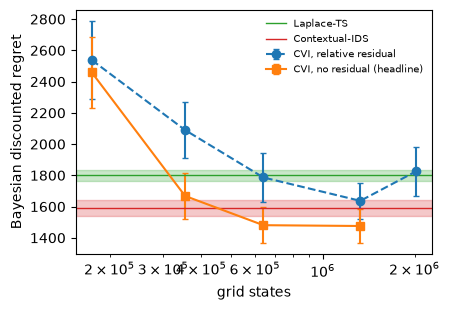

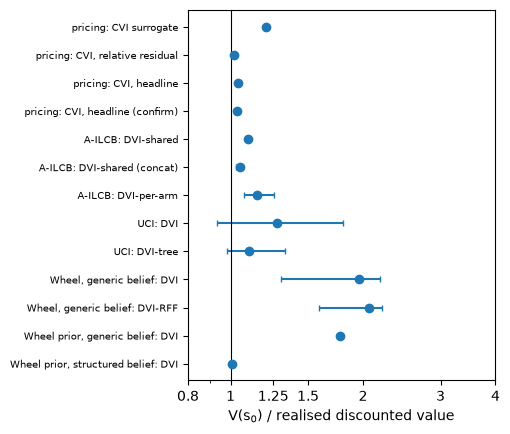

                              label             table                                 agent  ratio    lo    hi  configs
             pricing: CVI surrogate     pricingA_main               CVI (production design)  1.203 1.203 1.203        1
    pricing: CVI, relative residual     pricingA_main              CVI (information counts)  1.019 1.019 1.019        1
             pricing: CVI, headline pricingA_ablation                   CVI full − residual  1.040 1.040 1.040        1
   pricing: CVI, headline (confirm)  pricingA_confirm CVI (information counts, no residual)  1.034 1.034 1.034        1
                 A-ILCB: DVI-shared             ailcb                            DVI-shared  1.098 1.088 1.107        3
        A-ILCB: DVI-shared (concat)             ailcb                   DVI-shared (concat)  1.050 1.028 1.063        3
                A-ILCB: DVI-per-arm             ailcb                           DVI-per-arm  1.145 1.075 1.257        3
                           UCI: DVI     

In [56]:
# Figure A: resolution convergence; Figure B: self-prediction V(s0) vs realised discounted value
if SUMMARY is not None and "RESOLUTION" in globals():
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    for design, mk in [("relative residual", "o--"), ("no residual (headline)", "s-")]:
        d = RESOLUTION[RESOLUTION.design == design].sort_values("n_states")
        ax.errorbar(d.n_states, d.disc, yerr=1.96 * d.disc_se, fmt=mk, capsize=2, label=f"CVI, {design}")
    main = results_for("pricingA_main").set_index("agent")
    for ref, c in [("Laplace-TS", "C2"), ("Contextual-IDS", "C3")]:
        m, s = main.loc[ref, "disc_regret"], main.loc[ref, "disc_se"]
        ax.axhspan(m - s, m + s, color=c, alpha=0.25); ax.axhline(m, color=c, lw=1, label=ref)
    ax.set_xscale("log"); ax.set_xlabel("grid states"); ax.set_ylabel("Bayesian discounted regret")
    ax.legend(fontsize=7, frameon=False); fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(TABLES_DIR, f"figA_resolution.{ext}"), dpi=200)
    plt.show()

if SUMMARY is not None:
    # self-prediction ratio V(s0) / realised discounted value, averaged over the configurations of a benchmark
    SELF = [("pricingA_main", "CVI (production design)", "pricing: CVI surrogate"),
            ("pricingA_main", "CVI (information counts)", "pricing: CVI, relative residual"),
            ("pricingA_ablation", "CVI full − residual", "pricing: CVI, headline"),
            ("pricingA_confirm", "CVI (information counts, no residual)", "pricing: CVI, headline (confirm)"),
            ("ailcb", "DVI-shared", "A-ILCB: DVI-shared"), ("ailcb", "DVI-shared (concat)", "A-ILCB: DVI-shared (concat)"),
            ("ailcb", "DVI-per-arm", "A-ILCB: DVI-per-arm"),
            ("uci", "DVI", "UCI: DVI"), ("uci", "DVI-tree", "UCI: DVI-tree"),
            ("wheel", "DVI", "Wheel, generic belief: DVI"), ("wheel", "DVI-RFF", "Wheel, generic belief: DVI-RFF"),
            ("wheel_belief", "DVI (generic belief)", "Wheel prior, generic belief: DVI"),
            ("wheel_belief", "DVI (Wheel belief)", "Wheel prior, structured belief: DVI")]
    rows = []
    for tab, ag, label in SELF:
        d = SUMMARY[(SUMMARY.table == tab) & (SUMMARY.agent == ag) & np.isfinite(SUMMARY.v0_pred)]
        if len(d):
            r = d.v0_pred / d.disc_value
            rows.append(dict(label=label, table=tab, agent=ag, ratio=r.mean(), lo=r.min(), hi=r.max(), configs=len(d)))
    # bars: range over the configurations of a benchmark (e.g. the 12 Wheel configurations)
    SP = pd.DataFrame(rows)
    if len(SP):
        fig, ax = plt.subplots(figsize=(5.2, 0.28 * len(SP) + 0.8))
        y = np.arange(len(SP))[::-1]
        ax.errorbar(SP.ratio, y, xerr=[SP.ratio - SP.lo, SP.hi - SP.ratio], fmt="o", capsize=2)
        ax.axvline(1.0, color="k", lw=0.8)
        ax.set_yticks(y); ax.set_yticklabels(SP.label, fontsize=7); ax.set_xscale("log")
        ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set_xticks([0.8, 1, 1.25, 1.5, 2, 3, 4])
        ax.set_xlabel("V(s$_0$) / realised discounted value")
        fig.tight_layout()
        for ext in ("pdf", "png"):
            fig.savefig(os.path.join(TABLES_DIR, f"figB_self_prediction.{ext}"), dpi=200)
        plt.show()
        SP.to_csv(os.path.join(TABLES_DIR, "figB_self_prediction.csv"), index=False)
        print(SP.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("Tables and figures in", os.path.abspath(TABLES_DIR))